# Synapse team - exploration
---

All the differents tests/tunings we run during the project

In [1]:
# Useful starting lines
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

# Data

## Load the data

In [2]:
from scripts.helper import load_csv_data

x_all, x_online_test, y_all, train_ids, online_test_ids = load_csv_data("dataset")

In [3]:
x_all.shape, y_all.shape

((328135, 321), (328135,))

In [4]:
print(x_all[:1])

[[5.30000000e+01 1.10000000e+01 1.11620150e+07 1.10000000e+01
  1.60000000e+01 2.01500000e+03 1.10000000e+03 2.01501563e+09
  2.01501563e+09            nan            nan            nan
             nan            nan            nan            nan
             nan            nan 1.00000000e+00 1.00000000e+00
  2.00000000e+00 1.00000000e+00            nan 1.00000000e+00
  1.00000000e+00 2.00000000e+00 2.00000000e+00 1.00000000e+00
  5.00000000e+00 8.80000000e+01 1.00000000e+00 1.00000000e+00
  2.00000000e+00 1.00000000e+00 3.00000000e+00            nan
  1.00000000e+00 1.00000000e+00 2.00000000e+00 2.00000000e+00
  2.00000000e+00            nan 2.00000000e+00 2.00000000e+00
  2.00000000e+00 2.00000000e+00 1.00000000e+00 2.00000000e+00
  3.00000000e+00            nan 2.00000000e+00 1.00000000e+00
  5.00000000e+00 1.00000000e+00            nan            nan
             nan 2.00000000e+00 1.00000000e+00 8.80000000e+01
  8.00000000e+00 1.00000000e+00 1.10000000e+02 5.01000000e+02
        

## Preprocess the data

In [5]:
# Change NaN values to 0
x_all_norm = np.nan_to_num(x_all)
x_online_test_norm = np.nan_to_num(x_online_test)

In [6]:
print(x_all_norm[:1])

[[5.30000000e+01 1.10000000e+01 1.11620150e+07 1.10000000e+01
  1.60000000e+01 2.01500000e+03 1.10000000e+03 2.01501563e+09
  2.01501563e+09 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 1.00000000e+00 1.00000000e+00
  2.00000000e+00 1.00000000e+00 0.00000000e+00 1.00000000e+00
  1.00000000e+00 2.00000000e+00 2.00000000e+00 1.00000000e+00
  5.00000000e+00 8.80000000e+01 1.00000000e+00 1.00000000e+00
  2.00000000e+00 1.00000000e+00 3.00000000e+00 0.00000000e+00
  1.00000000e+00 1.00000000e+00 2.00000000e+00 2.00000000e+00
  2.00000000e+00 0.00000000e+00 2.00000000e+00 2.00000000e+00
  2.00000000e+00 2.00000000e+00 1.00000000e+00 2.00000000e+00
  3.00000000e+00 0.00000000e+00 2.00000000e+00 1.00000000e+00
  5.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 2.00000000e+00 1.00000000e+00 8.80000000e+01
  8.00000000e+00 1.00000000e+00 1.10000000e+02 5.01000000e+02
  0.0000

In [7]:
# Standardize the data (from 0 to 1)
from scripts.helper import standardize_zero_to_one

x_all_norm = standardize_zero_to_one(x_all_norm)
x_online_test_norm = standardize_zero_to_one(x_online_test_norm)

In [8]:
print(x_all_norm[:1])

[[0.73239437 0.90909091 0.89823008 0.90909091 0.5        0.
  0.         0.67263493 0.67263493 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  1.         1.         1.         0.5        0.         0.5
  0.11111111 0.02020202 0.22222222 0.01010101 0.04081633 0.88888889
  0.         0.         0.22222222 0.11111111 0.33333333 0.
  0.         0.11111111 0.22222222 0.125      0.125      0.
  0.22222222 0.125      0.125      0.22222222 0.         0.125
  0.33333333 0.         1.         0.         0.5        0.
  0.         0.         0.         0.22222222 0.         0.88888889
  0.08080808 0.11111111 0.0110011  0.05010501 0.         0.11111111
  0.22222222 0.22222222 0.22222222 0.22222222 0.22222222 0.22222222
  0.11111111 0.11111111 0.11111111 0.         0.33333333 0.88888889
  0.         0.         0.         0.55555556 0.20520521 0.3043043
  0.3033033  0.30830831 0.20520521 0.11111111 0.64646465 0.1021021
  0.03003003 0.98989899 0.22022022 0.03003

## Explore the data

Number of training examples:  328135
Number of negative labels: 299160 (91.1697929205967%)
Number of positive labels: 28975 (8.830207079403294%)
Number of features:  321


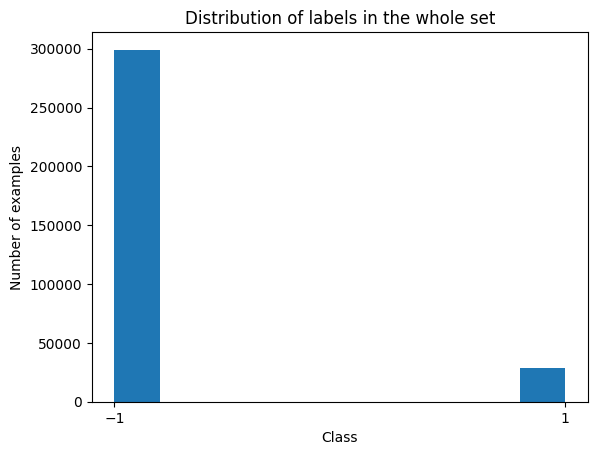

In [9]:
from scripts.data_utils import explore_data
explore_data(x_all, y_all, "whole set")

In [10]:
data_train = np.column_stack((x_all_norm, y_all))
# Compute correlation matrix
corr_matrix = np.corrcoef(data_train, rowvar=False)
correlations_with_labels = corr_matrix[-1, :-1]
# Get absolute correlations and sort them
abs_correlations = np.abs(correlations_with_labels)
sorted_indices = np.argsort(abs_correlations)[::-1]
# Print the top xx features with the highest absolute correlation with the labels
top = 50
print(f"Top {top} features with highest absolute correlation with labels:\n")
for i in range(top):
    feature_index = sorted_indices[i]
    correlation_value = correlations_with_labels[feature_index]
    print(f"Feature {feature_index}: Correlation = {correlation_value:.4f}")

Top 50 features with highest absolute correlation with labels:

Feature 26: Correlation = 0.2443
Feature 248: Correlation = 0.2245
Feature 246: Correlation = 0.2190
Feature 58: Correlation = 0.2072
Feature 249: Correlation = 0.2069
Feature 34: Correlation = -0.2045
Feature 231: Correlation = 0.1964
Feature 247: Correlation = 0.1852
Feature 49: Correlation = 0.1776
Feature 230: Correlation = 0.1716
Feature 232: Correlation = 0.1713
Feature 35: Correlation = 0.1646
Feature 238: Correlation = -0.1638
Feature 48: Correlation = -0.1613
Feature 234: Correlation = 0.1383
Feature 155: Correlation = 0.1353
Feature 96: Correlation = 0.1234
Feature 45: Correlation = -0.1220
Feature 97: Correlation = 0.1154
Feature 59: Correlation = 0.1141
Feature 69: Correlation = -0.1126
Feature 117: Correlation = 0.1113
Feature 73: Correlation = 0.1107
Feature 95: Correlation = 0.1093
Feature 116: Correlation = 0.1090
Feature 66: Correlation = -0.1080
Feature 109: Correlation = 0.1068
Feature 61: Correlation = 

Number of training examples:  262508
Number of negative labels: 239433 (91.20979170158624%)
Number of positive labels: 23075 (8.790208298413763%)
Number of features:  321


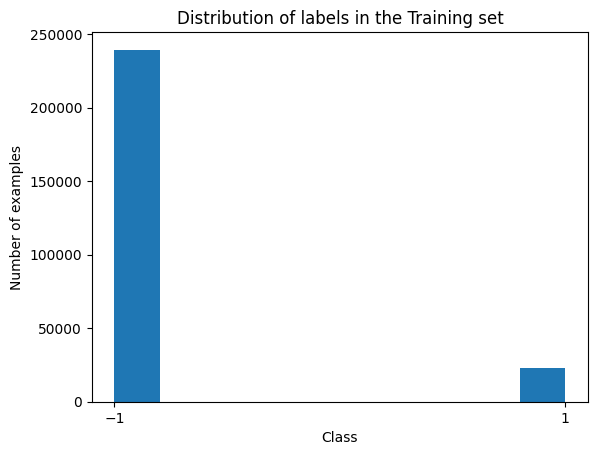

Number of training examples:  65627
Number of negative labels: 59727 (91.00979779663858%)
Number of positive labels: 5900 (8.990202203361422%)
Number of features:  321


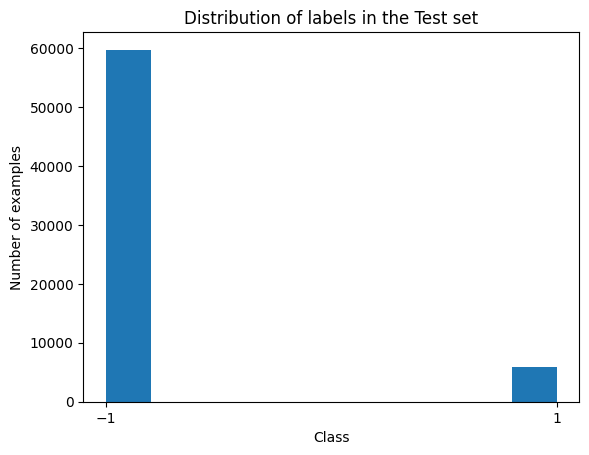

In [11]:
from scripts.helper import random_split_data

x_train_norm, y_train, x_test_nom, y_test = random_split_data(
    x_all_norm, y_all, 0.8, seed=42
)

explore_data(x_train_norm, y_train, "Training set")
explore_data(x_test_nom, y_test, "Test set")

# Model

## Tunning


### Mean Squared Error With Gradient Descent tuning

Tuning with args (1/10): {'max_iters': 100, 'gamma': 0.5}
Average validation cross-validation loss: 1161075947408621.5


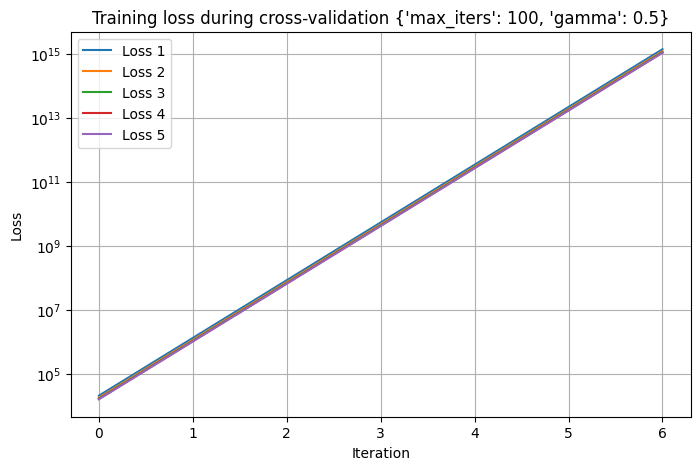

Tuning with args (2/10): {'max_iters': 100, 'gamma': 0.1}
Average validation cross-validation loss: 0.43078537824892366


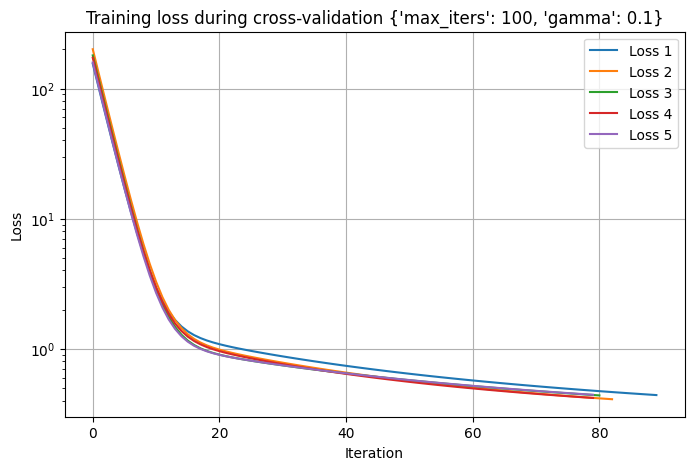

Tuning with args (3/10): {'max_iters': 100, 'gamma': 0.075}
Average validation cross-validation loss: 0.46260132628682343


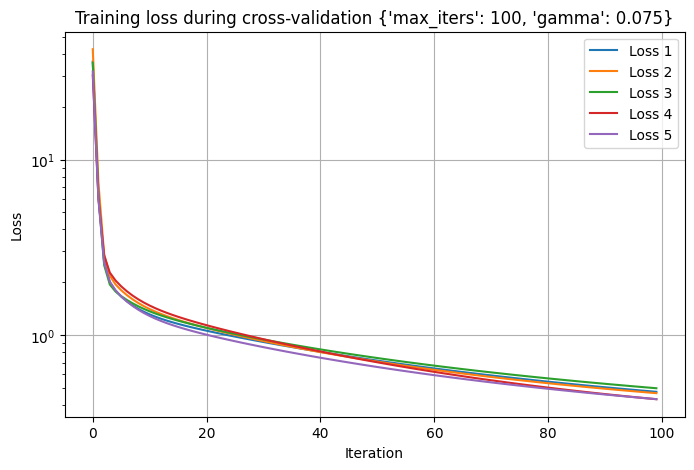

Tuning with args (4/10): {'max_iters': 100, 'gamma': 0.05}
Average validation cross-validation loss: 0.5956747660611775


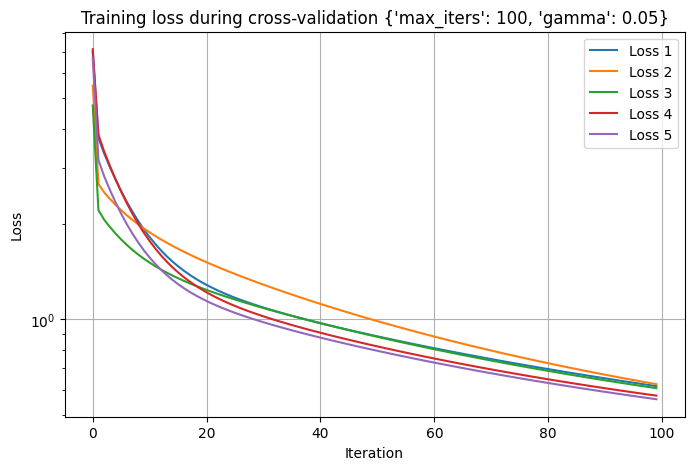

Tuning with args (5/10): {'max_iters': 100, 'gamma': 0.025}
Average validation cross-validation loss: 0.8418124368421129


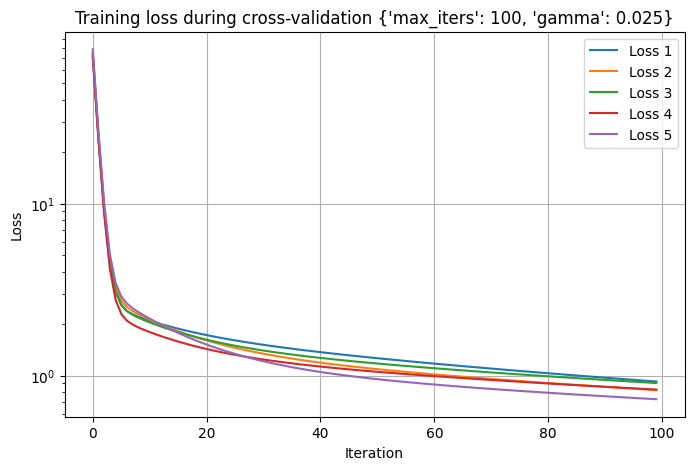

Tuning with args (6/10): {'max_iters': 100, 'gamma': 0.02}
Average validation cross-validation loss: 0.86248353888429


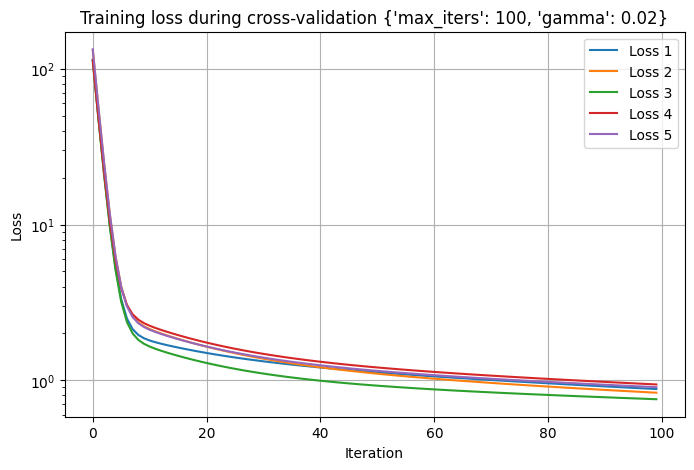

Tuning with args (7/10): {'max_iters': 100, 'gamma': 0.015}
Average validation cross-validation loss: 1.0214147897570935


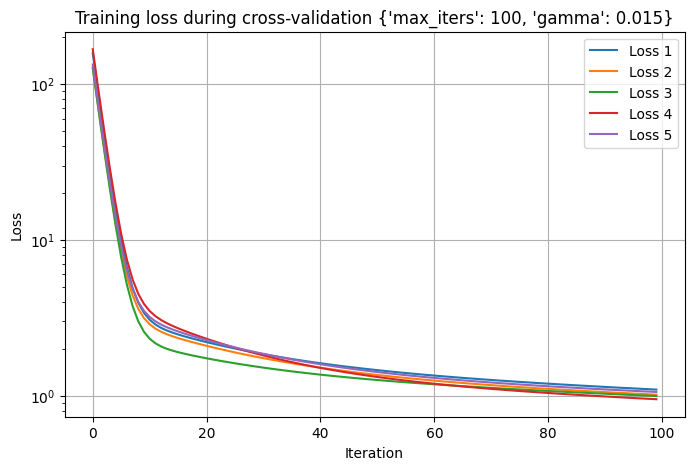

Tuning with args (8/10): {'max_iters': 100, 'gamma': 0.01}
Average validation cross-validation loss: 1.1493286674063083


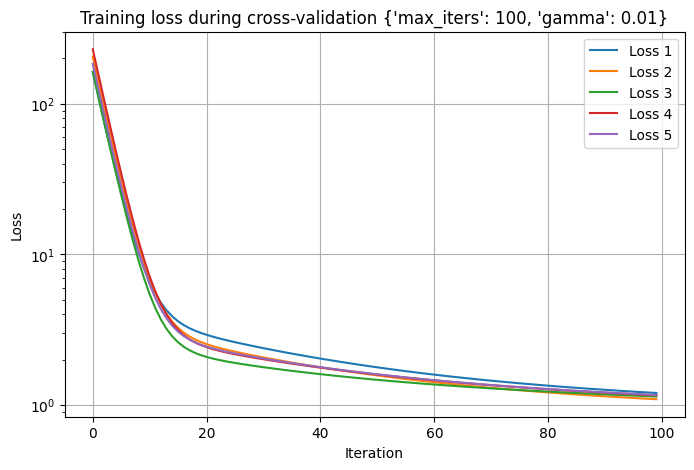

Tuning with args (9/10): {'max_iters': 100, 'gamma': 0.0075}
Average validation cross-validation loss: 1.3235212892092236


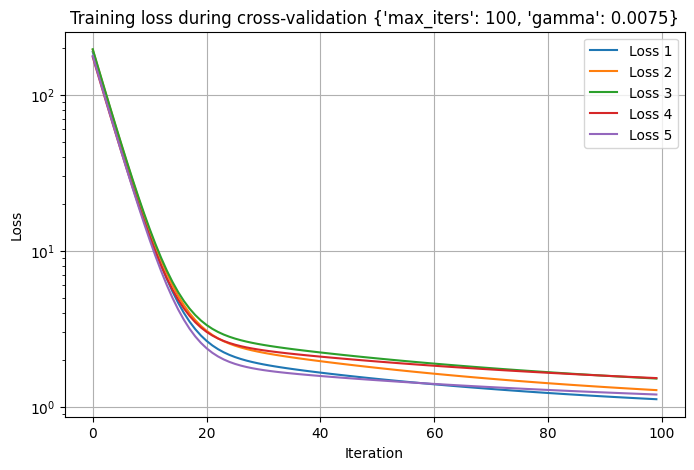

Tuning with args (10/10): {'max_iters': 100, 'gamma': 0.005}
Average validation cross-validation loss: 1.598822857738665


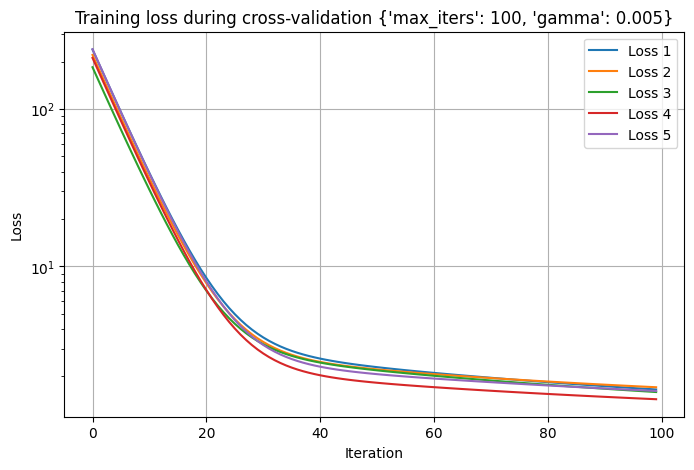

In [12]:
from scripts.models import MSEGradientDescent
from scripts.model_utils import tune, show_printing_result_two_losses

args = [
    {"max_iters": 100, "gamma": 0.5},
    {"max_iters": 100, "gamma": 0.1},
    {"max_iters": 100, "gamma": 0.075},
    {"max_iters": 100, "gamma": 0.05},
    {"max_iters": 100, "gamma": 0.025},
    {"max_iters": 100, "gamma": 0.02},
    {"max_iters": 100, "gamma": 0.015},
    {"max_iters": 100, "gamma": 0.01},
    {"max_iters": 100, "gamma": 0.0075},
    {"max_iters": 100, "gamma": 0.005},
]
validation, training = tune(
    x_train_norm, y_train, k=5, model=MSEGradientDescent, args=args
)

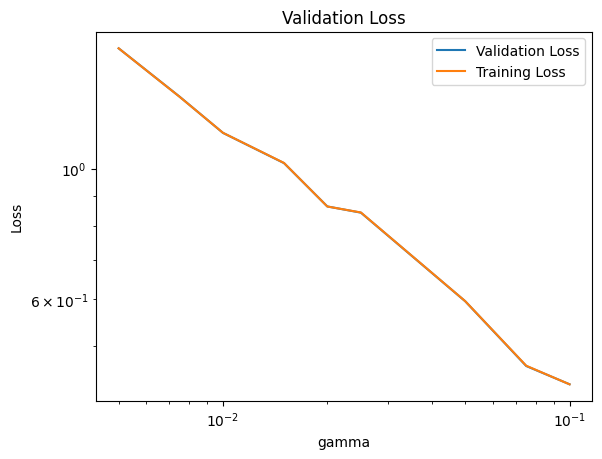

In [13]:
from scripts.model_utils import plot_tuning_results

plot_tuning_results(args[1:], "gamma", validation[1:], training[1:], "Validation Loss")

Tuning with args (1/4): {'max_iters': 100, 'gamma': 0.2}
Average validation cross-validation loss: 153420538.11859235


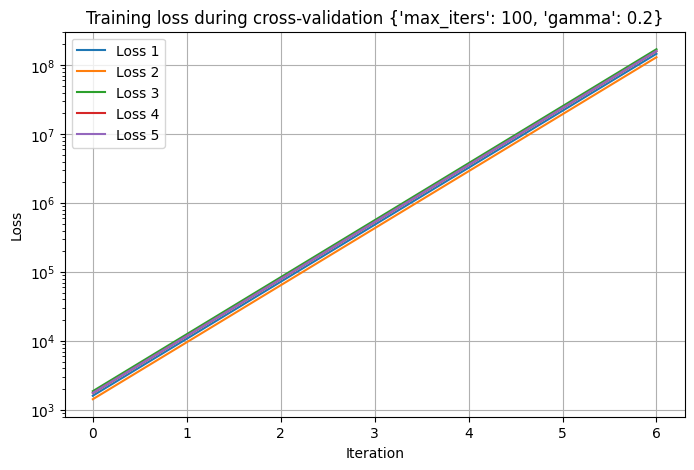

Tuning with args (2/4): {'max_iters': 100, 'gamma': 0.15}
Average validation cross-validation loss: 454963.9191361211


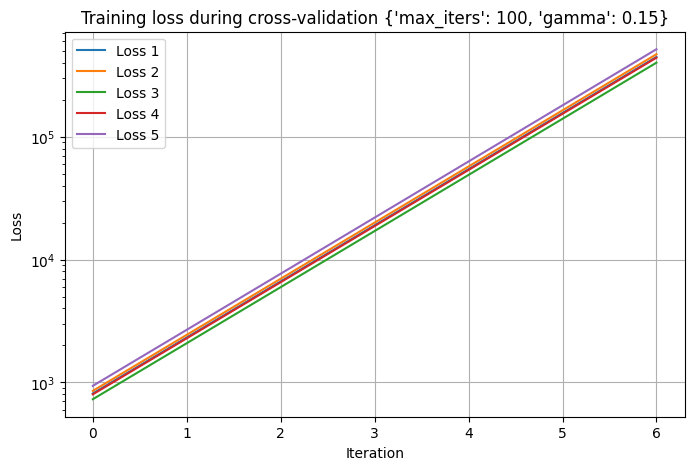

Tuning with args (3/4): {'max_iters': 300, 'gamma': 0.11}
Average validation cross-validation loss: 0.32850089308856256


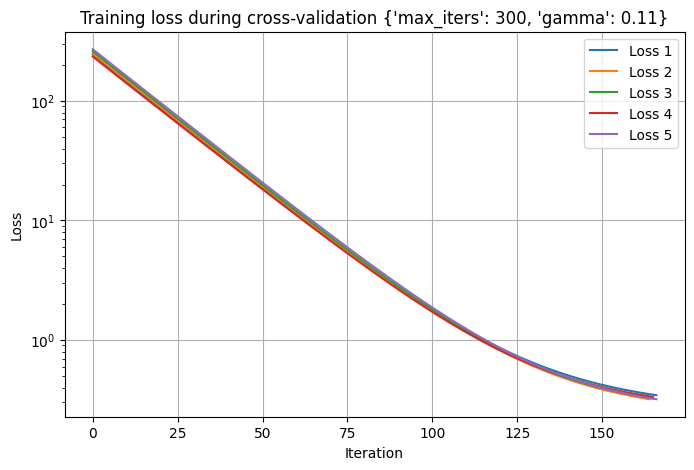

Tuning with args (4/4): {'max_iters': 100, 'gamma': 0.101}
Average validation cross-validation loss: 0.42256532424641013


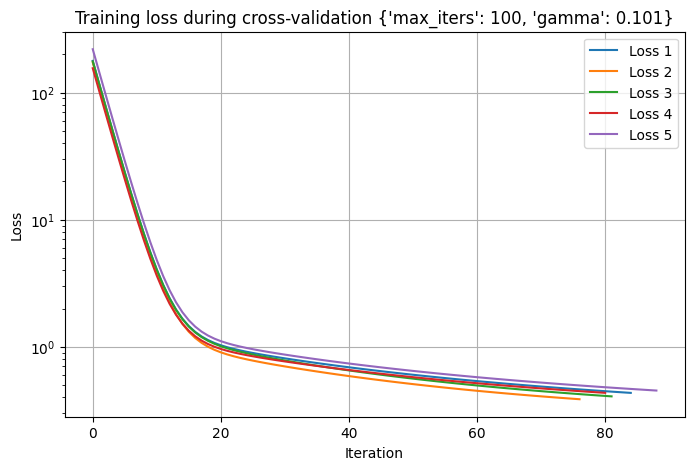

In [14]:
args_2 = [
    {"max_iters": 100, "gamma": 0.2},
    {"max_iters": 100, "gamma": 0.15},
    {"max_iters": 300, "gamma": 0.11},
    {"max_iters": 100, "gamma": 0.101},
]
validation_2, training_2 = tune(
    x_train_norm, y_train, k=5, model=MSEGradientDescent, args=args_2
)

Tuning with args (1/2): {'max_iters': 300, 'gamma': 0.115}
Average validation cross-validation loss: 650.5673564803699


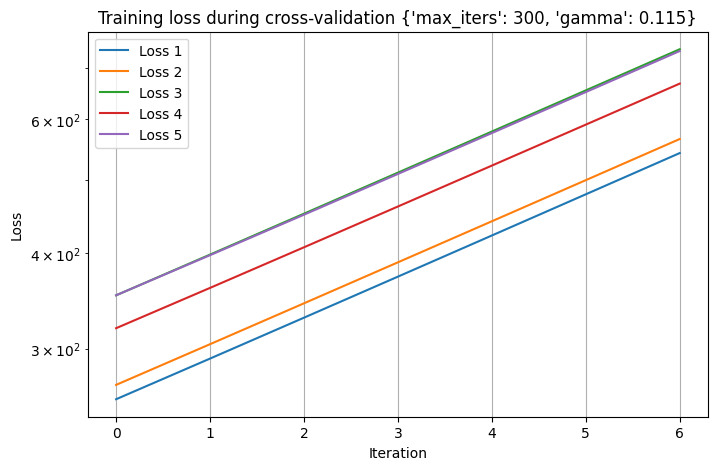

Tuning with args (2/2): {'max_iters': 300, 'gamma': 0.105}
Average validation cross-validation loss: 0.4272476006077886


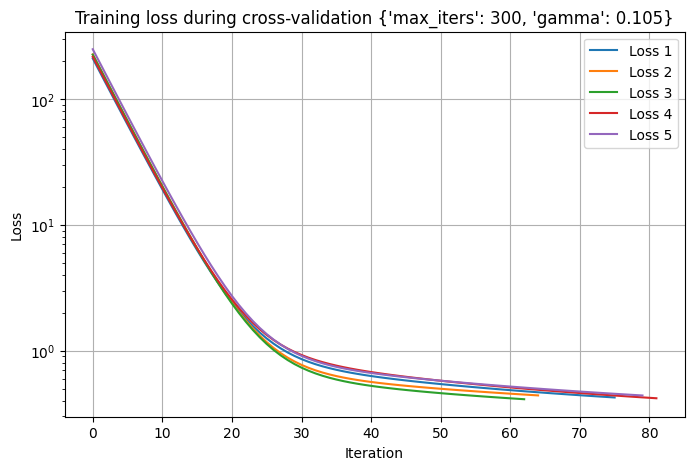

In [15]:
args_3 = [
    {"max_iters": 300, "gamma": 0.115},
    {"max_iters": 300, "gamma": 0.105},
]
validation_3, training_3 = tune(
    x_train_norm, y_train, k=5, model=MSEGradientDescent, args=args_3
)

Gamma values tried:  [0.005, 0.0075, 0.01, 0.015, 0.02, 0.025, 0.05, 0.075, 0.1, 0.101, 0.105, 0.11, 0.115, 0.15, 0.2, 0.5]


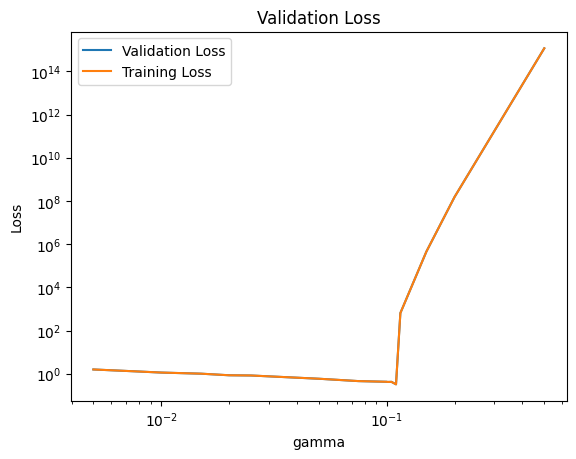

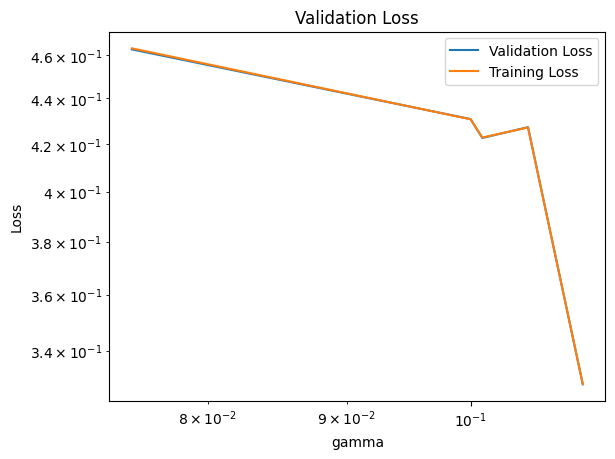

In [16]:
# Combine results
all_args = args + args_2 + args_3
all_validation = validation + validation_2 + validation_3
all_training = training + training_2 + training_3
# Sort by gamma
sorted_indices = np.argsort([a["gamma"] for a in all_args])
all_args = [all_args[i] for i in sorted_indices]
all_validation = [all_validation[i] for i in sorted_indices]
all_training = [all_training[i] for i in sorted_indices]
# Plot
print("Gamma values tried: ", [a["gamma"] for a in all_args])
small_marge = 0
big_marge = 0
plot_tuning_results(
    all_args[small_marge : len(all_args) - big_marge],
    "gamma",
    all_validation[small_marge : len(all_args) - big_marge],
    all_training[small_marge : len(all_args) - big_marge],
    "Validation Loss",
)
small_marge = 7
big_marge = 4
plot_tuning_results(
    all_args[small_marge : len(all_args) - big_marge],
    "gamma",
    all_validation[small_marge : len(all_args) - big_marge],
    all_training[small_marge : len(all_args) - big_marge],
    "Validation Loss",
)

### Logistic with gradient descent

#### Tuning for loss with whole dataset

Tuning with args (1/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5}
Average validation cross-validation loss: 0.4074710974407199


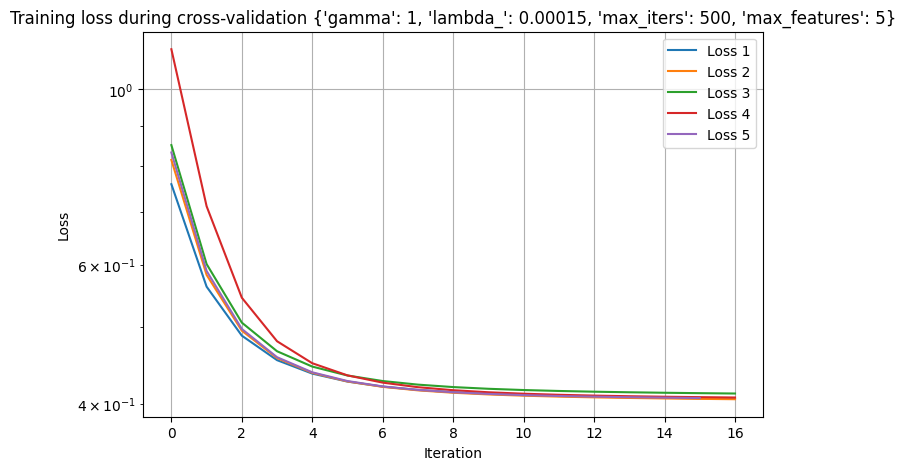

Tuning with args (2/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10}
Average validation cross-validation loss: 0.35767368294076685


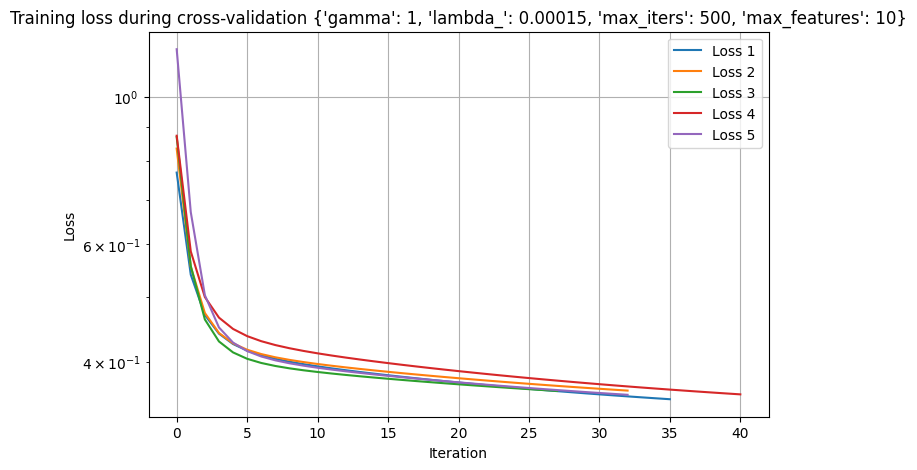

Tuning with args (3/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15}
Average validation cross-validation loss: 0.2904855774921928


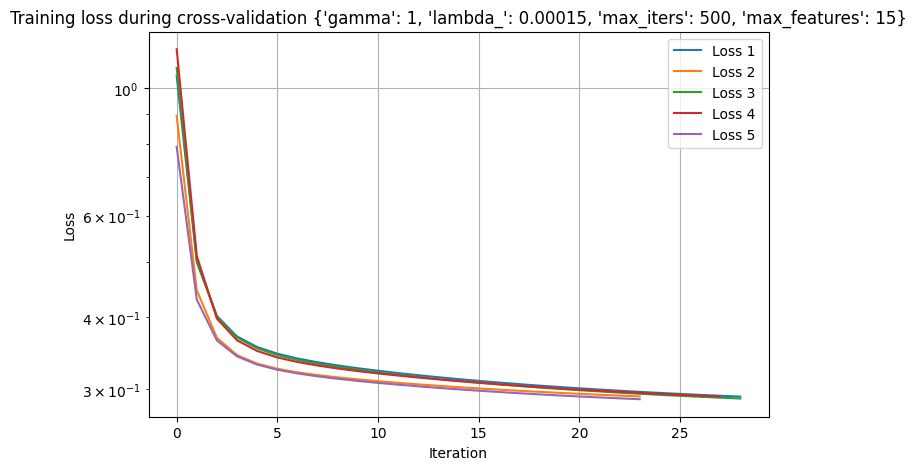

Tuning with args (4/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20}
Average validation cross-validation loss: 0.29125799950161363


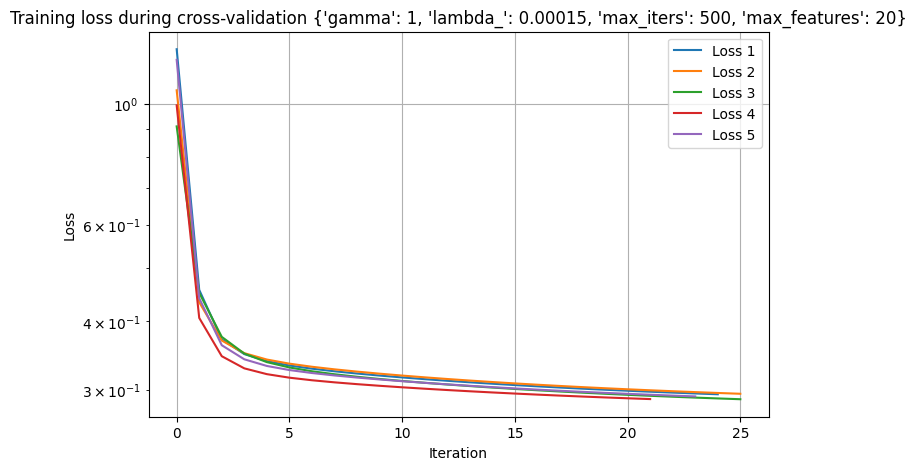

Tuning with args (5/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30}
Average validation cross-validation loss: 0.28898397667183284


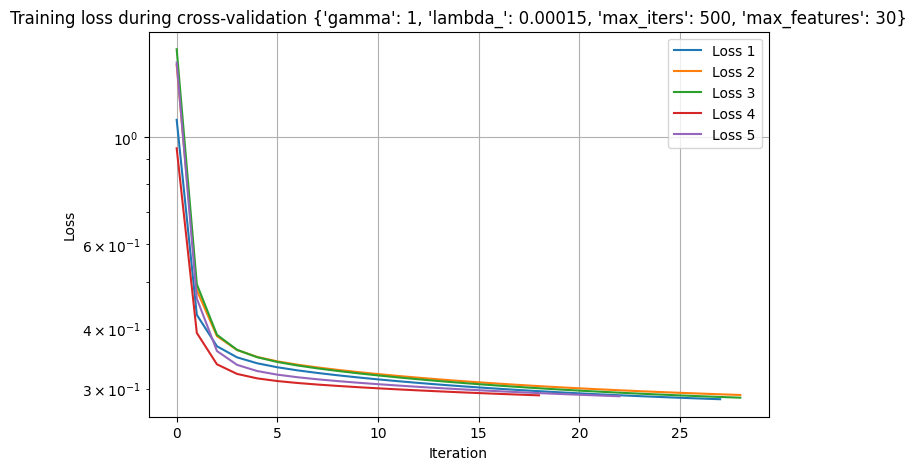

Tuning with args (6/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40}
Average validation cross-validation loss: 0.28734523781329635


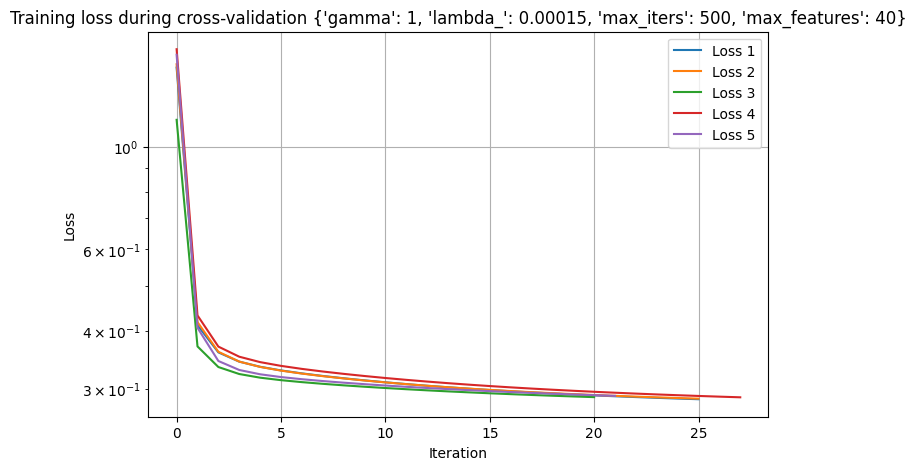

Tuning with args (7/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50}
Average validation cross-validation loss: 0.2808689787239797


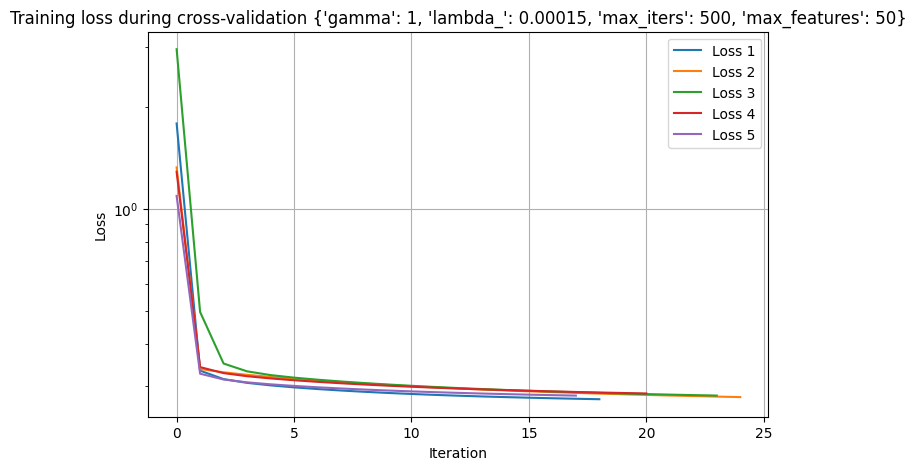

Tuning with args (8/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60}
Average validation cross-validation loss: 0.2779589540071336


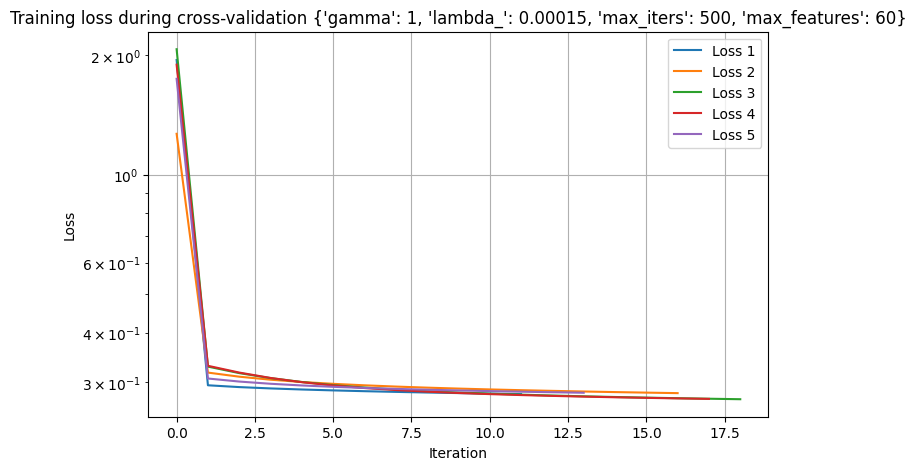

Tuning with args (9/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70}
Average validation cross-validation loss: 0.2761873598548378


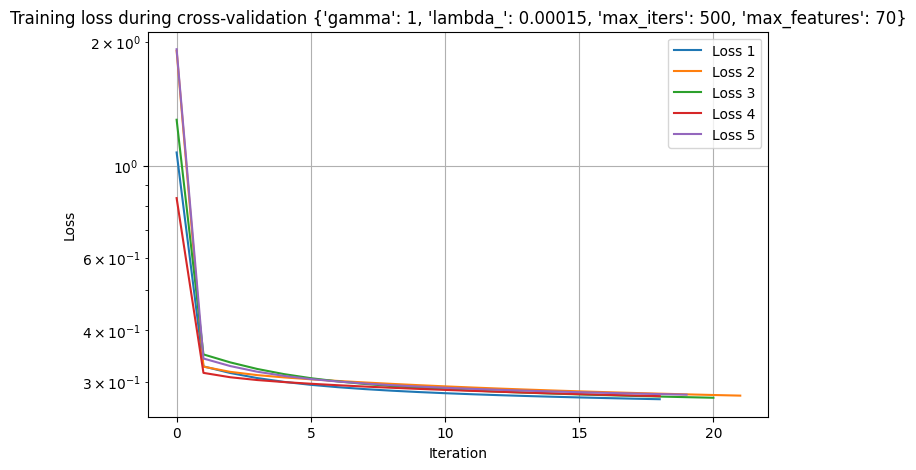

Tuning with args (10/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80}
Average validation cross-validation loss: 0.2771698137409549


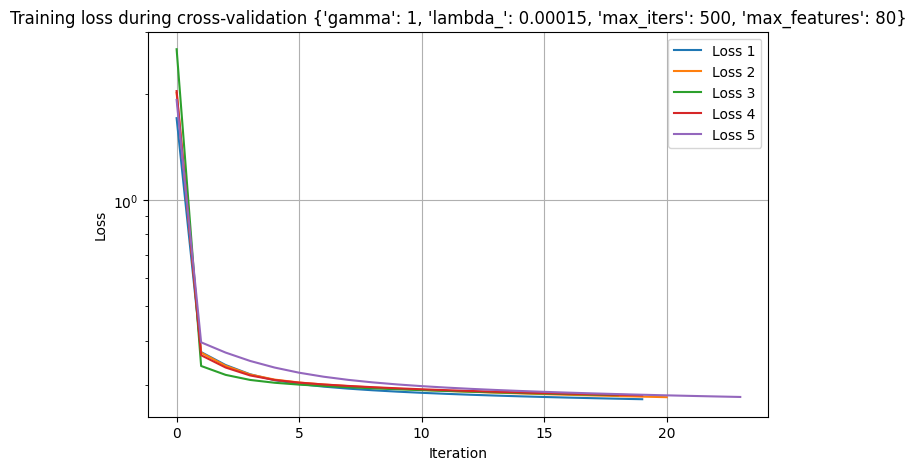

Tuning with args (11/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90}
Average validation cross-validation loss: 0.2787598565152929


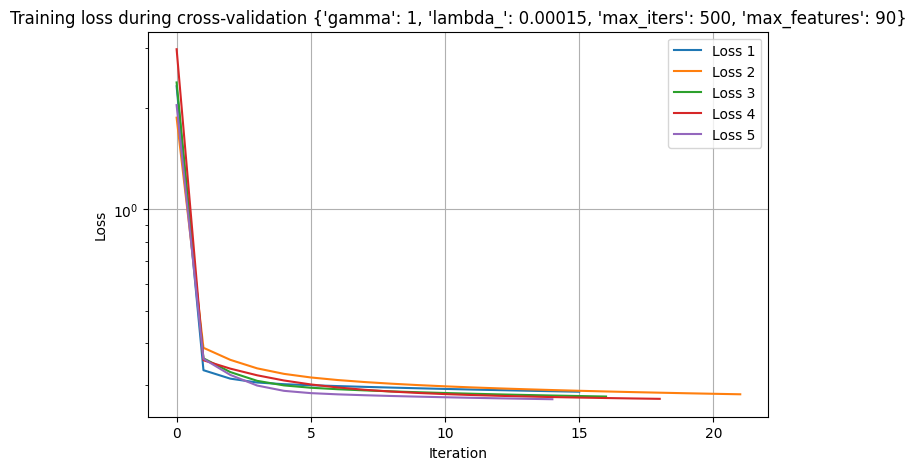

Tuning with args (12/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100}
Average validation cross-validation loss: 0.27948594316979214


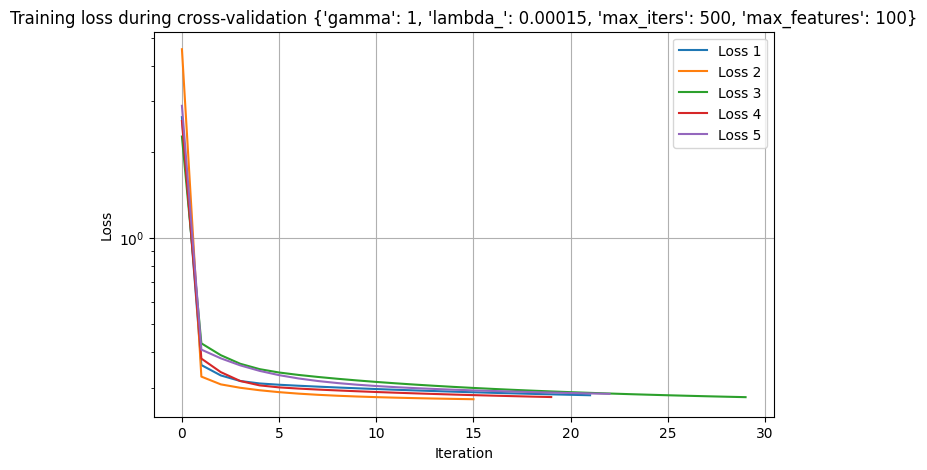

Tuning with args (13/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5}
Average validation cross-validation loss: 0.4113697654073585


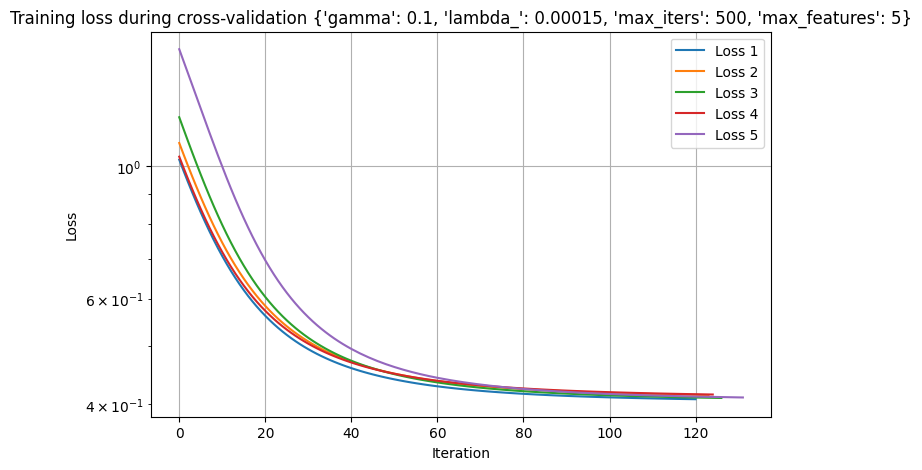

Tuning with args (14/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10}
Average validation cross-validation loss: 0.3620898296157978


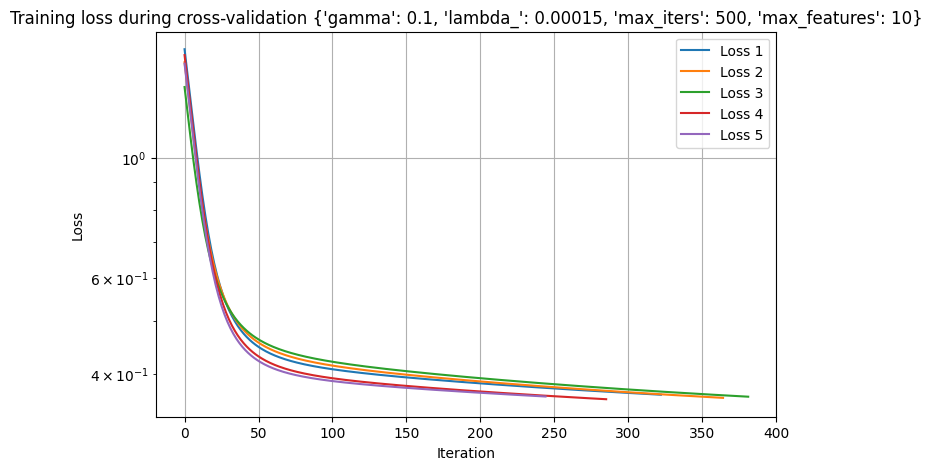

Tuning with args (15/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15}
Average validation cross-validation loss: 0.2931593203215397


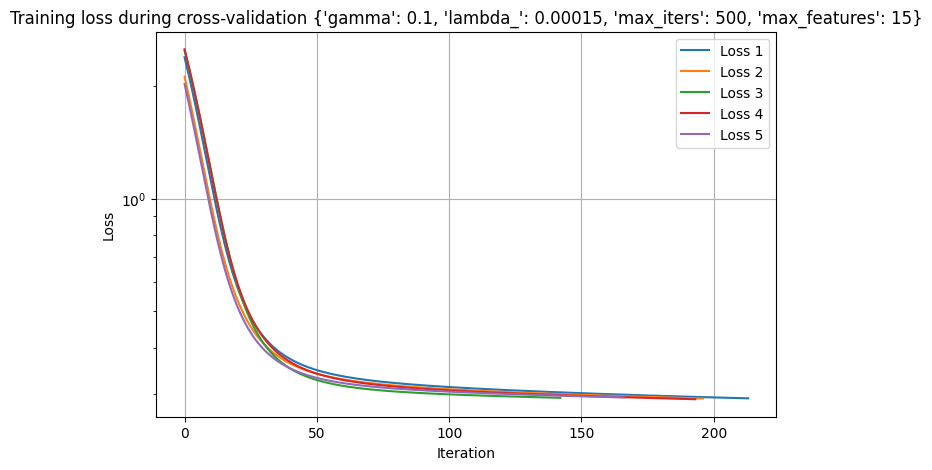

Tuning with args (16/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20}
Average validation cross-validation loss: 0.29552739853905213


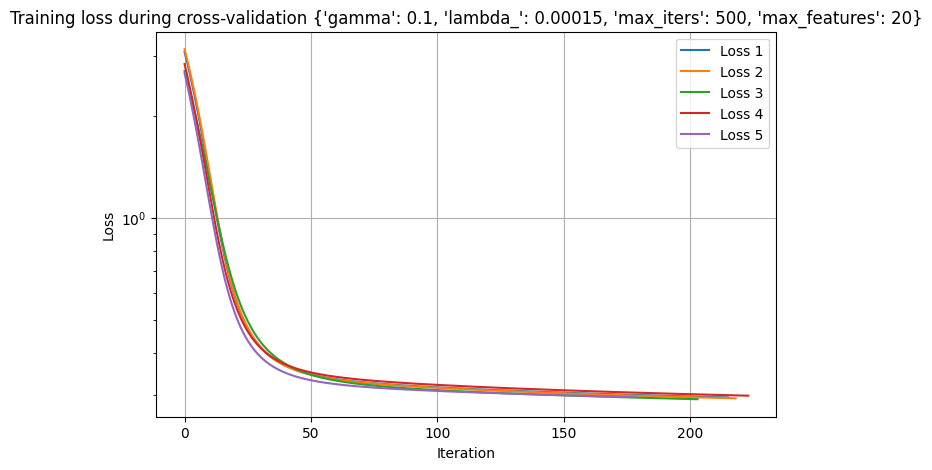

Tuning with args (17/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30}
Average validation cross-validation loss: 0.2939177726006136


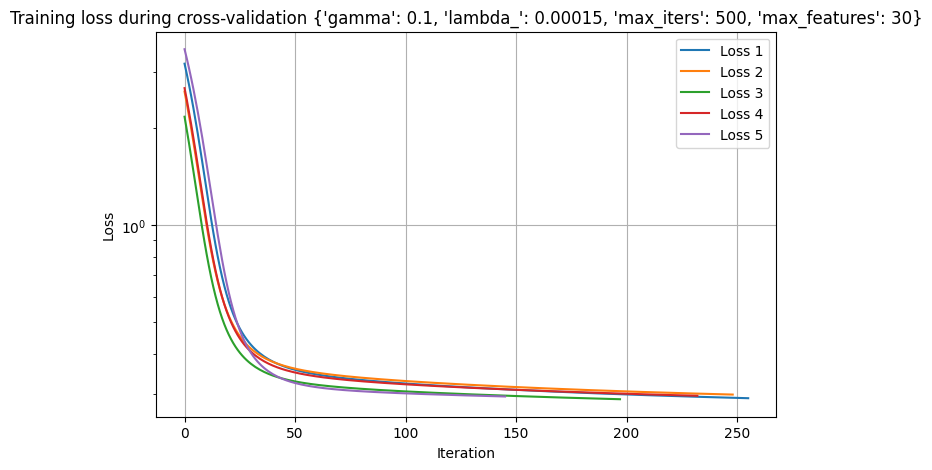

Tuning with args (18/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40}
Average validation cross-validation loss: 0.2915029434275652


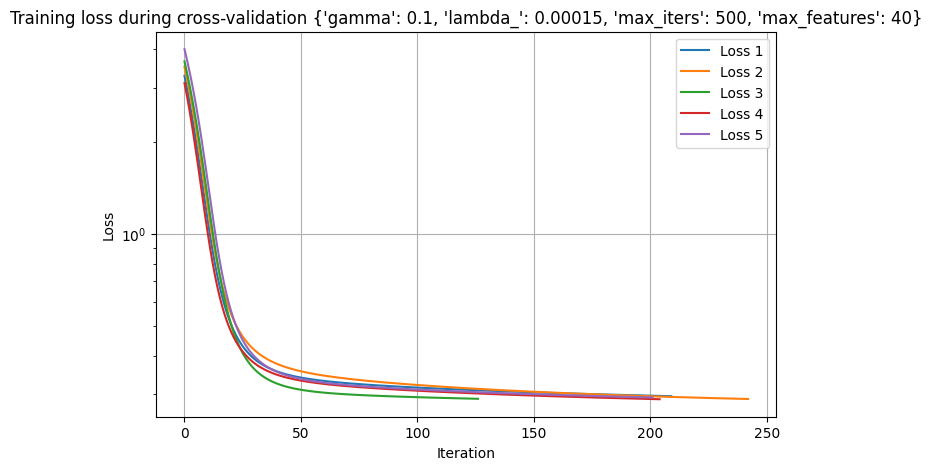

Tuning with args (19/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50}
Average validation cross-validation loss: 0.28325324016856324


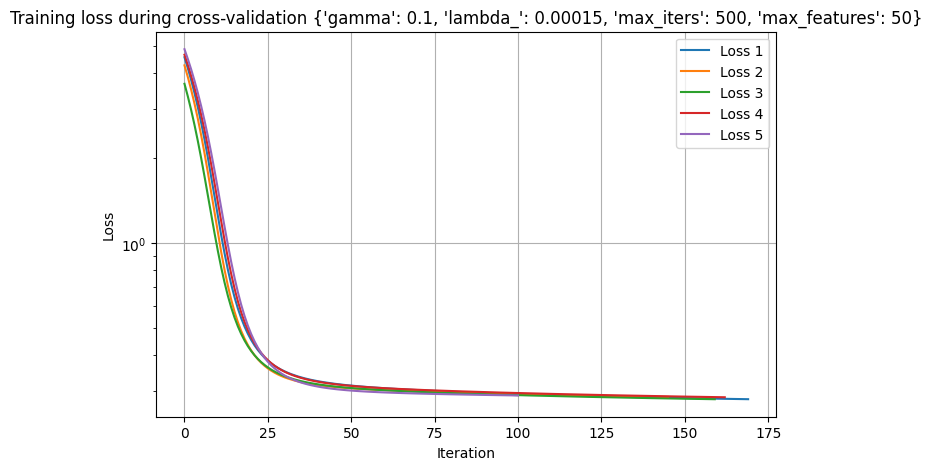

Tuning with args (20/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60}
Average validation cross-validation loss: 0.28390709043782947


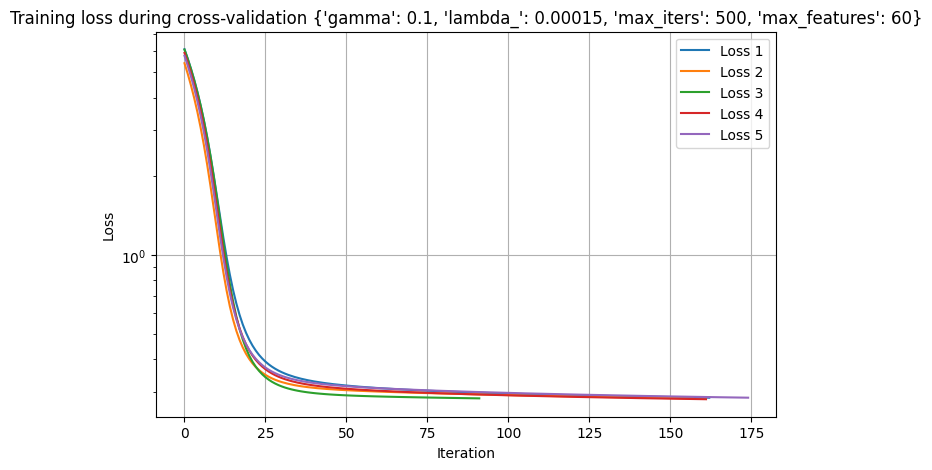

Tuning with args (21/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70}
Average validation cross-validation loss: 0.2769971547432196


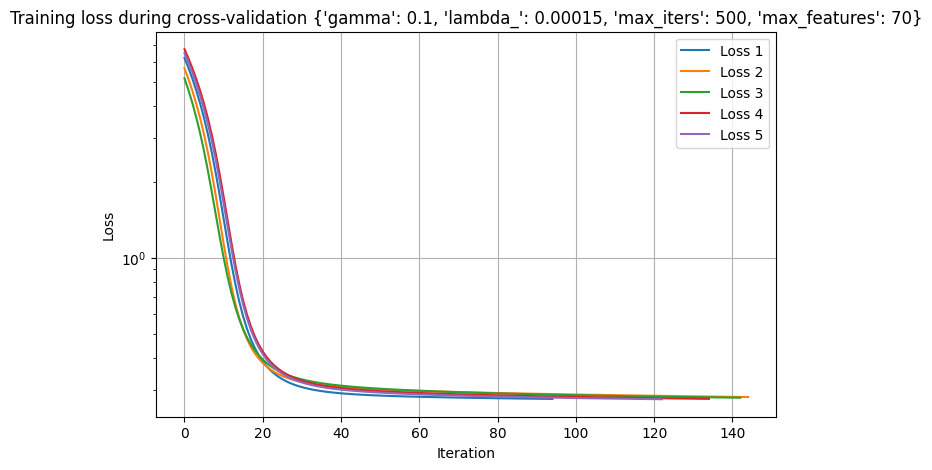

Tuning with args (22/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80}
Average validation cross-validation loss: 0.28307712933492535


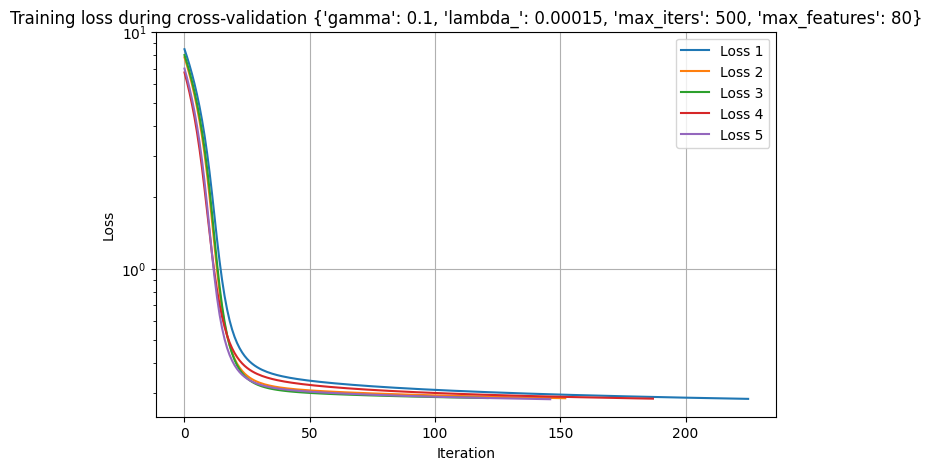

Tuning with args (23/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90}
Average validation cross-validation loss: 0.28384827253708156


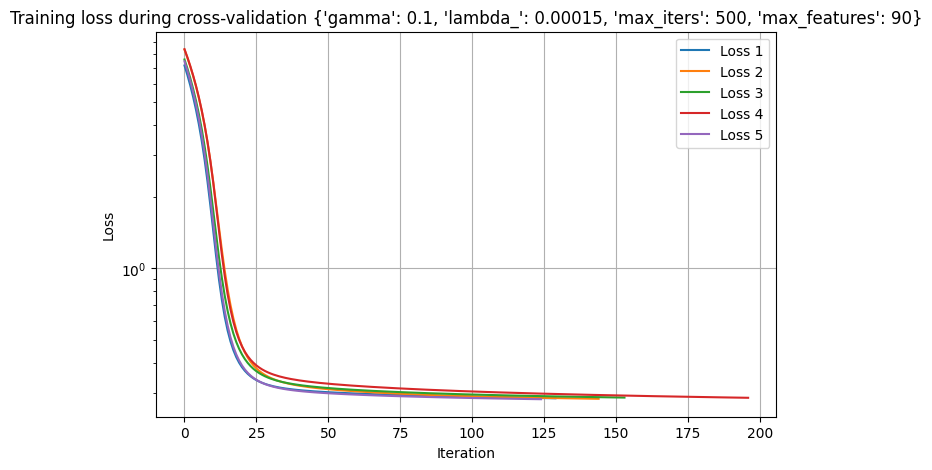

Tuning with args (24/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100}
Average validation cross-validation loss: 0.283452011362863


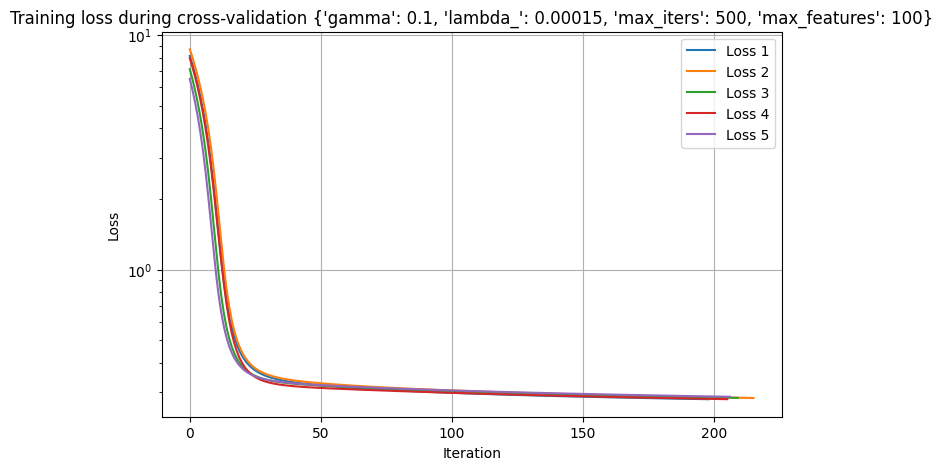

Tuning with args (25/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5}
Average validation cross-validation loss: 0.4058969297370016


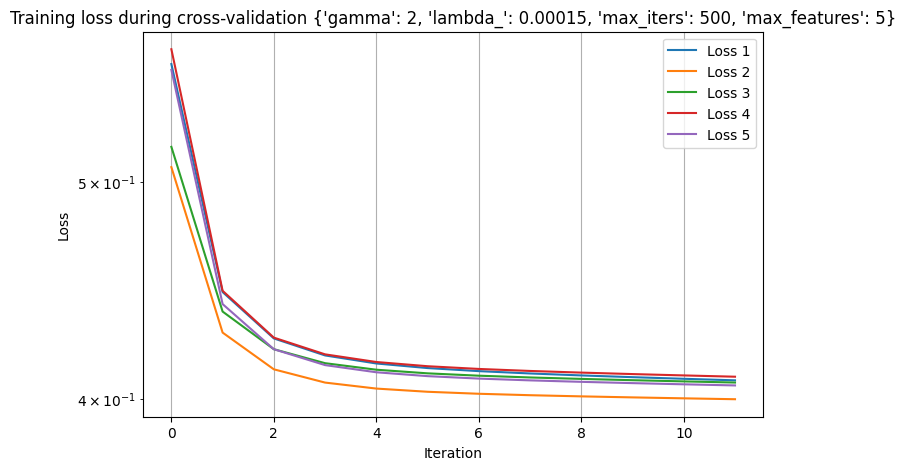

Tuning with args (26/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10}
Average validation cross-validation loss: 0.350621520212023


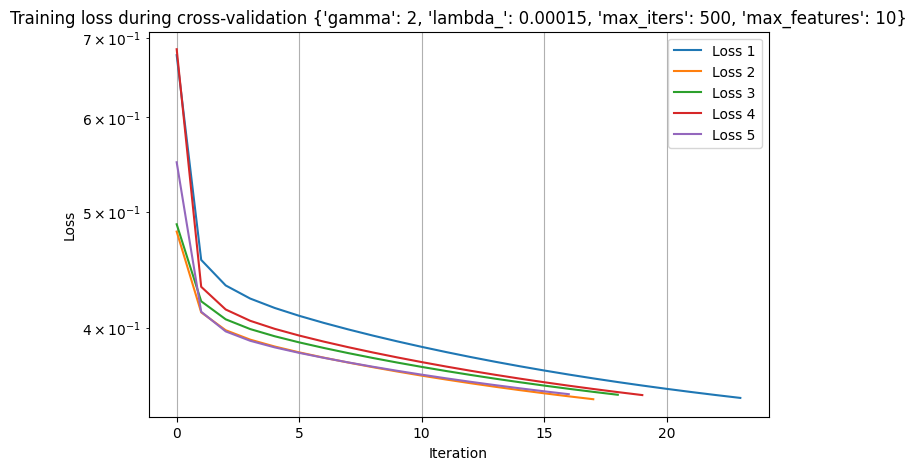

Tuning with args (27/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15}
Average validation cross-validation loss: 0.2849518787057587


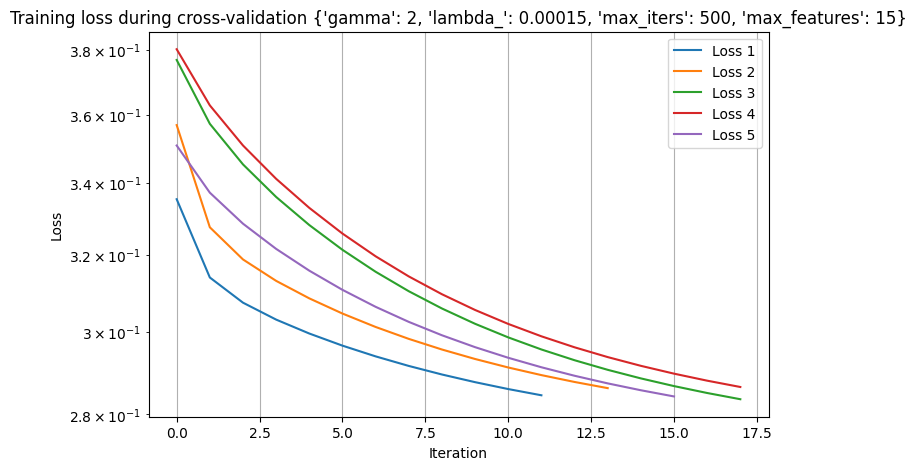

Tuning with args (28/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20}
Average validation cross-validation loss: 0.28629549253370745


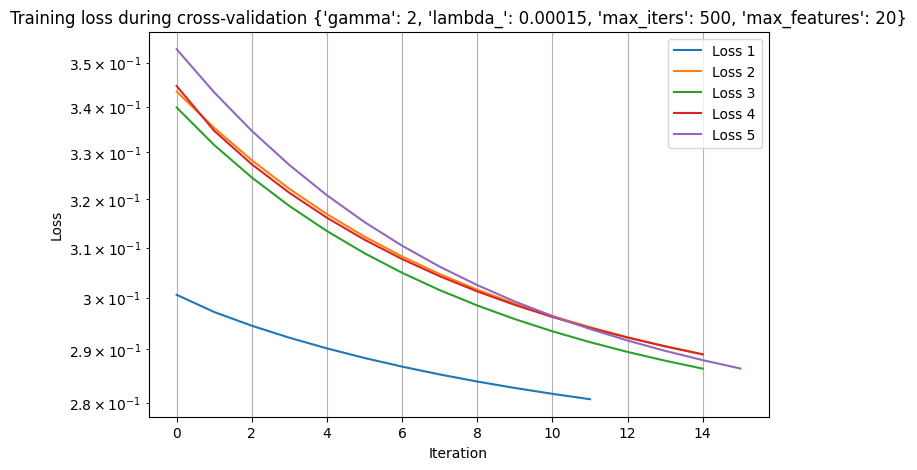

Tuning with args (29/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30}
Average validation cross-validation loss: 0.2858785242906752


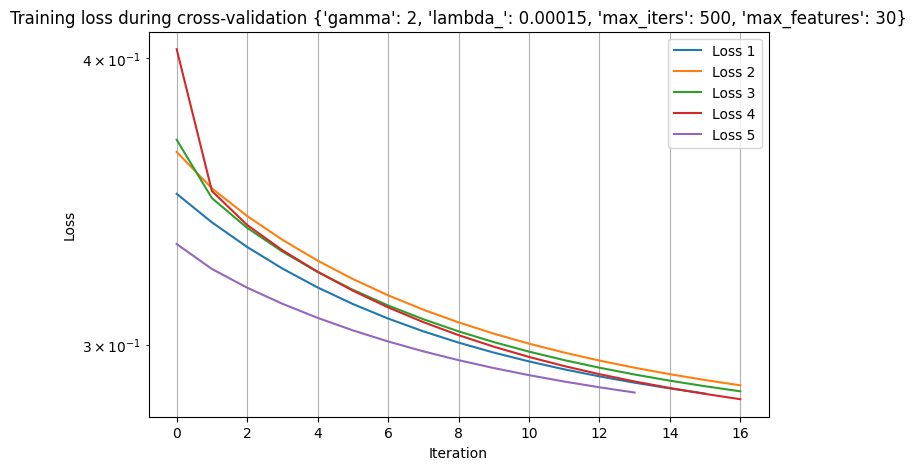

Tuning with args (30/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40}
Average validation cross-validation loss: 0.27860234654304766


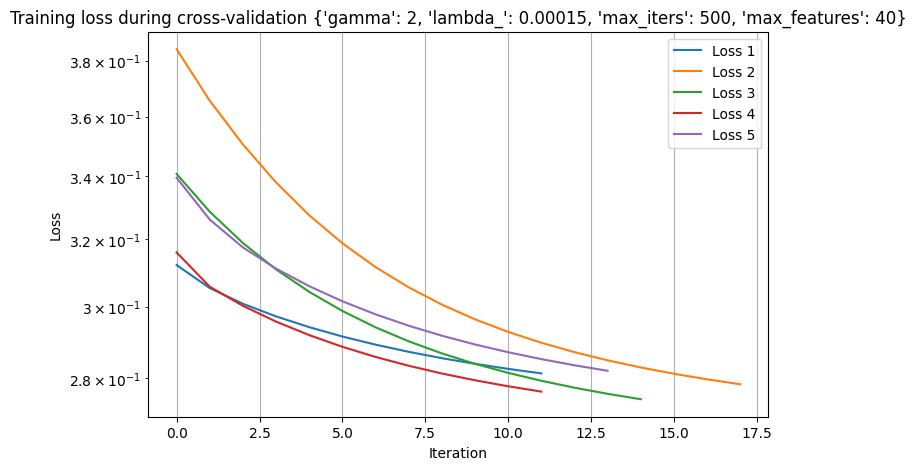

Tuning with args (31/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50}
Average validation cross-validation loss: 0.27742961428498536


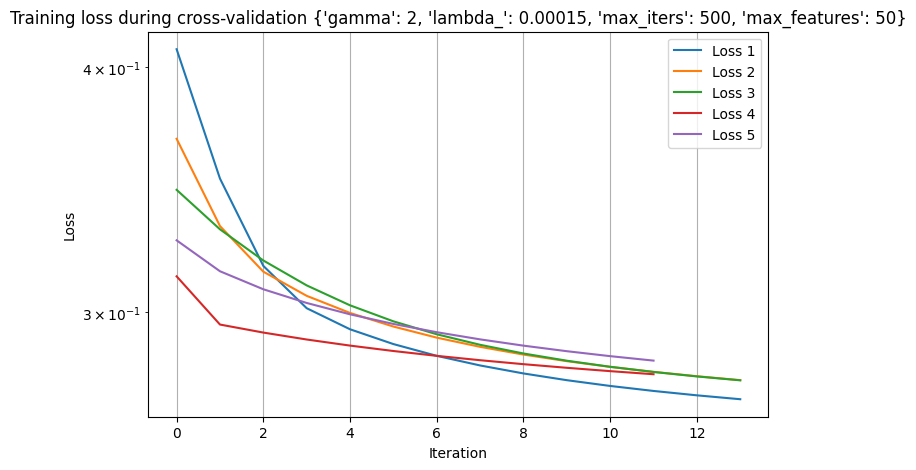

Tuning with args (32/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60}
Average validation cross-validation loss: 0.2764384352735119


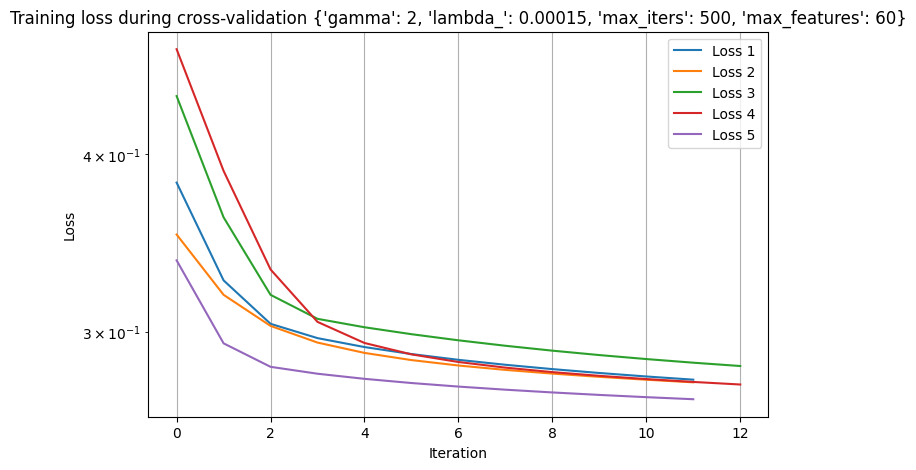

Tuning with args (33/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70}
Average validation cross-validation loss: 0.26607445596339413


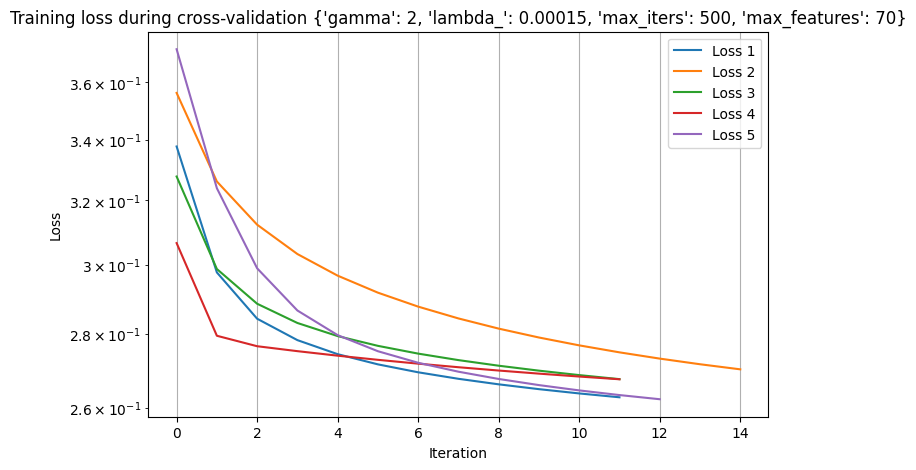

Tuning with args (34/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80}
Average validation cross-validation loss: 0.27578346868378045


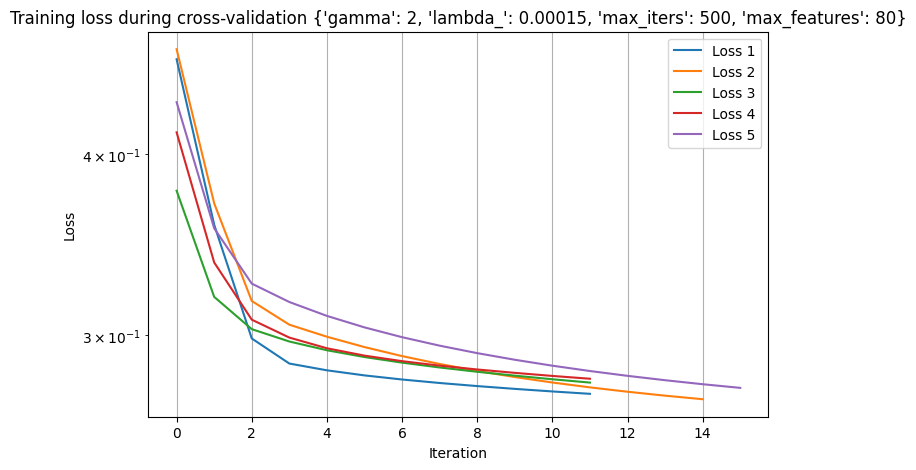

Tuning with args (35/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90}
Average validation cross-validation loss: 0.275489563752108


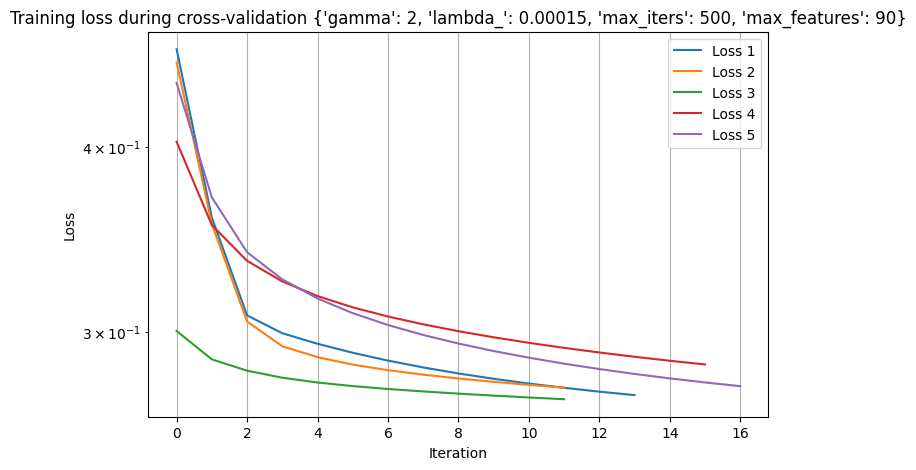

Tuning with args (36/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100}
Average validation cross-validation loss: 0.27514396253461837


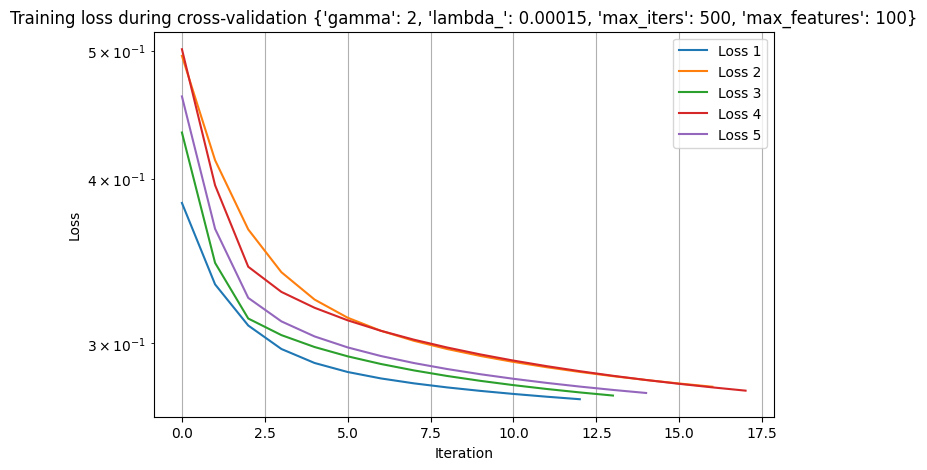

In [19]:
from scripts.models import RegularizedLogisticRegression

args_logreg_1 = [
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 5},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 10},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 15},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 20},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 30},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 40},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 50},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 60},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 70},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 80},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 90},
    {"gamma": 1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 100},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 5},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 10},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 15},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 20},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 30},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 40},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 50},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 60},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 70},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 80},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 90},
    {"gamma": 0.1, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 100},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 5},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 10},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 15},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 20},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 30},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 40},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 50},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 60},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 70},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 80},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 90},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 100},
]
validation_logreg_1, training_logreg_1 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_1
)

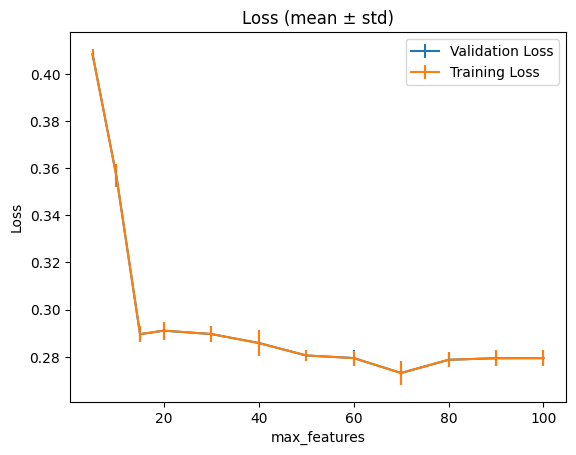


Averaged results:
max_features=5 | val=0.4082±0.0023 | train=0.4082±0.0023
max_features=10 | val=0.3568±0.0047 | train=0.3568±0.0047
max_features=15 | val=0.2895±0.0034 | train=0.2895±0.0034
max_features=20 | val=0.2910±0.0038 | train=0.2910±0.0038
max_features=30 | val=0.2896±0.0033 | train=0.2896±0.0033
max_features=40 | val=0.2858±0.0054 | train=0.2858±0.0054
max_features=50 | val=0.2805±0.0024 | train=0.2805±0.0024
max_features=60 | val=0.2794±0.0032 | train=0.2794±0.0032
max_features=70 | val=0.2731±0.0050 | train=0.2731±0.0050
max_features=80 | val=0.2787±0.0032 | train=0.2787±0.0032
max_features=90 | val=0.2794±0.0034 | train=0.2793±0.0034
max_features=100 | val=0.2794±0.0034 | train=0.2794±0.0034


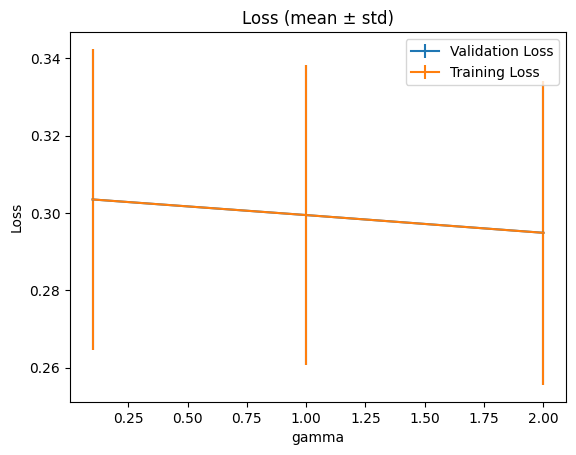


Averaged results:
gamma=0.1 | val=0.3035±0.0389 | train=0.3035±0.0389
gamma=1 | val=0.2995±0.0389 | train=0.2995±0.0389
gamma=2 | val=0.2949±0.0393 | train=0.2949±0.0393


In [20]:
from scripts.model_utils import show_printing_result

show_printing_result(
    args_logreg_1,
    validation_logreg_1,
    training_logreg_1,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result(
    args_logreg_1,
    validation_logreg_1,
    training_logreg_1,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62}
Average validation cross-validation loss: 0.27342817780921813


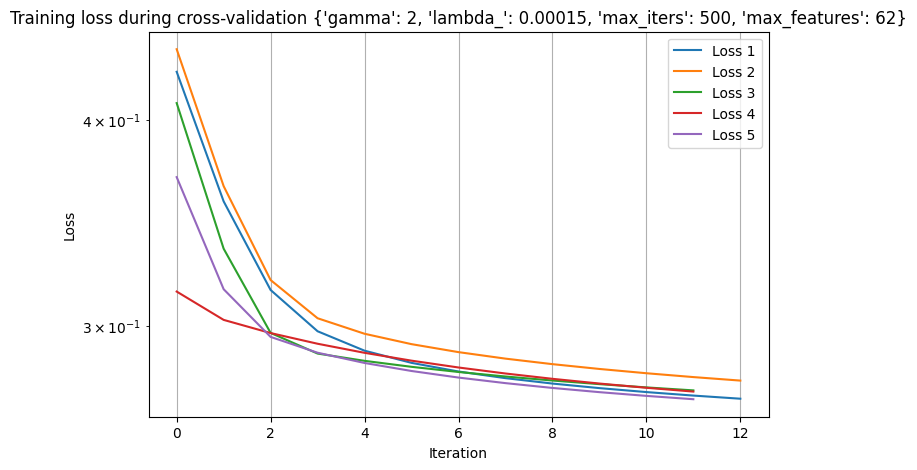

Tuning with args (2/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64}
Average validation cross-validation loss: 0.26856628165524127


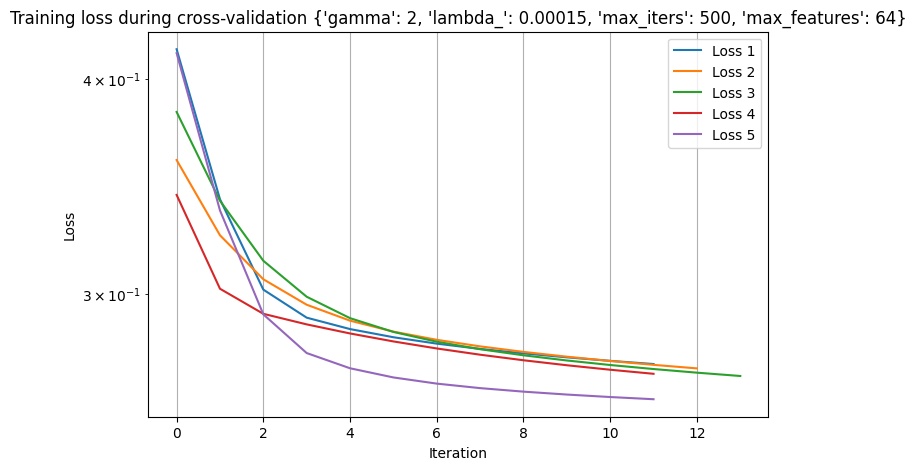

Tuning with args (3/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2686070366030826


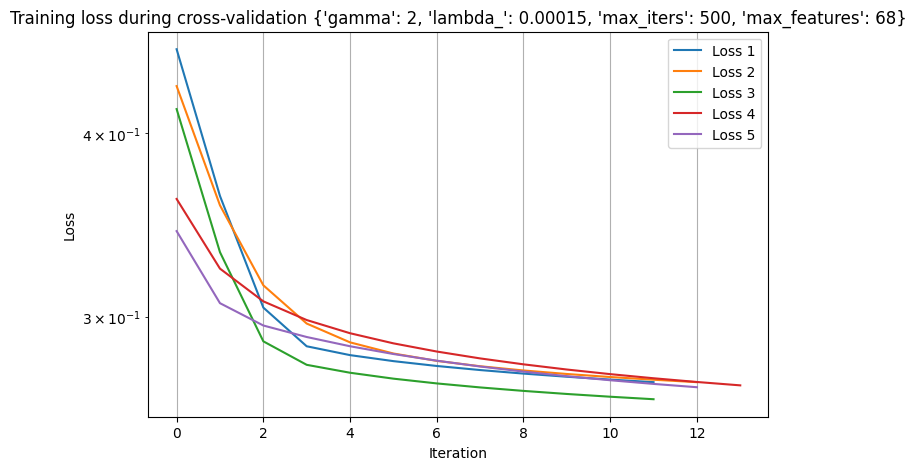

Tuning with args (4/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 72}
Average validation cross-validation loss: 0.273893977184157


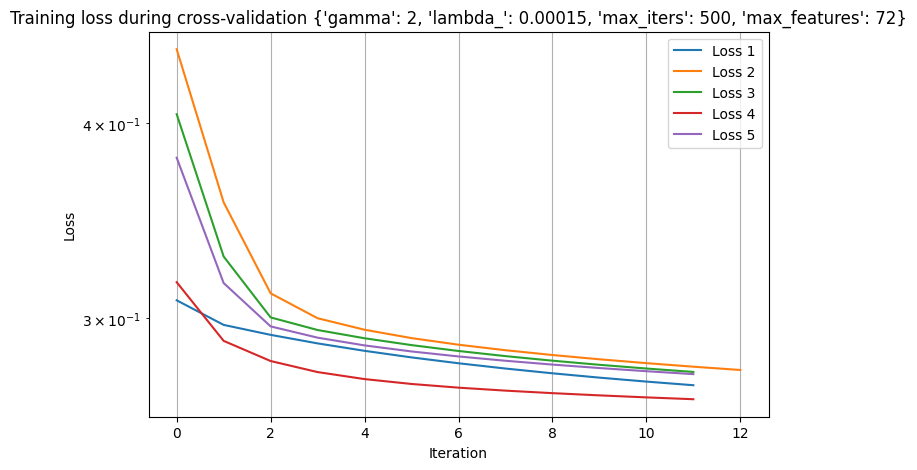

Tuning with args (5/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 74}
Average validation cross-validation loss: 0.2722394952984394


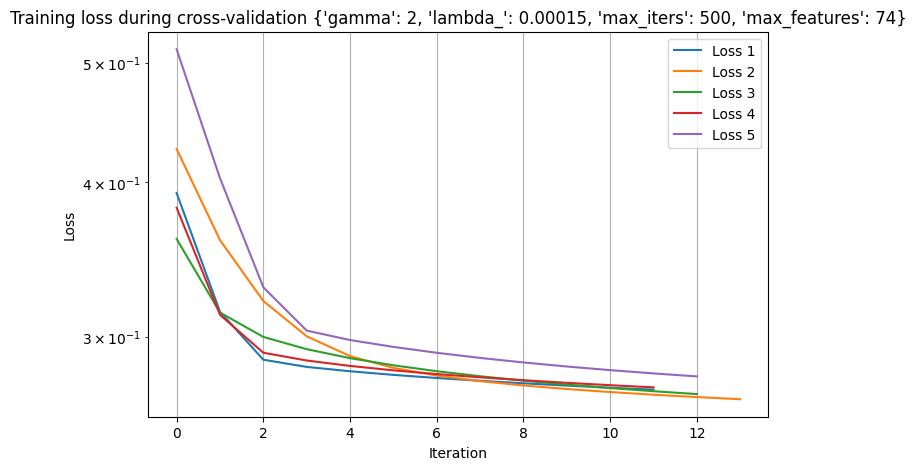

Tuning with args (6/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 76}
Average validation cross-validation loss: 0.27188924946603005


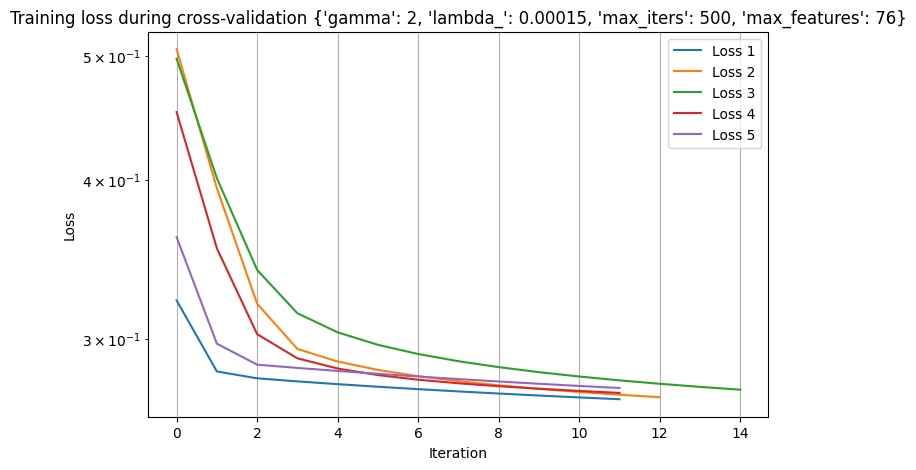

Tuning with args (7/16): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 78}
Average validation cross-validation loss: 0.27364165399528895


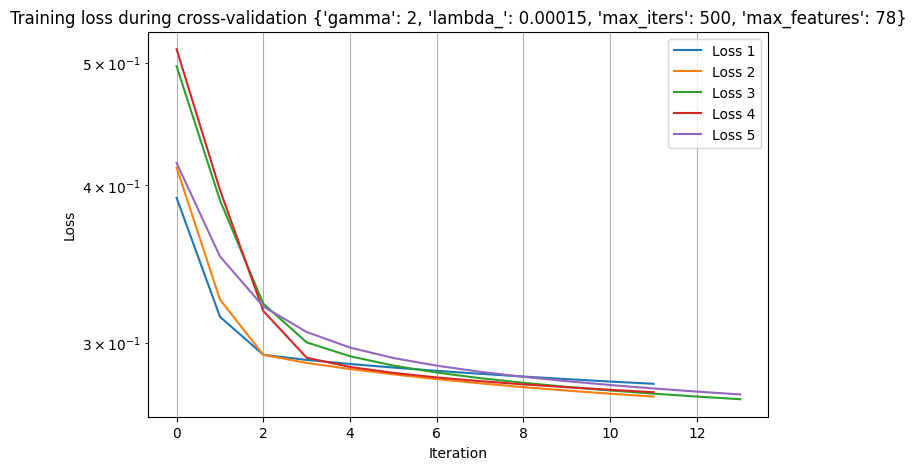

Tuning with args (8/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62}
Average validation cross-validation loss: 0.26442308615816706


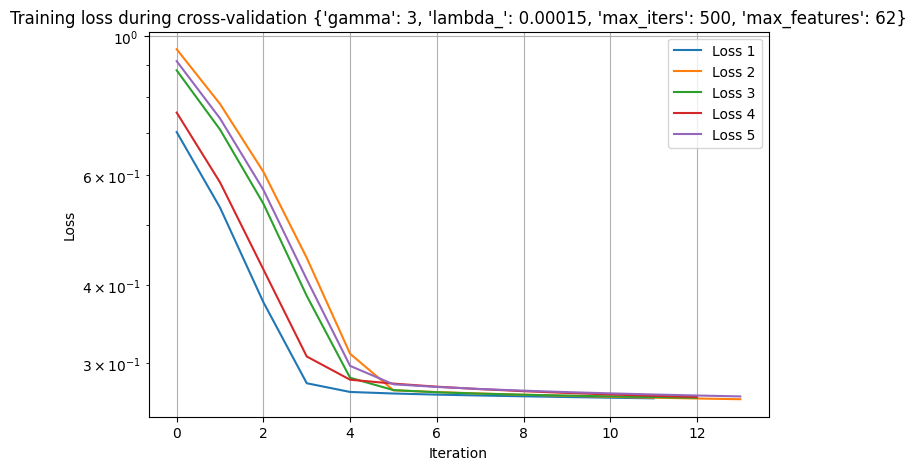

Tuning with args (9/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64}
Average validation cross-validation loss: 0.2622545642636915


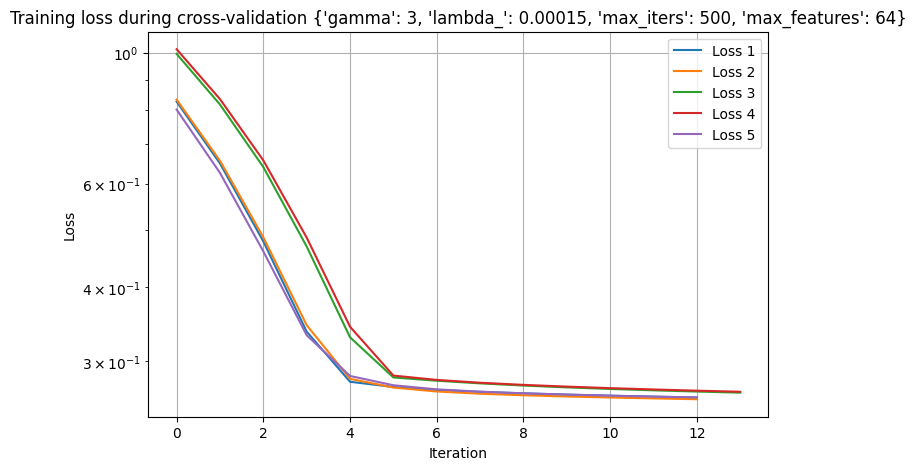

Tuning with args (10/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2592236358824021


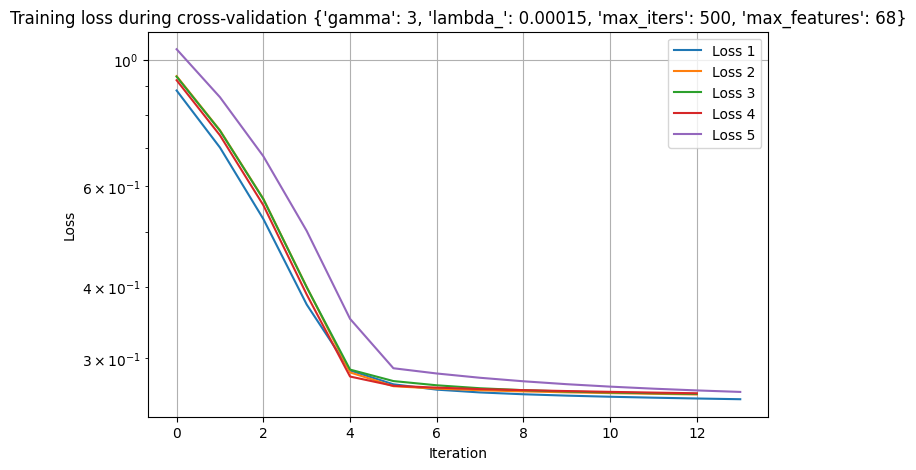

Tuning with args (11/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 72}
Average validation cross-validation loss: 0.2673650986746568


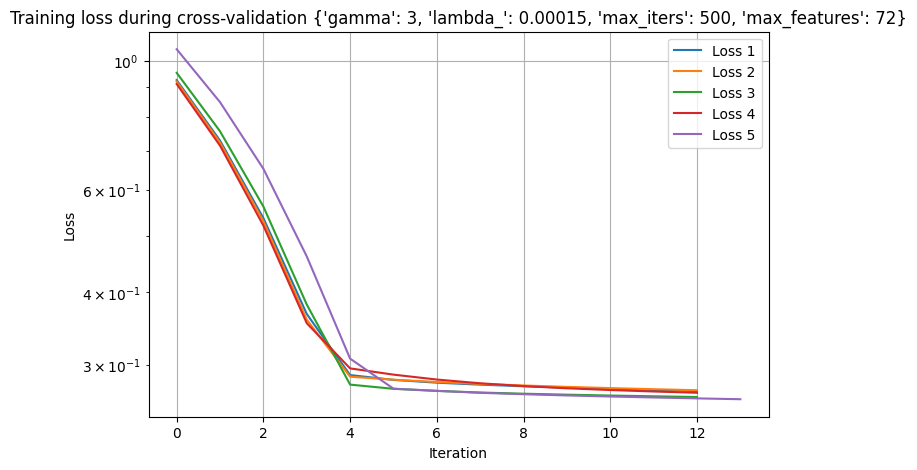

Tuning with args (12/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 74}
Average validation cross-validation loss: 0.2671206484585009


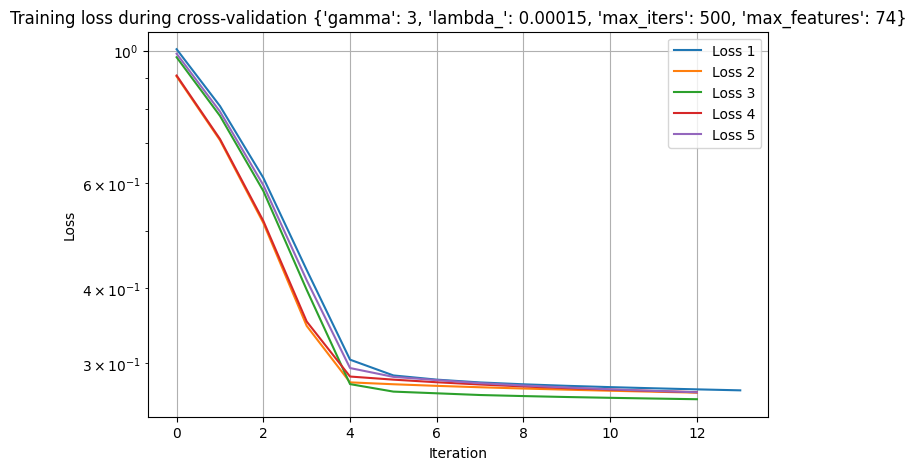

Tuning with args (13/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 76}
Average validation cross-validation loss: 0.26827393347843553


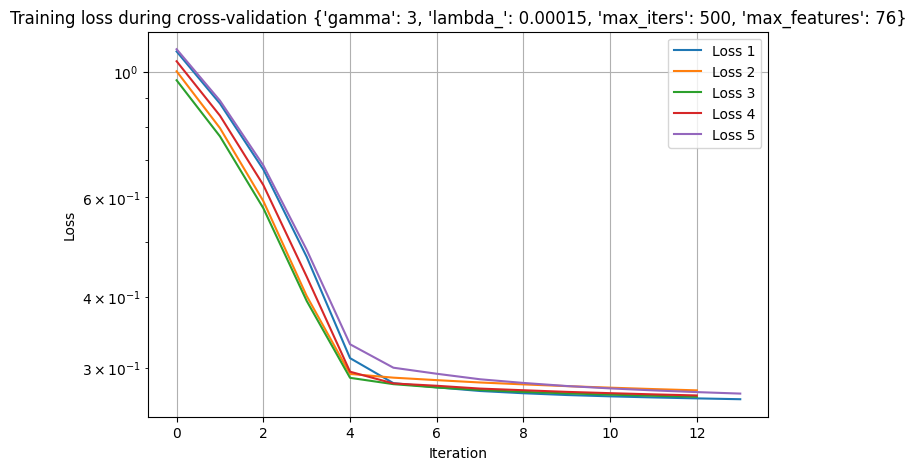

Tuning with args (14/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60}
Average validation cross-validation loss: 0.26409914725488565


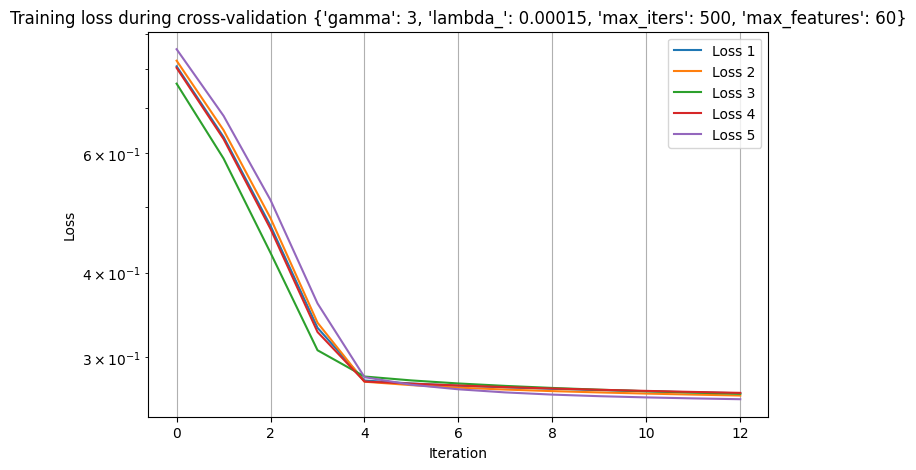

Tuning with args (15/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70}
Average validation cross-validation loss: 0.26206651553519966


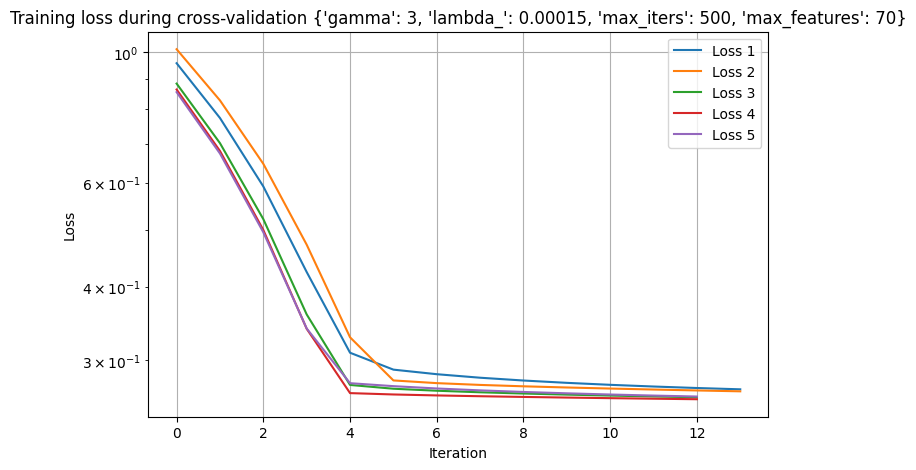

Tuning with args (16/16): {'gamma': 3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80}
Average validation cross-validation loss: 0.27164323642627347


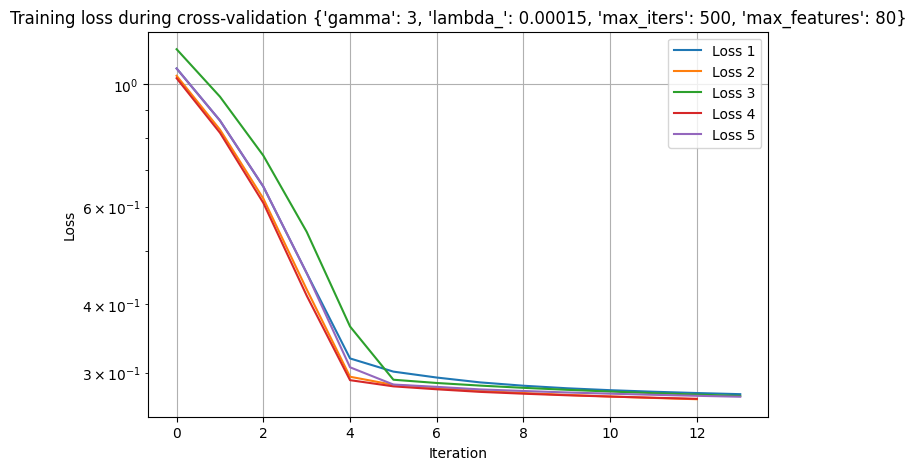

In [21]:
args_logreg_2 = [
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 62},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 64},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 72},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 74},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 76},
    {"gamma": 2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 78},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 62},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 64},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 72},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 74},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 76},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 60},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 70},
    {"gamma": 3, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 80},
]
validation_logreg_2, training_logreg_2 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_2
)

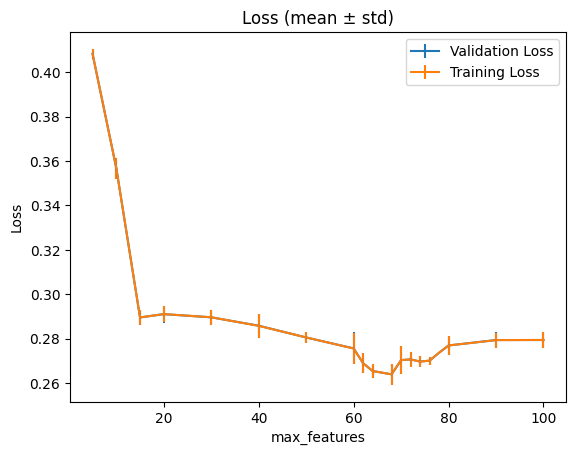


Averaged results:
max_features=5 | val=0.4082±0.0023 | train=0.4082±0.0023
max_features=10 | val=0.3568±0.0047 | train=0.3568±0.0047
max_features=15 | val=0.2895±0.0034 | train=0.2895±0.0034
max_features=20 | val=0.2910±0.0038 | train=0.2910±0.0038
max_features=30 | val=0.2896±0.0033 | train=0.2896±0.0033
max_features=40 | val=0.2858±0.0054 | train=0.2858±0.0054
max_features=50 | val=0.2805±0.0024 | train=0.2805±0.0024
max_features=60 | val=0.2756±0.0072 | train=0.2756±0.0072
max_features=62 | val=0.2689±0.0045 | train=0.2689±0.0045
max_features=64 | val=0.2654±0.0032 | train=0.2654±0.0032
max_features=68 | val=0.2639±0.0047 | train=0.2639±0.0047
max_features=70 | val=0.2703±0.0064 | train=0.2703±0.0064
max_features=72 | val=0.2706±0.0033 | train=0.2706±0.0033
max_features=74 | val=0.2697±0.0026 | train=0.2696±0.0026
max_features=76 | val=0.2701±0.0018 | train=0.2701±0.0018
max_features=78 | val=0.2736±0.0000 | train=0.2736±0.0000
max_features=80 | val=0.2769±0.0041 | train=0.2769±0.0

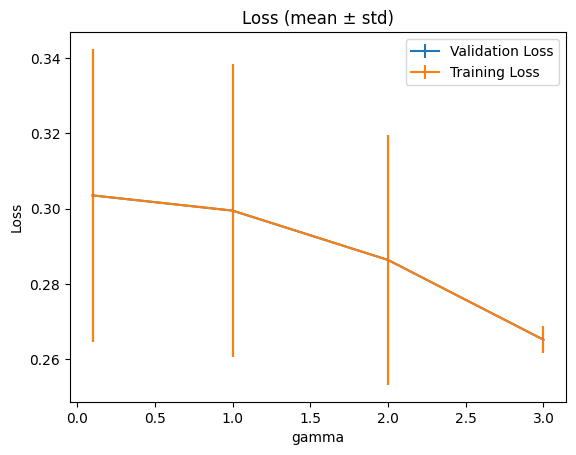


Averaged results:
gamma=0.1 | val=0.3035±0.0389 | train=0.3035±0.0389
gamma=1 | val=0.2995±0.0389 | train=0.2995±0.0389
gamma=2 | val=0.2864±0.0332 | train=0.2864±0.0332
gamma=3 | val=0.2652±0.0036 | train=0.2651±0.0036


In [22]:
all_args_logreg = args_logreg_2 + args_logreg_1
all_validation_logreg = validation_logreg_2 + validation_logreg_1
all_training_logreg = training_logreg_2 + training_logreg_1

show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/7): {'gamma': 4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2674168233167167


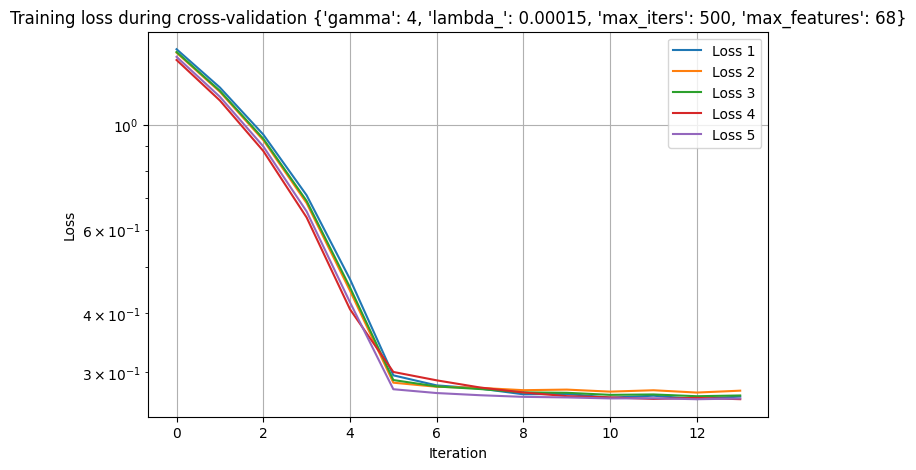

Tuning with args (2/7): {'gamma': 5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.28213021064658095


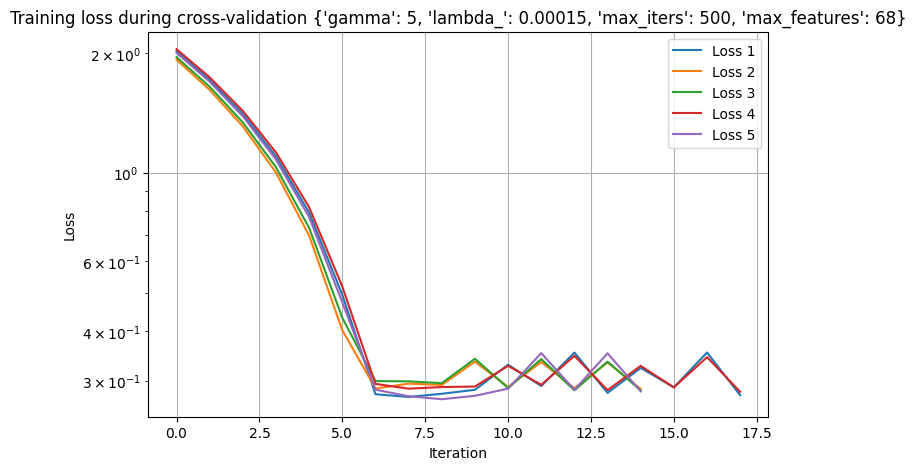

Tuning with args (3/7): {'gamma': 6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.3337400030536611


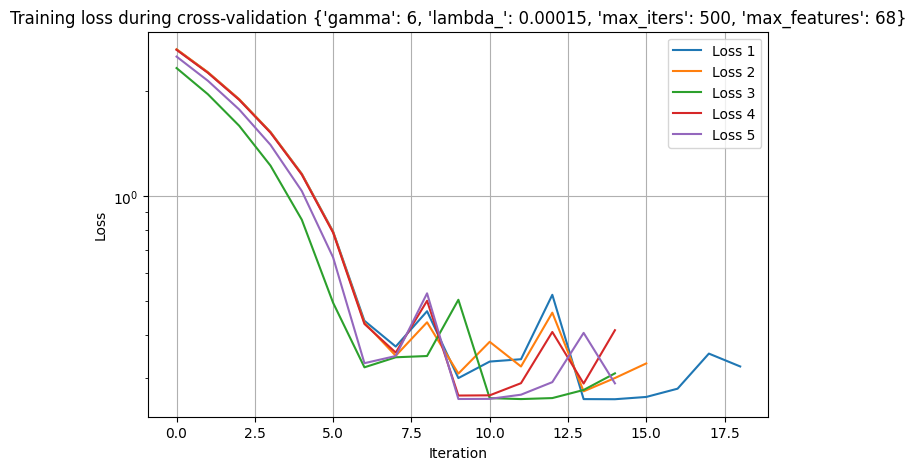

Tuning with args (4/7): {'gamma': 7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.31742700414450625


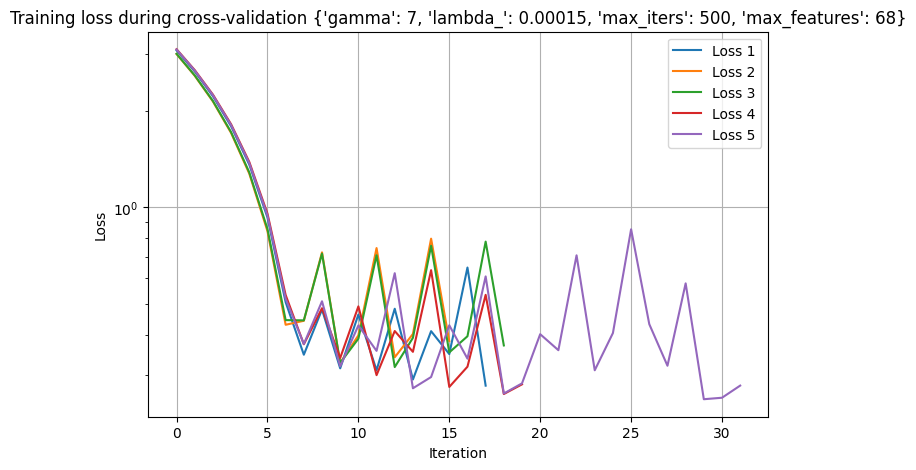

Tuning with args (5/7): {'gamma': 8, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.47944062355510386


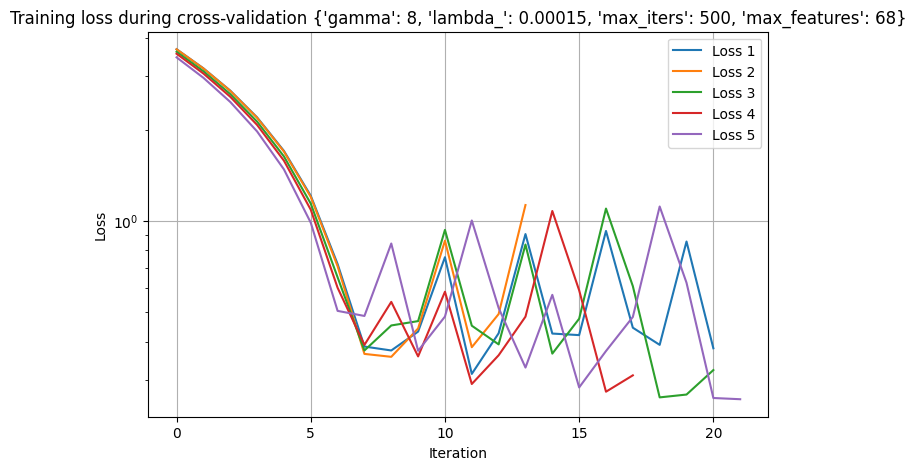

Tuning with args (6/7): {'gamma': 9, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.5229617096163144


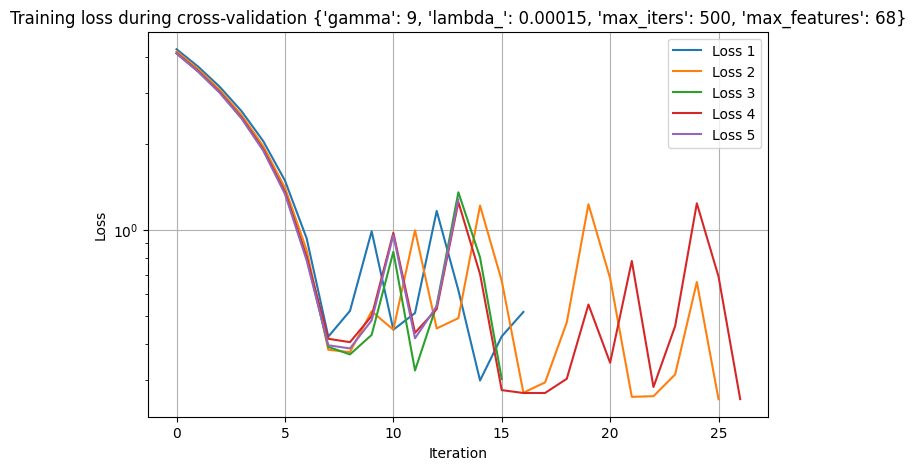

Tuning with args (7/7): {'gamma': 10, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.654811730514773


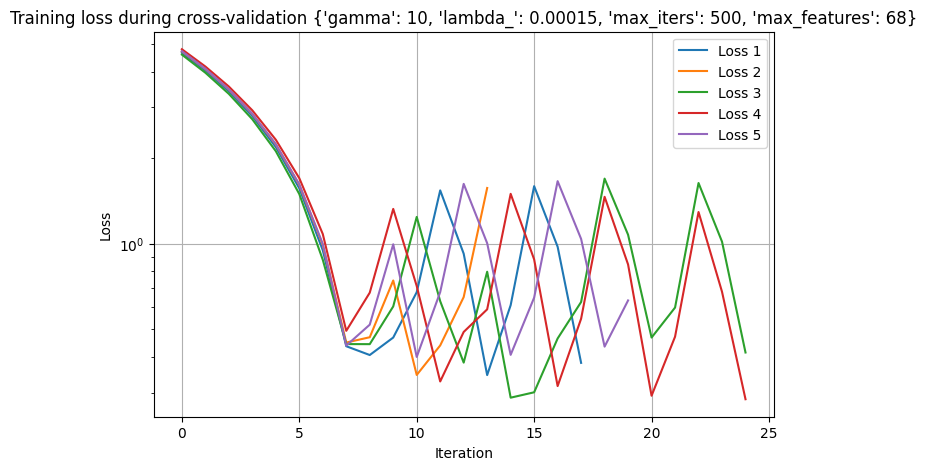

In [23]:
args_logreg_3 = [
    {"gamma": 4, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 5, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 6, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 7, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 8, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 9, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 10, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
]
validation_logreg_3, training_logreg_3 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_3
)

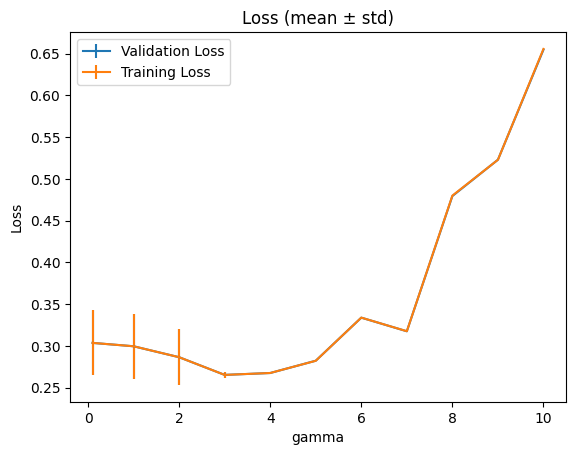


Averaged results:
gamma=0.1 | val=0.3035±0.0389 | train=0.3035±0.0389
gamma=1 | val=0.2995±0.0389 | train=0.2995±0.0389
gamma=2 | val=0.2864±0.0332 | train=0.2864±0.0332
gamma=3 | val=0.2652±0.0036 | train=0.2651±0.0036
gamma=4 | val=0.2674±0.0000 | train=0.2674±0.0000
gamma=5 | val=0.2821±0.0000 | train=0.2821±0.0000
gamma=6 | val=0.3337±0.0000 | train=0.3338±0.0000
gamma=7 | val=0.3174±0.0000 | train=0.3175±0.0000
gamma=8 | val=0.4794±0.0000 | train=0.4800±0.0000
gamma=9 | val=0.5230±0.0000 | train=0.5229±0.0000
gamma=10 | val=0.6548±0.0000 | train=0.6557±0.0000


In [24]:
all_args_logreg = args_logreg_2 + args_logreg_1 + args_logreg_3
all_validation_logreg = validation_logreg_2 + validation_logreg_1 + validation_logreg_3
all_training_logreg = training_logreg_2 + training_logreg_1 + training_logreg_3

show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/11): {'gamma': 2.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26615347639771647


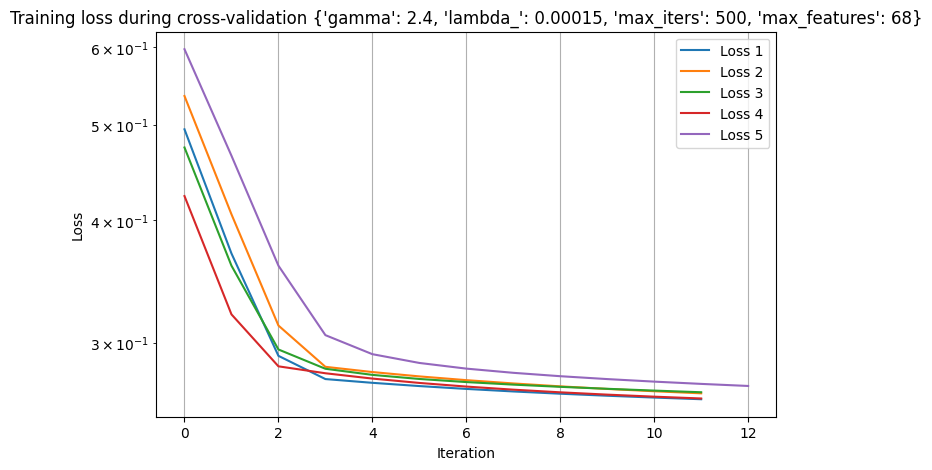

Tuning with args (2/11): {'gamma': 2.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2676033398872103


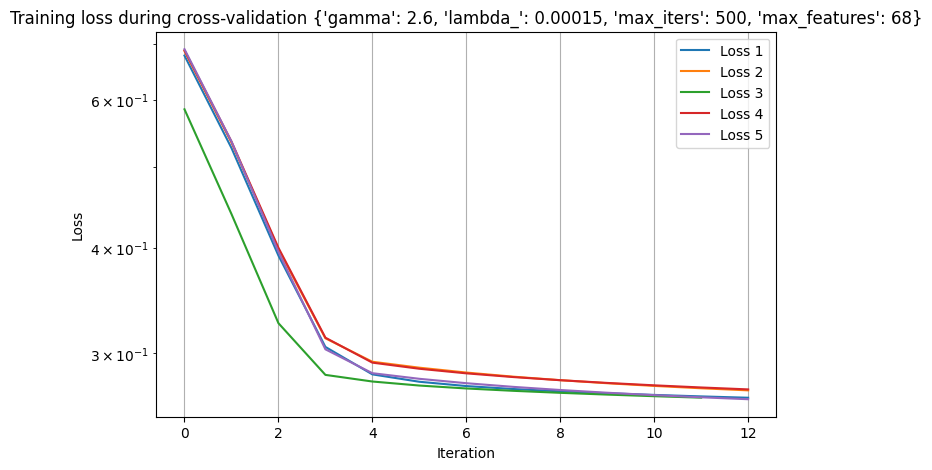

Tuning with args (3/11): {'gamma': 2.8, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2644510527809428


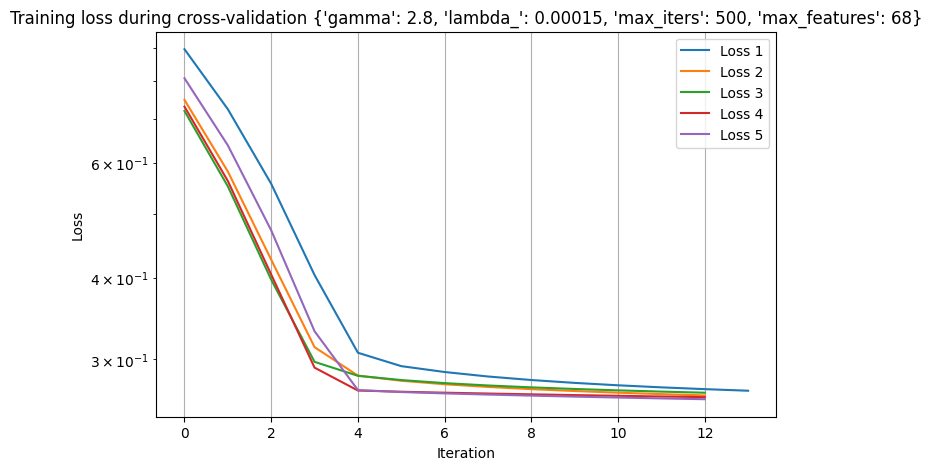

Tuning with args (4/11): {'gamma': 3.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2660025342405915


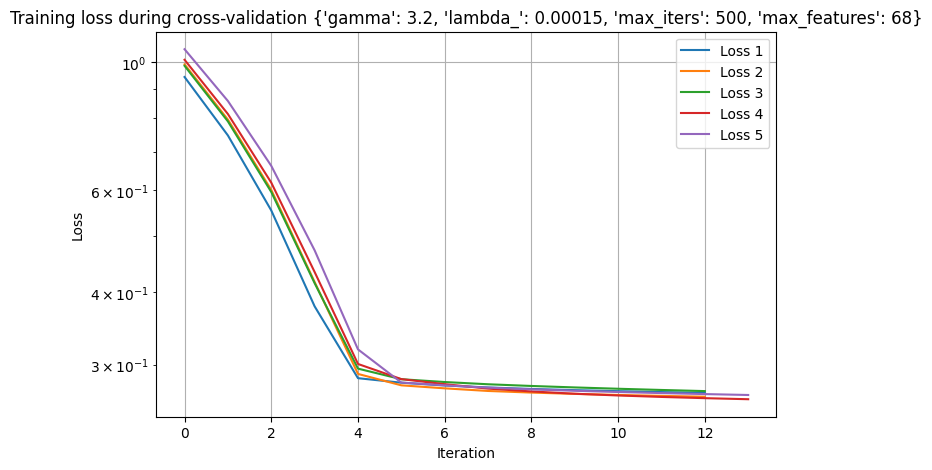

Tuning with args (5/11): {'gamma': 3.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26220618875702784


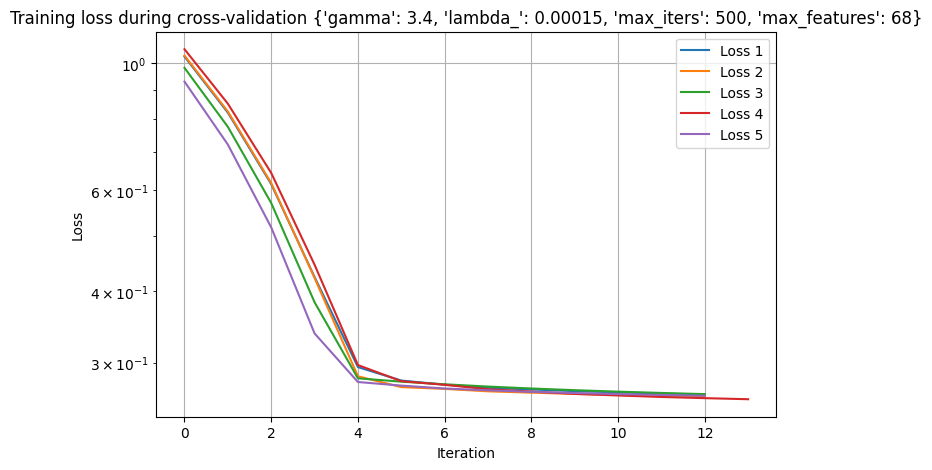

Tuning with args (6/11): {'gamma': 3.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26401543103360386


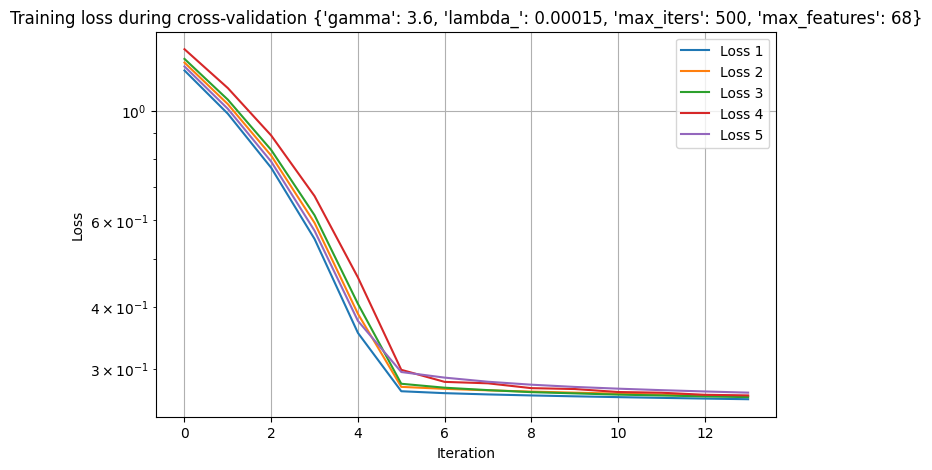

Tuning with args (7/11): {'gamma': 3.8, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26378980851793465


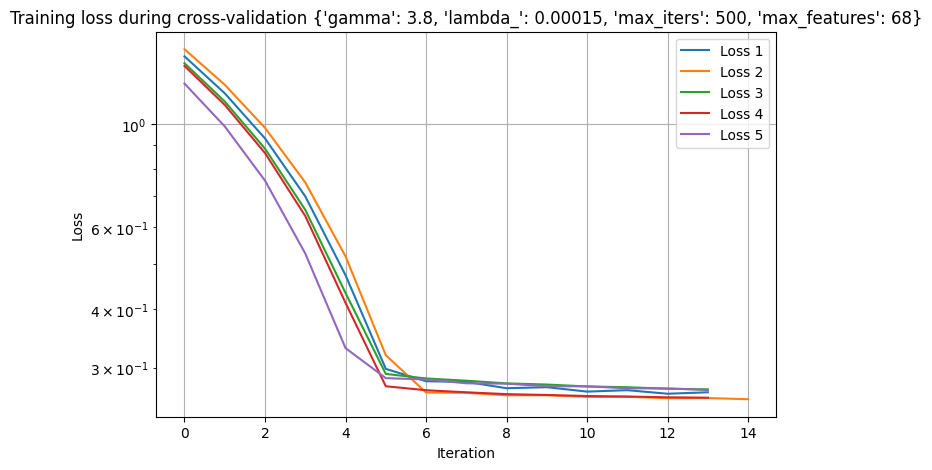

Tuning with args (8/11): {'gamma': 4.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.27716892610372834


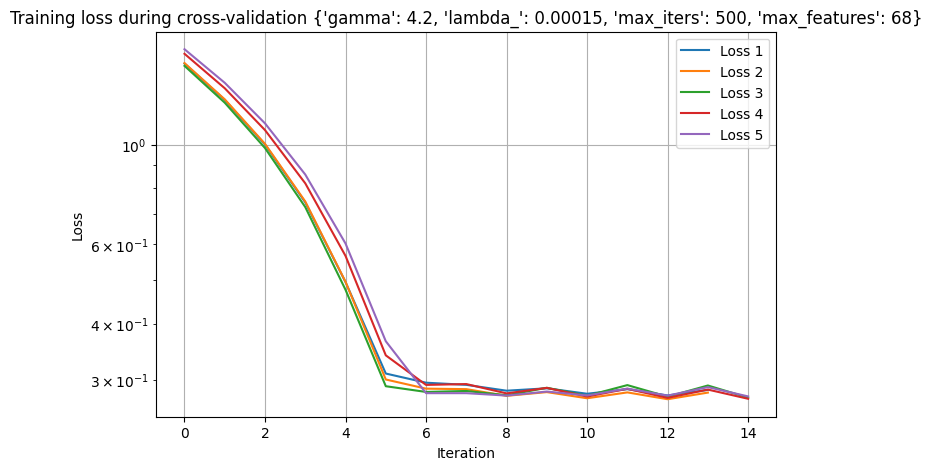

Tuning with args (9/11): {'gamma': 4.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.27766562098484127


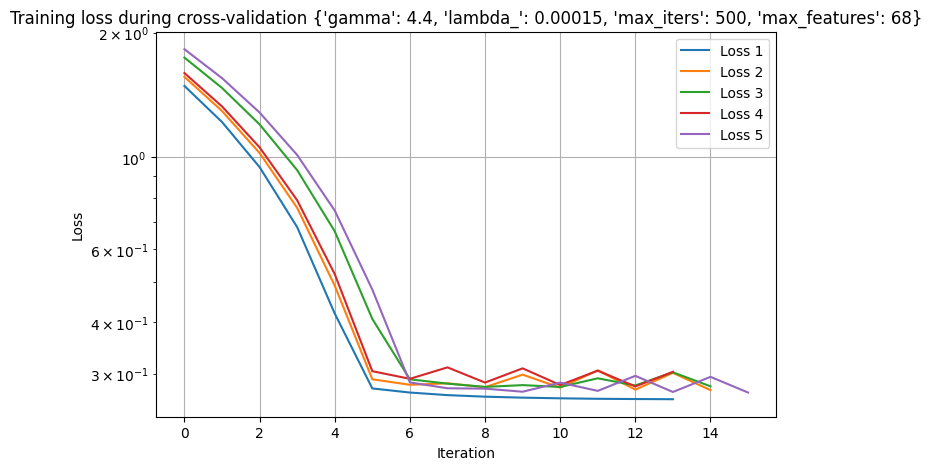

Tuning with args (10/11): {'gamma': 4.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2784746666409033


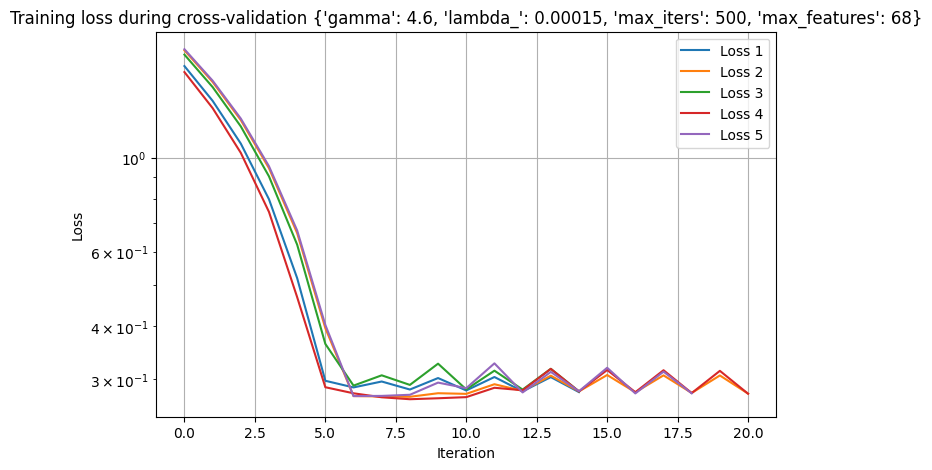

Tuning with args (11/11): {'gamma': 4.8, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2797390713732716


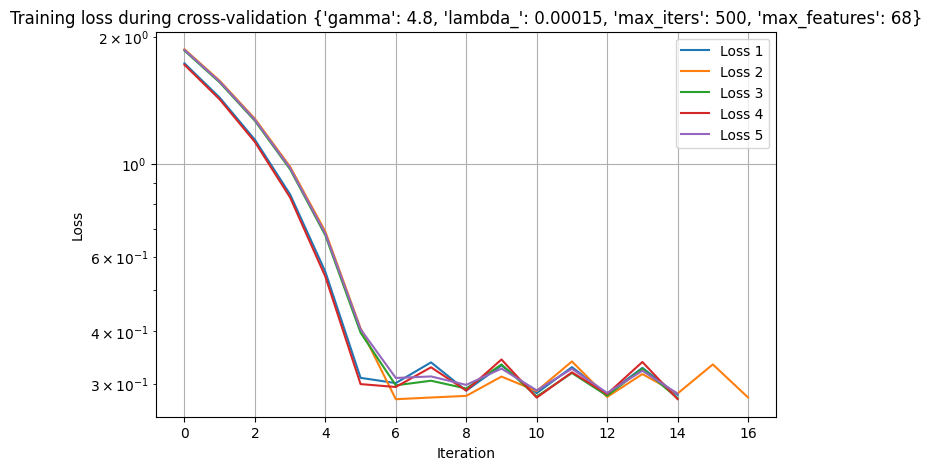

In [25]:
args_logreg_4 = [
    {"gamma": 2.4, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 2.6, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 2.8, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.4, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.6, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.8, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 4.2, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 4.4, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 4.6, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 4.8, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
]
validation_logreg_4, training_logreg_4 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_4
)

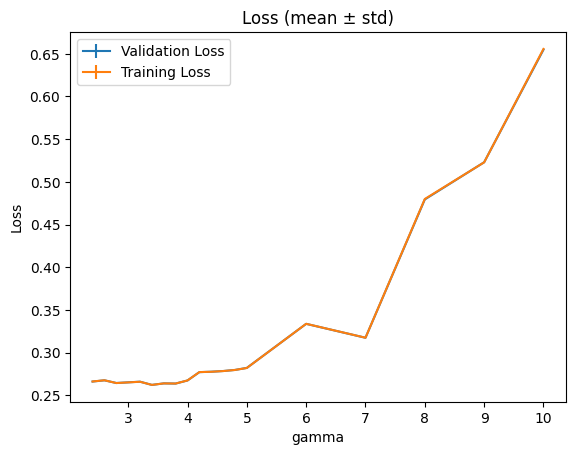


Averaged results:
gamma=2.4 | val=0.2662±0.0000 | train=0.2662±0.0000
gamma=2.6 | val=0.2676±0.0000 | train=0.2677±0.0000
gamma=2.8 | val=0.2645±0.0000 | train=0.2644±0.0000
gamma=3.2 | val=0.2660±0.0000 | train=0.2659±0.0000
gamma=3.4 | val=0.2622±0.0000 | train=0.2622±0.0000
gamma=3.6 | val=0.2640±0.0000 | train=0.2640±0.0000
gamma=3.8 | val=0.2638±0.0000 | train=0.2638±0.0000
gamma=4 | val=0.2674±0.0000 | train=0.2674±0.0000
gamma=4.2 | val=0.2772±0.0000 | train=0.2772±0.0000
gamma=4.4 | val=0.2777±0.0000 | train=0.2776±0.0000
gamma=4.6 | val=0.2785±0.0000 | train=0.2784±0.0000
gamma=4.8 | val=0.2797±0.0000 | train=0.2797±0.0000
gamma=5 | val=0.2821±0.0000 | train=0.2821±0.0000
gamma=6 | val=0.3337±0.0000 | train=0.3338±0.0000
gamma=7 | val=0.3174±0.0000 | train=0.3175±0.0000
gamma=8 | val=0.4794±0.0000 | train=0.4800±0.0000
gamma=9 | val=0.5230±0.0000 | train=0.5229±0.0000
gamma=10 | val=0.6548±0.0000 | train=0.6557±0.0000


In [26]:
all_args_logreg = args_logreg_3 + args_logreg_4
all_validation_logreg = validation_logreg_3 + validation_logreg_4
all_training_logreg = training_logreg_3 + training_logreg_4

show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/3): {'gamma': 3.7, 'lambda_': 0.0001, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2641069172399034


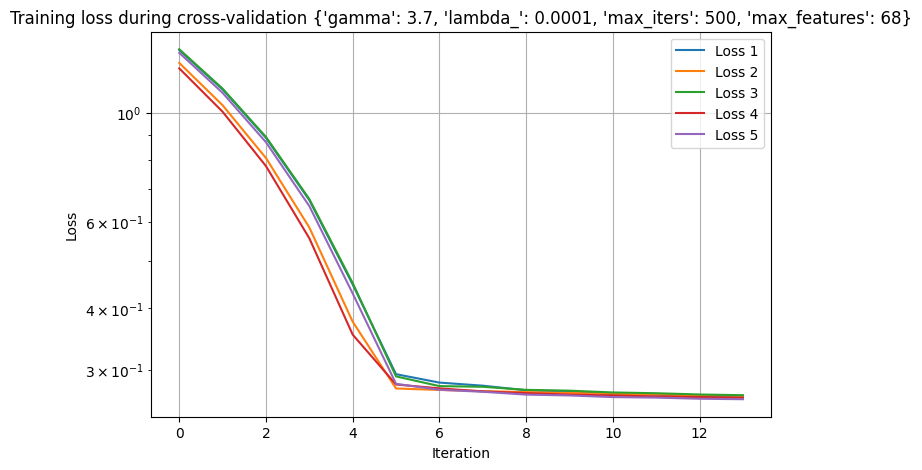

Tuning with args (2/3): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2624570016207327


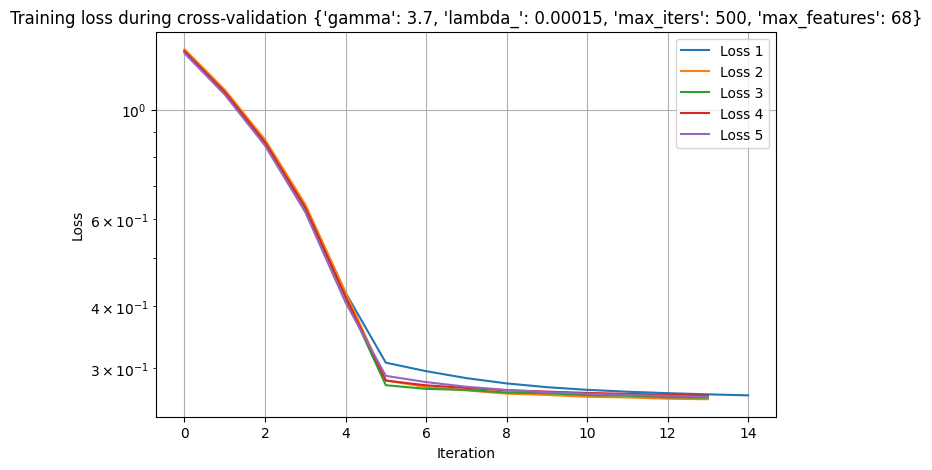

Tuning with args (3/3): {'gamma': 3.7, 'lambda_': 0.0002, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.2584791595942955


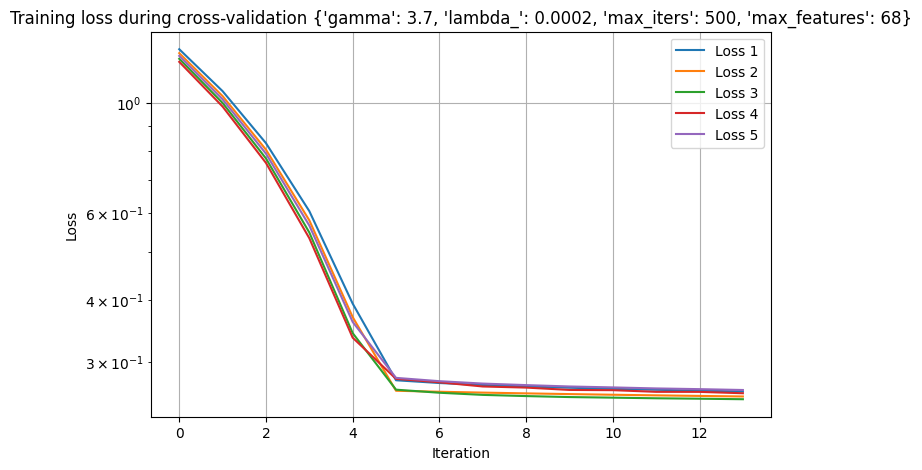

In [27]:
args_logreg_5 = [
    {"gamma": 3.7, "lambda_": 1.0e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.7, "lambda_": 1.5e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.7, "lambda_": 2e-4, "max_iters": 500, "max_features": 68},
]
validation_logreg_5, training_logreg_5 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_5
)

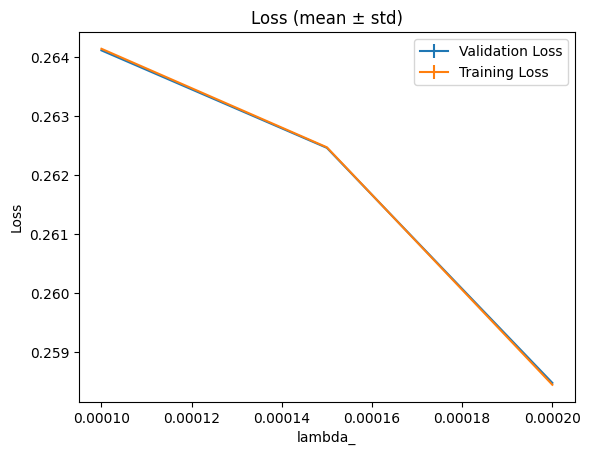


Averaged results:
lambda_=0.0001 | val=0.2641±0.0000 | train=0.2641±0.0000
lambda_=0.00015 | val=0.2625±0.0000 | train=0.2625±0.0000
lambda_=0.0002 | val=0.2585±0.0000 | train=0.2584±0.0000


In [28]:
all_args_logreg = args_logreg_5
all_validation_logreg = validation_logreg_5
all_training_logreg = training_logreg_5

show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "lambda_",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/4): {'gamma': 3.7, 'lambda_': 0.00012, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.262390313145613


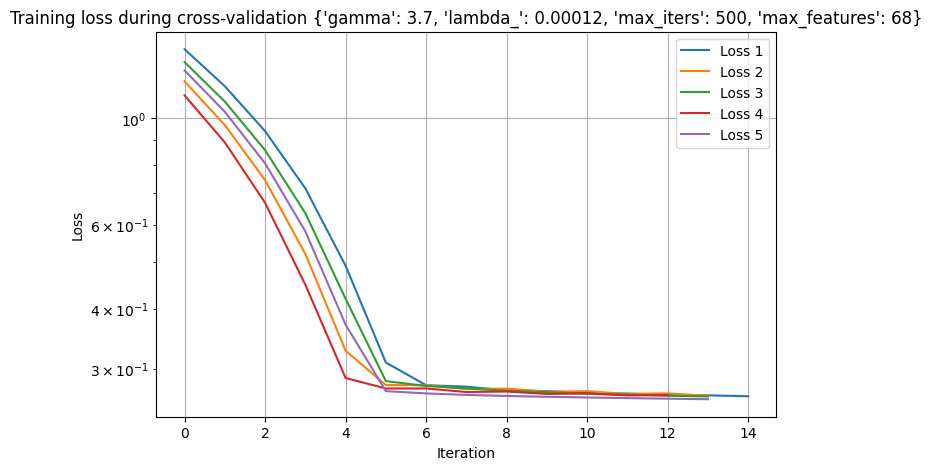

Tuning with args (2/4): {'gamma': 3.7, 'lambda_': 0.00014, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26154590041752257


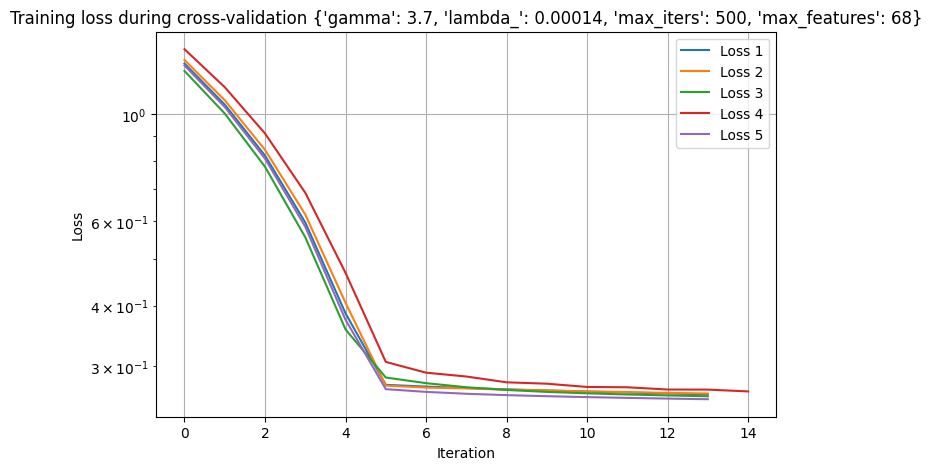

Tuning with args (3/4): {'gamma': 3.7, 'lambda_': 0.00016, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.26090430451106494


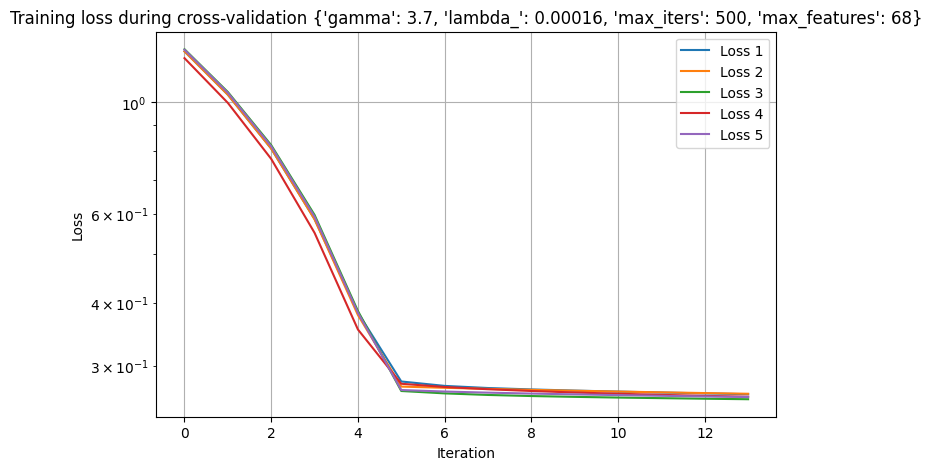

Tuning with args (4/4): {'gamma': 3.7, 'lambda_': 0.00018, 'max_iters': 500, 'max_features': 68}
Average validation cross-validation loss: 0.262378762289219


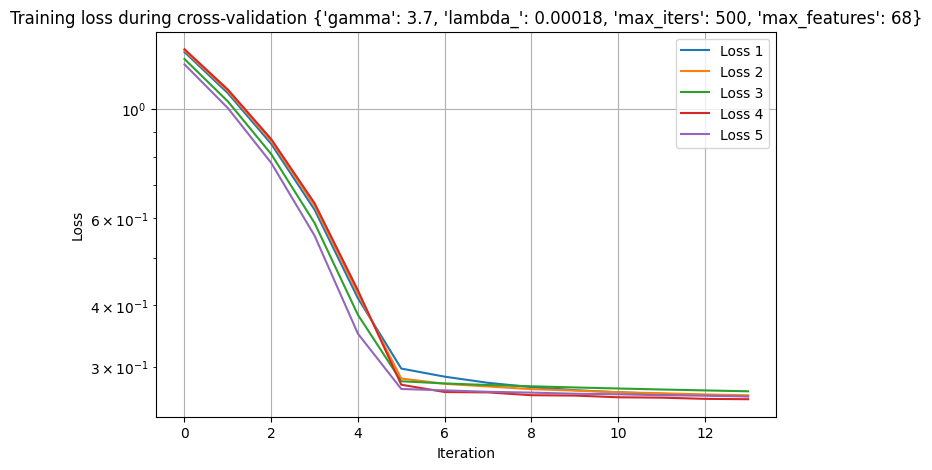

In [29]:
args_logreg_6 = [
    {"gamma": 3.7, "lambda_": 1.2e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.7, "lambda_": 1.4e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.7, "lambda_": 1.6e-4, "max_iters": 500, "max_features": 68},
    {"gamma": 3.7, "lambda_": 1.8e-4, "max_iters": 500, "max_features": 68},
]
validation_logreg_6, training_logreg_6 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_6
)

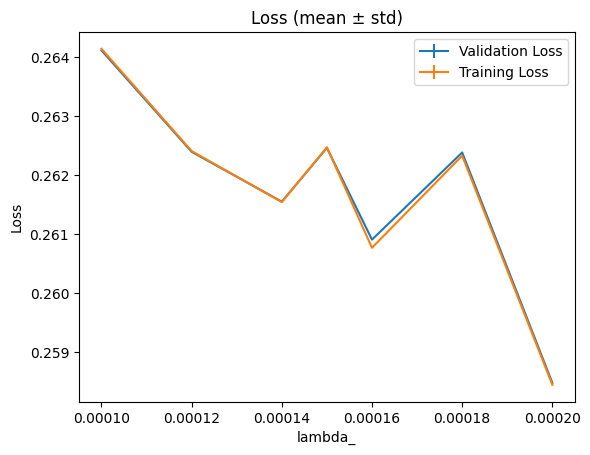


Averaged results:
lambda_=0.0001 | val=0.2641±0.0000 | train=0.2641±0.0000
lambda_=0.00012 | val=0.2624±0.0000 | train=0.2624±0.0000
lambda_=0.00014 | val=0.2615±0.0000 | train=0.2615±0.0000
lambda_=0.00015 | val=0.2625±0.0000 | train=0.2625±0.0000
lambda_=0.00016 | val=0.2609±0.0000 | train=0.2608±0.0000
lambda_=0.00018 | val=0.2624±0.0000 | train=0.2623±0.0000
lambda_=0.0002 | val=0.2585±0.0000 | train=0.2584±0.0000


In [30]:
all_args_logreg = args_logreg_5 + args_logreg_6
all_validation_logreg = validation_logreg_5 + validation_logreg_6
all_training_logreg = training_logreg_5 + training_logreg_6

show_printing_result(
    all_args_logreg,
    all_validation_logreg,
    all_training_logreg,
    "lambda_",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

#### Tuning for F1

Tuning with args (1/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.09470551879437554


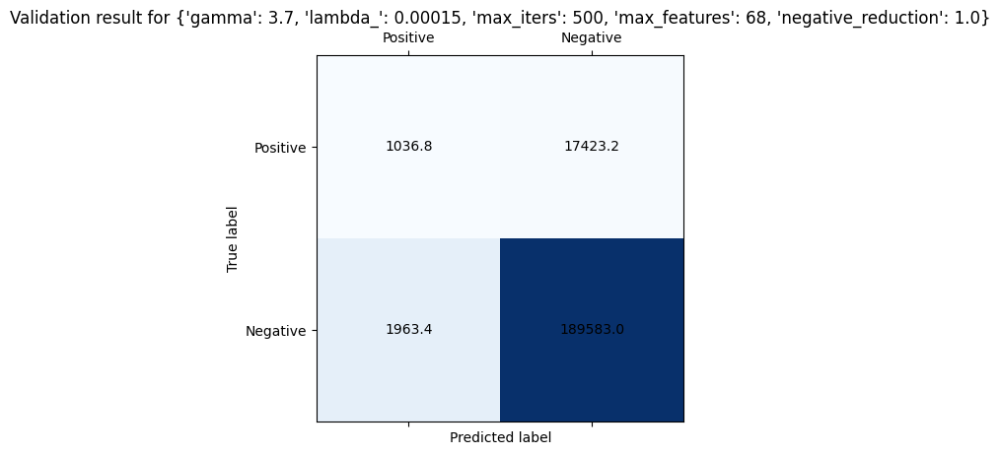

Tuning with args (2/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.13080965117421234


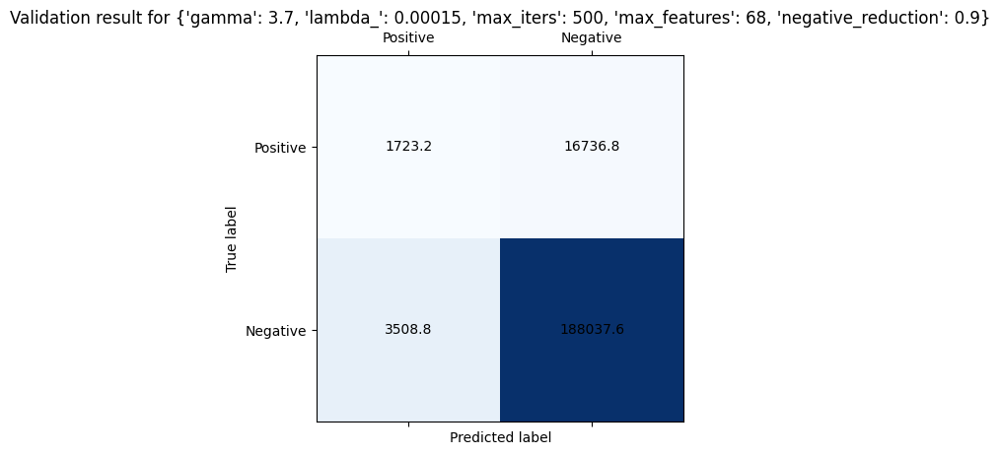

Tuning with args (3/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.18971672539444032


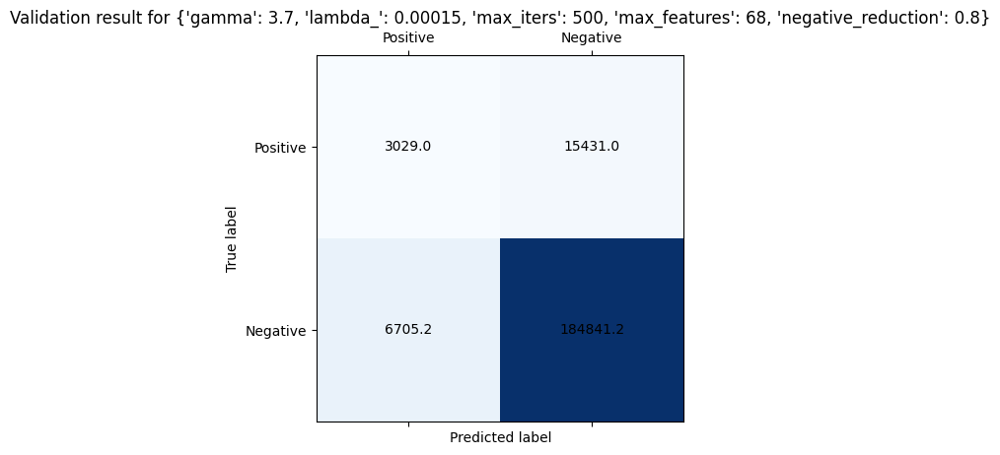

Tuning with args (4/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.2419990885653513


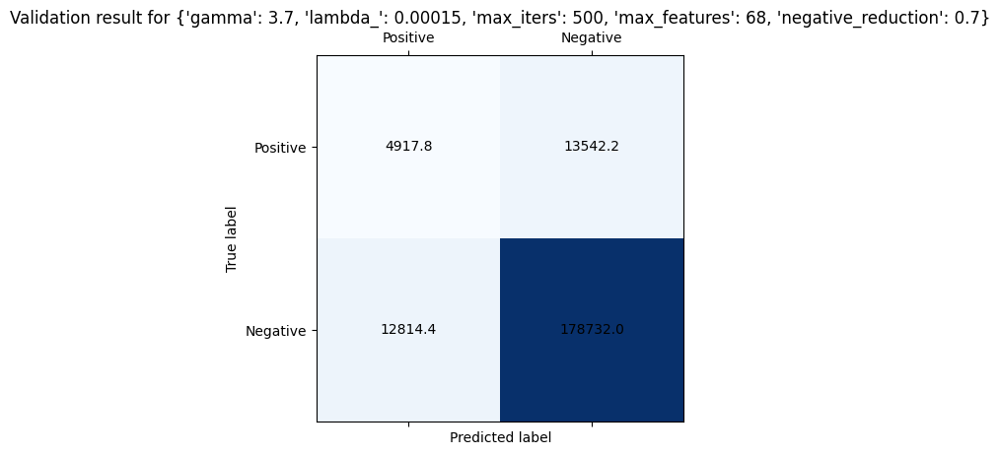

Tuning with args (5/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.2561199296641289


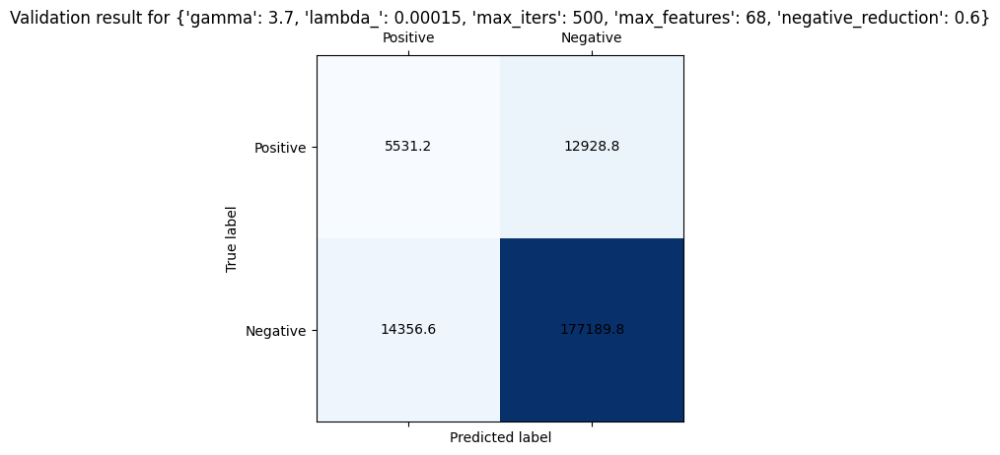

Tuning with args (6/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.2955867737468847


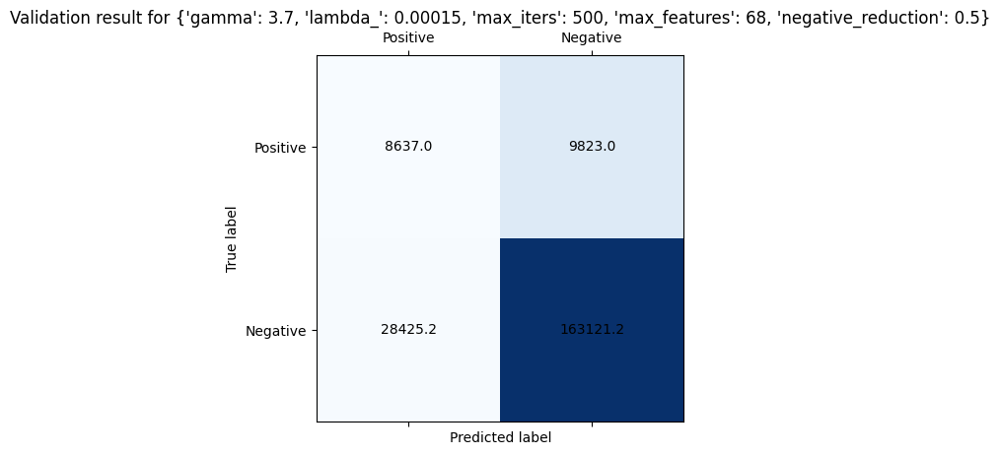

Tuning with args (7/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.20080109863782886


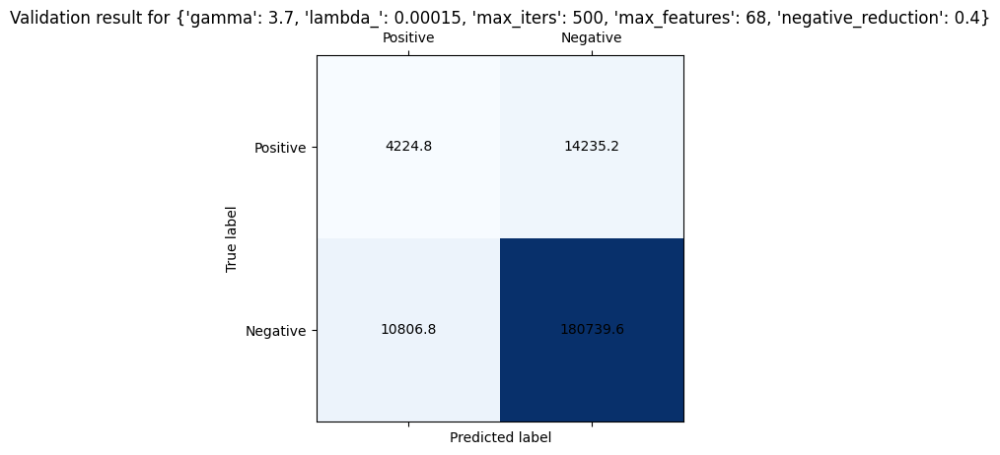

Tuning with args (8/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.24869094713668388


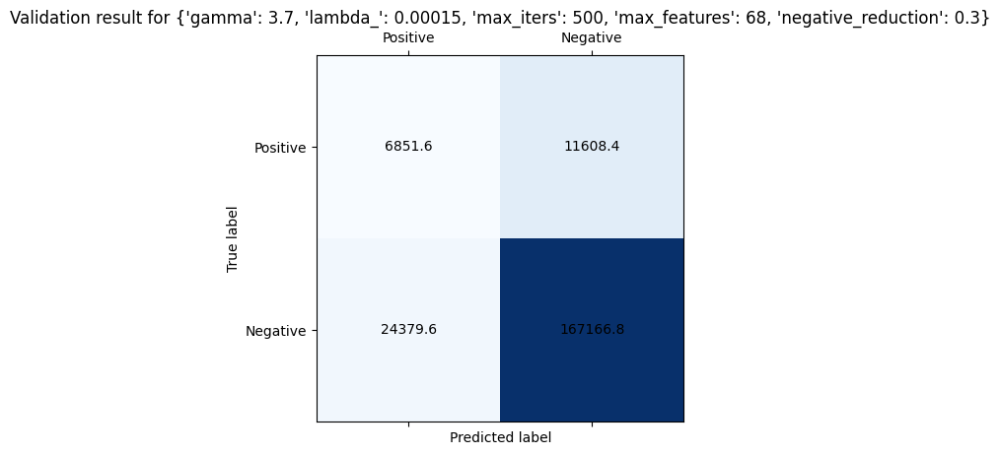

Tuning with args (9/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.018930306963562536


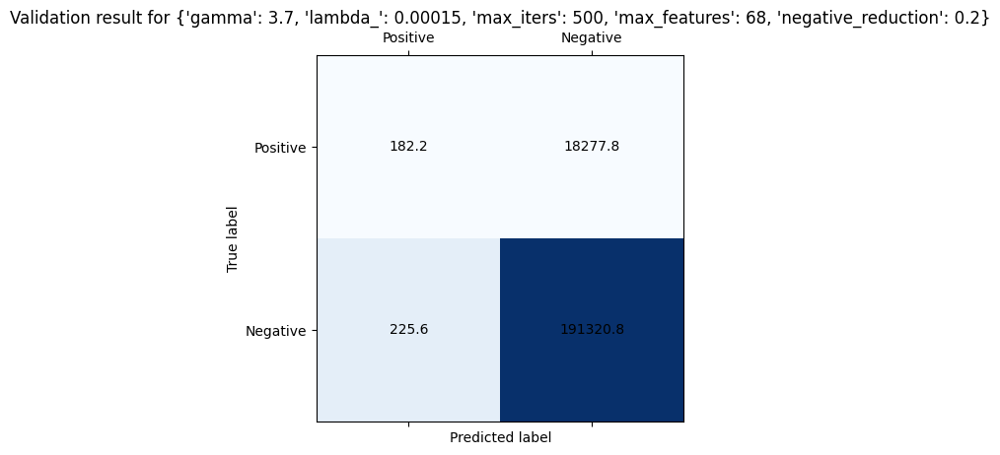

Tuning with args (10/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.2437740205862473


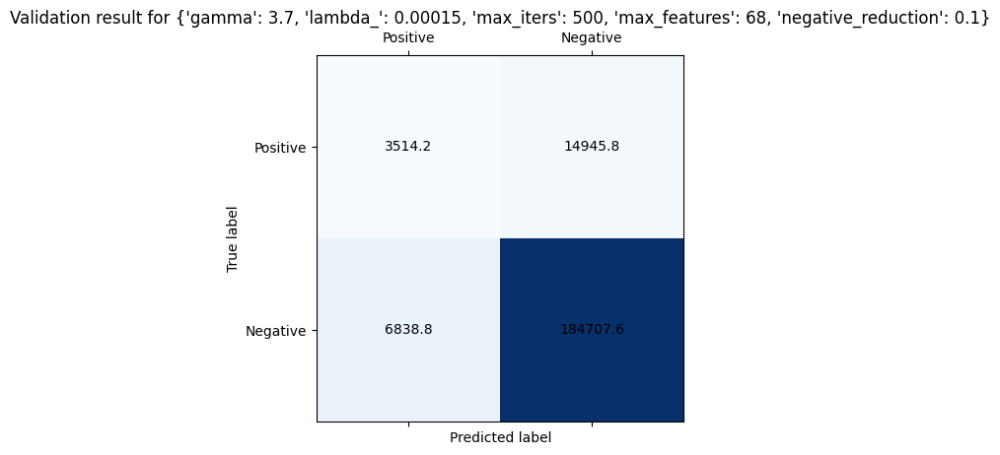

In [30]:
from scripts.model_utils import tune_f1
from scripts.models import RegularizedLogisticRegression

args_logreg_f1_1 = [
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 1.0,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.9,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.8,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.7,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.6,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.5,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.4,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.3,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.2,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.1,
    },
]
validation_f1_logreg_1 = tune_f1(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_f1_1
)

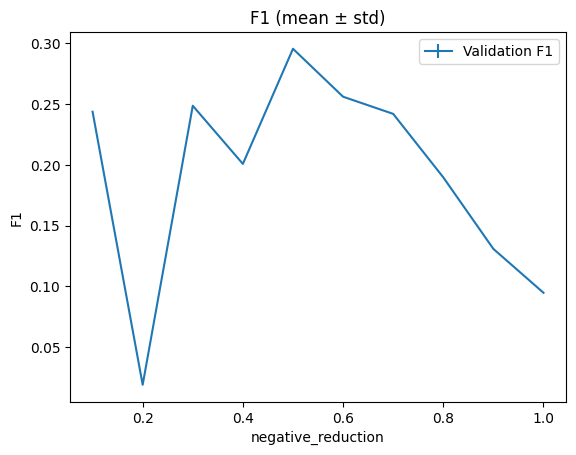


Averaged results:
negative_reduction=0.1 | val=0.2438±0.0000
negative_reduction=0.2 | val=0.0189±0.0000
negative_reduction=0.3 | val=0.2487±0.0000
negative_reduction=0.4 | val=0.2008±0.0000
negative_reduction=0.5 | val=0.2956±0.0000
negative_reduction=0.6 | val=0.2561±0.0000
negative_reduction=0.7 | val=0.2420±0.0000
negative_reduction=0.8 | val=0.1897±0.0000
negative_reduction=0.9 | val=0.1308±0.0000
negative_reduction=1 | val=0.0947±0.0000


In [31]:
from scripts.model_utils import show_printing_result_f1
show_printing_result_f1(
    args_logreg_f1_1,
    validation_f1_logreg_1,
    "negative_reduction",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False
)

Tuning with args (1/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.10750272822234037


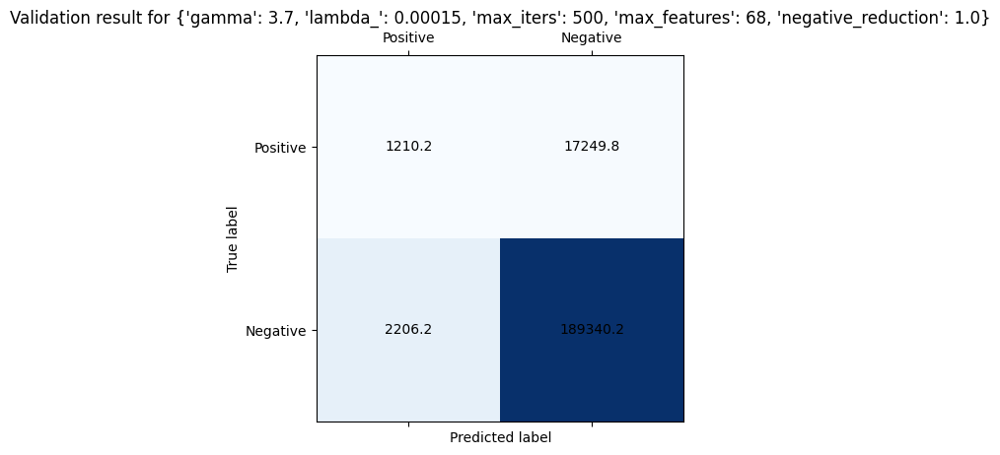

Tuning with args (2/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.10445274382255021


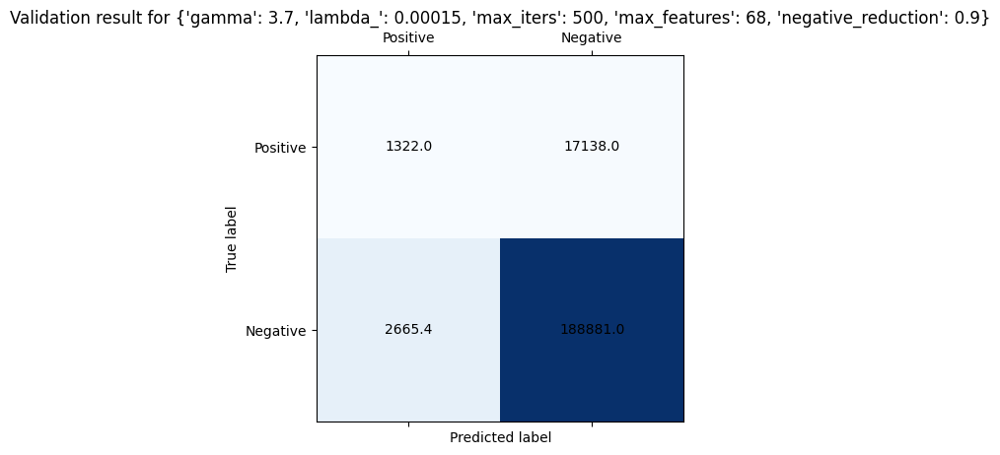

Tuning with args (3/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.17980869243764552


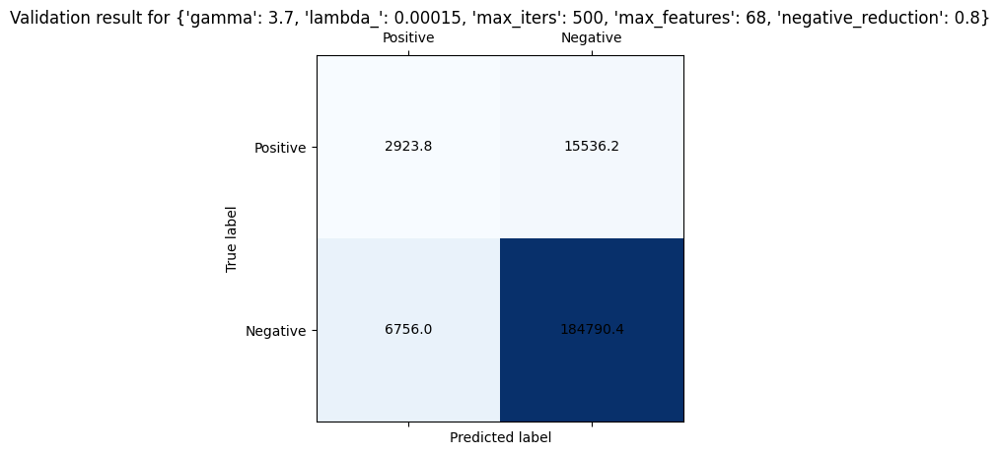

Tuning with args (4/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.12305561922499704


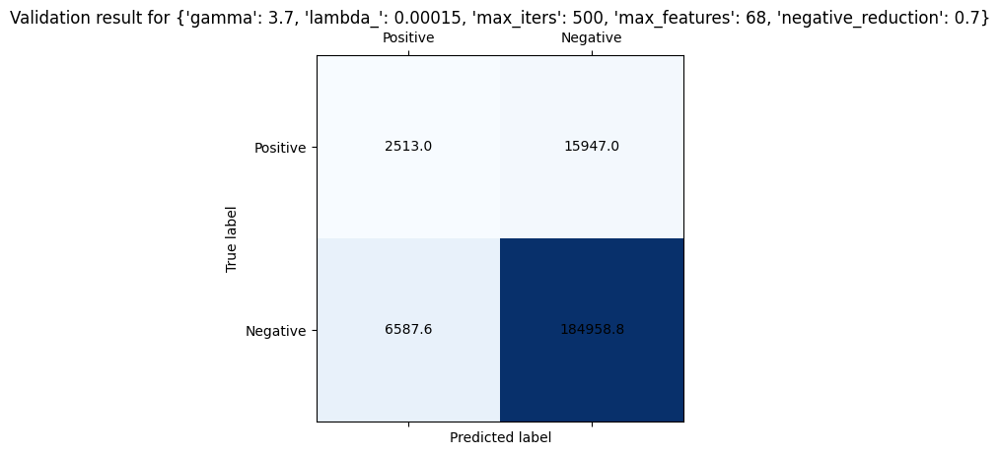

Tuning with args (5/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.265133557649469


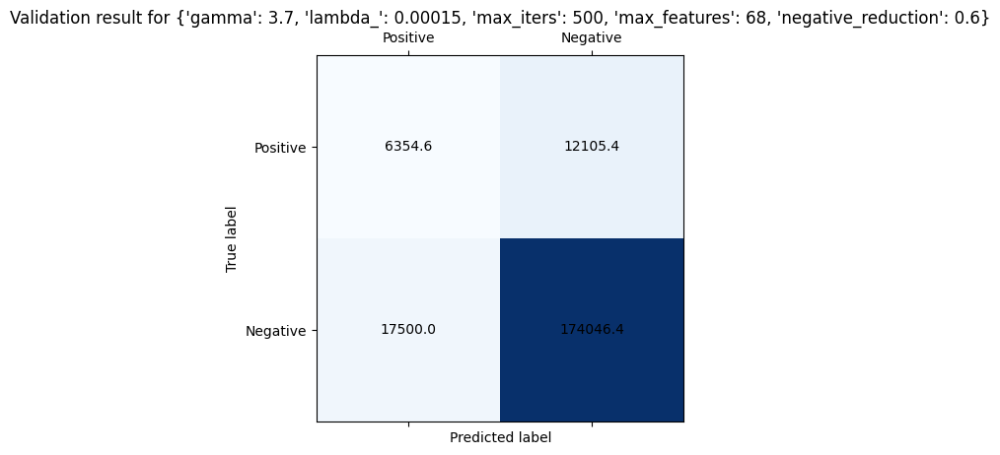

Tuning with args (6/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.3045190913160729


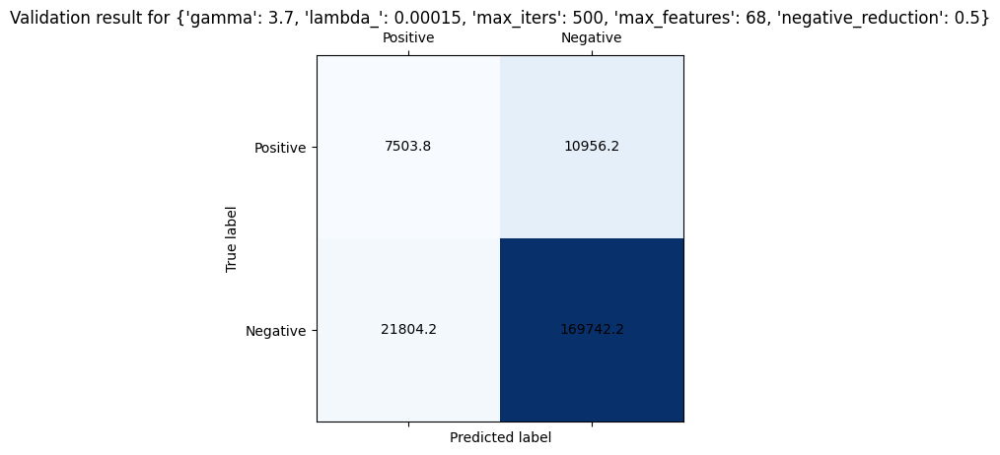

Tuning with args (7/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.17447243788853595


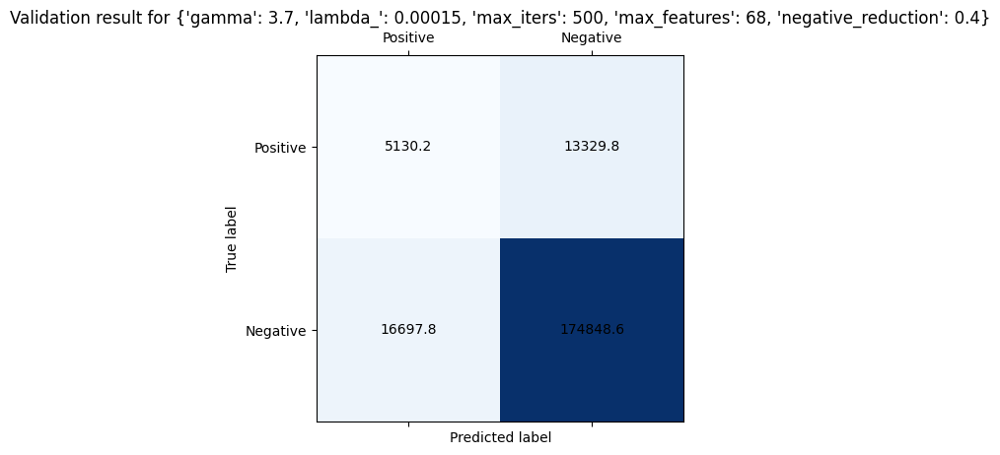

Tuning with args (8/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.20189505444462125


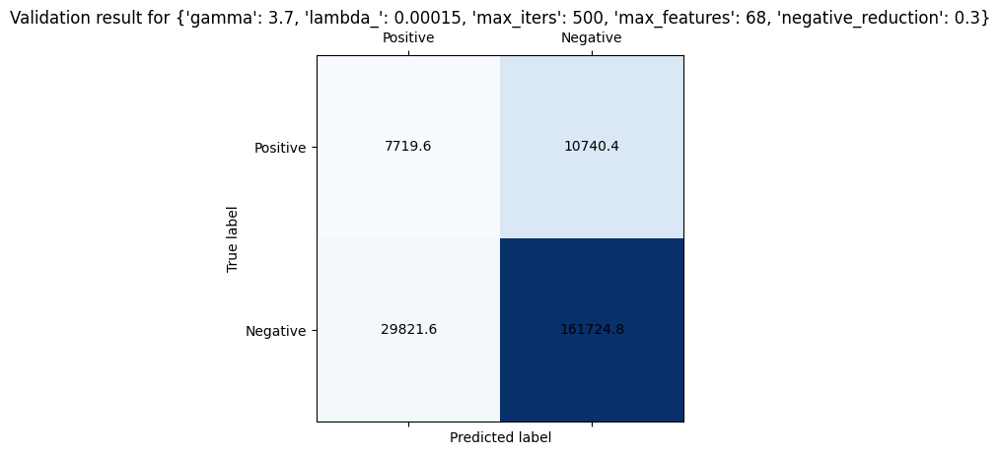

Tuning with args (9/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.04257676040488386


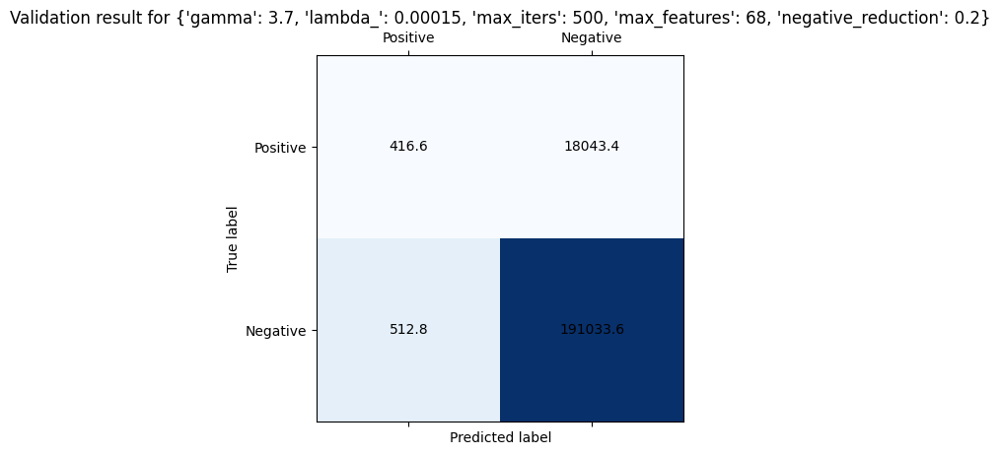

Tuning with args (10/10): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.2594813078141339


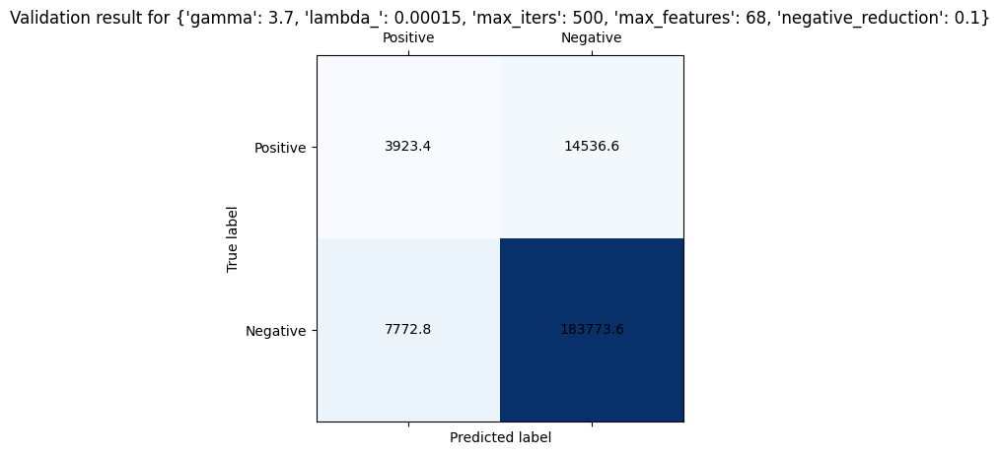

In [32]:
validation_f1_logreg_2 = tune_f1(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_f1_1
)

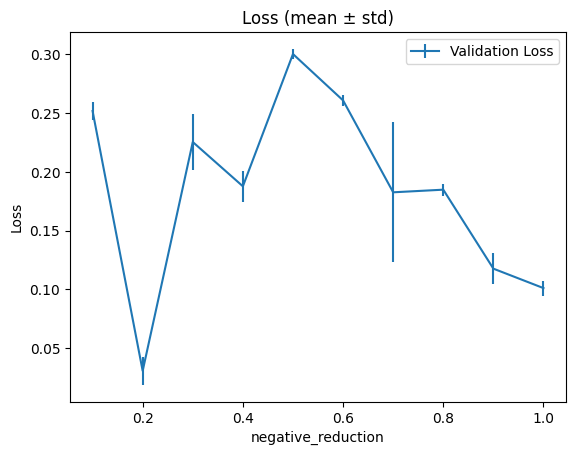


Averaged results:
negative_reduction=0.1 | val=0.2516±0.0079
negative_reduction=0.2 | val=0.0308±0.0118
negative_reduction=0.3 | val=0.2253±0.0234
negative_reduction=0.4 | val=0.1876±0.0132
negative_reduction=0.5 | val=0.3001±0.0045
negative_reduction=0.6 | val=0.2606±0.0045
negative_reduction=0.7 | val=0.1825±0.0595
negative_reduction=0.8 | val=0.1848±0.0050
negative_reduction=0.9 | val=0.1176±0.0132
negative_reduction=1 | val=0.1011±0.0064


In [33]:
all_args_logreg_f1 = args_logreg_f1_1 + args_logreg_f1_1
all_validation_logreg_f1 = validation_f1_logreg_1 + validation_f1_logreg_2

show_printing_result_f1(
    all_args_logreg_f1,
    all_validation_logreg_f1,
    "negative_reduction",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False
)

Tuning with args (1/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.0968300242139806


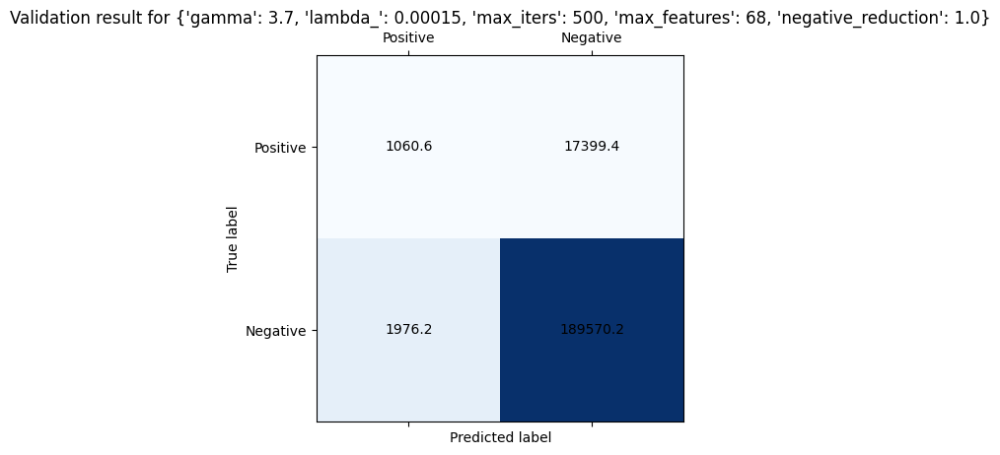

Tuning with args (2/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.0967266064406744


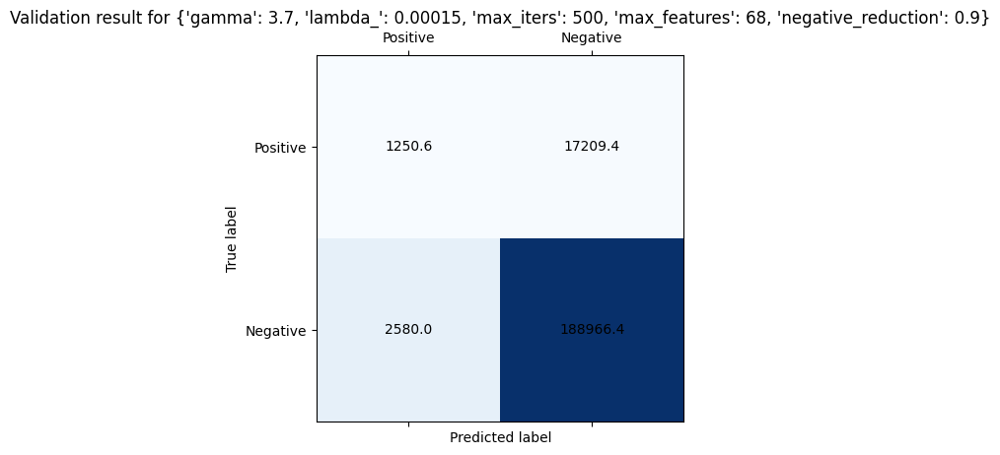

Tuning with args (3/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.22586751515463482


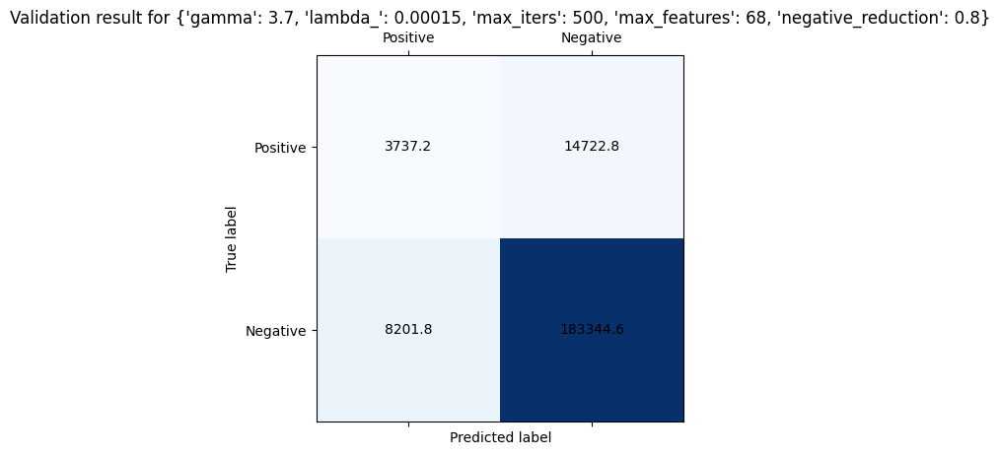

Tuning with args (4/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.18803642107768667


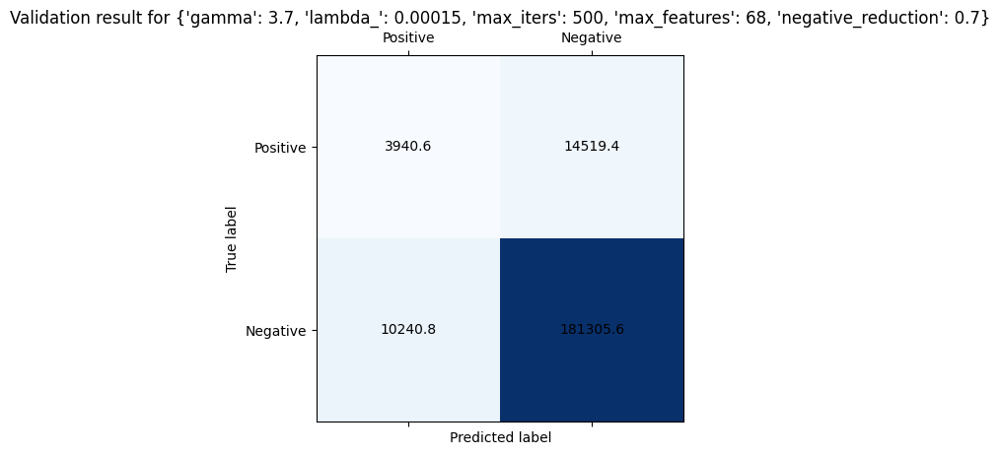

Tuning with args (5/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.19056995910770796


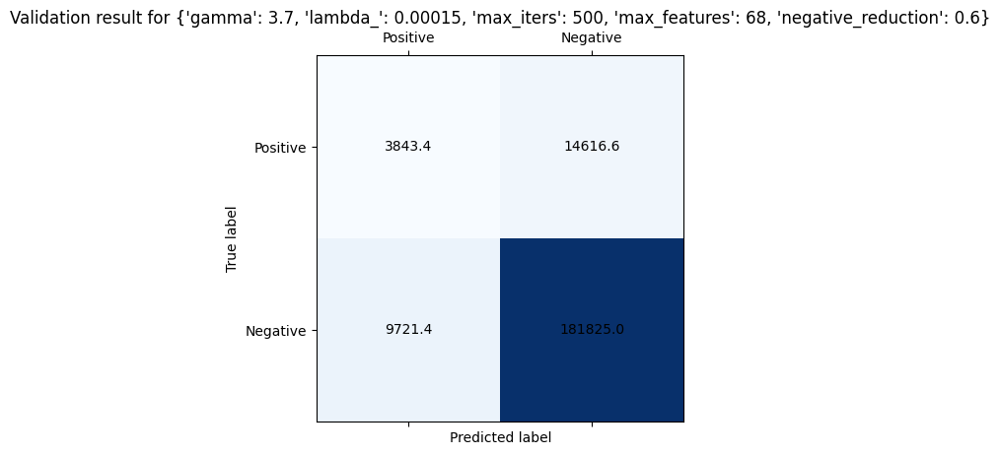

Tuning with args (6/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.26547698429780475


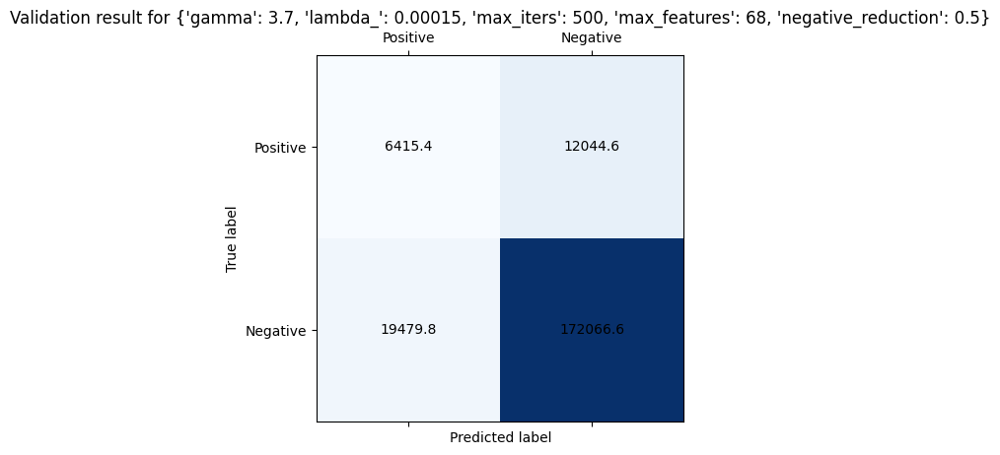

Tuning with args (7/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.24391071390481178


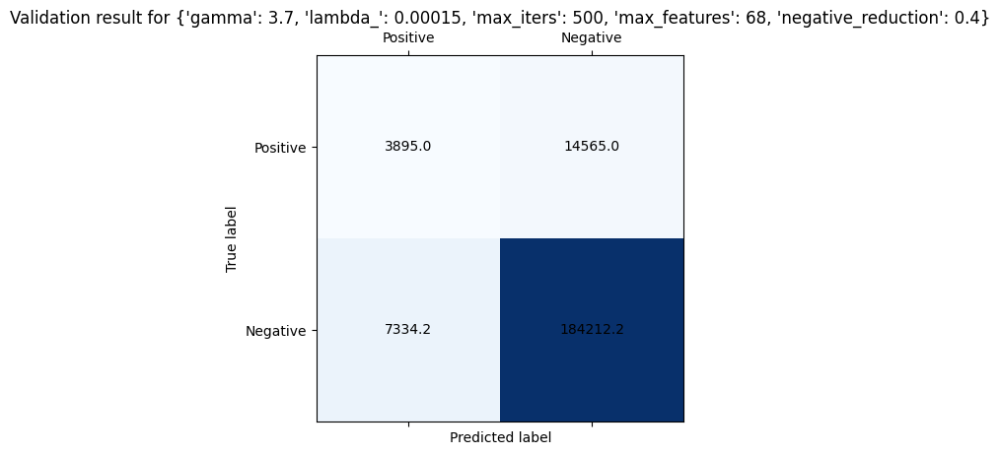

Tuning with args (8/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.2725882679789529


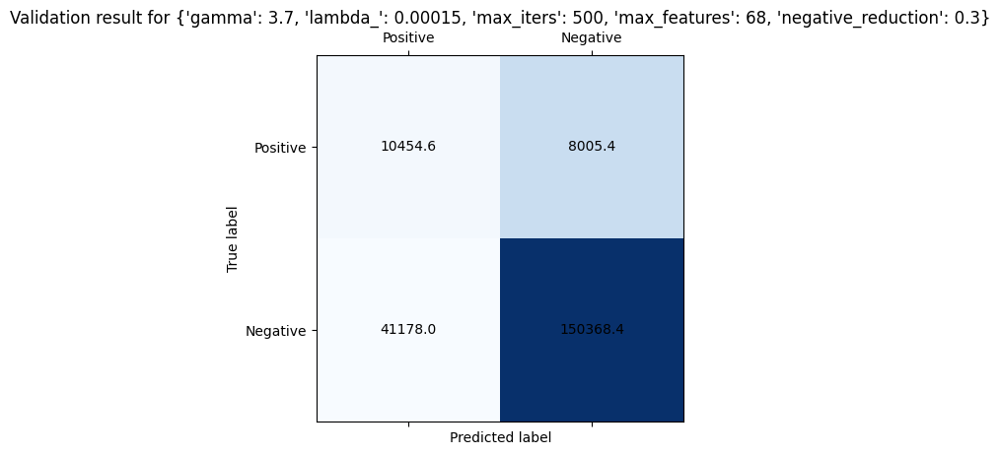

Tuning with args (9/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.03782951277090683


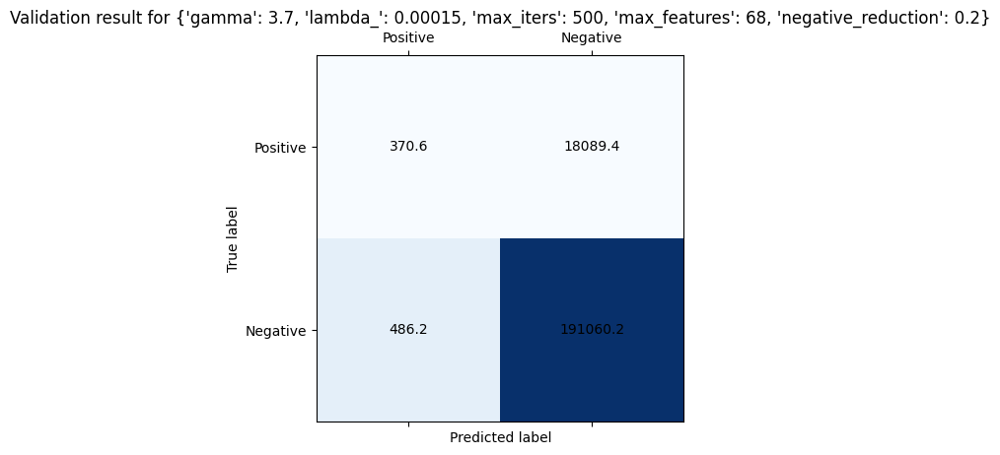

Tuning with args (10/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.25403331556155334


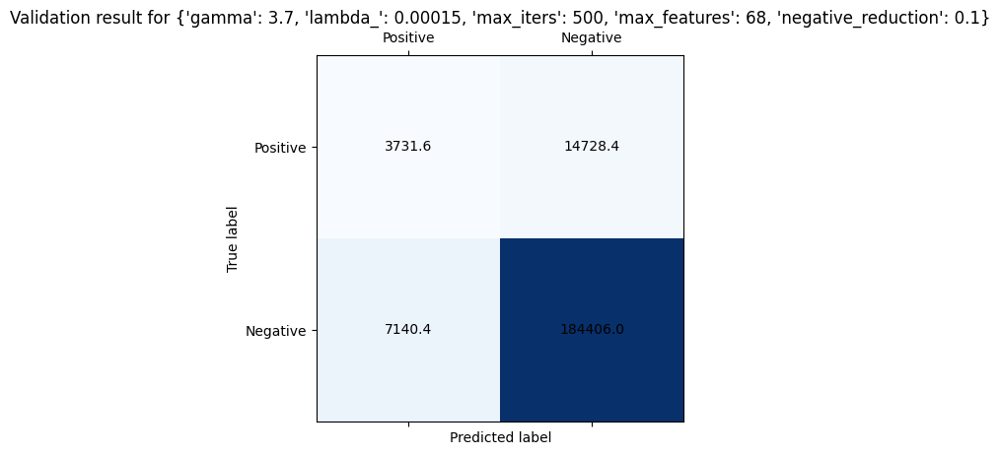

Tuning with args (11/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.07686232567586129


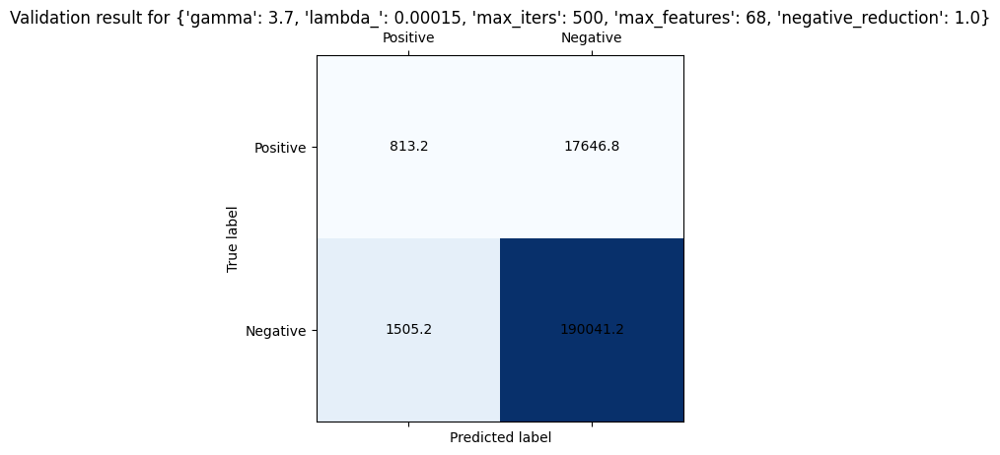

Tuning with args (12/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.035108801410792555


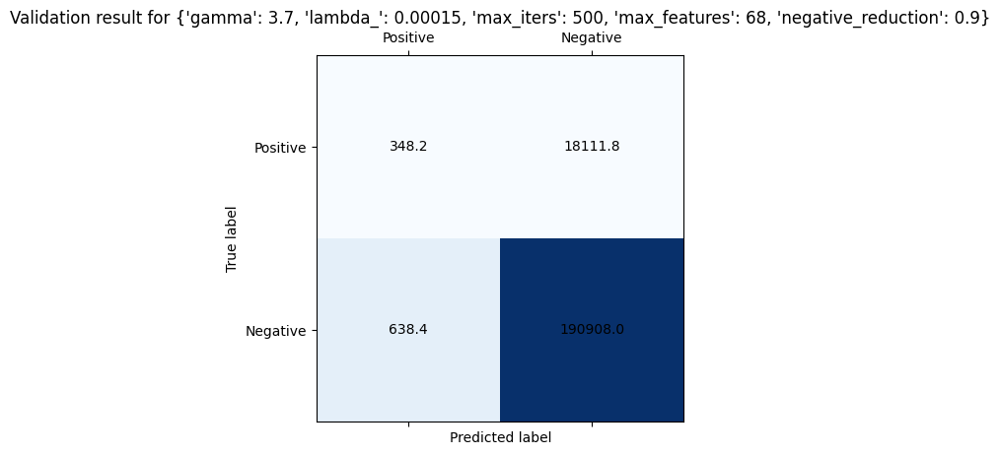

Tuning with args (13/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.26992514318167604


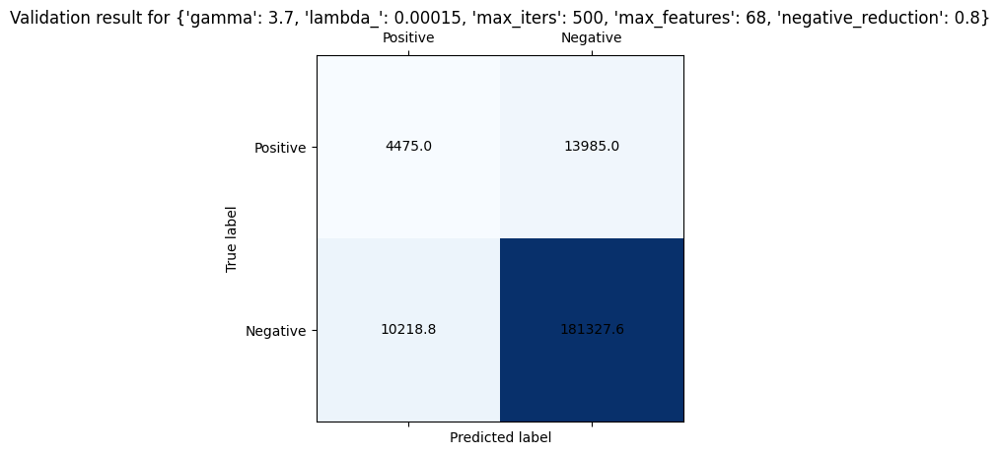

Tuning with args (14/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.259774756030657


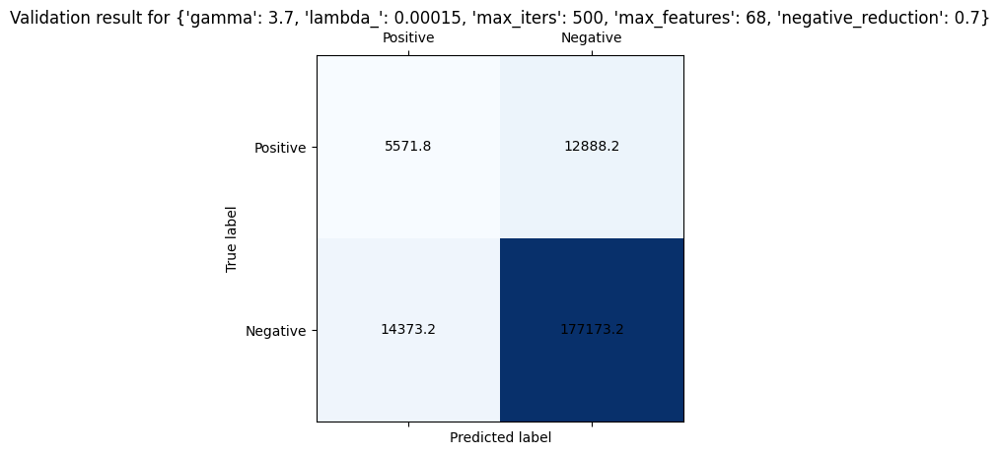

Tuning with args (15/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.2603226942102529


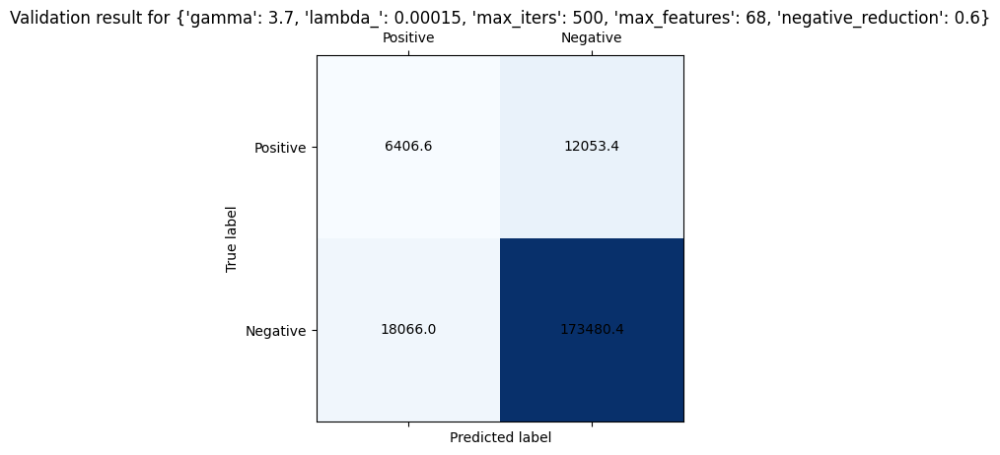

Tuning with args (16/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.2656206857524153


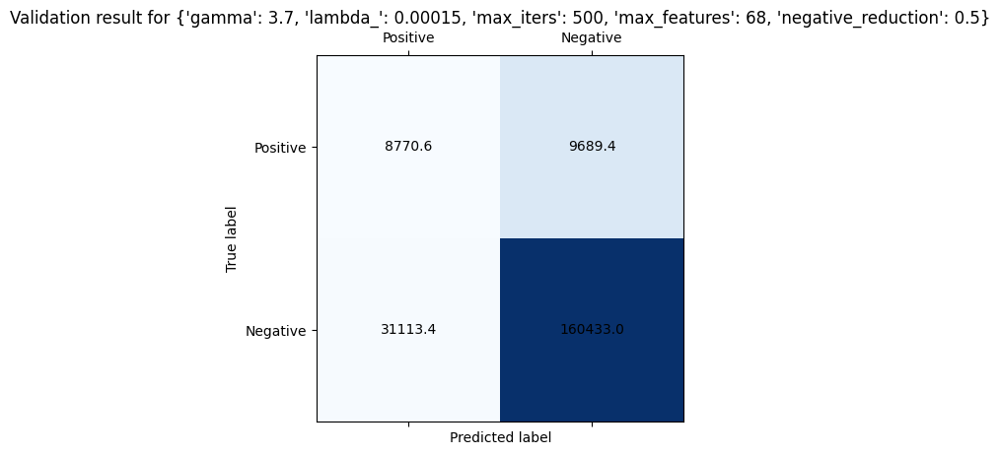

Tuning with args (17/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.20173224127904993


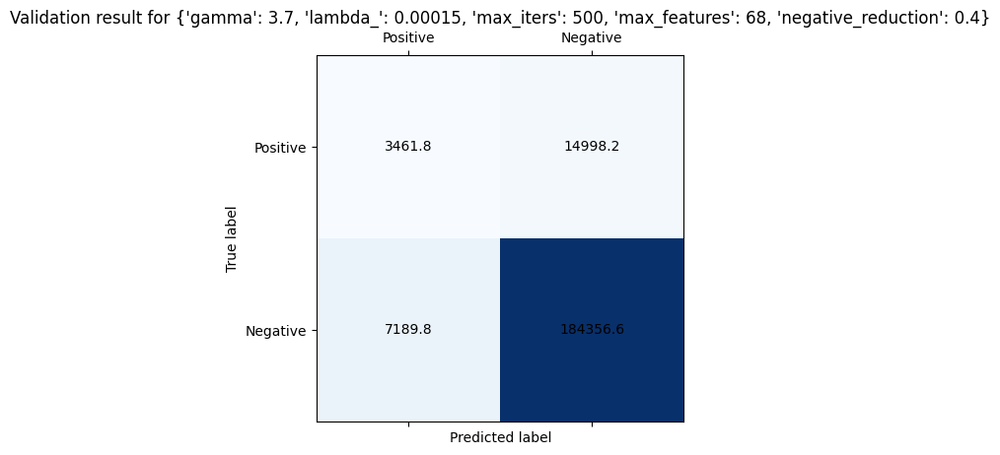

Tuning with args (18/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.21305349047987238


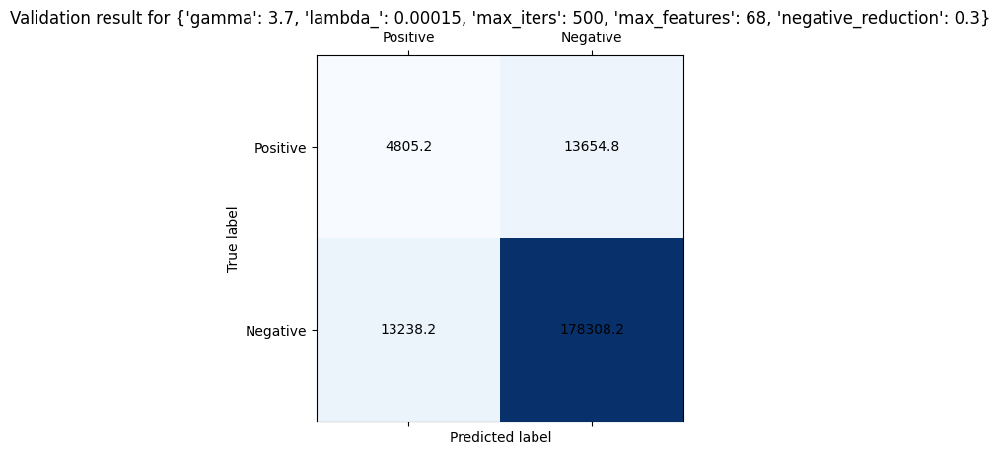

Tuning with args (19/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.03908957776773025


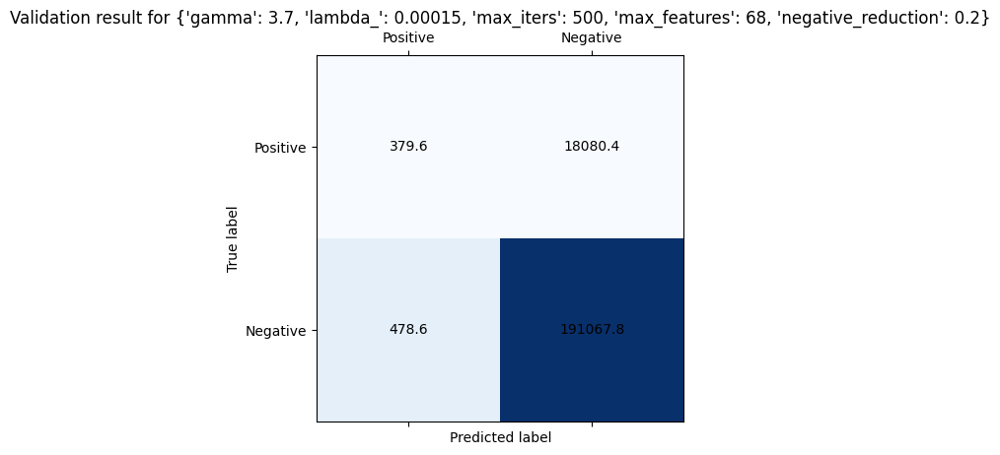

Tuning with args (20/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.2634654420755852


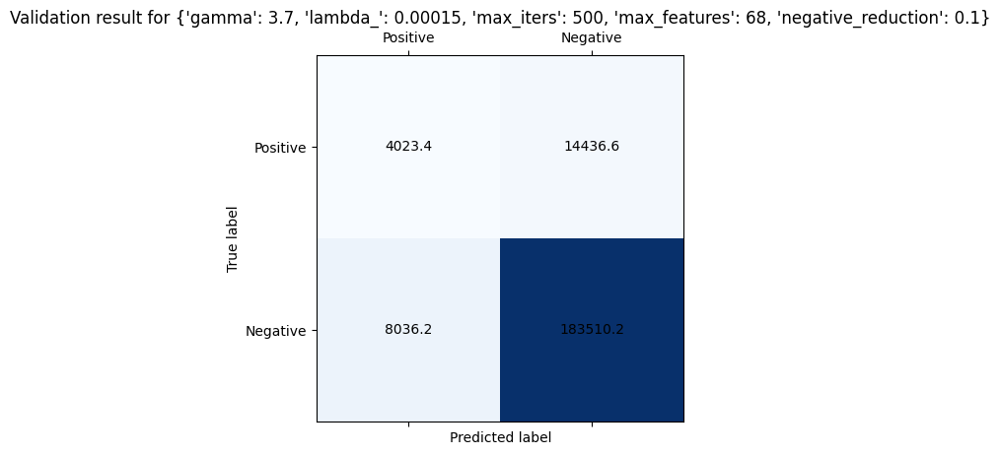

Tuning with args (21/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.07331427094024615


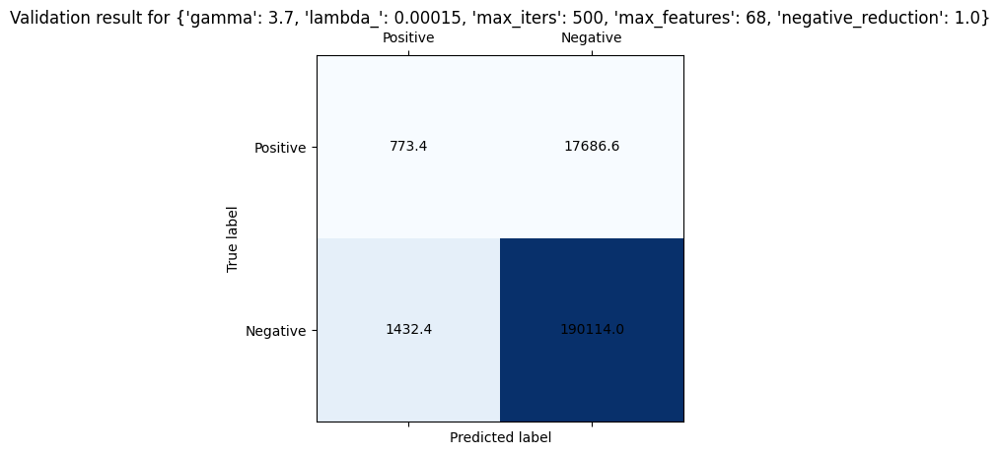

Tuning with args (22/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.0908073170924967


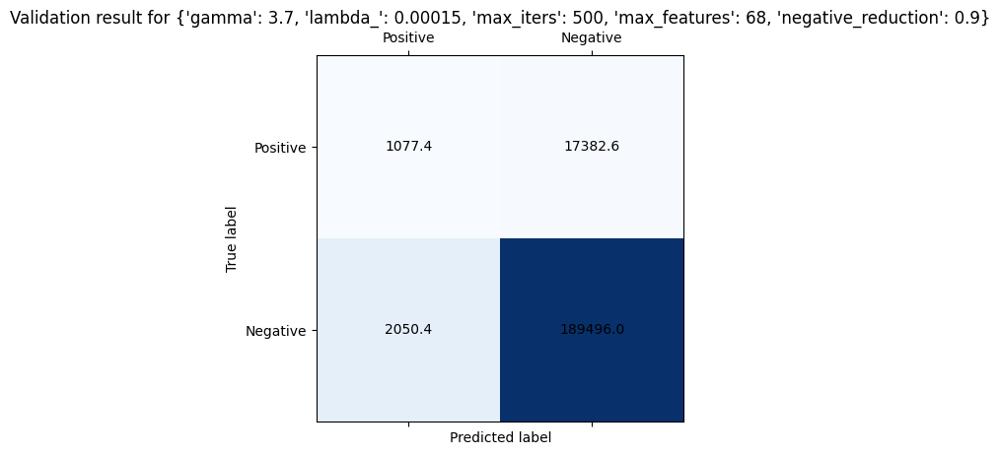

Tuning with args (23/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.2750743273056934


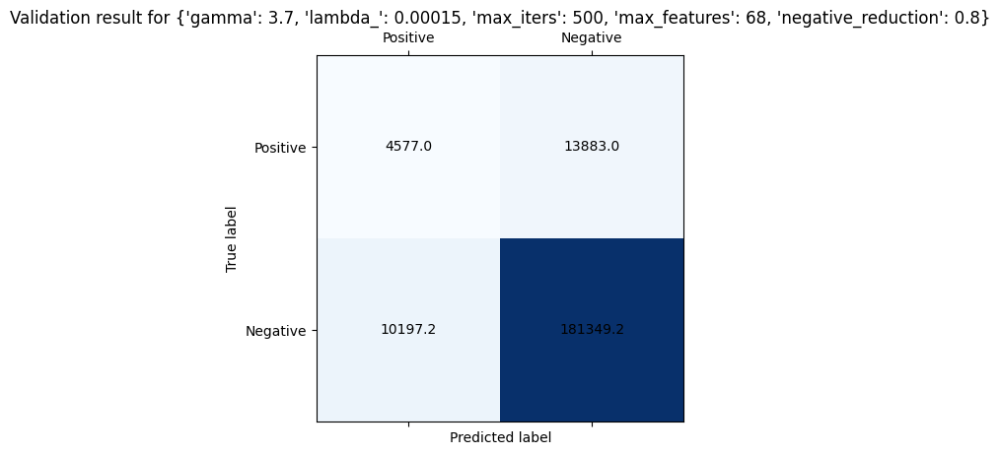

Tuning with args (24/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.19057086743518062


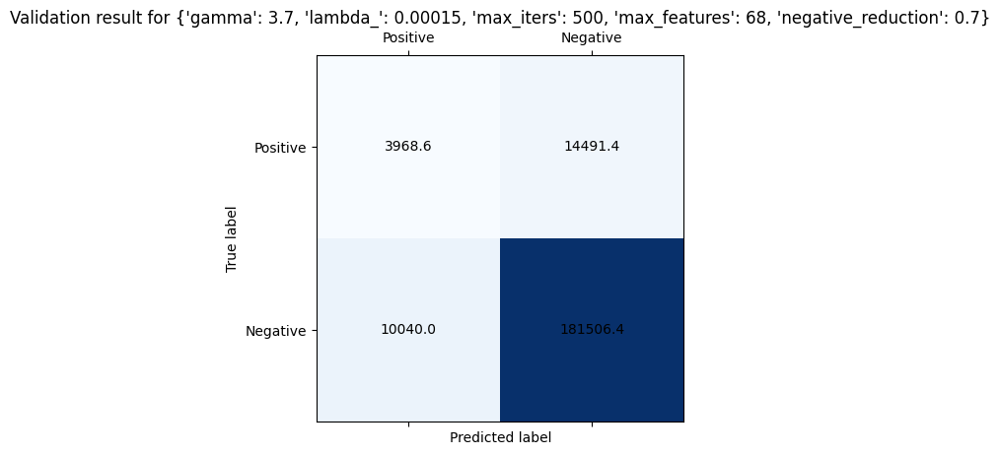

Tuning with args (25/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.3180576855747829


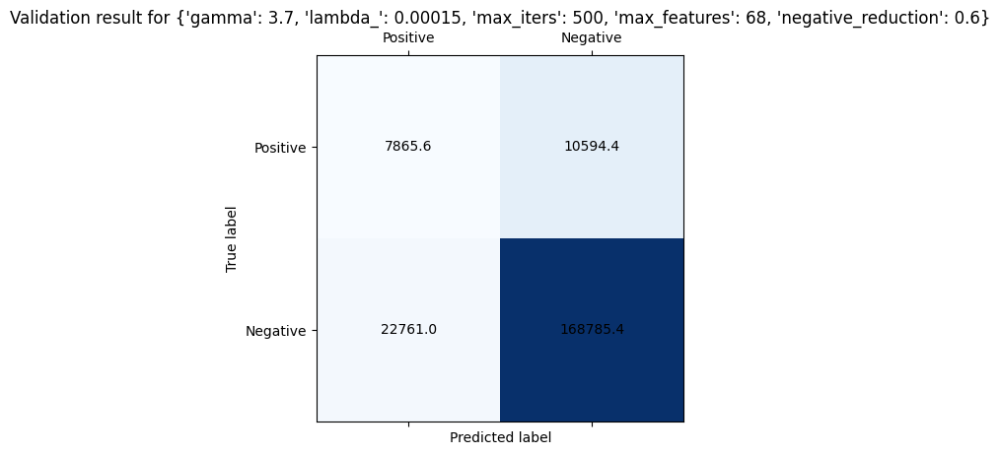

Tuning with args (26/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.18054941181389933


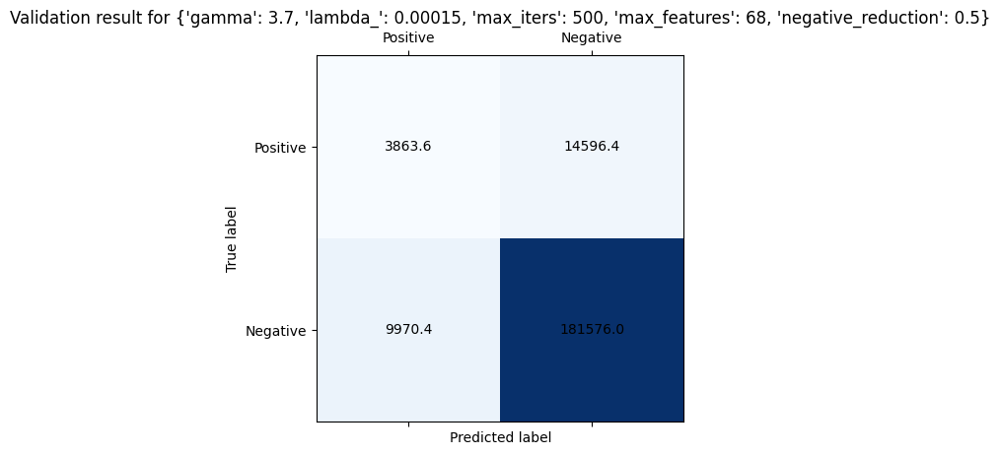

Tuning with args (27/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.25228227432554334


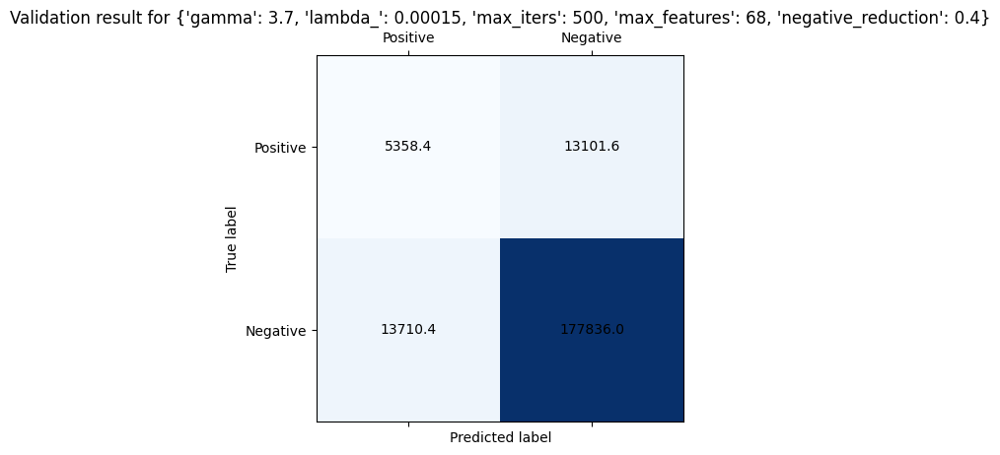

Tuning with args (28/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.21468708933353856


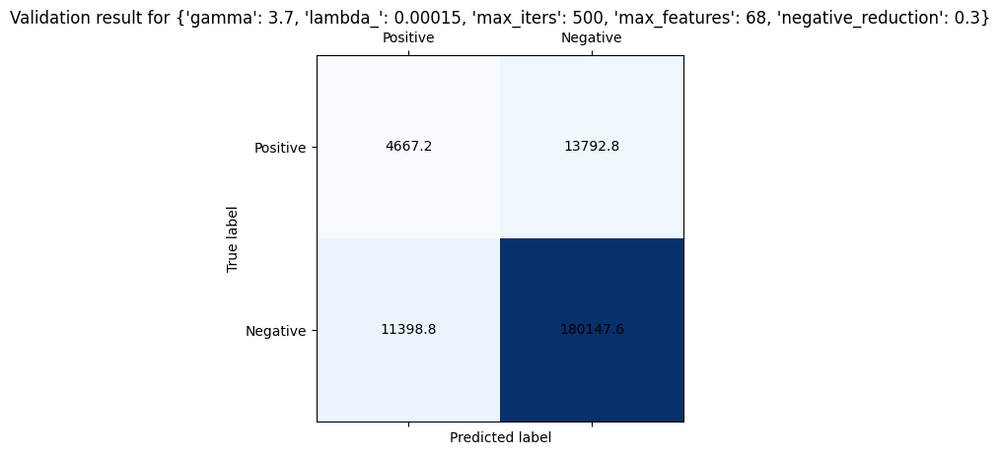

Tuning with args (29/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.0736918602558139


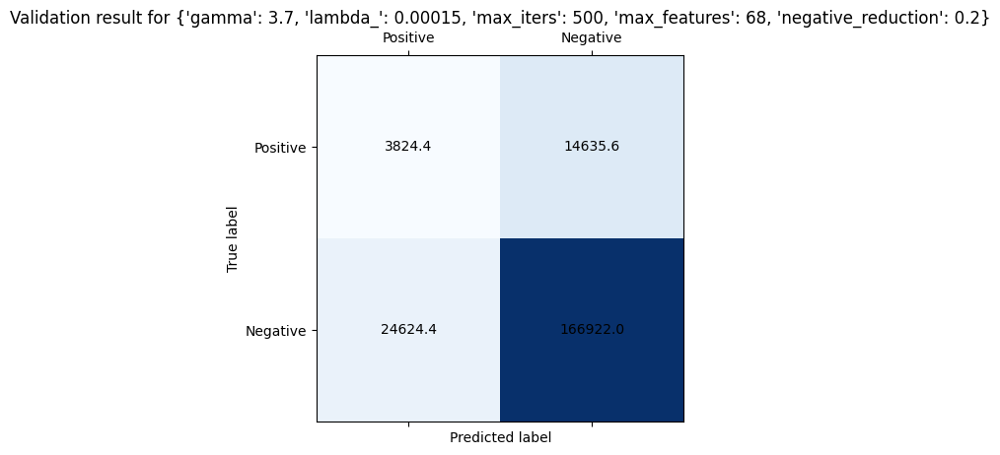

Tuning with args (30/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.24085339404246678


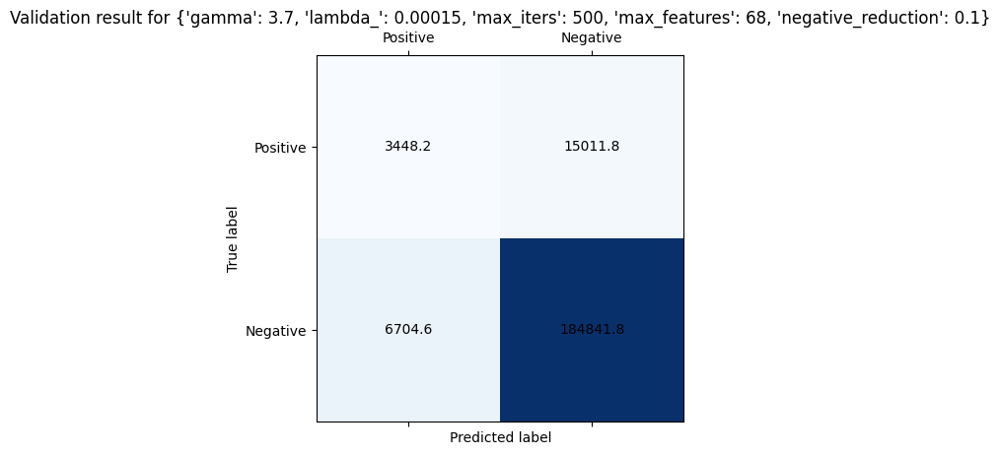

Tuning with args (31/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.08507480375412894


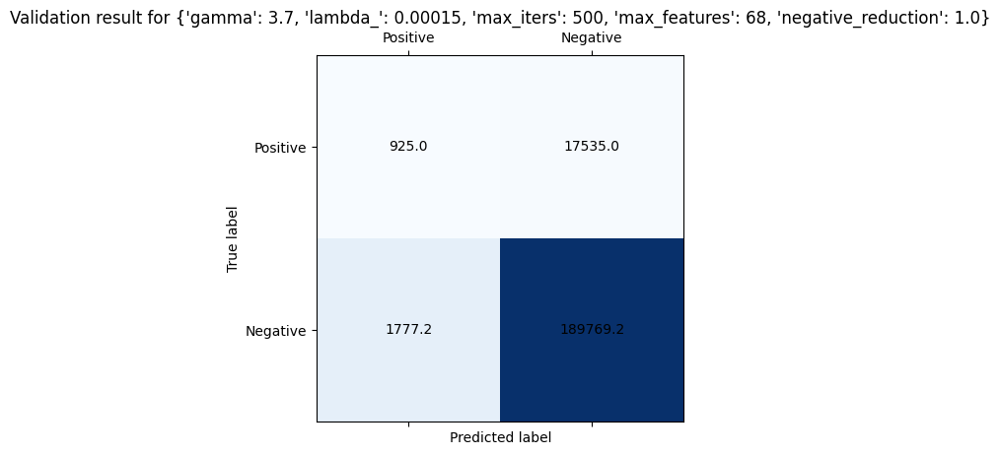

Tuning with args (32/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.1308898579553855


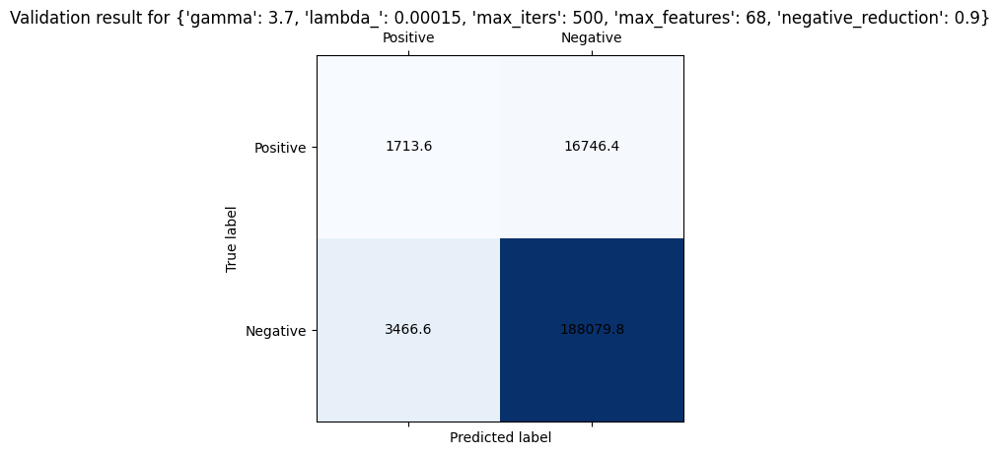

Tuning with args (33/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.27401314115121495


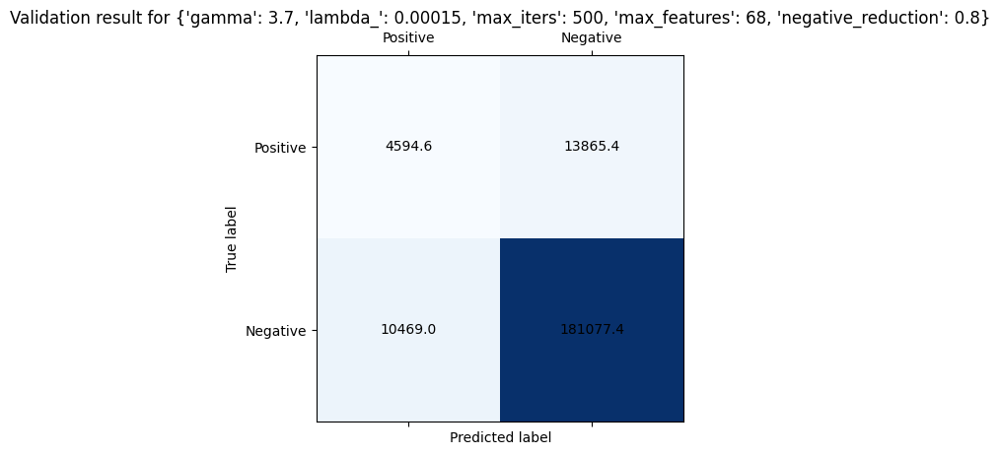

Tuning with args (34/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.25081274016849187


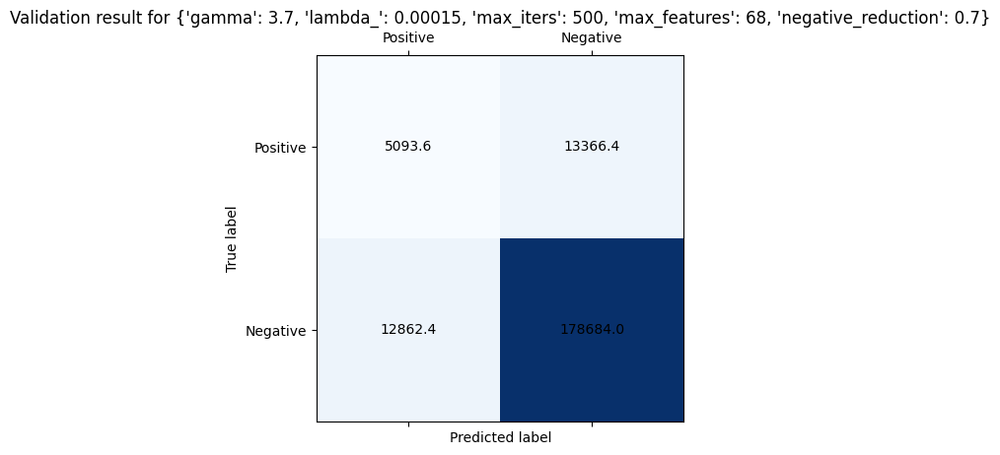

Tuning with args (35/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.265867400346692


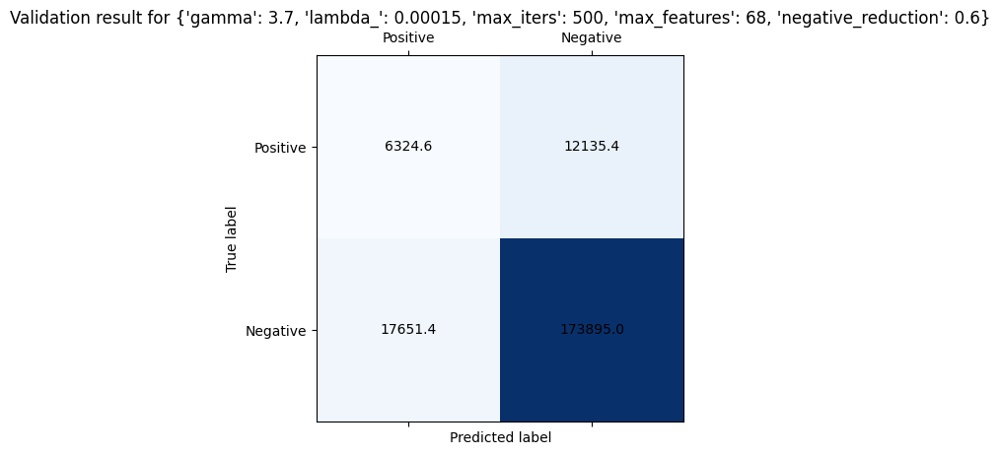

Tuning with args (36/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.25610246031479844


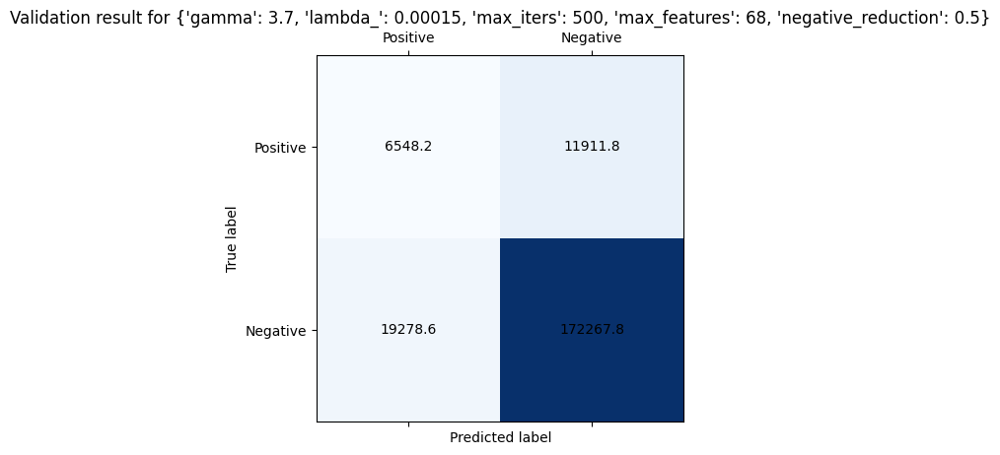

Tuning with args (37/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.19275726366785867


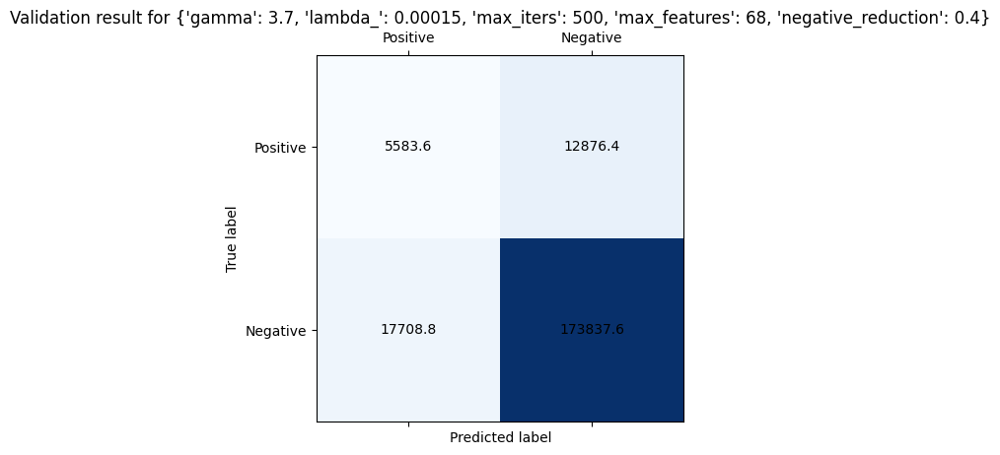

Tuning with args (38/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.08718666718908469


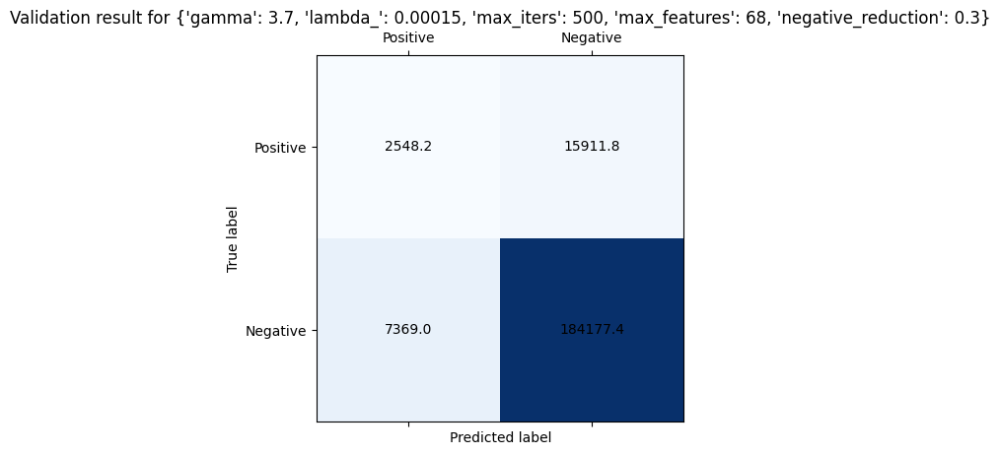

Tuning with args (39/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.02937565642991949


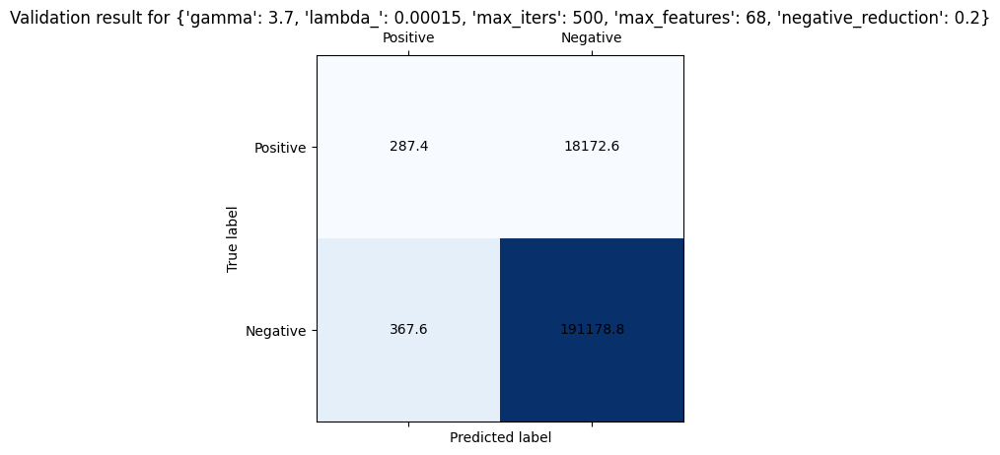

Tuning with args (40/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.24168533099026407


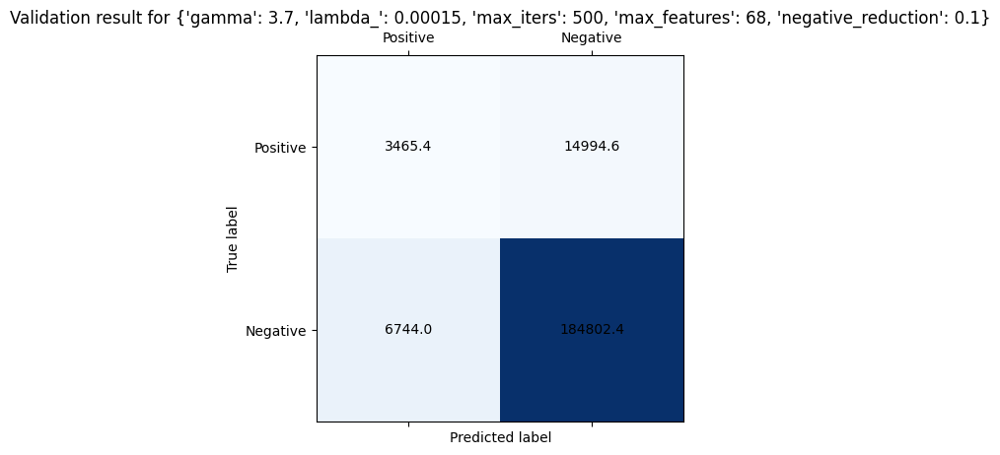

Tuning with args (41/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 1.0}
Average validation cross-validation f1: 0.09278705244297183


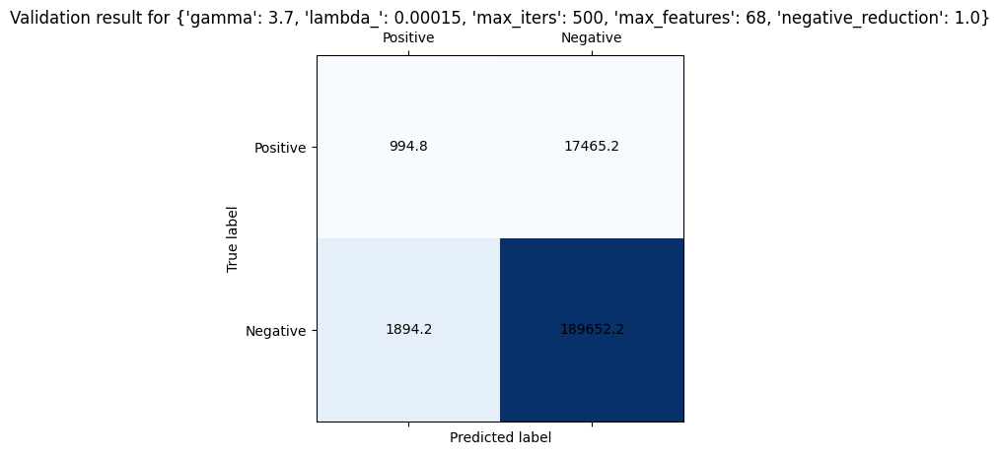

Tuning with args (42/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.9}
Average validation cross-validation f1: 0.06997643449018859


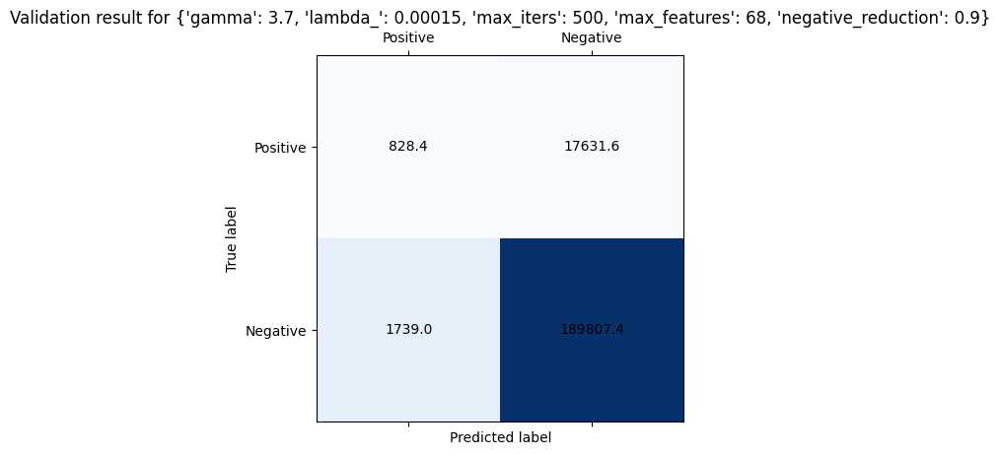

Tuning with args (43/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.8}
Average validation cross-validation f1: 0.18408663215171037


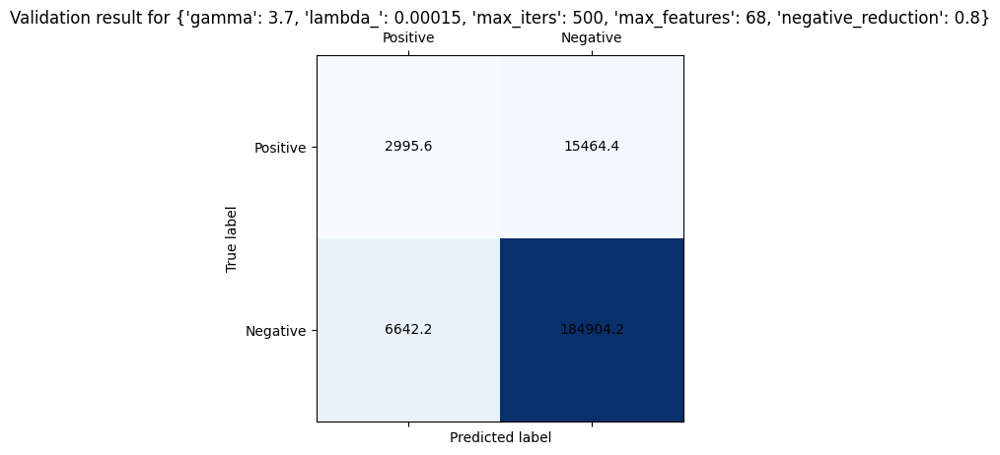

Tuning with args (44/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.7}
Average validation cross-validation f1: 0.006376071610910255


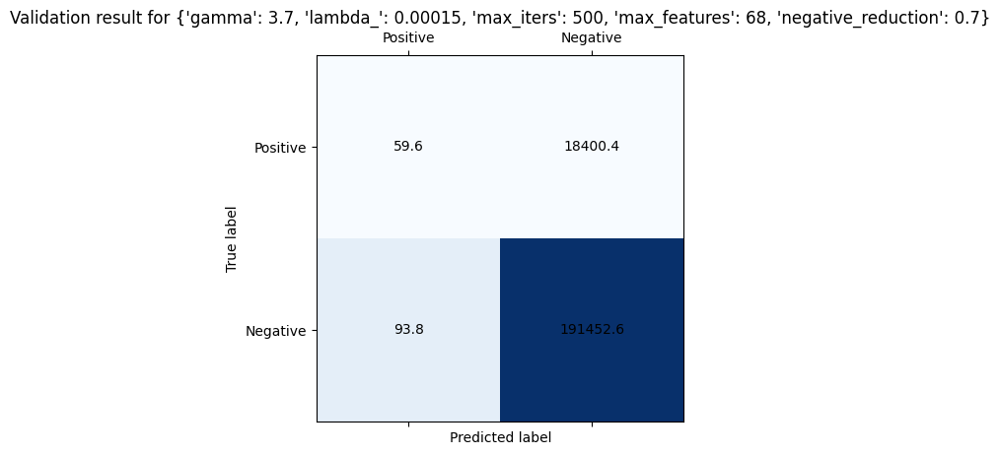

Tuning with args (45/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.6}
Average validation cross-validation f1: 0.3272908034882487


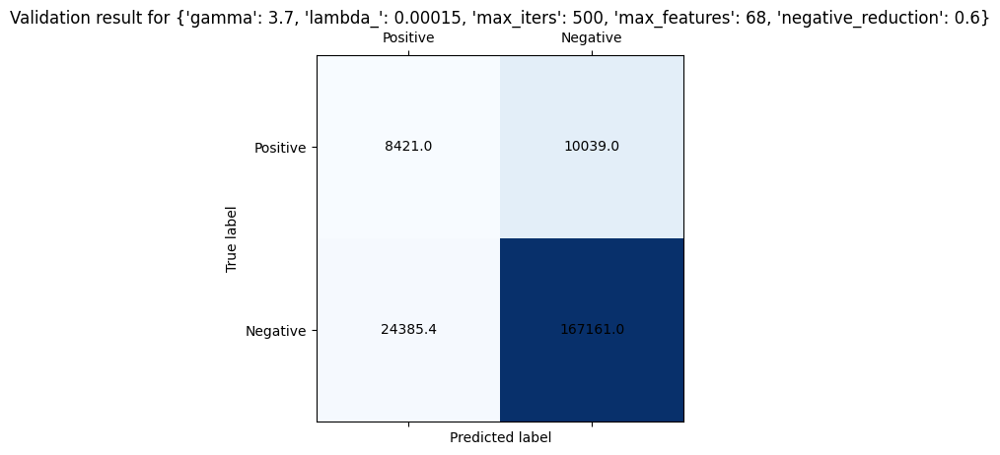

Tuning with args (46/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.5}
Average validation cross-validation f1: 0.1929153745680307


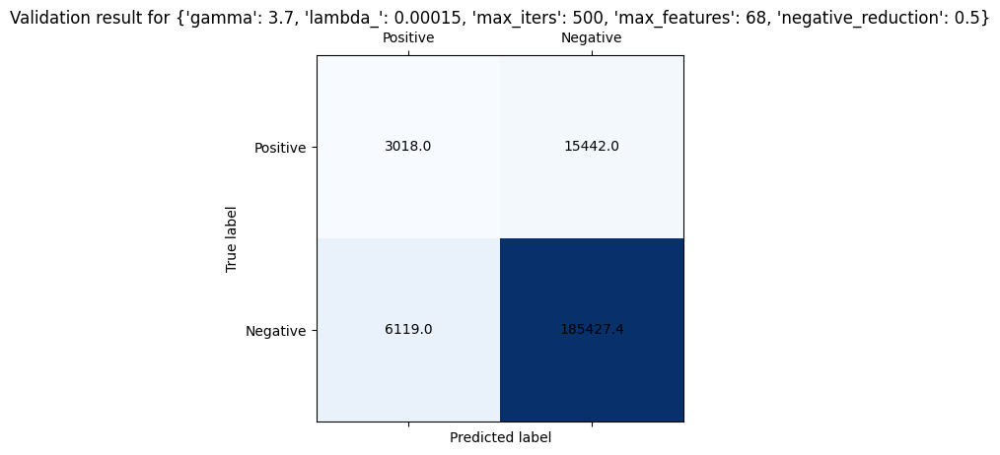

Tuning with args (47/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.4}
Average validation cross-validation f1: 0.2031350391736979


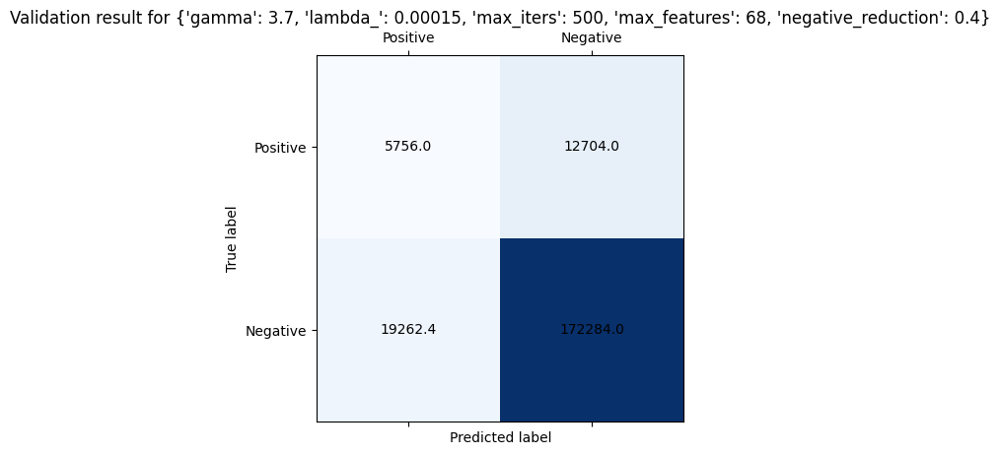

Tuning with args (48/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.3}
Average validation cross-validation f1: 0.19151649172312796


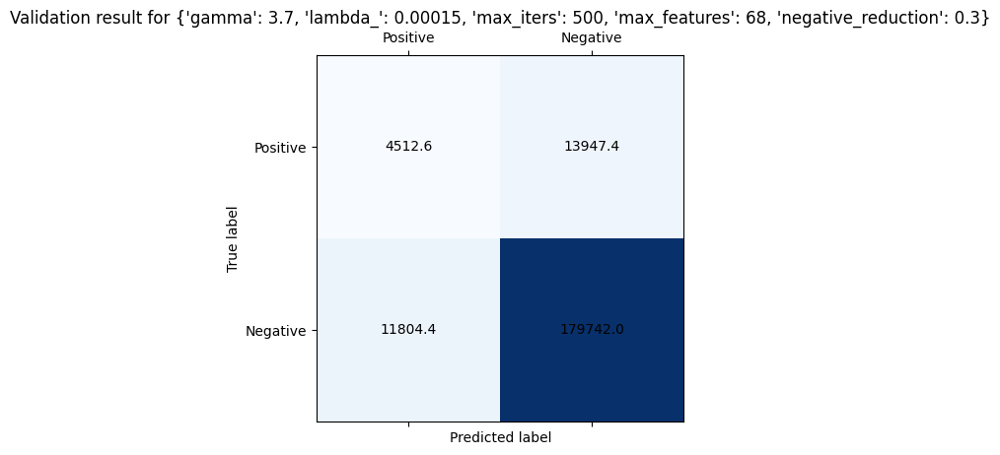

Tuning with args (49/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.2}
Average validation cross-validation f1: 0.0852936213787692


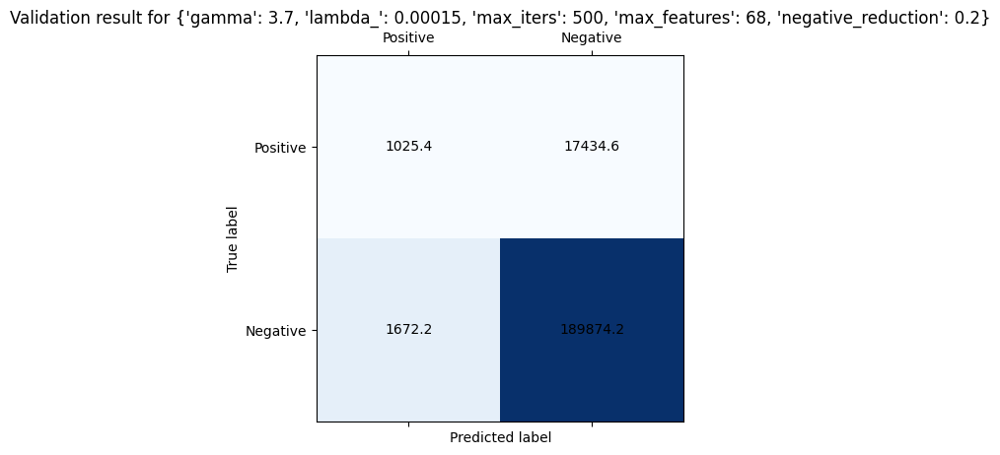

Tuning with args (50/50): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.1}
Average validation cross-validation f1: 0.257376283635662


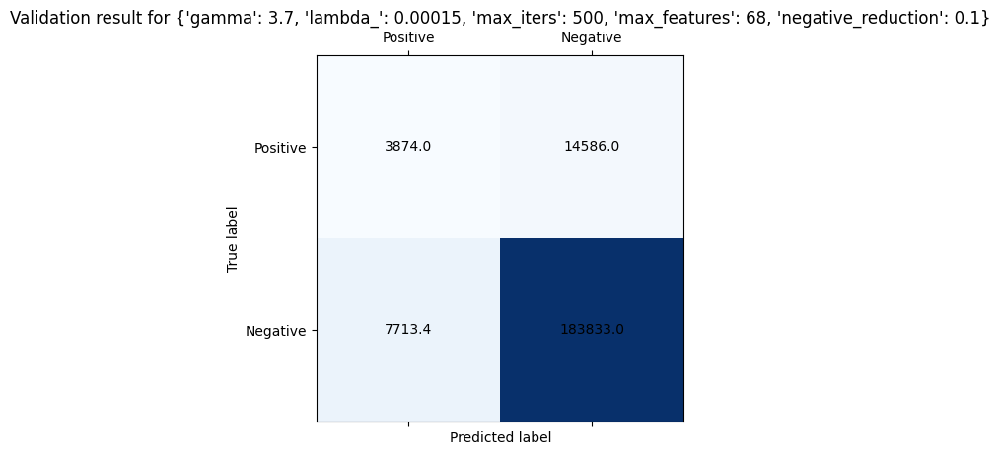

In [34]:
validation_f1_logreg_3 = tune_f1(
    x_train_norm,
    y_train,
    k=5,
    model=RegularizedLogisticRegression,
    args=args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1,
)

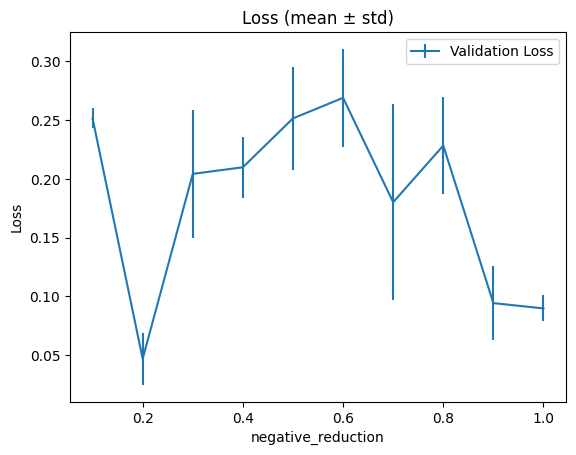


Averaged results:
negative_reduction=0.1 | val=0.2515±0.0086
negative_reduction=0.2 | val=0.0467±0.0222
negative_reduction=0.3 | val=0.2042±0.0544
negative_reduction=0.4 | val=0.2099±0.0259
negative_reduction=0.5 | val=0.2515±0.0441
negative_reduction=0.6 | val=0.2691±0.0418
negative_reduction=0.7 | val=0.1801±0.0835
negative_reduction=0.8 | val=0.2284±0.0411
negative_reduction=0.9 | val=0.0941±0.0314
negative_reduction=1 | val=0.0896±0.0111


In [35]:
all_args_logreg_f1 = (
    args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
)
all_validation_logreg_f1 = (
    validation_f1_logreg_1 + validation_f1_logreg_2 + validation_f1_logreg_3
)

show_printing_result_f1(
    all_args_logreg_f1,
    all_validation_logreg_f1,
    "negative_reduction",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False
)

Tuning with args (1/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.3092276987103369


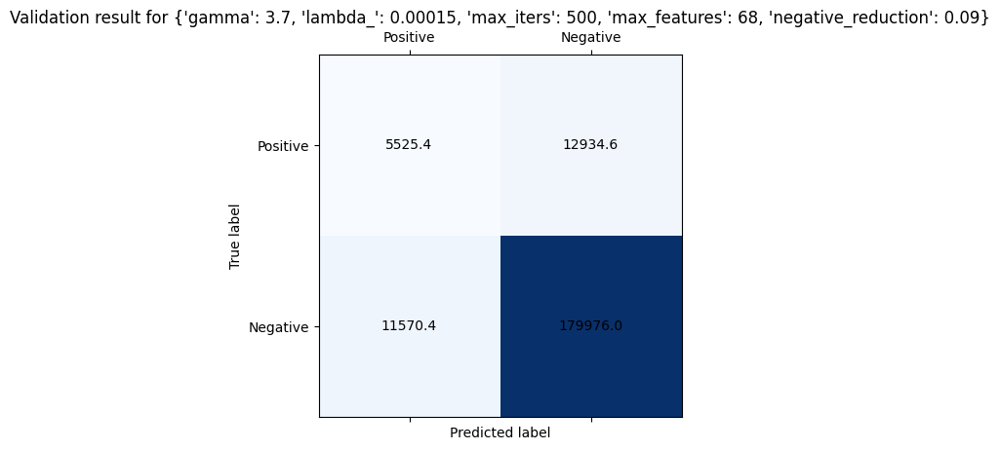

Tuning with args (2/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.3229196071805194


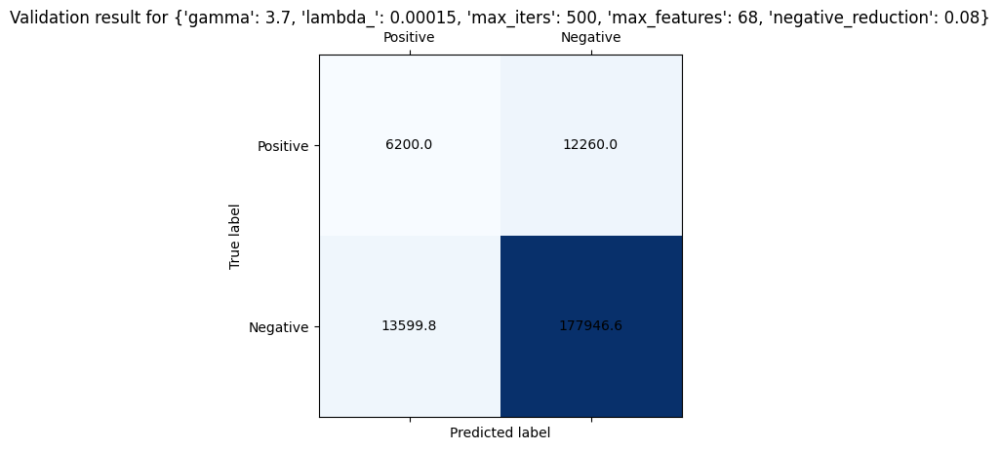

Tuning with args (3/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.3247141727936048


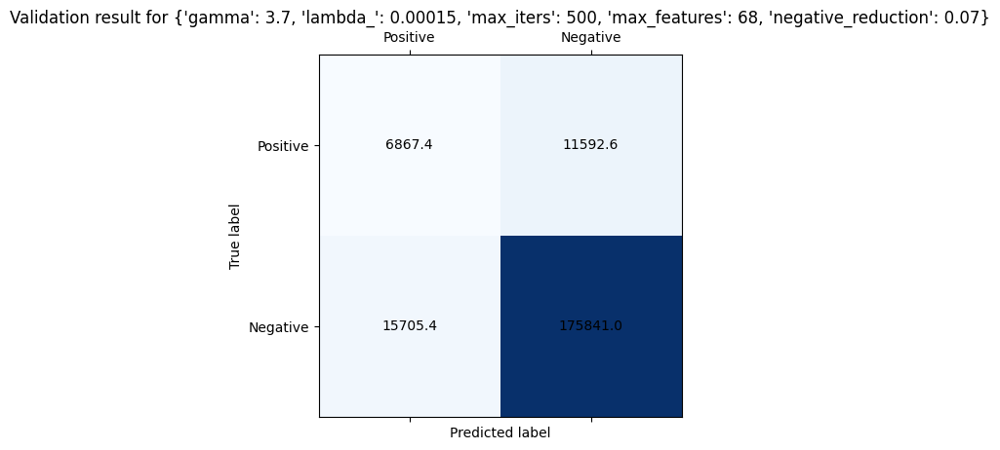

Tuning with args (4/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.32791439955214186


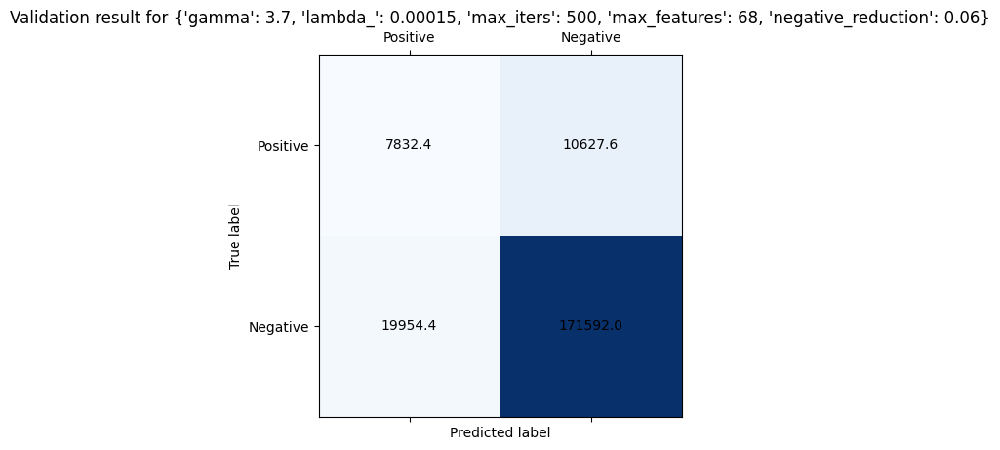

Tuning with args (5/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.3244206987337679


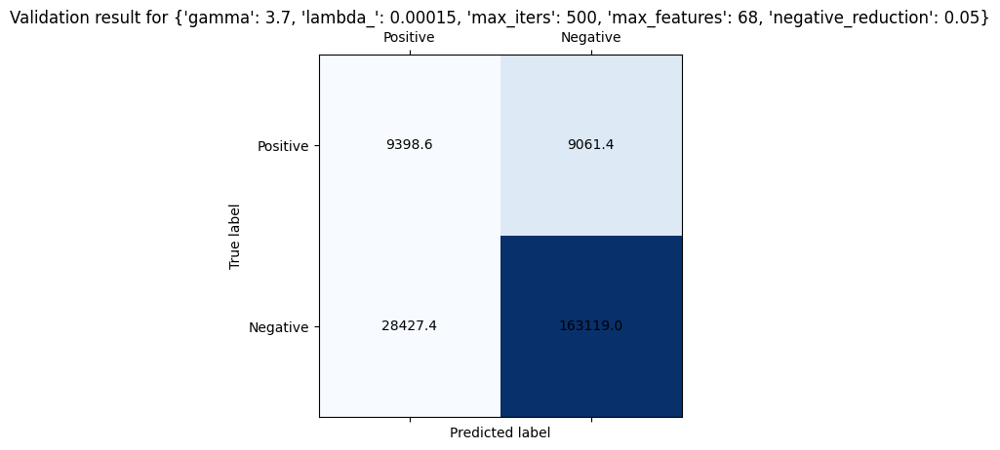

Tuning with args (6/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.31959680980233396


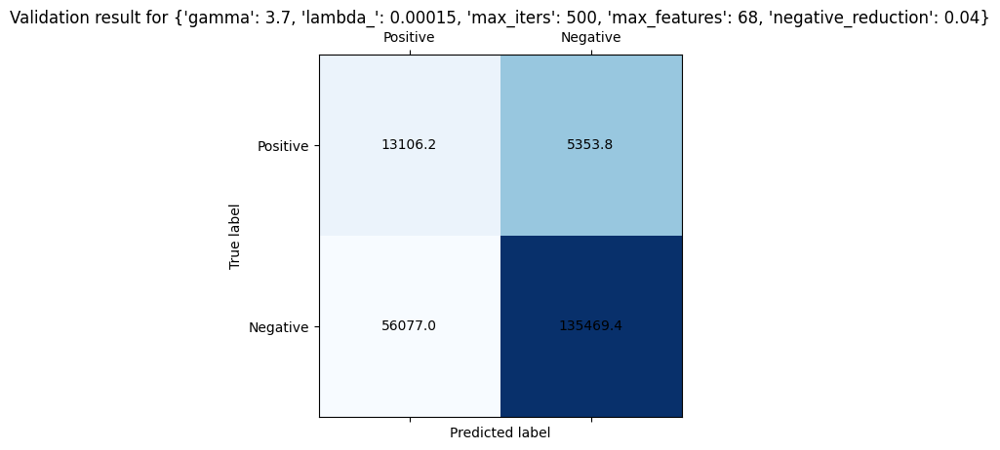

Tuning with args (7/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.3041707727699008


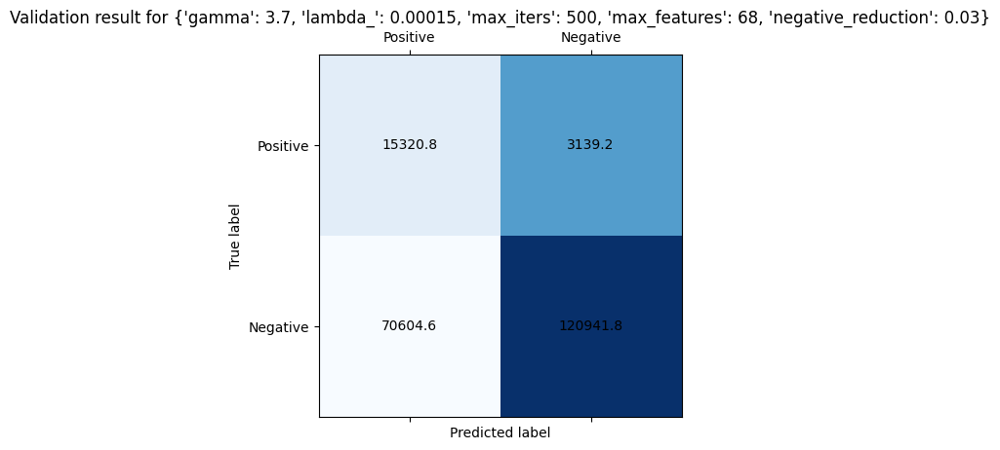

Tuning with args (8/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.2863196221367823


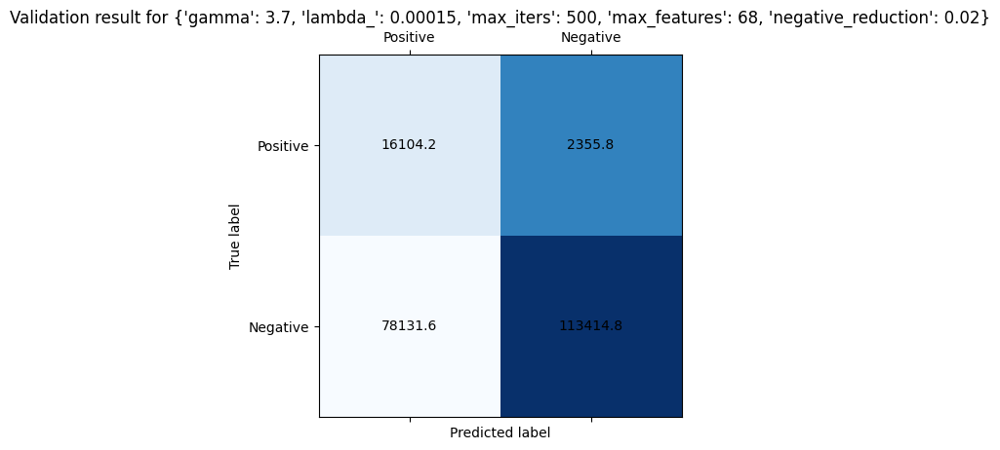

Tuning with args (9/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.16721591127274177


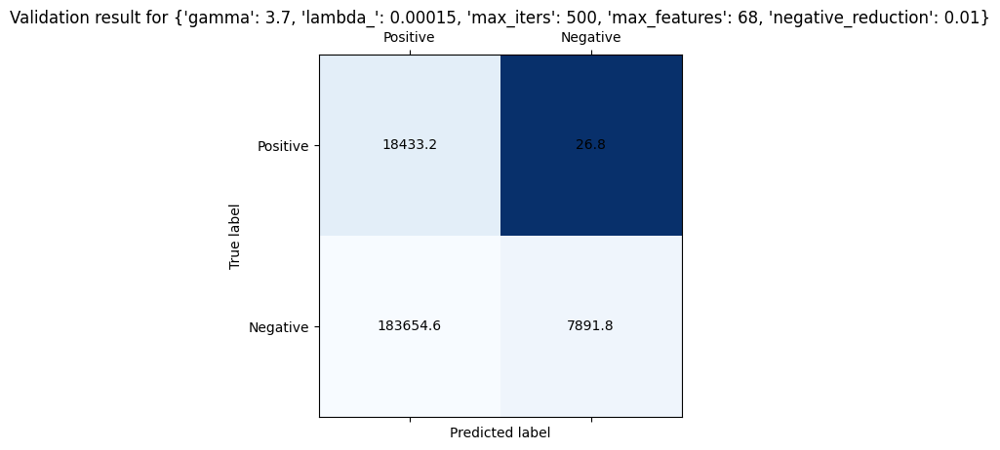

Tuning with args (10/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.28636117923224236


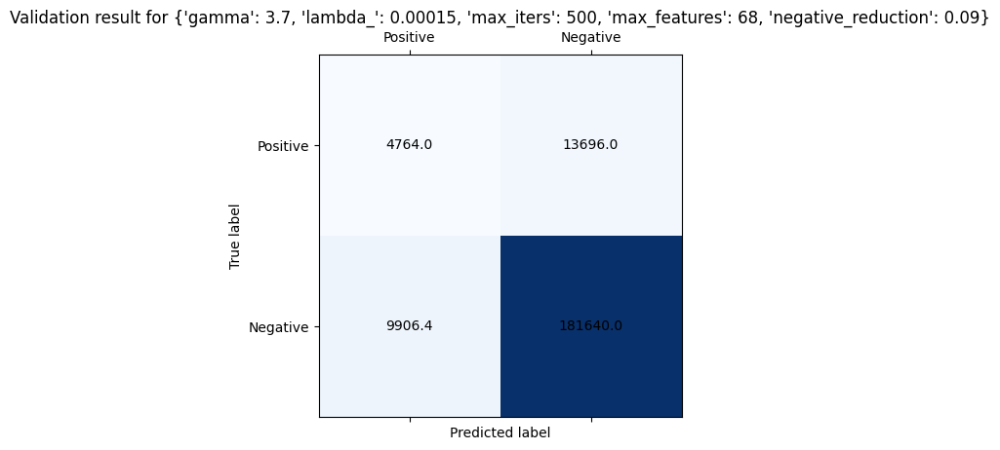

Tuning with args (11/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.323974549549061


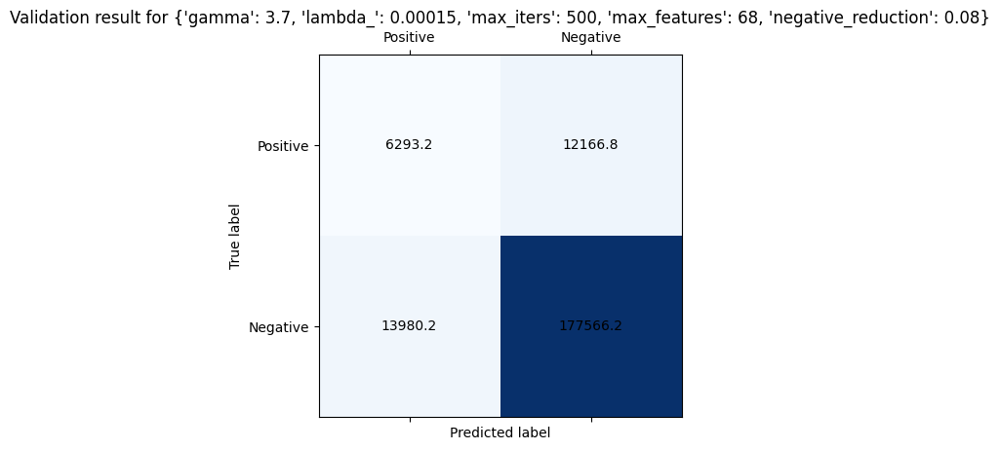

Tuning with args (12/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.3426384567994295


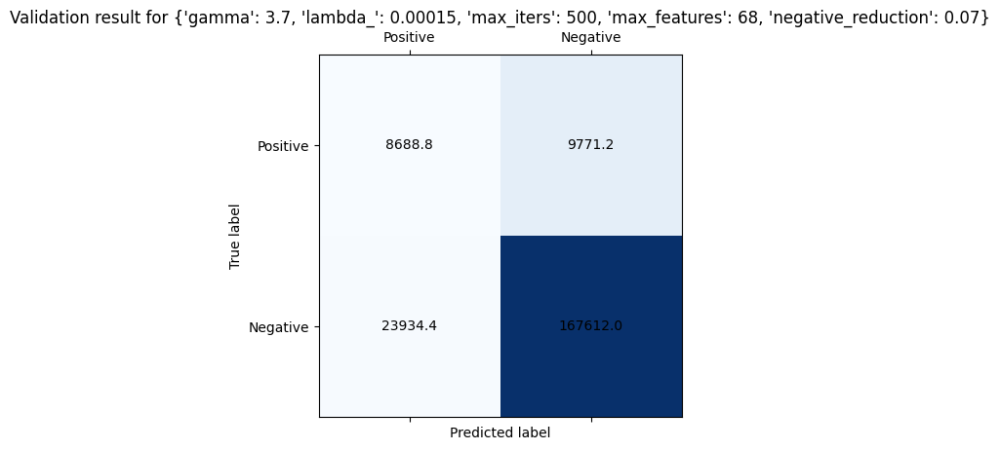

Tuning with args (13/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.358333433433047


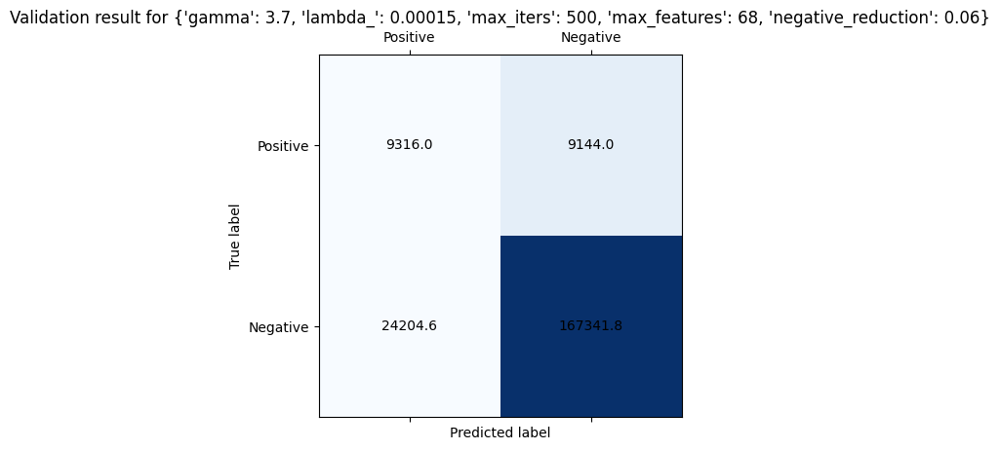

Tuning with args (14/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.3526219403111307


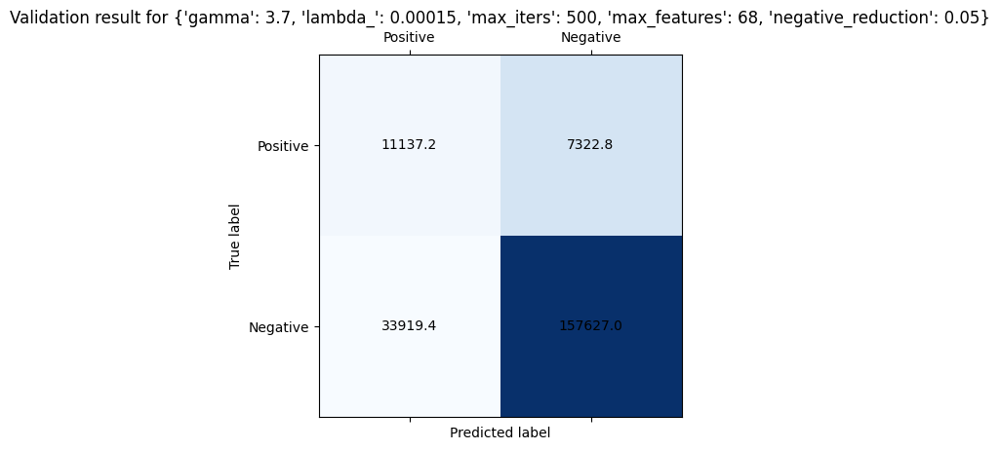

Tuning with args (15/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.35900644678798754


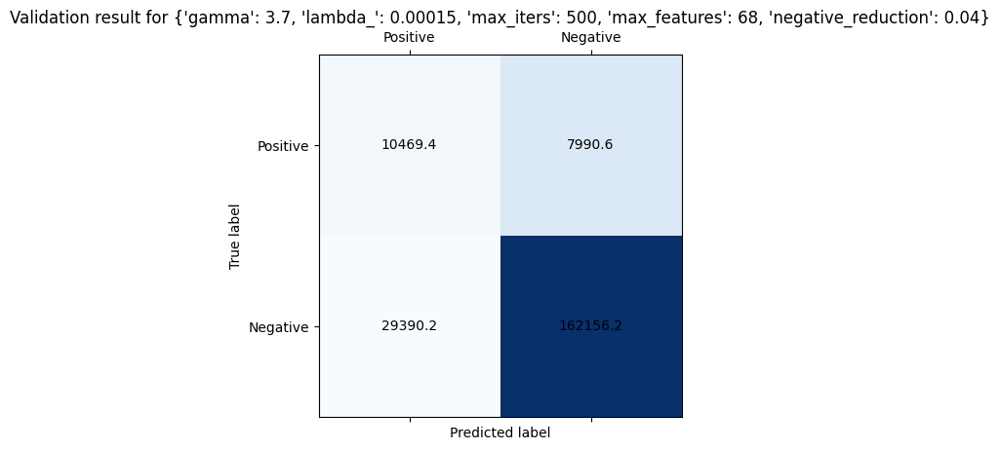

Tuning with args (16/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.32973713863559684


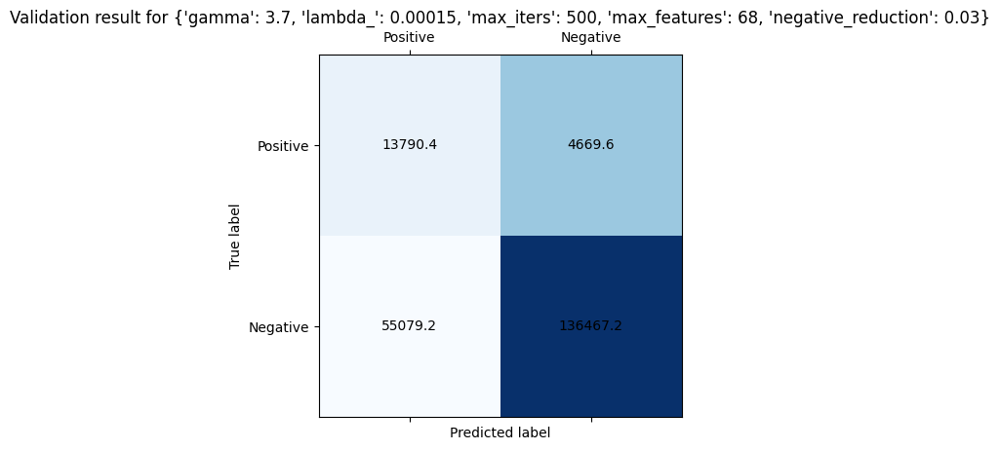

Tuning with args (17/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.25404149064367554


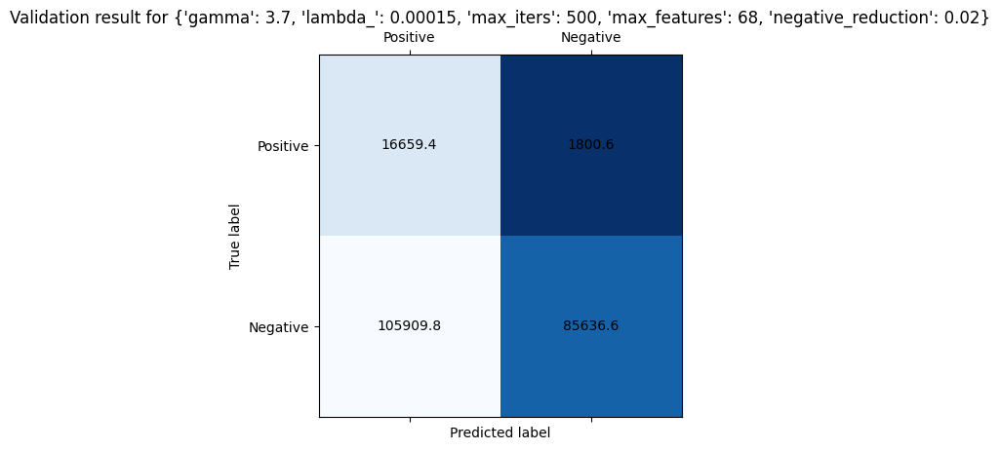

Tuning with args (18/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.1679000144413115


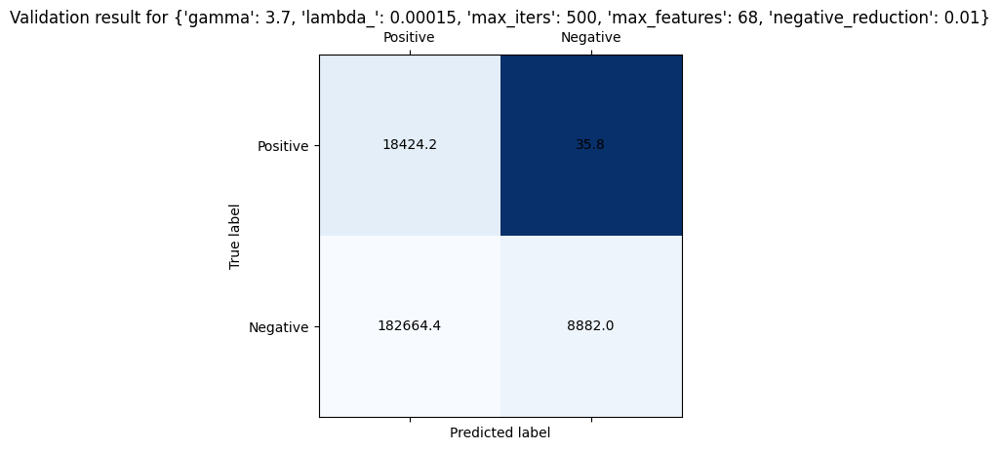

Tuning with args (19/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.28015213855218923


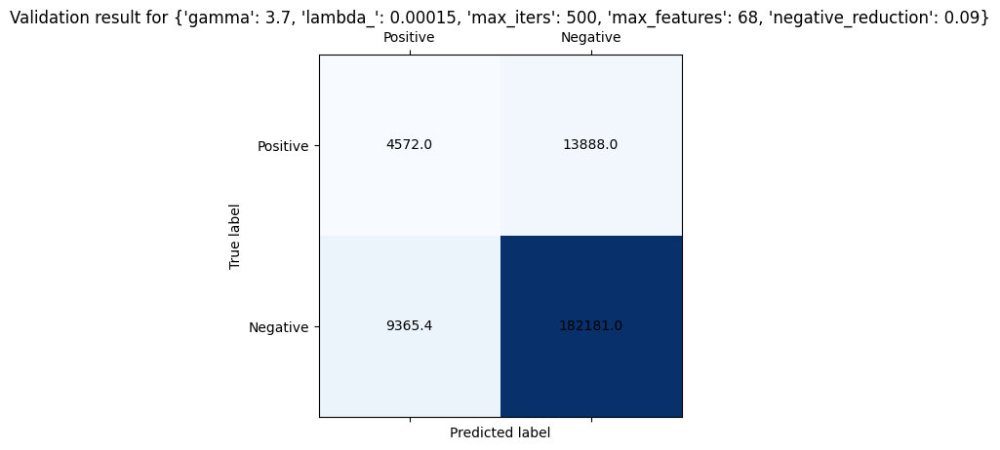

Tuning with args (20/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.3135840828062326


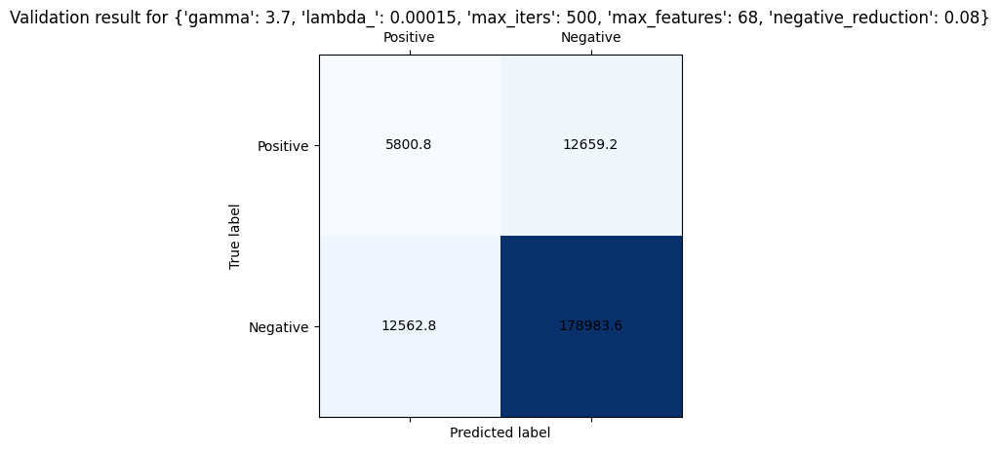

Tuning with args (21/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.31098927680031985


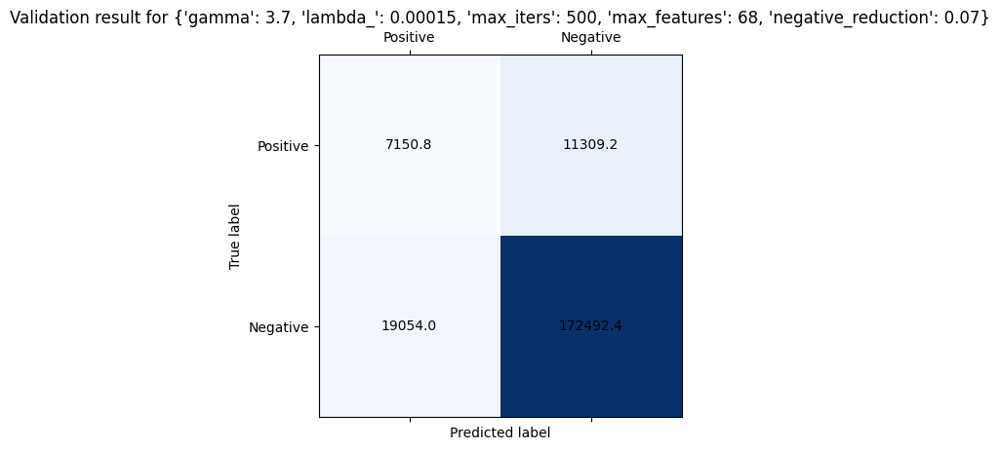

Tuning with args (22/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.3583929601412195


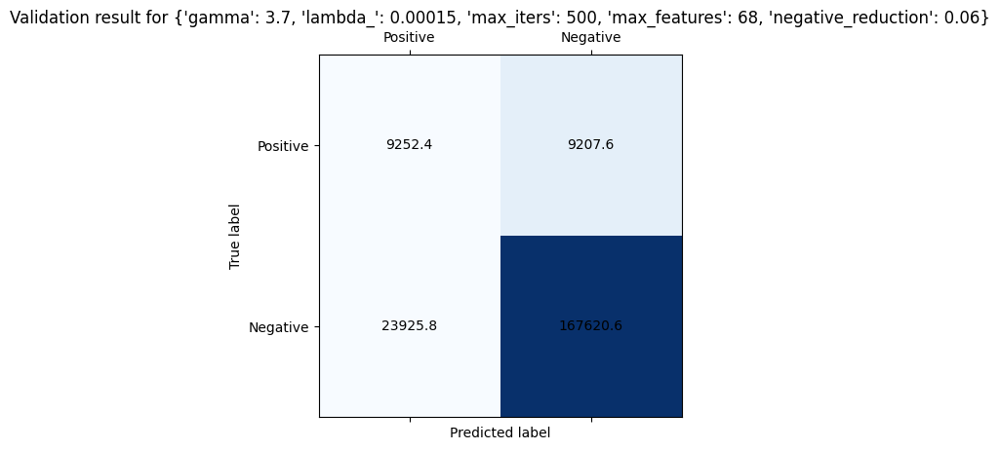

Tuning with args (23/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.325973262241516


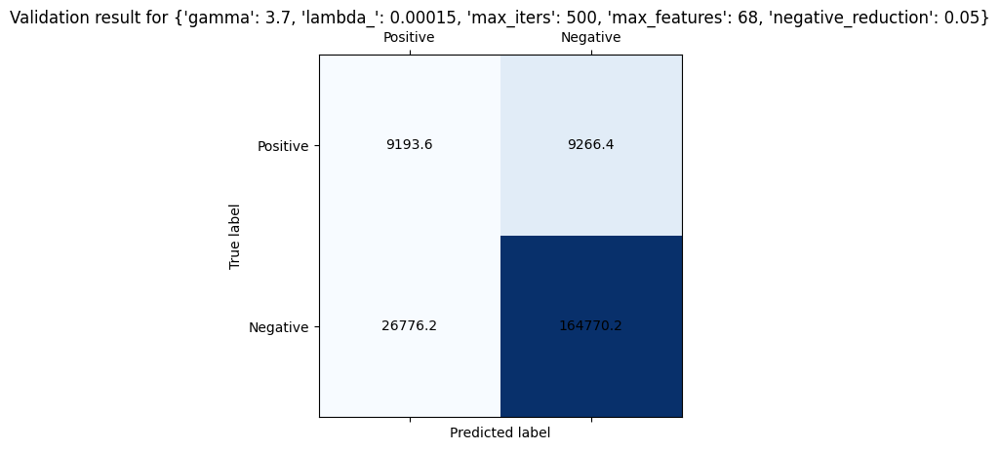

Tuning with args (24/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.3480217120673206


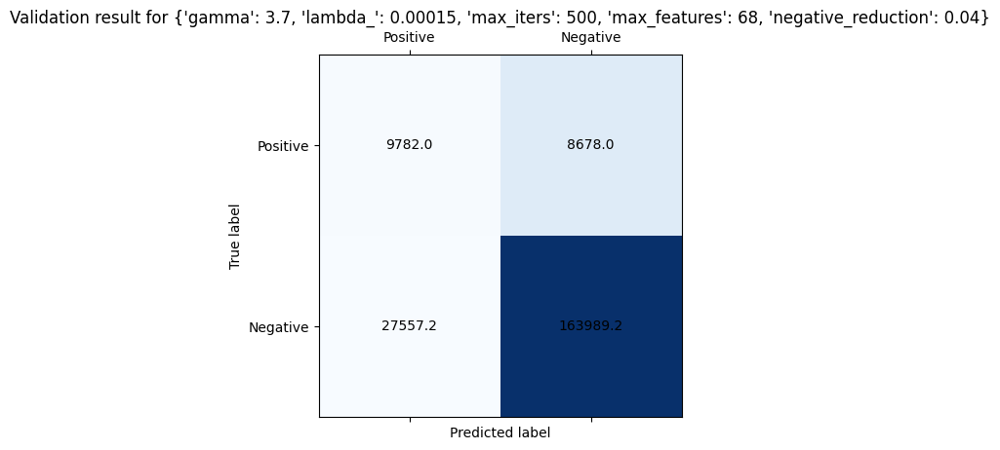

Tuning with args (25/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.333948044119179


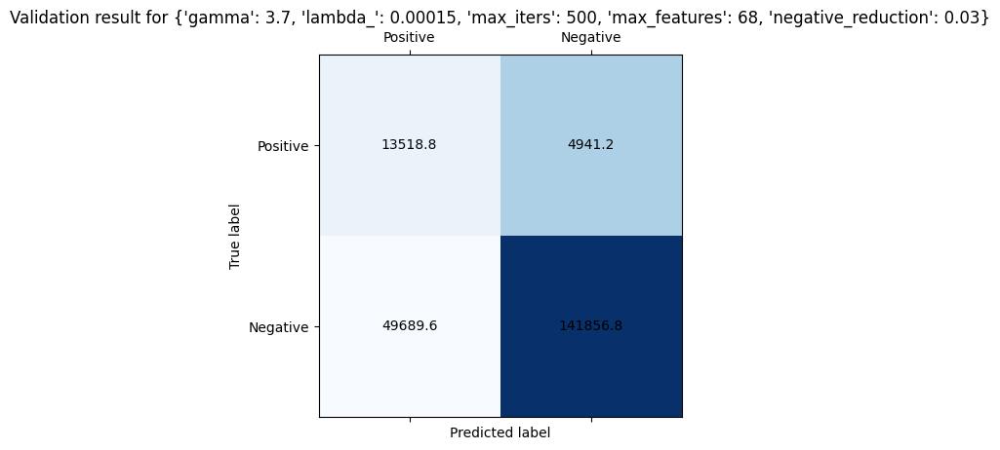

Tuning with args (26/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.28044431798285524


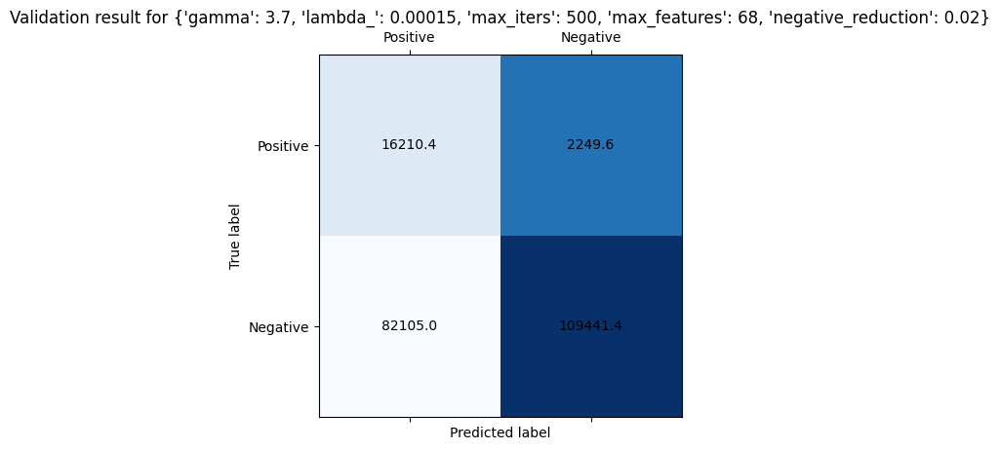

Tuning with args (27/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.17131242702917626


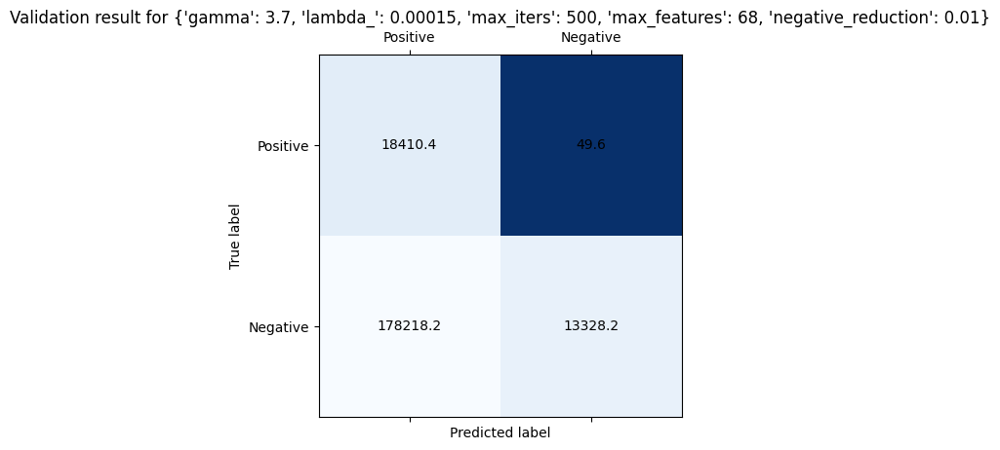

Tuning with args (28/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.2927803510728413


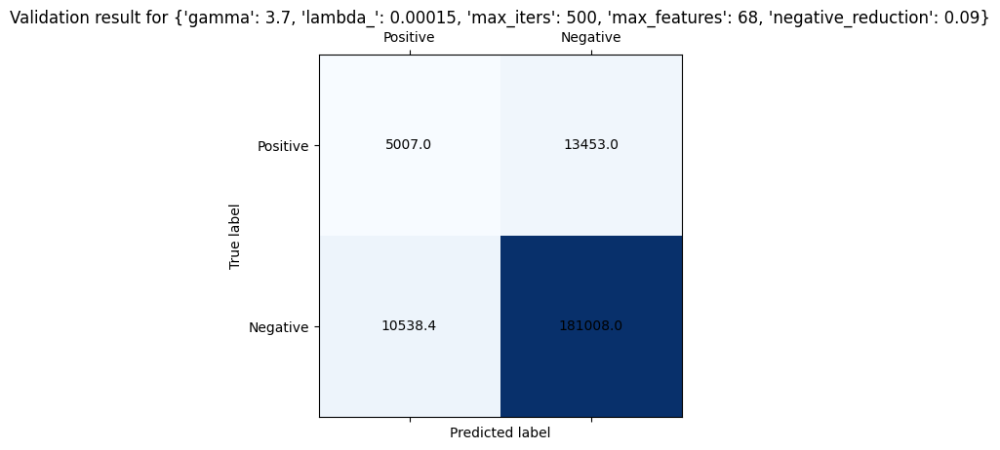

Tuning with args (29/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.31473906654433753


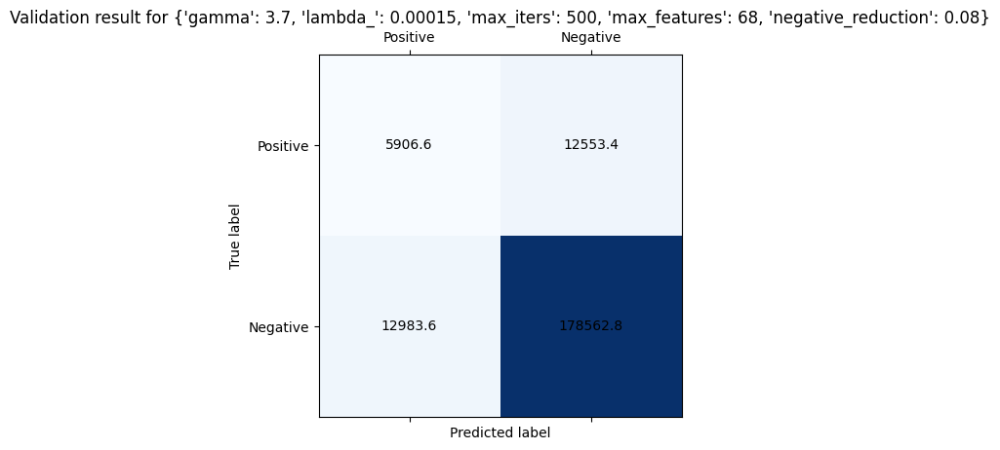

Tuning with args (30/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.2773839112478854


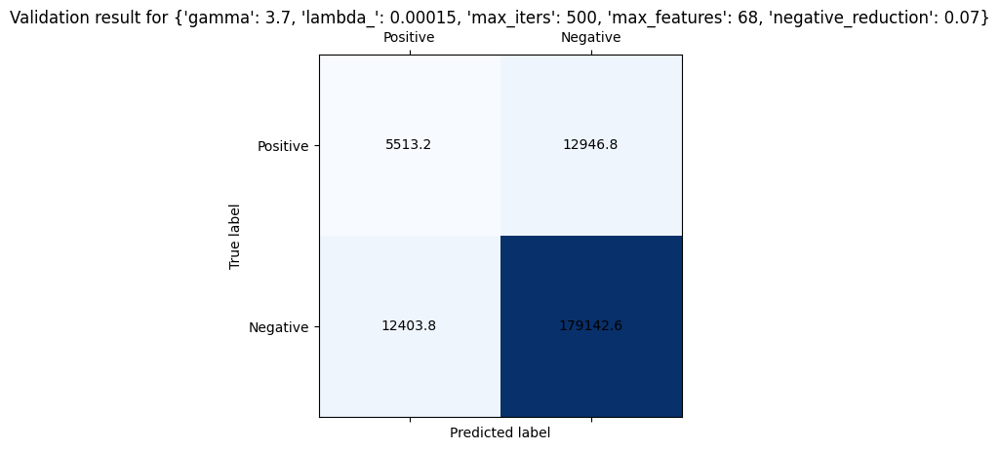

Tuning with args (31/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.35721672784688036


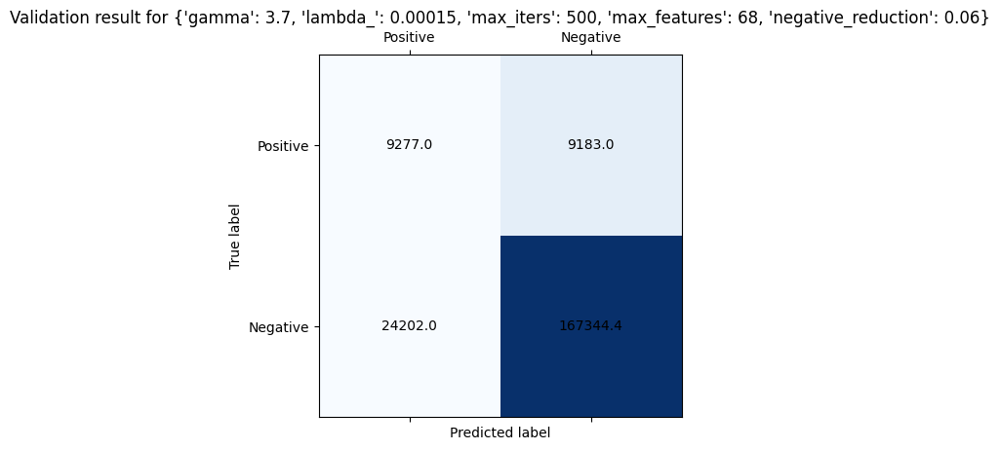

Tuning with args (32/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.34960652971717154


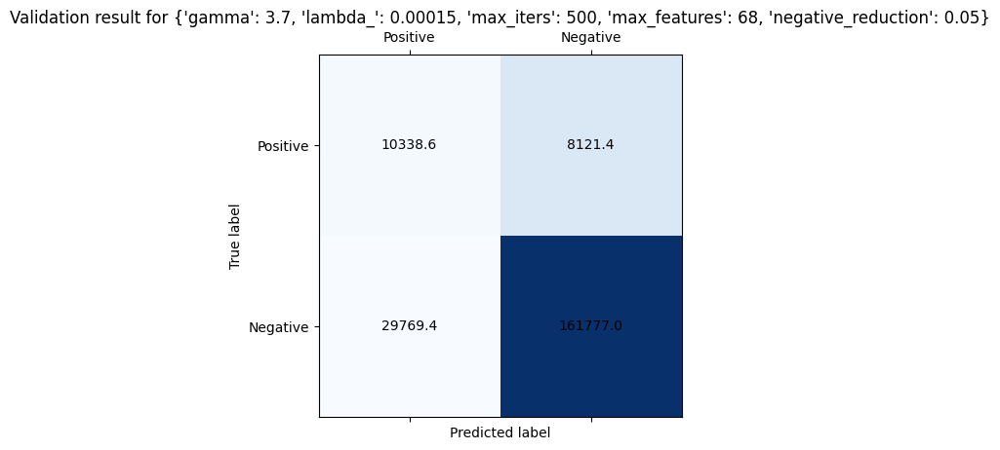

Tuning with args (33/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.3371807426555605


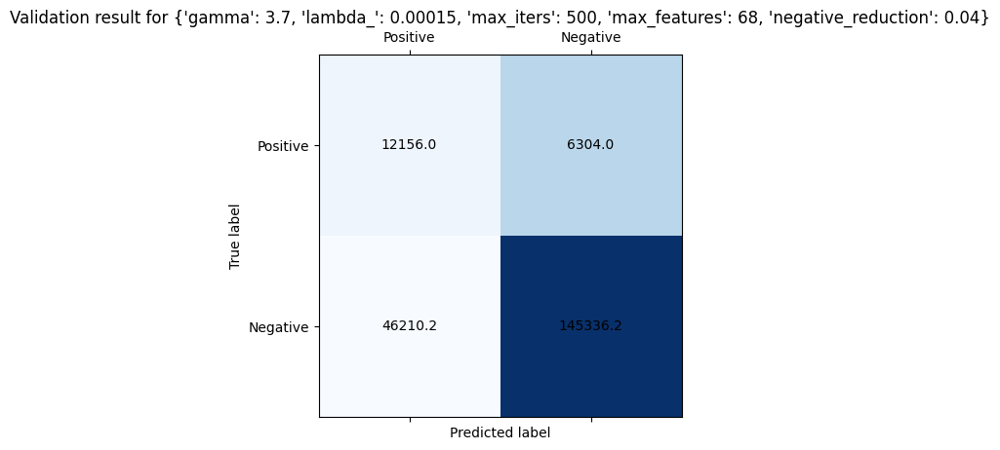

Tuning with args (34/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.3236297394589023


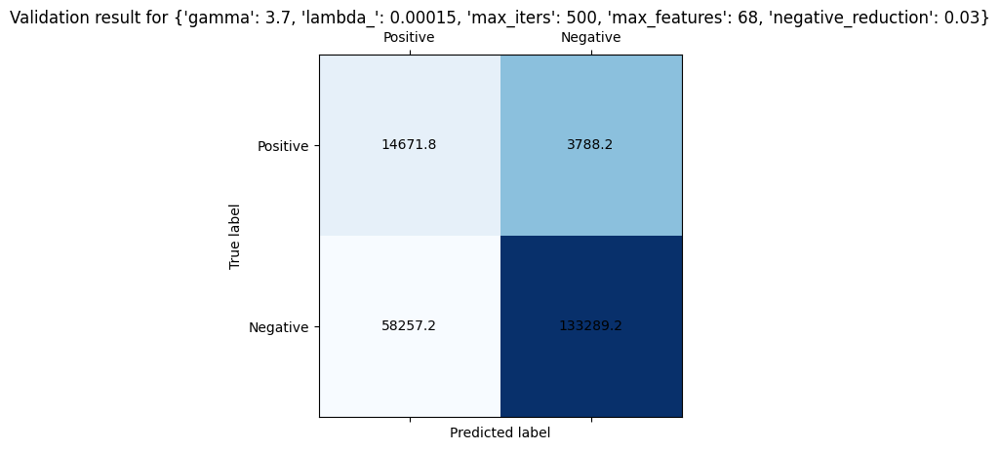

Tuning with args (35/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.2684655828357549


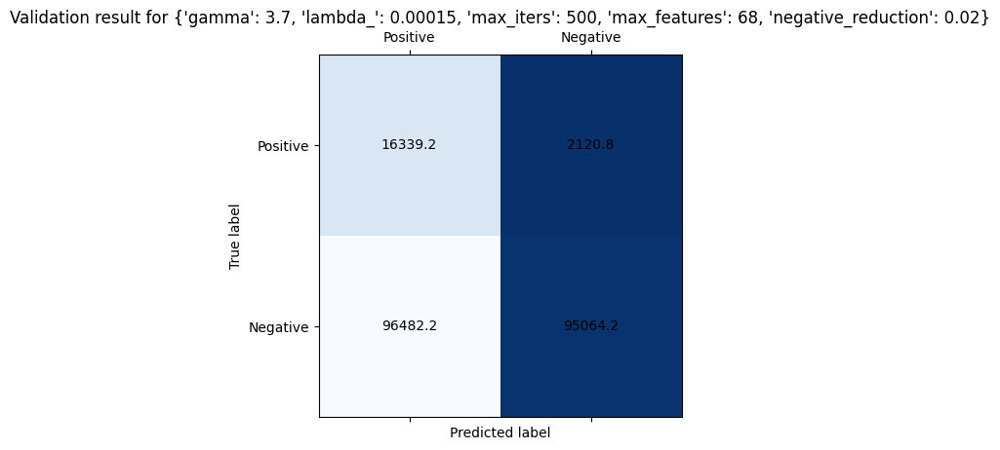

Tuning with args (36/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.1682760480458819


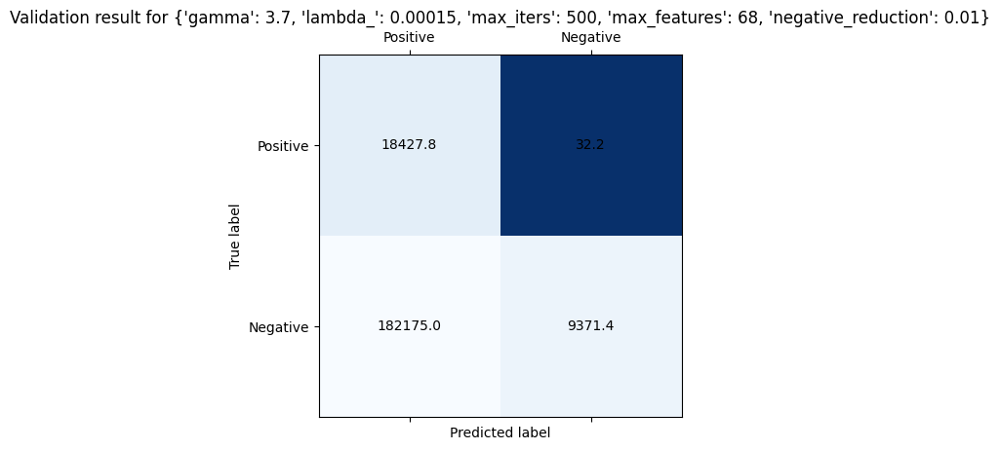

Tuning with args (37/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.2571617487642822


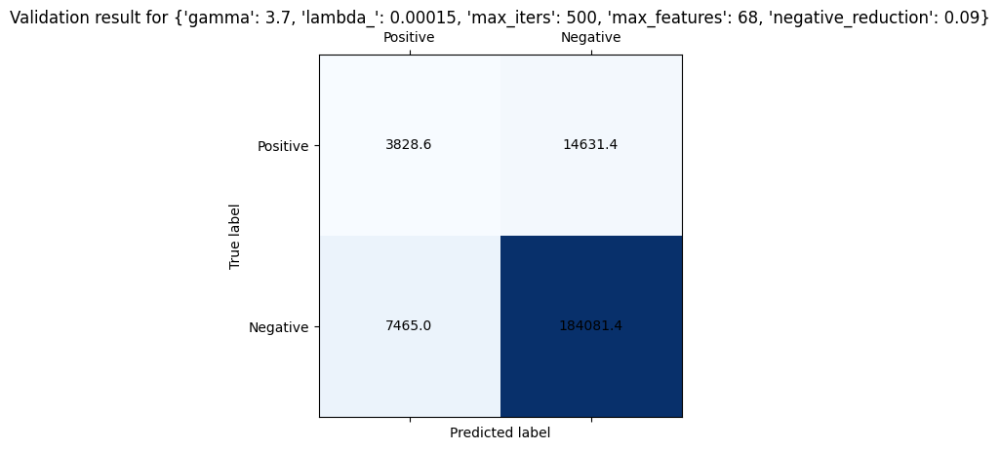

Tuning with args (38/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.3249336023741339


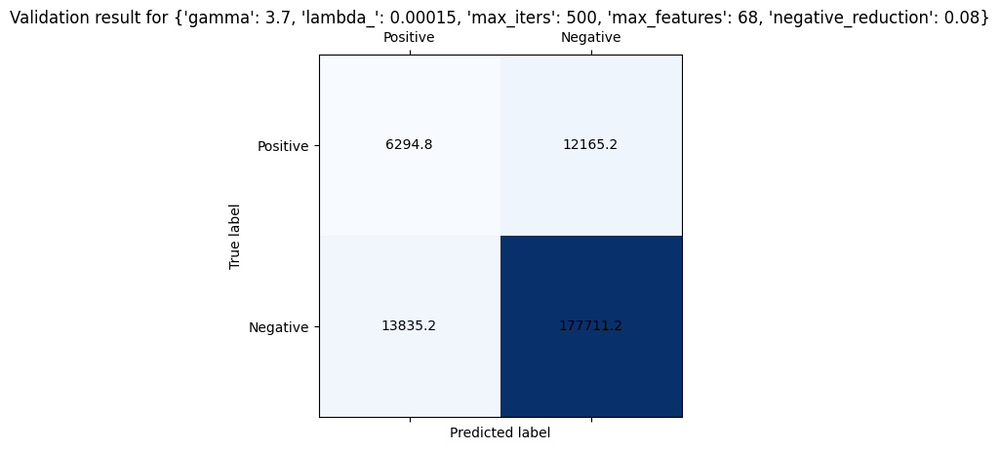

Tuning with args (39/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.3200432003610706


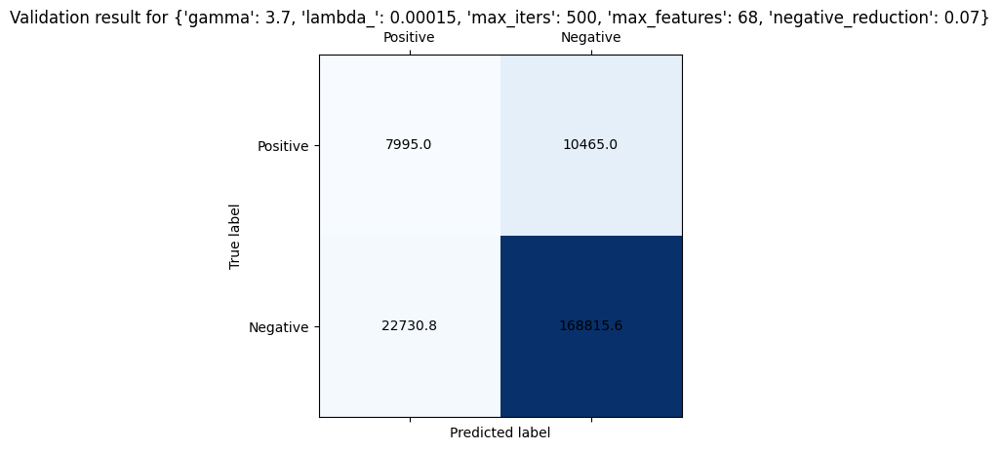

Tuning with args (40/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.34791772945675287


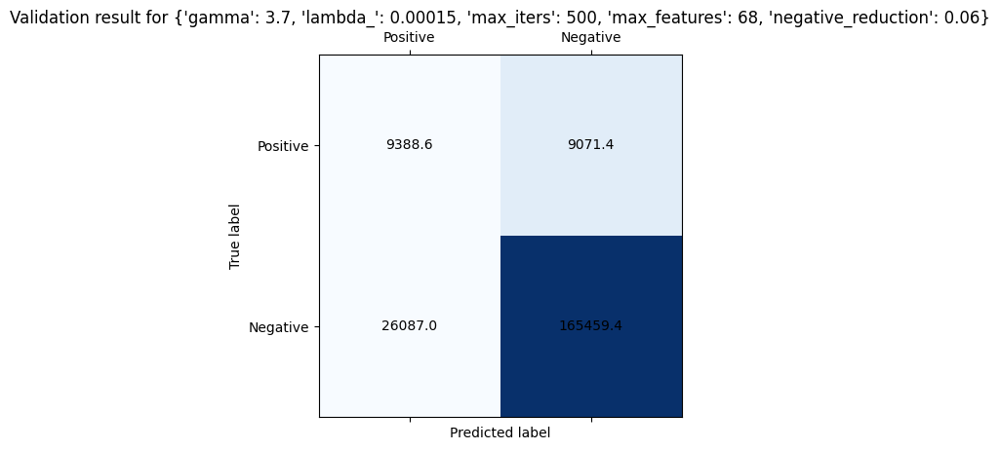

Tuning with args (41/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.35401377768850917


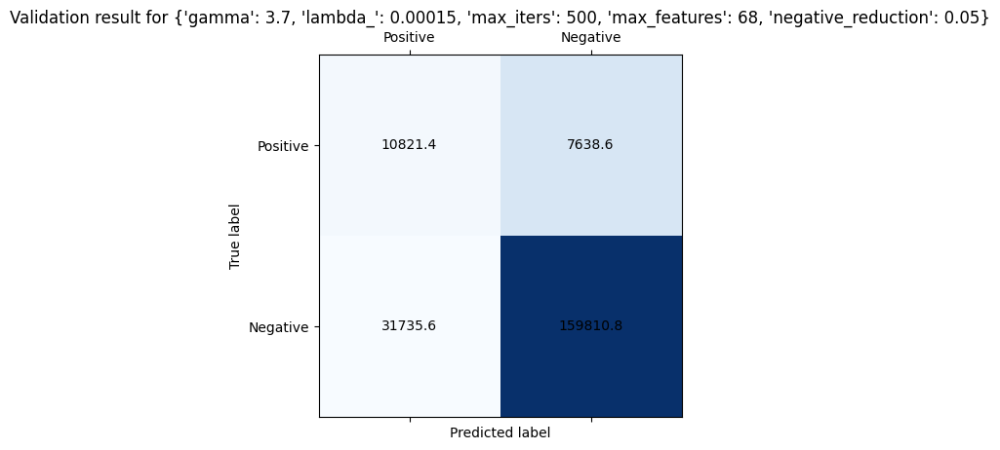

Tuning with args (42/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.317495068841789


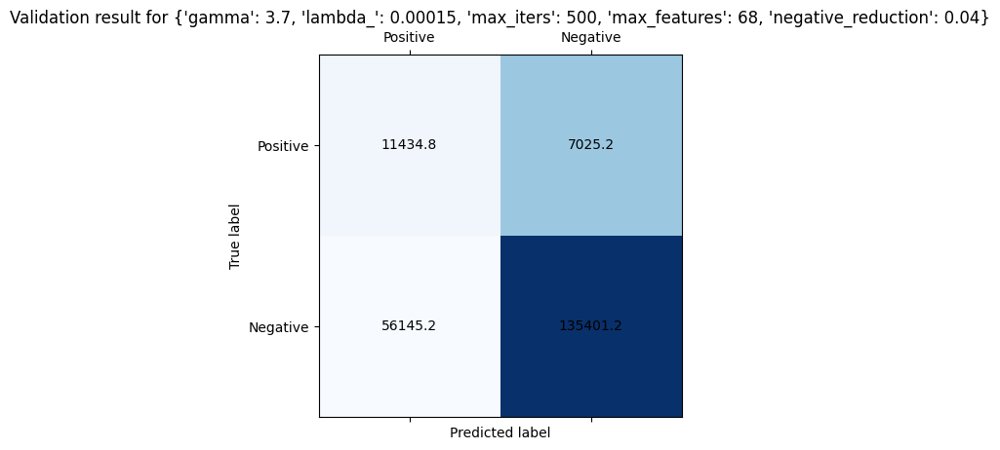

Tuning with args (43/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.35012680479745717


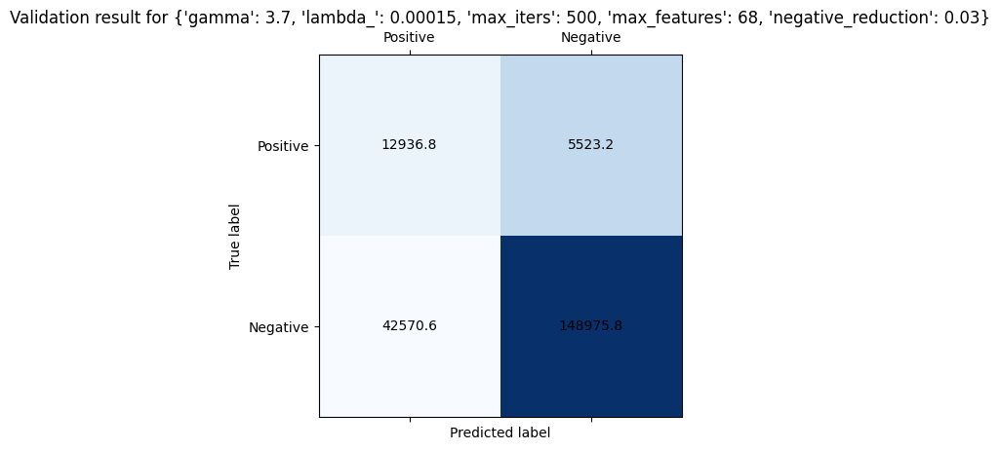

Tuning with args (44/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.2959180299845422


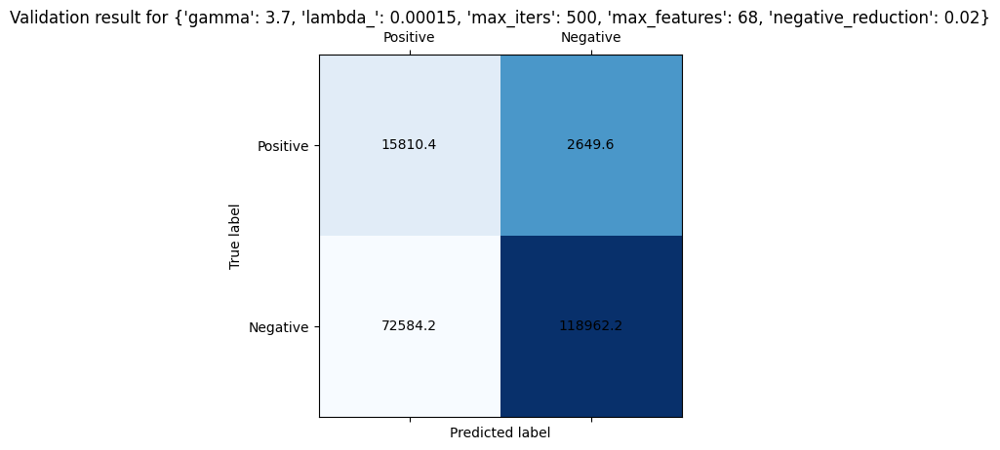

Tuning with args (45/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.1676251017267158


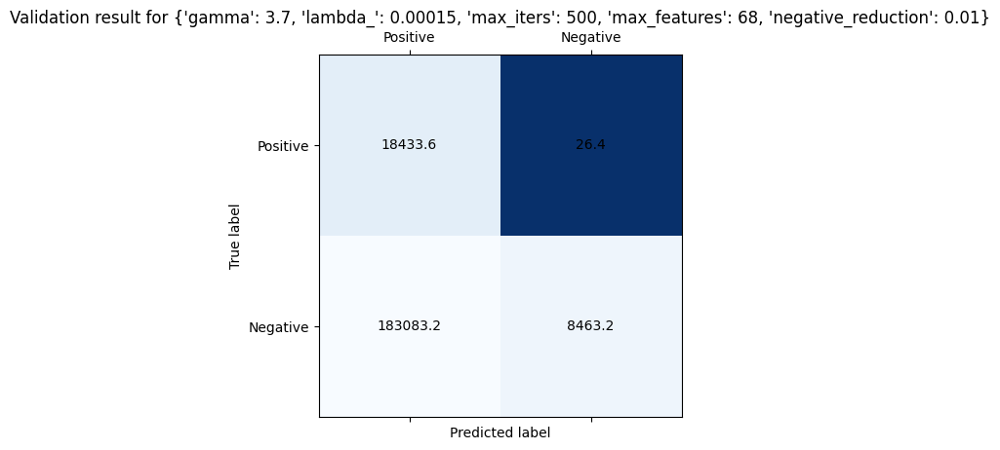

Tuning with args (46/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.2841293155513723


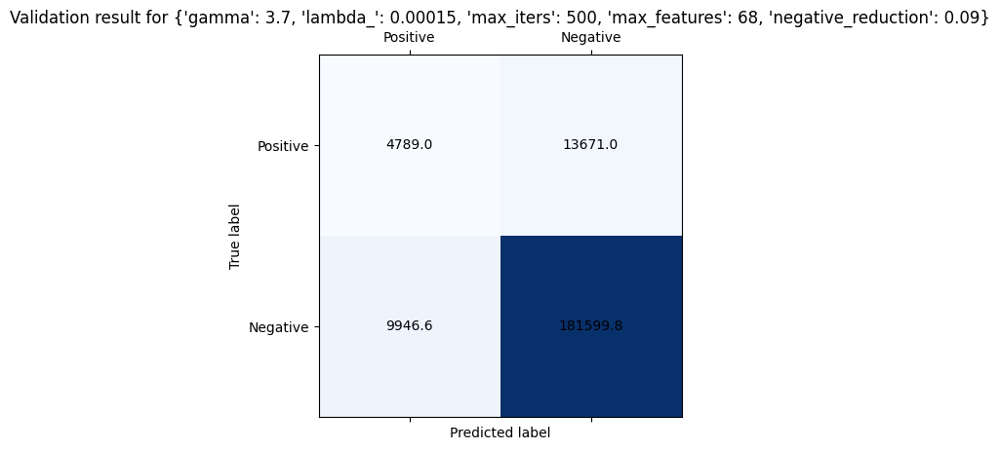

Tuning with args (47/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.3168252782804117


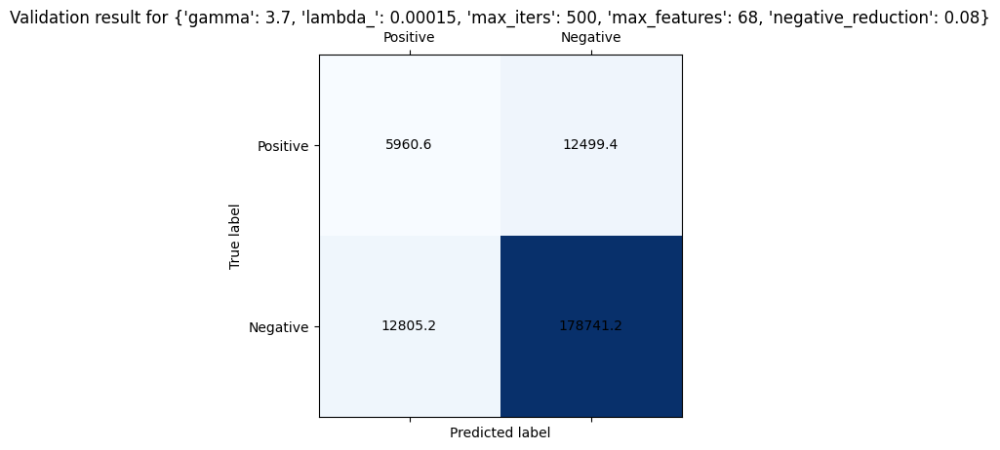

Tuning with args (48/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.35126180384342065


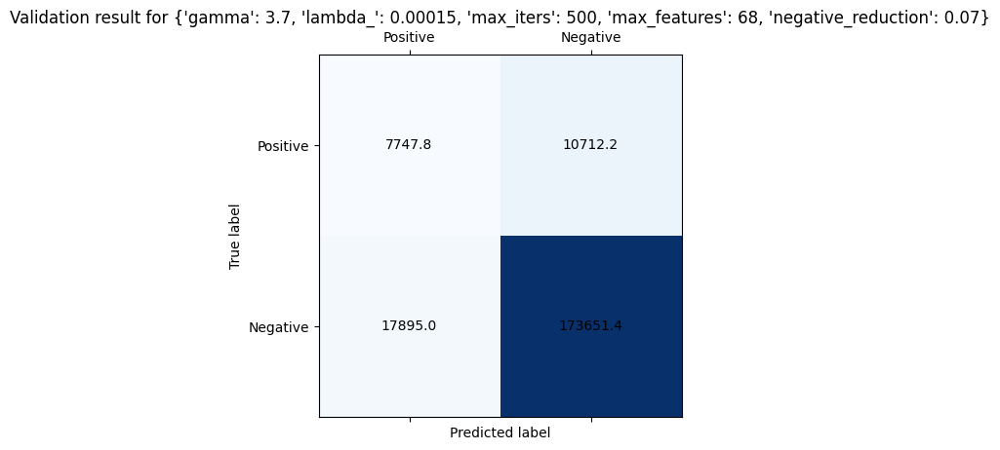

Tuning with args (49/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.3391208300053786


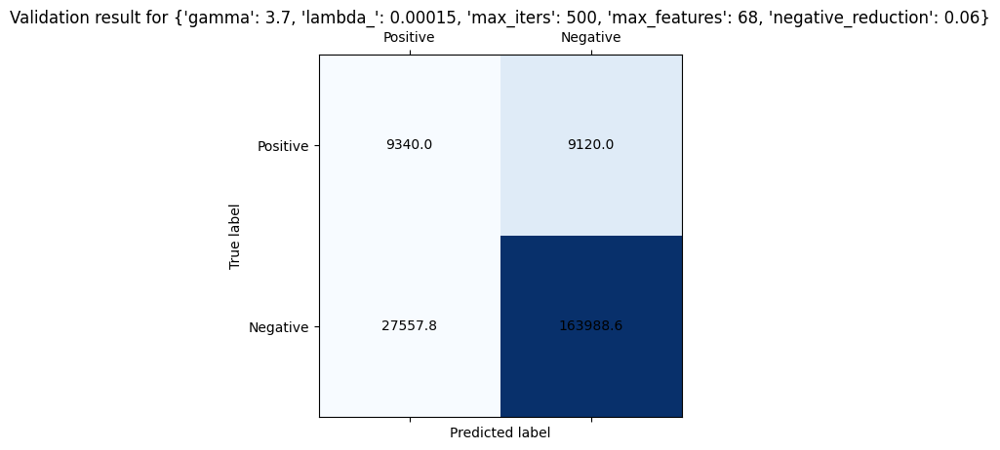

Tuning with args (50/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.32921702010157966


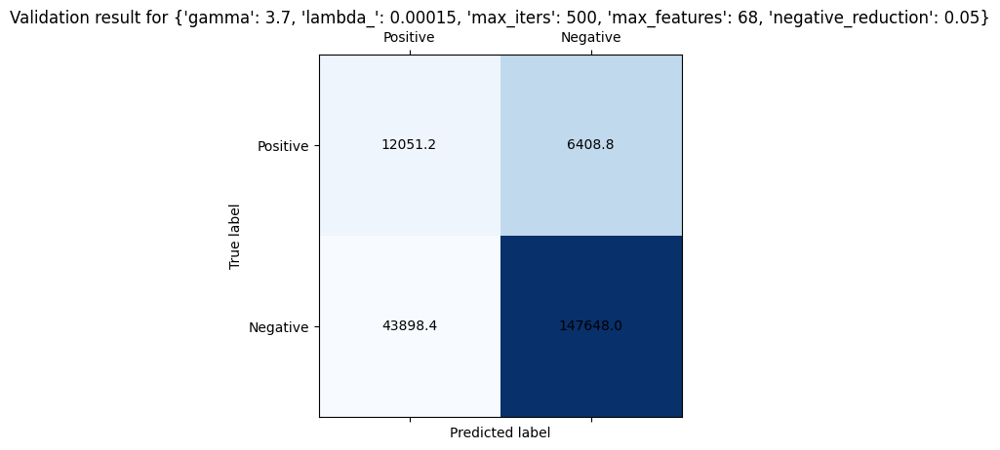

Tuning with args (51/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.36123919468971344


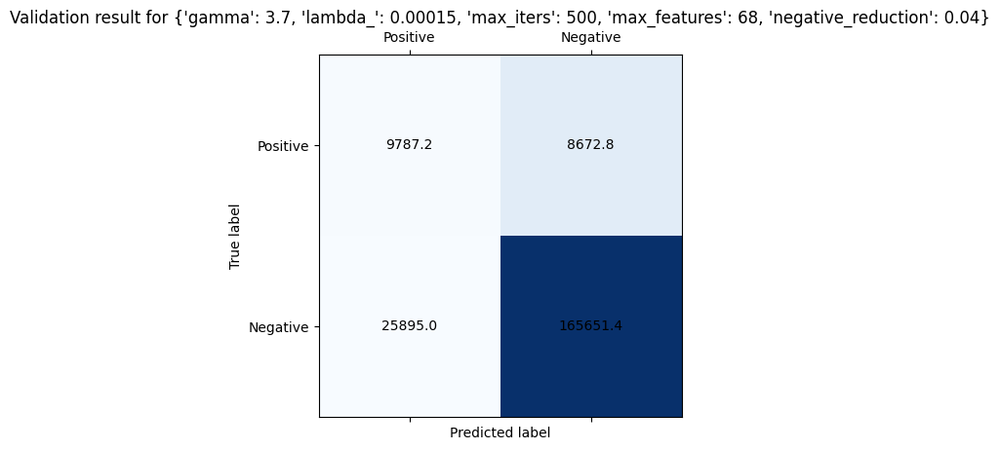

Tuning with args (52/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.3354658471371967


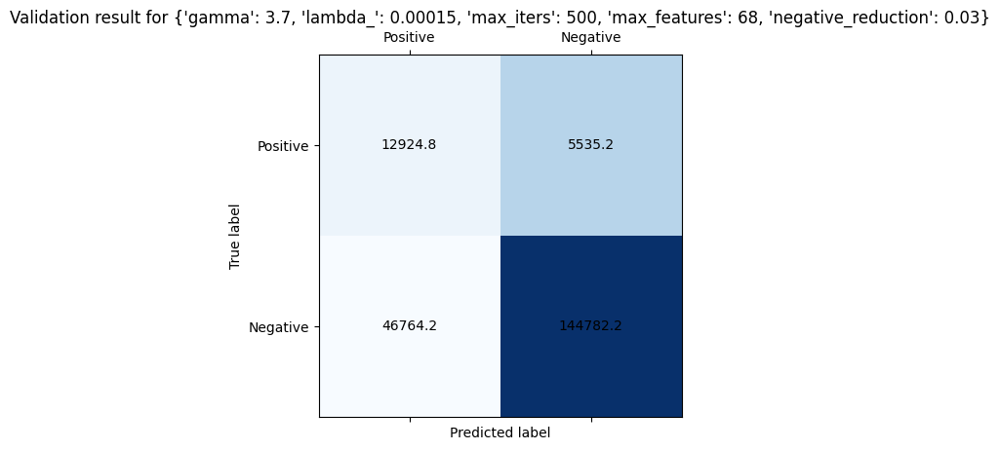

Tuning with args (53/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.2858768184946904


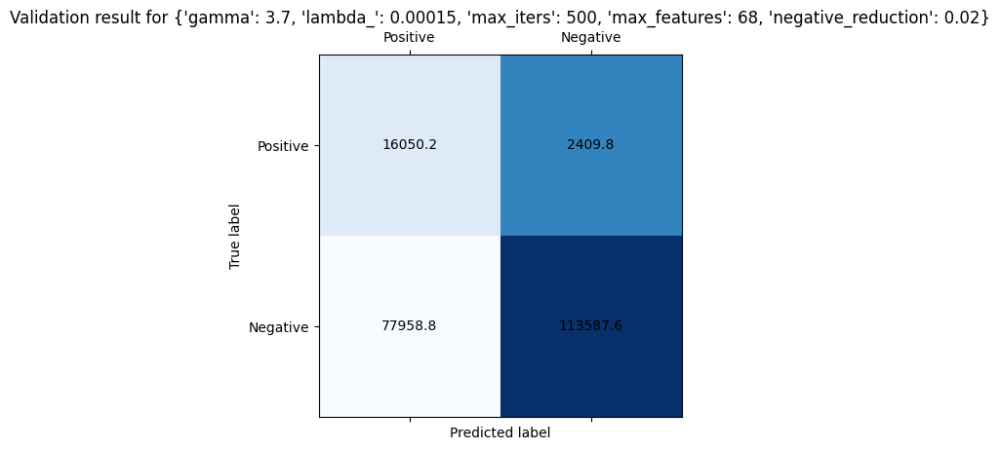

Tuning with args (54/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.16789283710800904


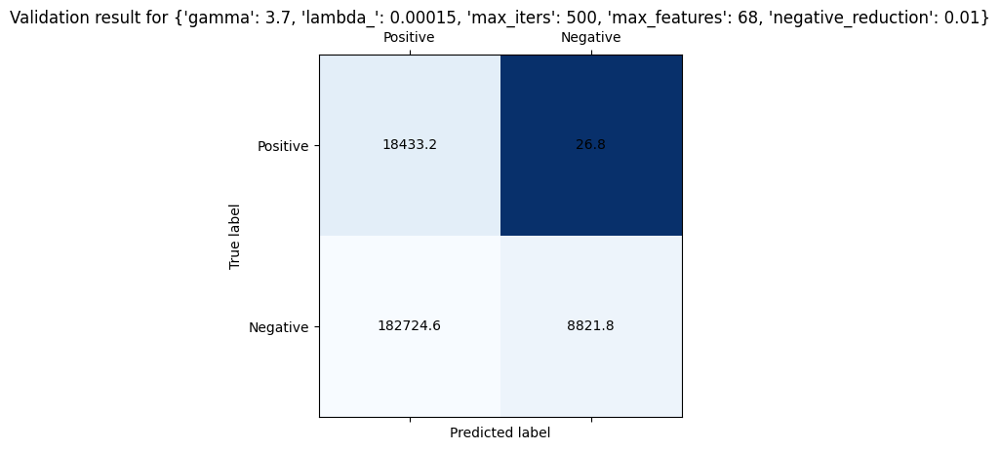

Tuning with args (55/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.09}
Average validation cross-validation f1: 0.28747758812766294


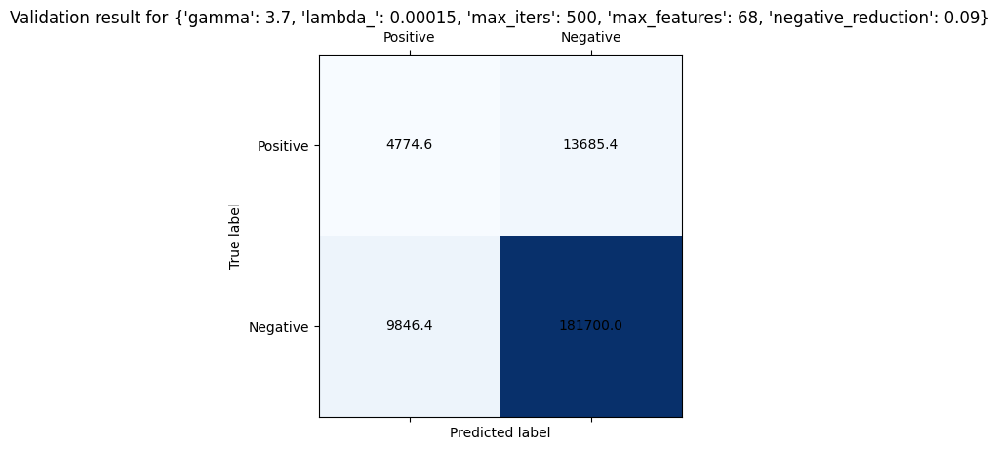

Tuning with args (56/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.08}
Average validation cross-validation f1: 0.3162798404196891


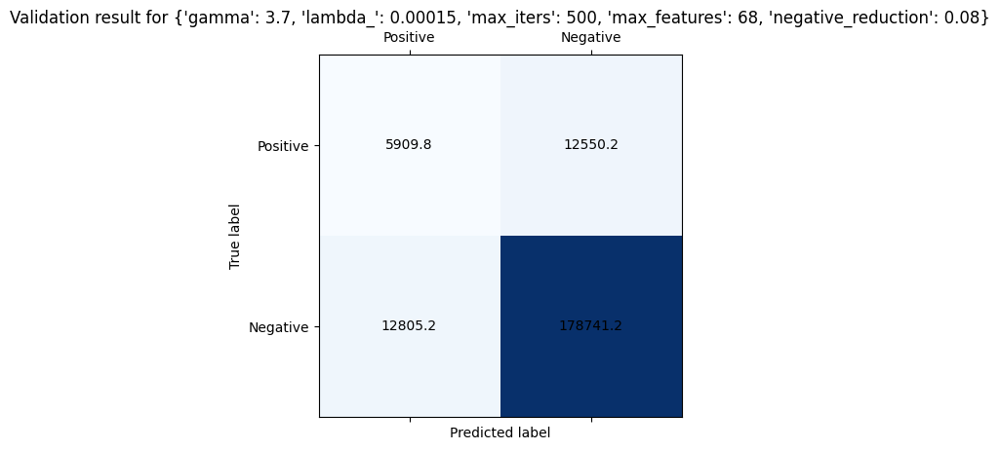

Tuning with args (57/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.07}
Average validation cross-validation f1: 0.25799010883747253


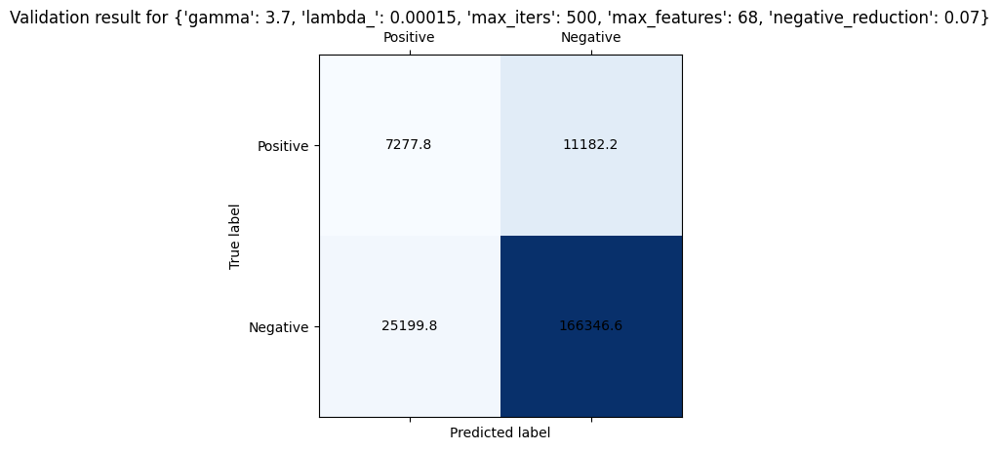

Tuning with args (58/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.06}
Average validation cross-validation f1: 0.35783642115840913


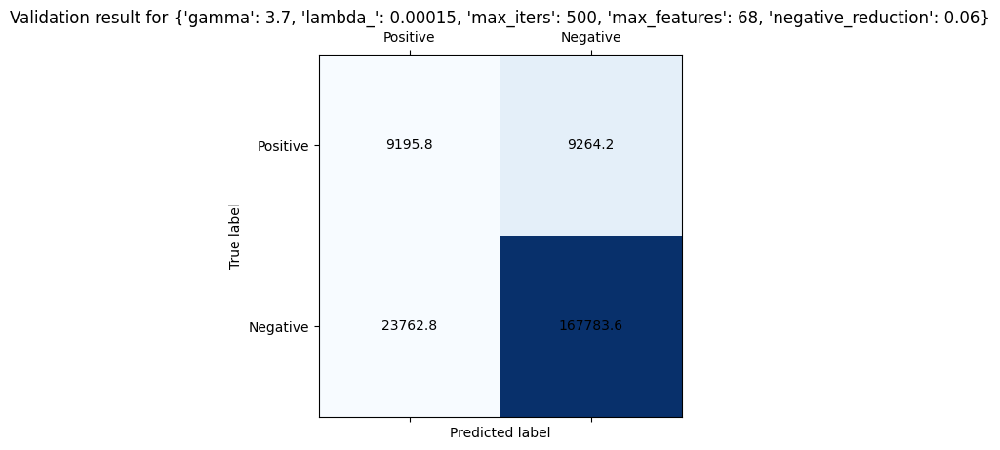

Tuning with args (59/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.05}
Average validation cross-validation f1: 0.3611444294811609


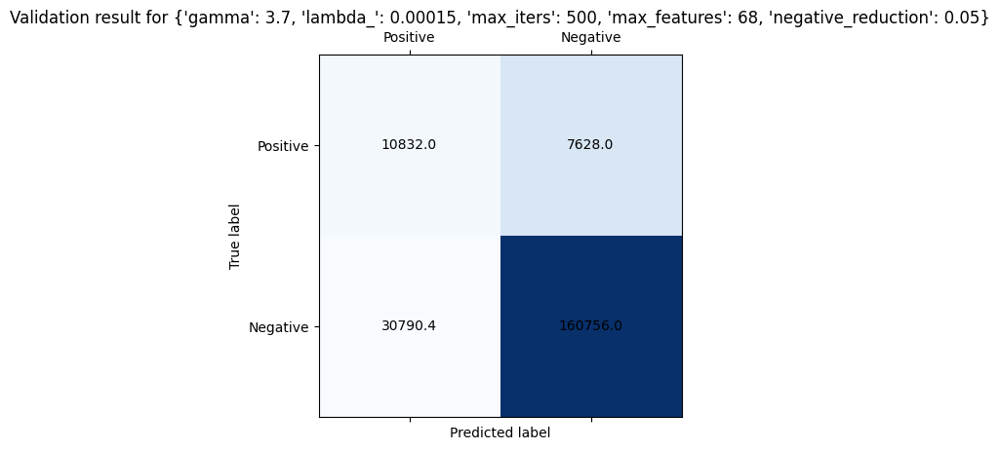

Tuning with args (60/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.04}
Average validation cross-validation f1: 0.34858809787319045


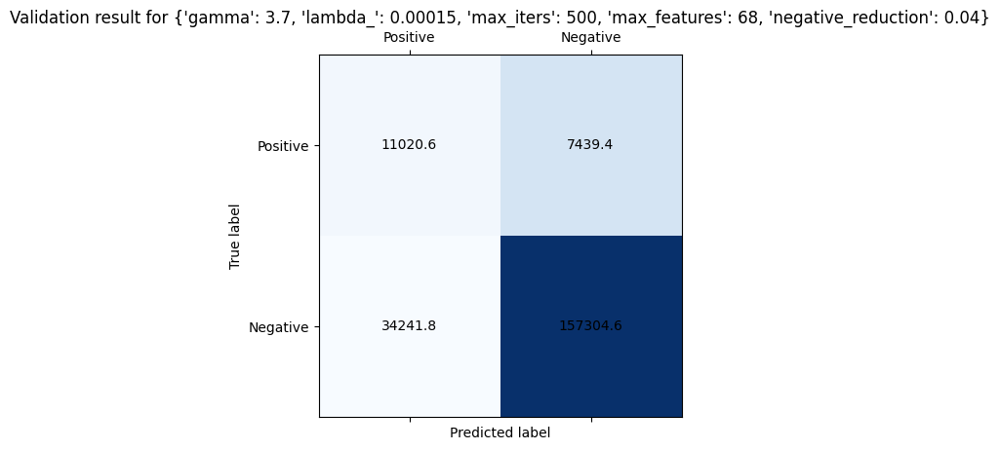

Tuning with args (61/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.03}
Average validation cross-validation f1: 0.34432614288326163


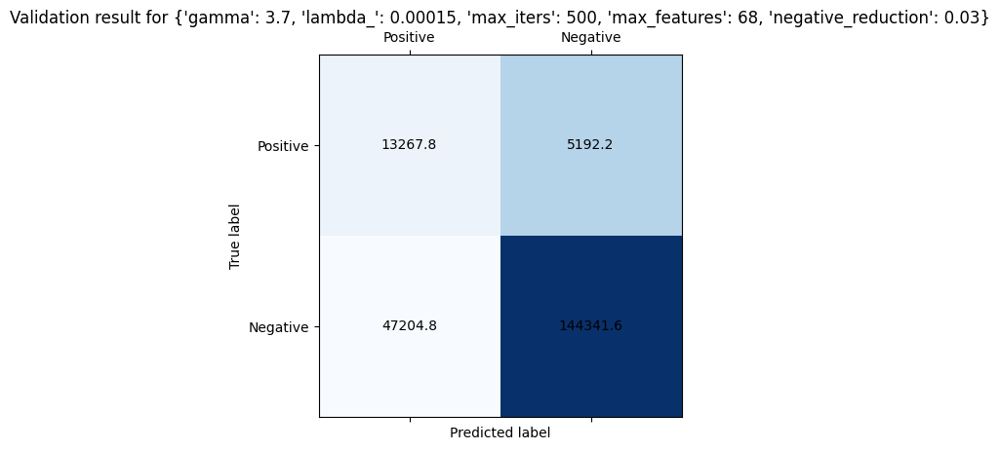

Tuning with args (62/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.02}
Average validation cross-validation f1: 0.2937753690566557


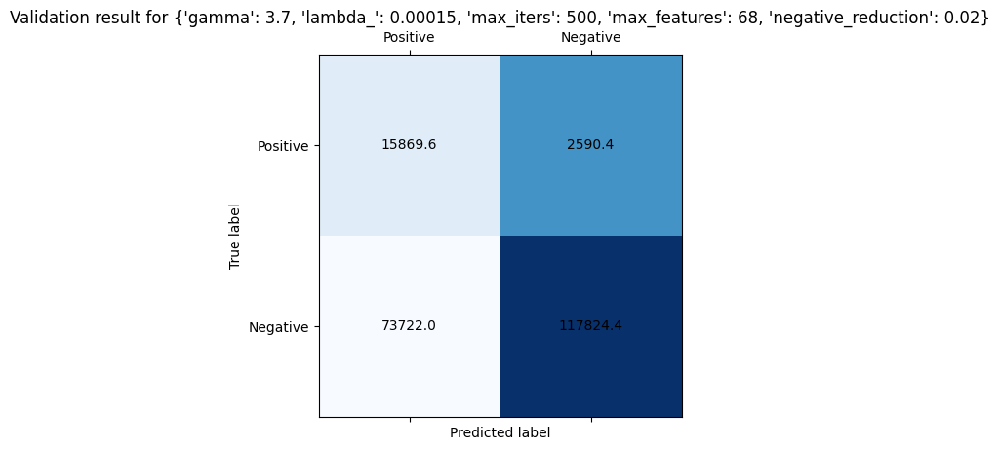

Tuning with args (63/63): {'gamma': 3.7, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 68, 'negative_reduction': 0.01}
Average validation cross-validation f1: 0.1715304009847623


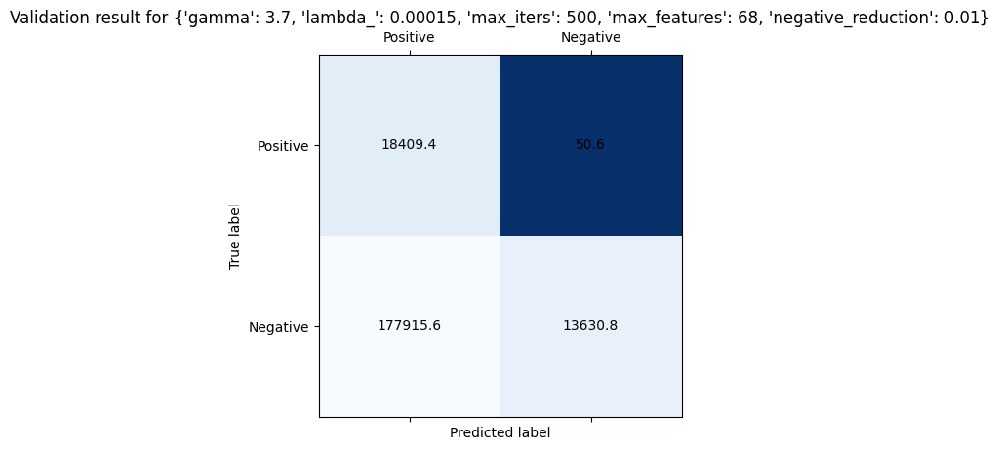

In [36]:
args_logreg_f1_2 = [
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.09,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.08,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.07,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.06,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.05,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.04,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.03,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.02,
    },
    {
        "gamma": 3.7,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 68,
        "negative_reduction": 0.01,
    },
]
validation_f1_logreg_4 = tune_f1(
    x_train_norm,
    y_train,
    k=5,
    model=RegularizedLogisticRegression,
    args=args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2,
)

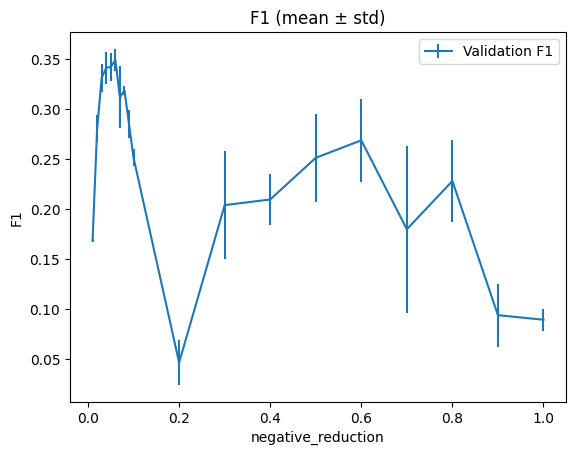


Averaged results:
negative_reduction=0.01 | val=0.1688±0.0017
negative_reduction=0.02 | val=0.2807±0.0137
negative_reduction=0.03 | val=0.3316±0.0139
negative_reduction=0.04 | val=0.3416±0.0163
negative_reduction=0.05 | val=0.3424±0.0142
negative_reduction=0.06 | val=0.3495±0.0111
negative_reduction=0.07 | val=0.3121±0.0312
negative_reduction=0.08 | val=0.3190±0.0044
negative_reduction=0.09 | val=0.2853±0.0144
negative_reduction=0.1 | val=0.2515±0.0086
negative_reduction=0.2 | val=0.0467±0.0222
negative_reduction=0.3 | val=0.2042±0.0544
negative_reduction=0.4 | val=0.2099±0.0259
negative_reduction=0.5 | val=0.2515±0.0441
negative_reduction=0.6 | val=0.2691±0.0418
negative_reduction=0.7 | val=0.1801±0.0835
negative_reduction=0.8 | val=0.2284±0.0411
negative_reduction=0.9 | val=0.0941±0.0314
negative_reduction=1 | val=0.0896±0.0111


In [37]:
all_args_logreg_f1 = (
    args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_1
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
    + args_logreg_f1_2
)
all_validation_logreg_f1 = (
    validation_f1_logreg_1
    + validation_f1_logreg_2
    + validation_f1_logreg_3
    + validation_f1_logreg_4
)

show_printing_result_f1(
    all_args_logreg_f1,
    all_validation_logreg_f1,
    "negative_reduction",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False
)

#### Tuning for loss with balanced dataset (41% of positive)

Tuning with args (1/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.677191659119217


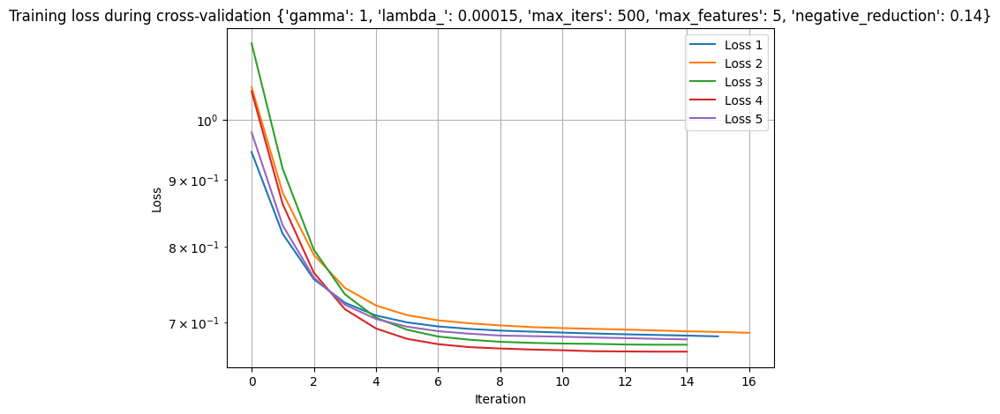

Tuning with args (2/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5837475591782492


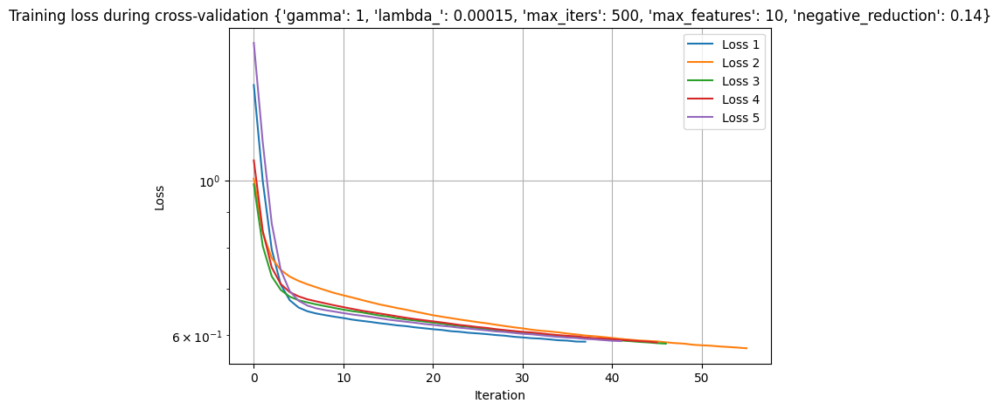

Tuning with args (3/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.493928027801827


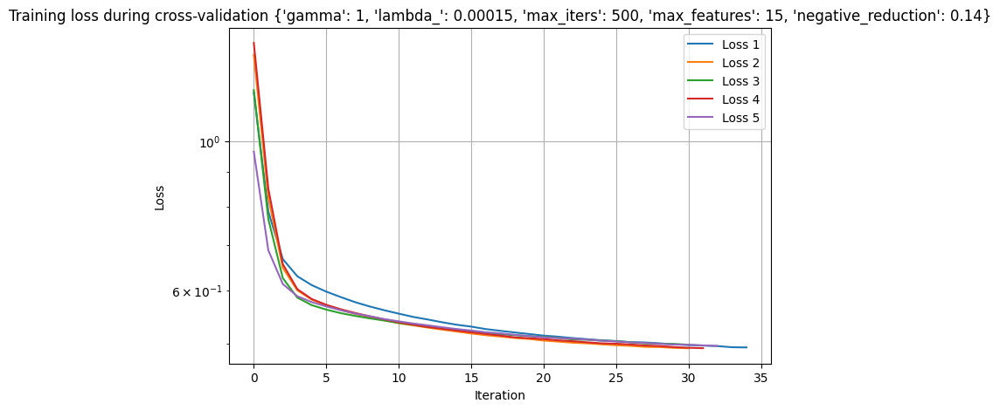

Tuning with args (4/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4997764001342369


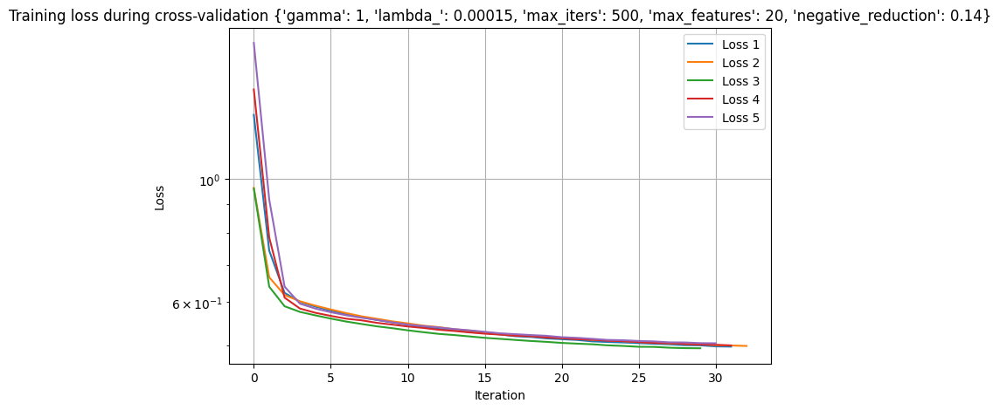

Tuning with args (5/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49197329583107213


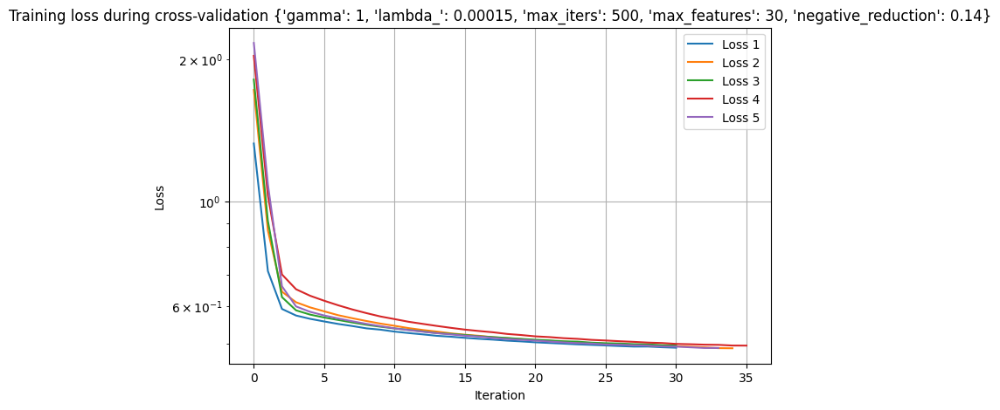

Tuning with args (6/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.487366597852738


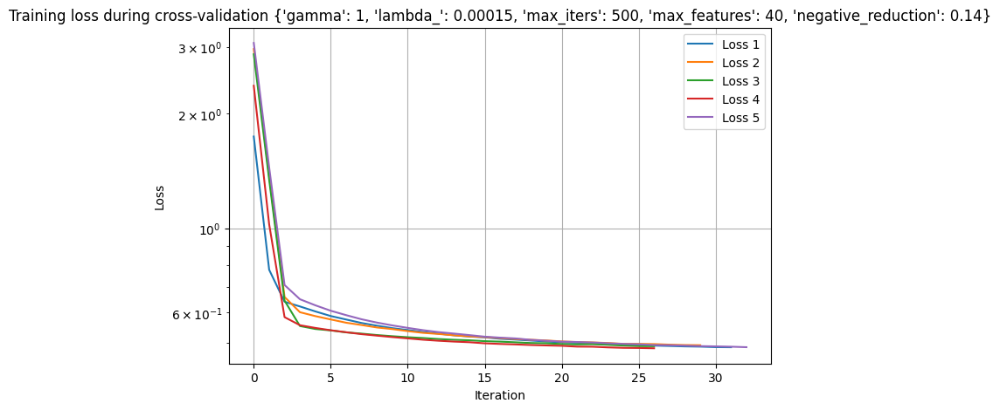

Tuning with args (7/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48307403634164797


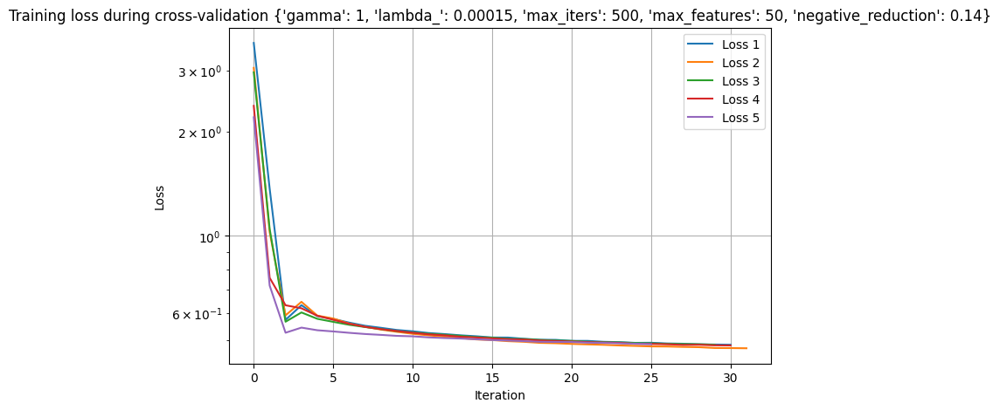

Tuning with args (8/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47636462256357043


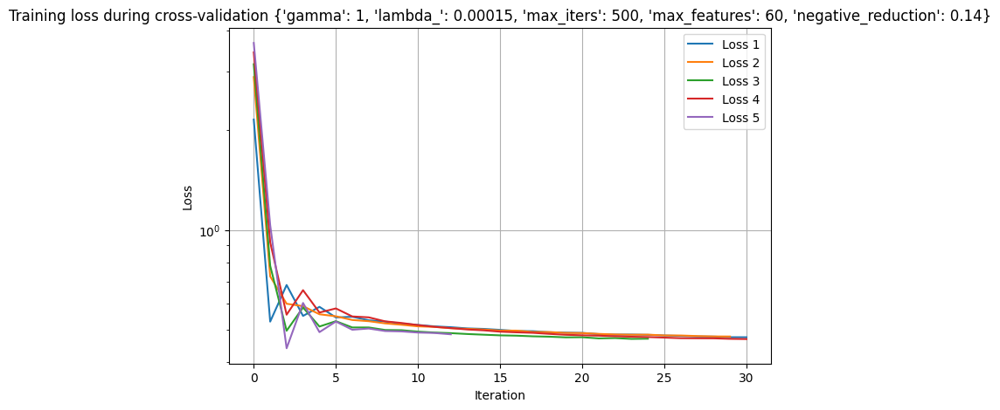

Tuning with args (9/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4749012484889561


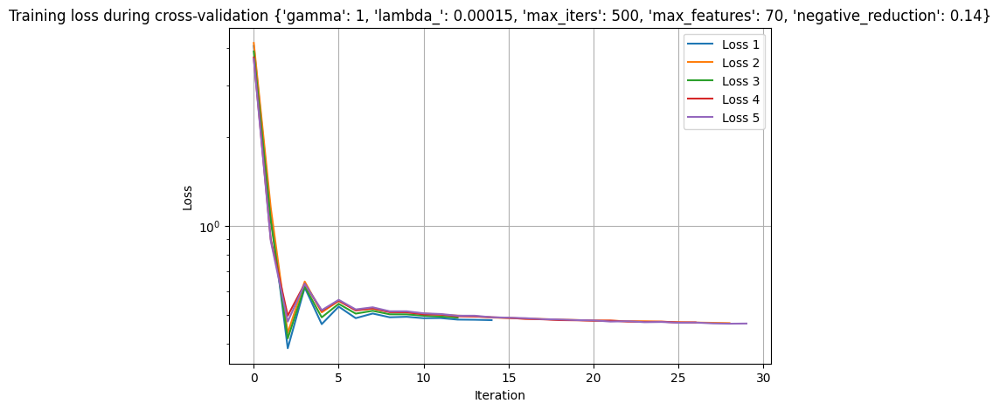

Tuning with args (10/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47207766402832324


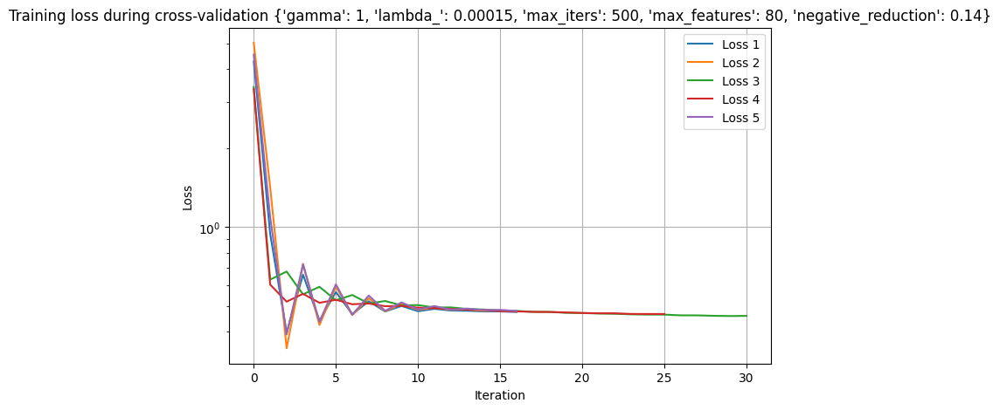

Tuning with args (11/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.482365388912721


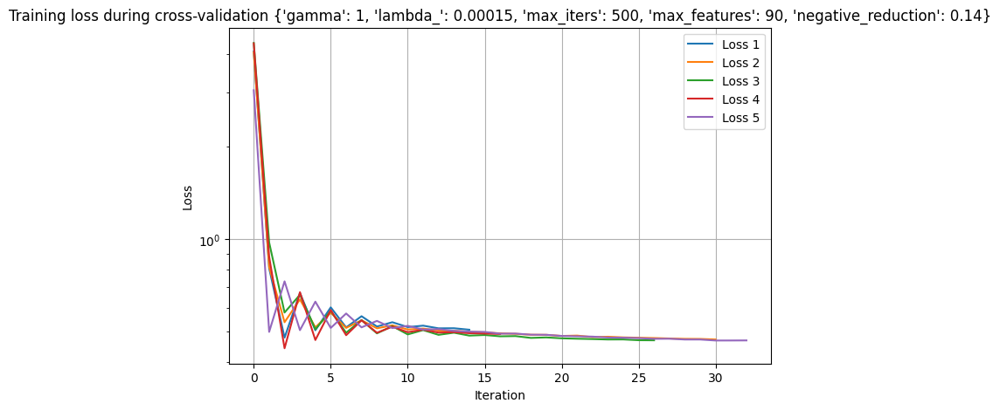

Tuning with args (12/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4727664940294923


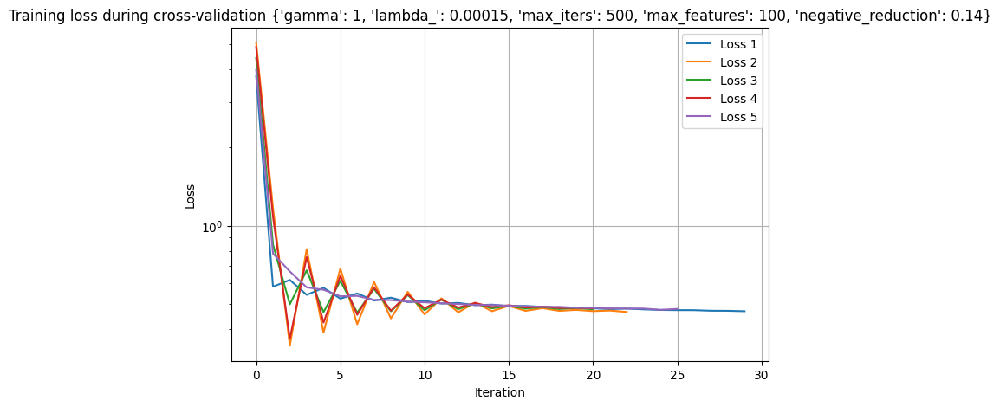

Tuning with args (13/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.6756690171684359


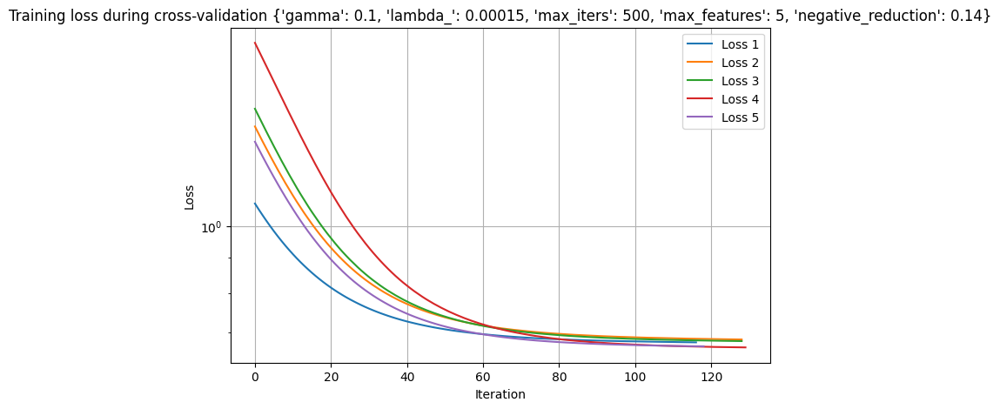

Tuning with args (14/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.586197891100382


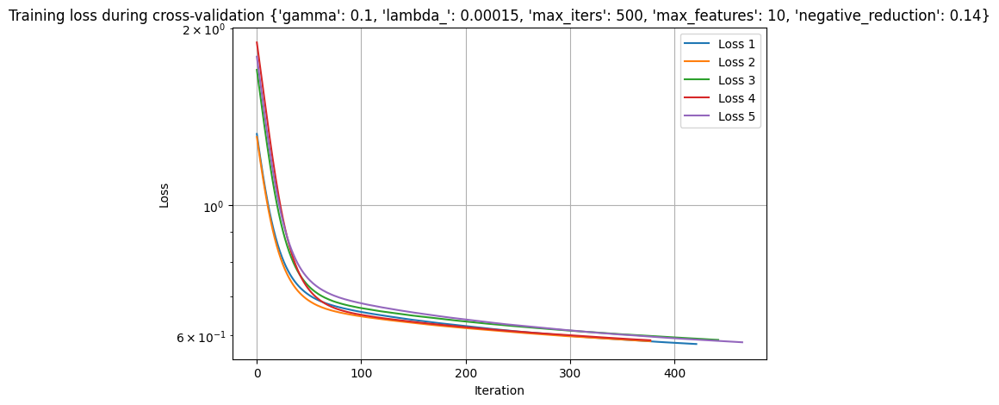

Tuning with args (15/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5030198964530715


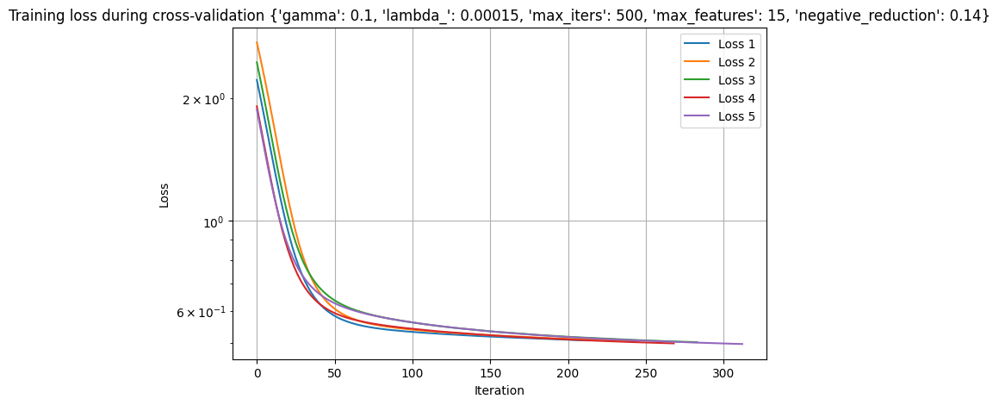

Tuning with args (16/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5090954451855106


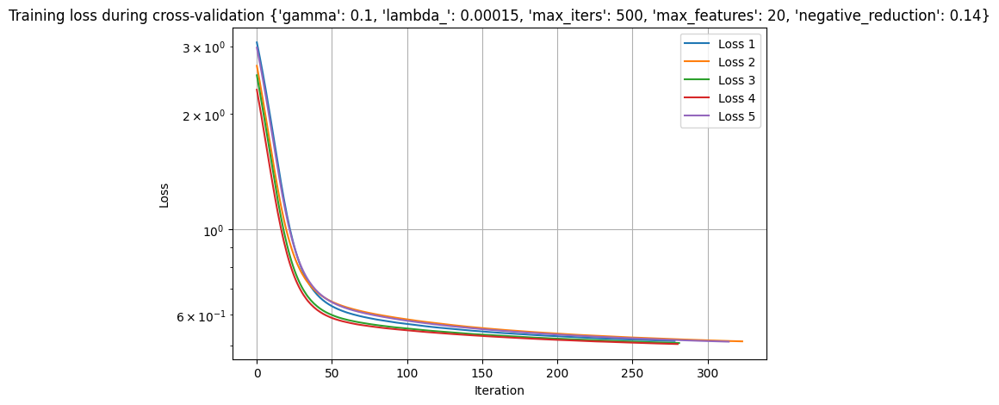

Tuning with args (17/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5055005802159671


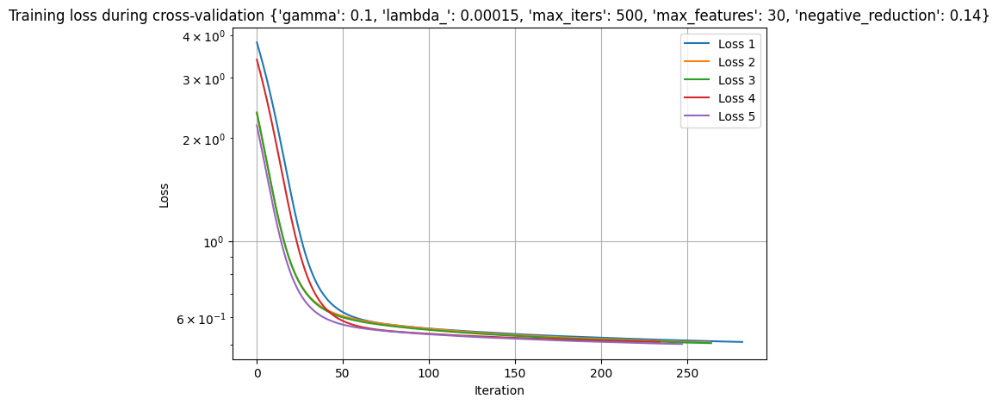

Tuning with args (18/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49416904746691015


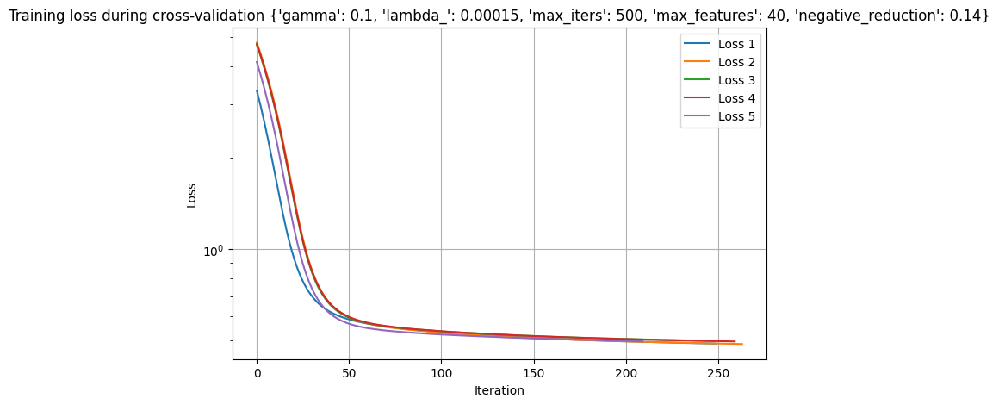

Tuning with args (19/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48971797677104084


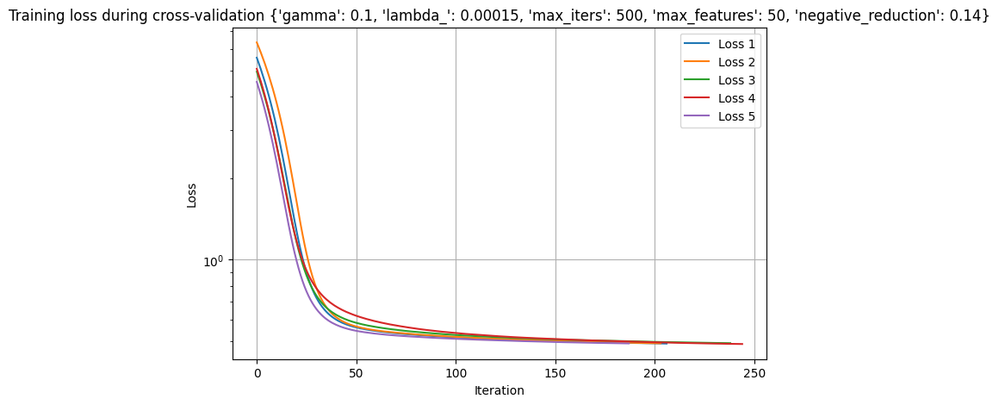

Tuning with args (20/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4813073226607102


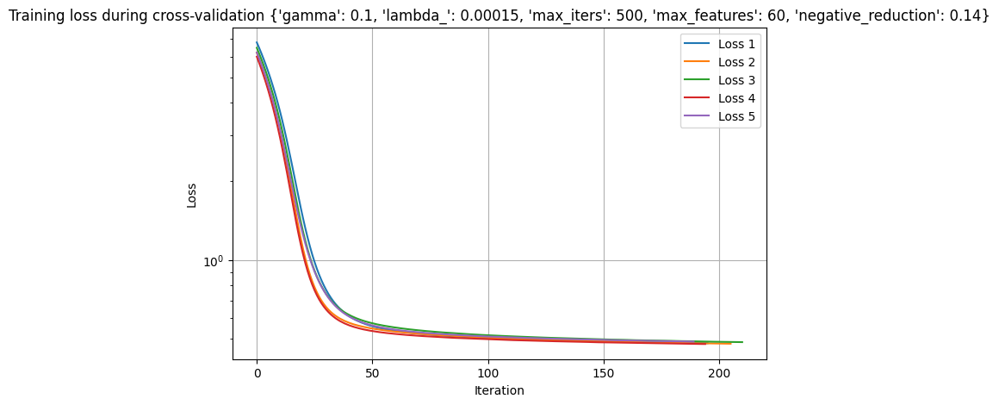

Tuning with args (21/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47285515748031115


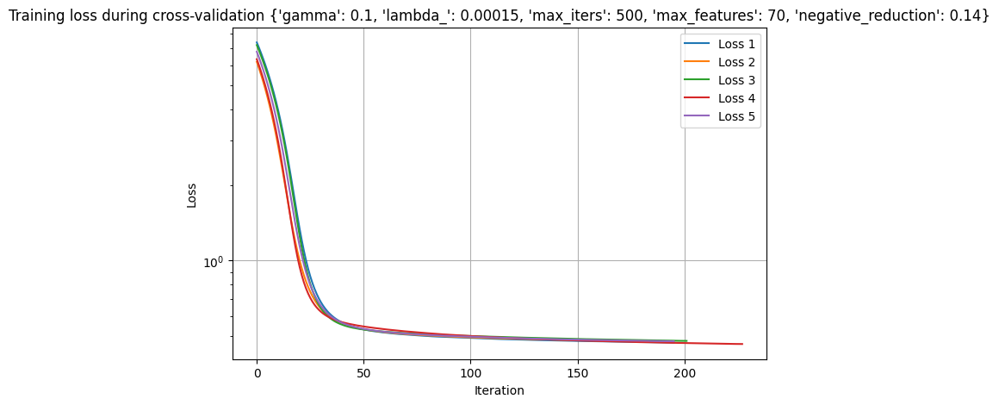

Tuning with args (22/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47598951957987506


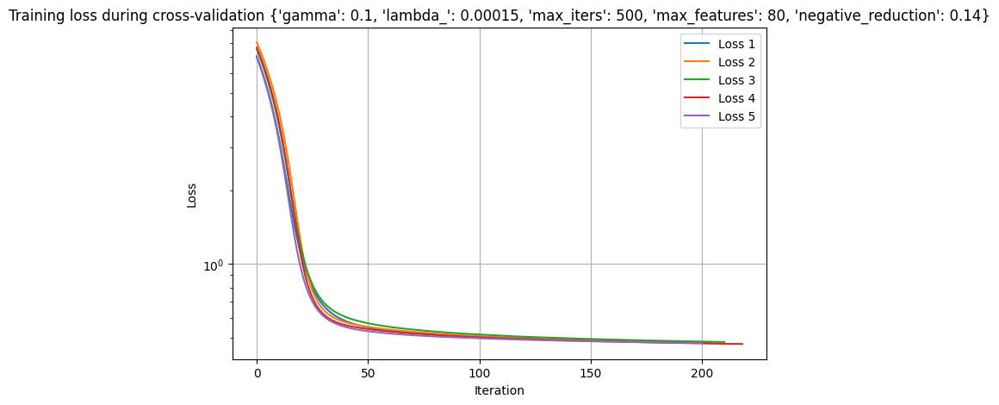

Tuning with args (23/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4836509701112943


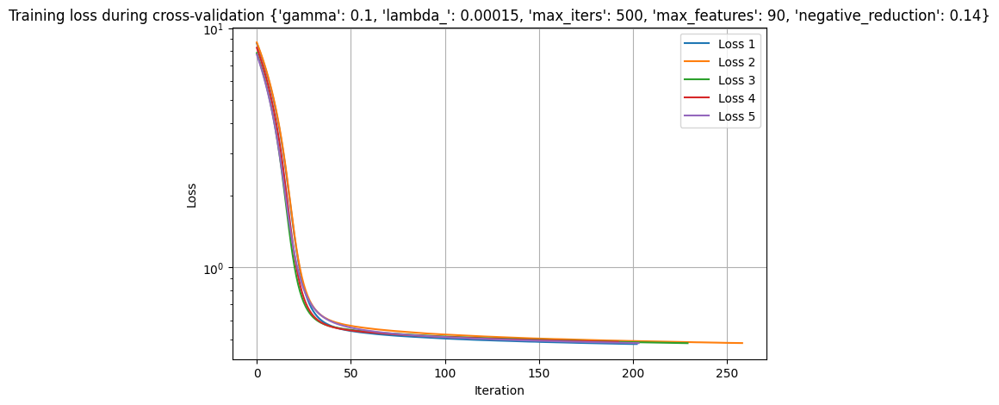

Tuning with args (24/36): {'gamma': 0.1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4833537857615993


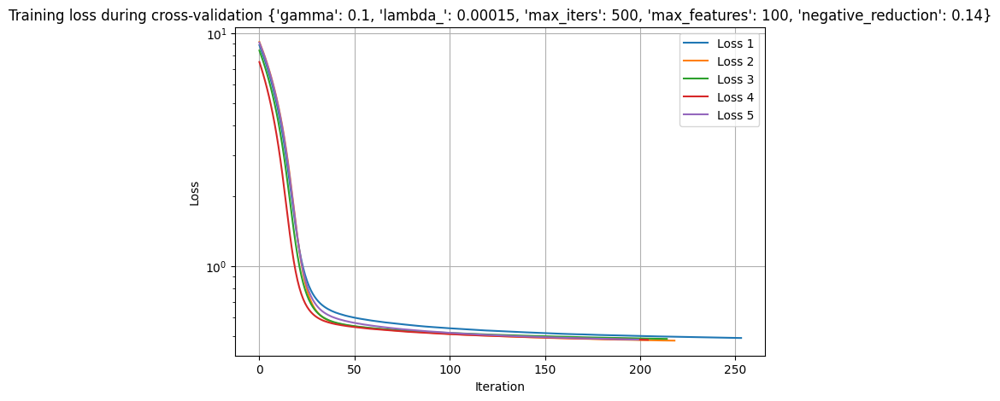

Tuning with args (25/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 5, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.6698005524834066


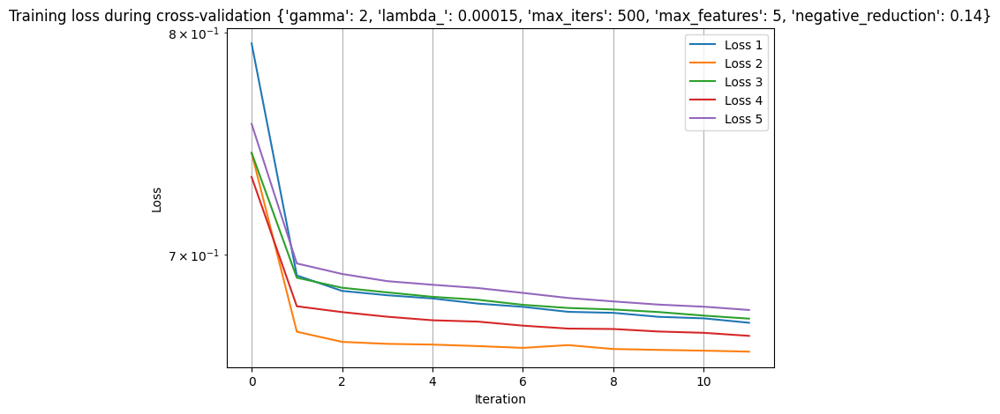

Tuning with args (26/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 10, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5728540287790214


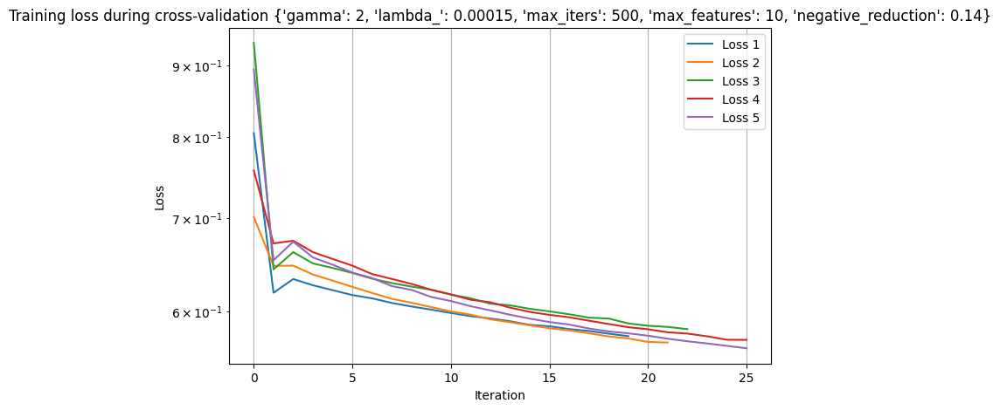

Tuning with args (27/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 15, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4919662191406961


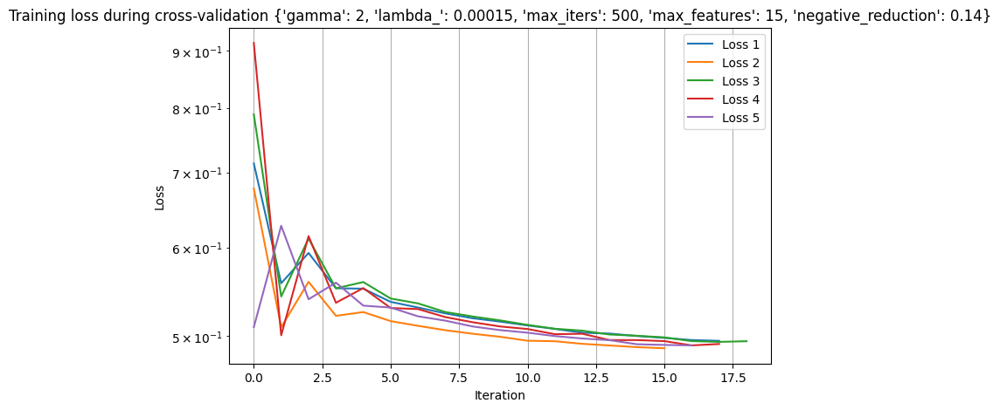

Tuning with args (28/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 20, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5014515575754623


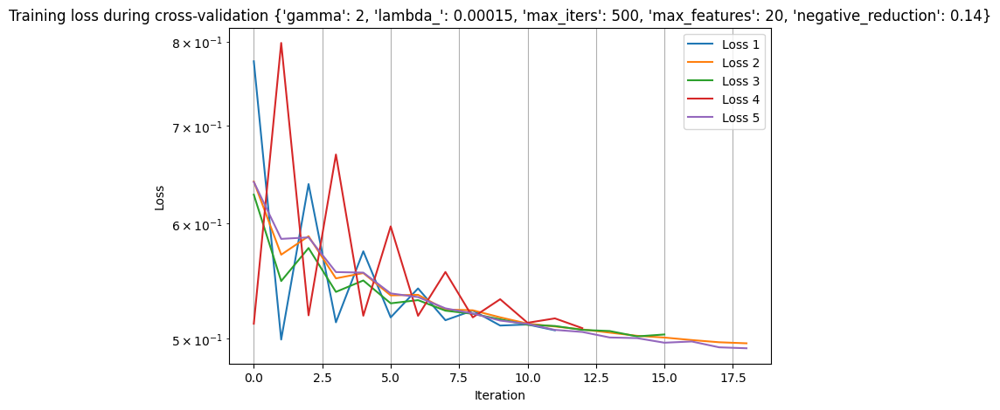

Tuning with args (29/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49315965452695754


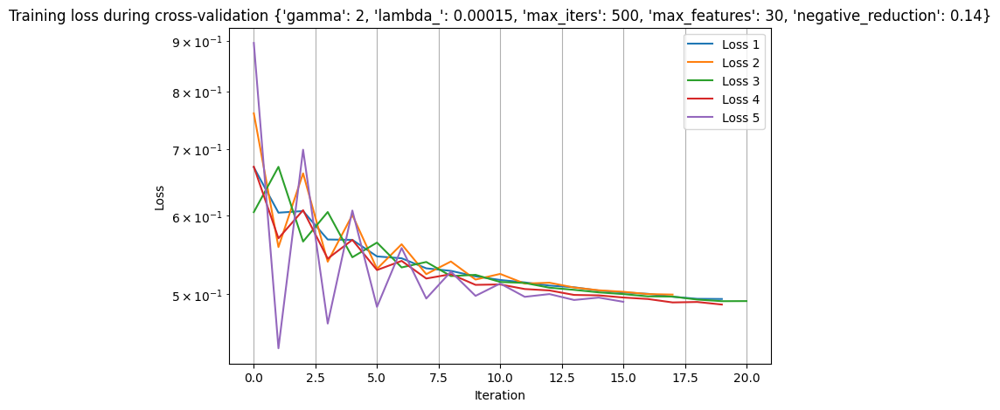

Tuning with args (30/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47821447015315643


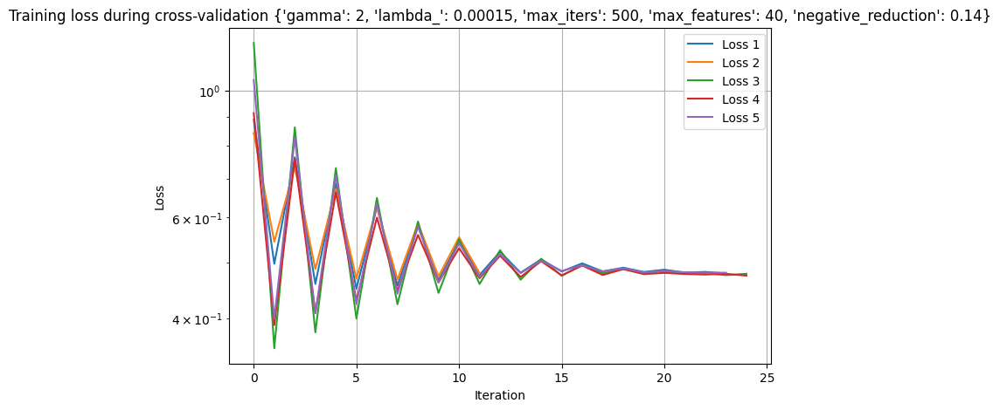

Tuning with args (31/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.40028251028749606


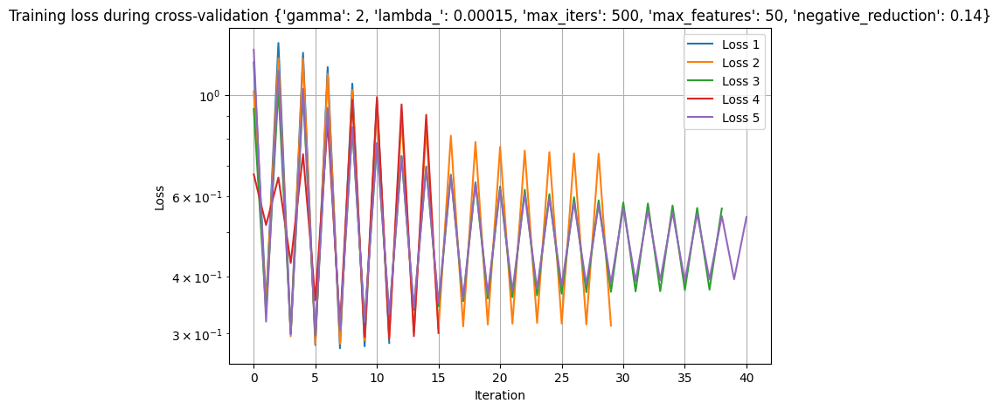

Tuning with args (32/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.26399456824022083


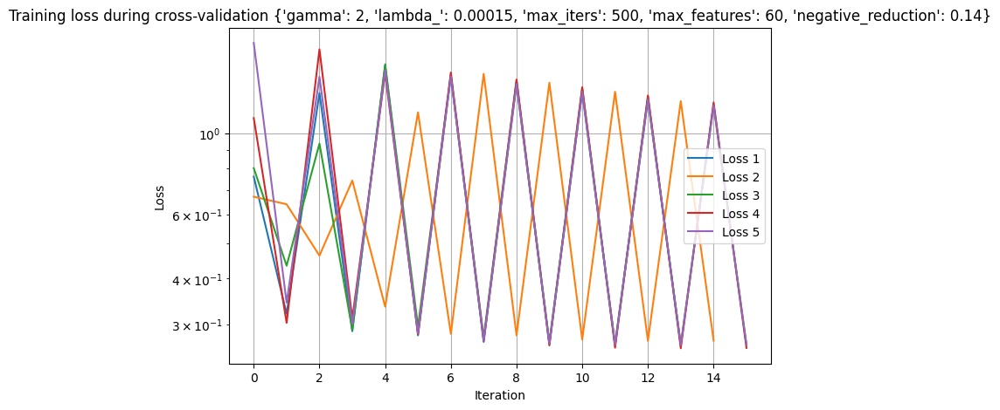

Tuning with args (33/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 70, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.26083896909932003


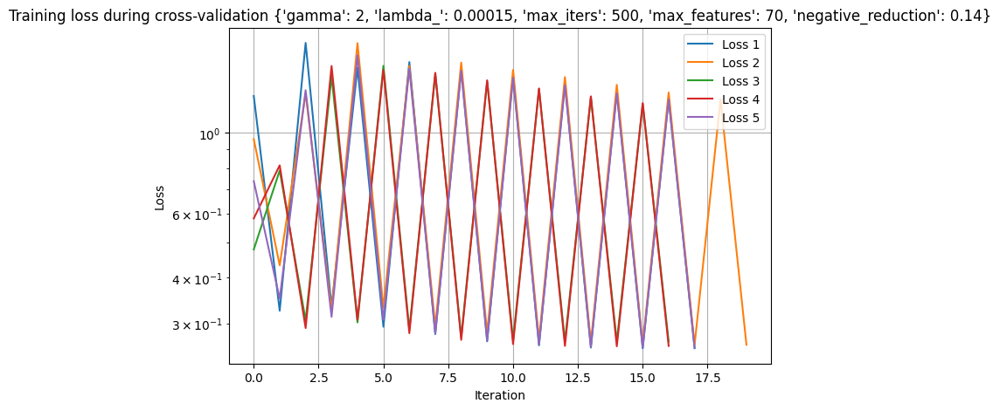

Tuning with args (34/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 80, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5200105593844132


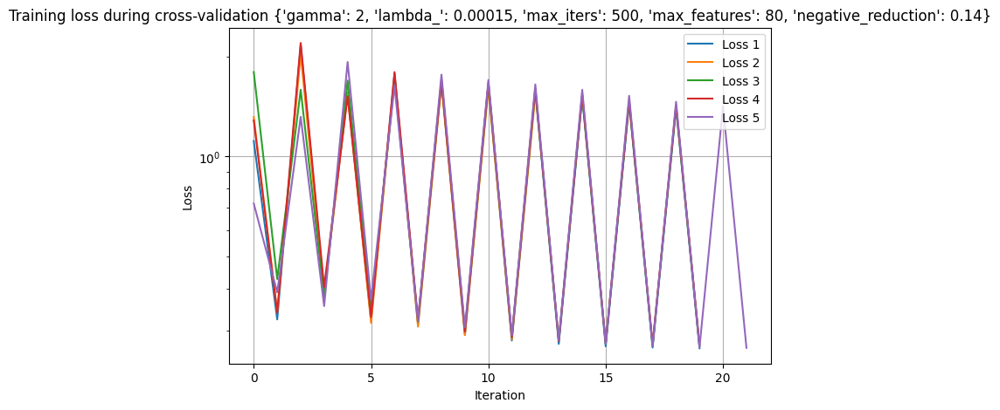

Tuning with args (35/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 90, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5434555380920749


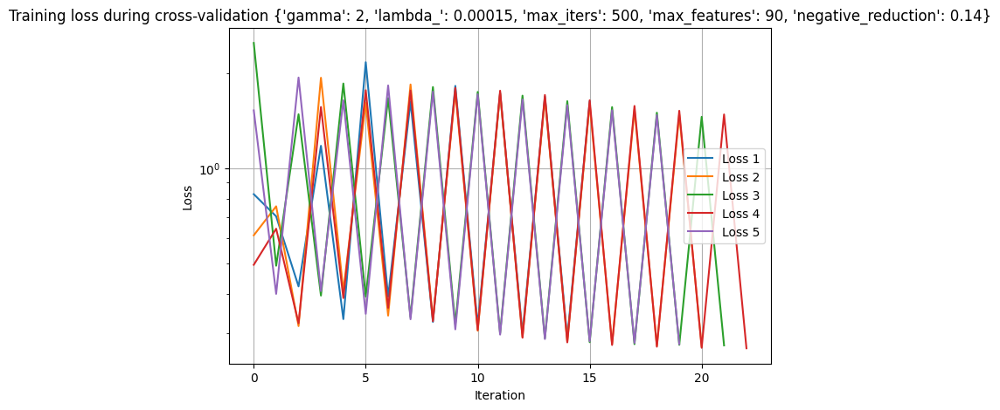

Tuning with args (36/36): {'gamma': 2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 100, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5534097202571878


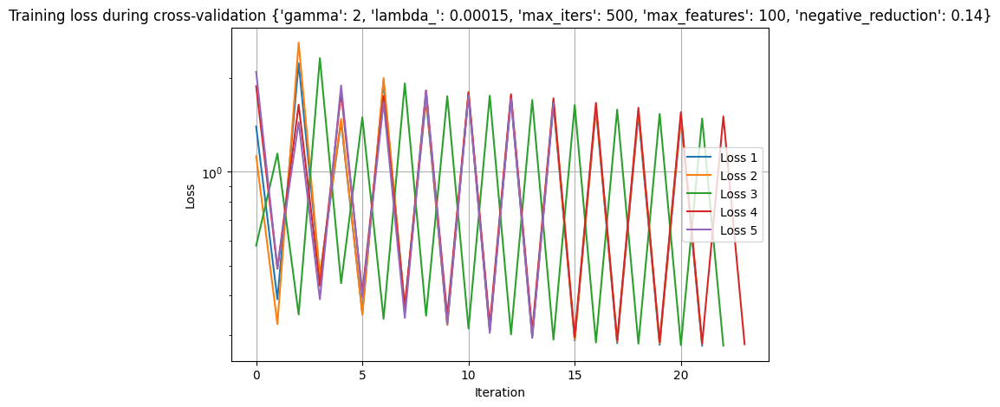

In [38]:
from scripts.models import RegularizedLogisticRegression

args_logreg_balanced_1 = [
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 5,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 10,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 15,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 20,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 70,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 80,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 90,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 100,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 5,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 10,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 15,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 20,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 70,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 80,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 90,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 100,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 5,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 10,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 15,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 20,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 70,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 80,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 90,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 100,
        "negative_reduction": 0.14,
    },
]
validation_logreg_balanced_1, training_logreg_balanced_1 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_balanced_1
)

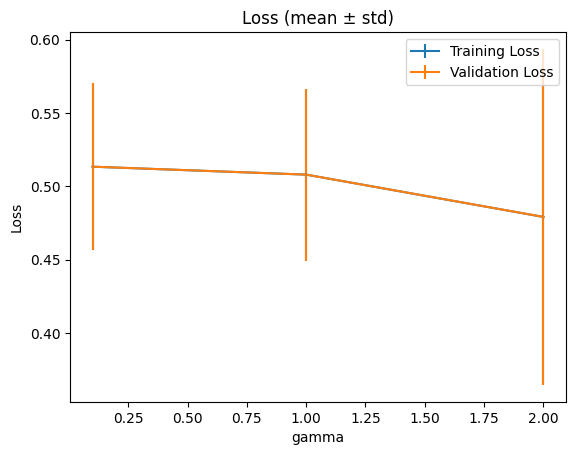


Averaged results:
gamma=0.1 | val=0.5134±0.0567 | train=0.5134±0.0567
gamma=1 | val=0.5080±0.0586 | train=0.5080±0.0586
gamma=2 | val=0.4791±0.1146 | train=0.4791±0.1145


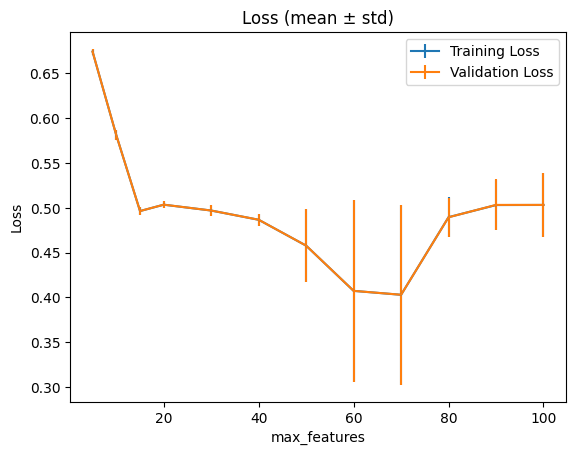


Averaged results:
max_features=5 | val=0.6742±0.0032 | train=0.6742±0.0032
max_features=10 | val=0.5809±0.0058 | train=0.5809±0.0058
max_features=15 | val=0.4963±0.0048 | train=0.4963±0.0048
max_features=20 | val=0.5034±0.0041 | train=0.5034±0.0041
max_features=30 | val=0.4969±0.0061 | train=0.4969±0.0061
max_features=40 | val=0.4866±0.0065 | train=0.4866±0.0065
max_features=50 | val=0.4577±0.0407 | train=0.4577±0.0407
max_features=60 | val=0.4072±0.1013 | train=0.4072±0.1013
max_features=70 | val=0.4029±0.1004 | train=0.4028±0.1004
max_features=80 | val=0.4894±0.0217 | train=0.4895±0.0220
max_features=90 | val=0.5032±0.0285 | train=0.5030±0.0282
max_features=100 | val=0.5032±0.0358 | train=0.5031±0.0357


In [39]:
from scripts.model_utils import show_printing_result_loss

show_printing_result_loss(
    args_logreg_balanced_1,
    validation_logreg_balanced_1,
    training_logreg_balanced_1,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result_loss(
    args_logreg_balanced_1,
    validation_logreg_balanced_1,
    training_logreg_balanced_1,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49452952019505236


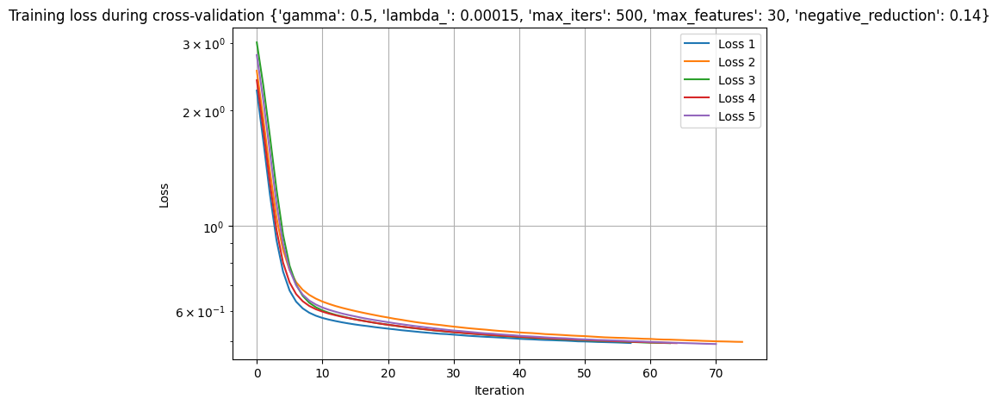

Tuning with args (2/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 35, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4943371696543948


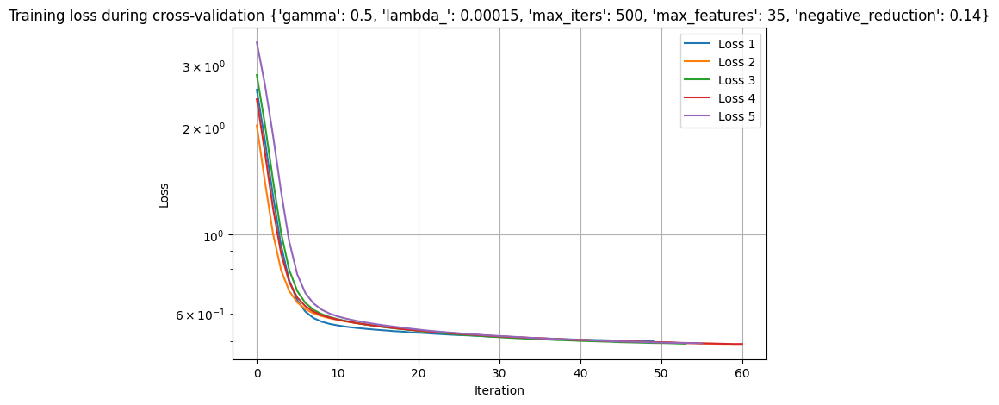

Tuning with args (3/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4927262912387505


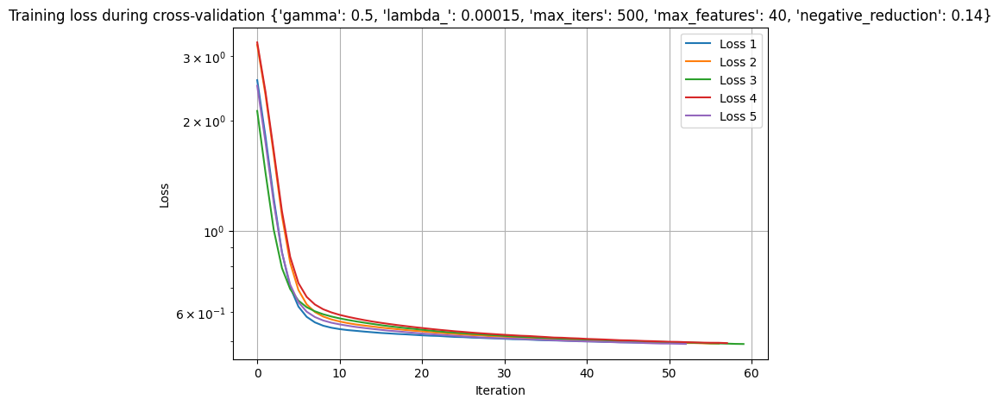

Tuning with args (4/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.485941064416411


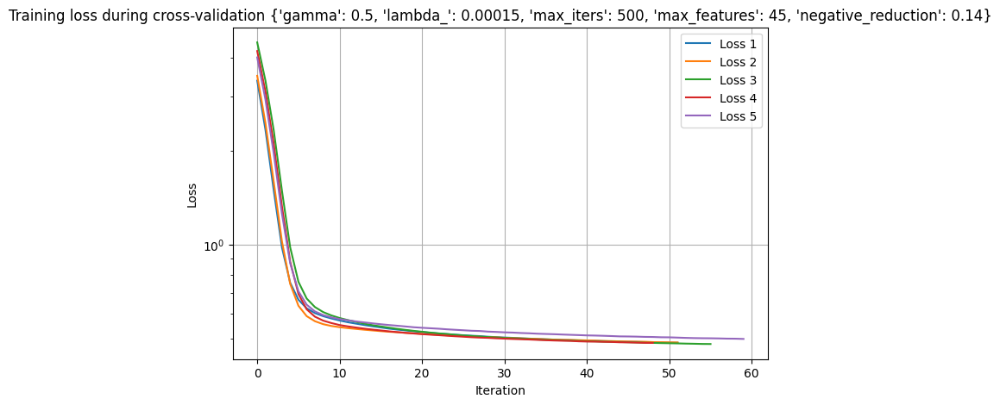

Tuning with args (5/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48534591942937516


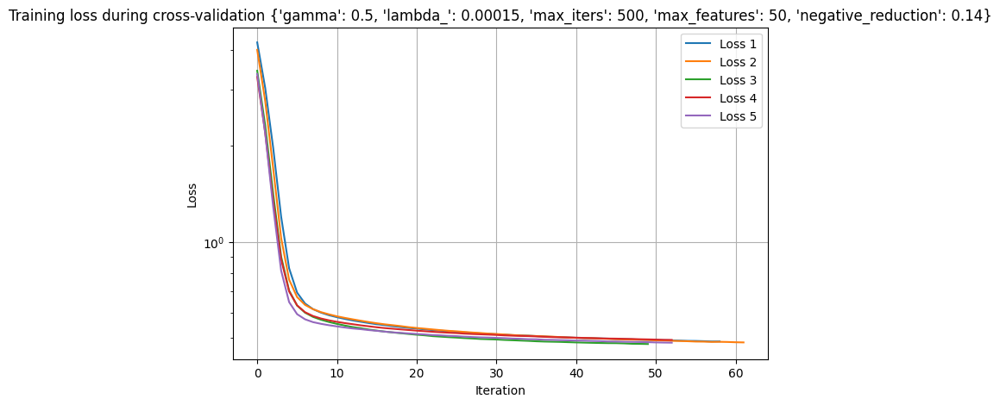

Tuning with args (6/18): {'gamma': 0.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4795420523600466


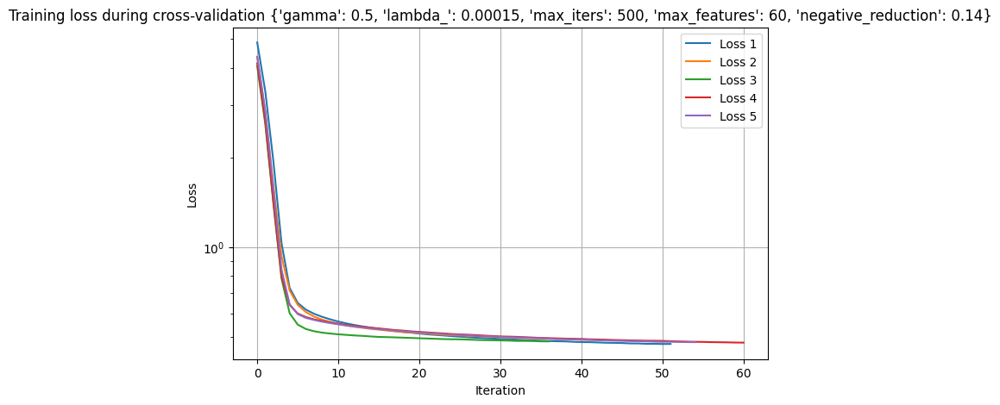

Tuning with args (7/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49579698433416136


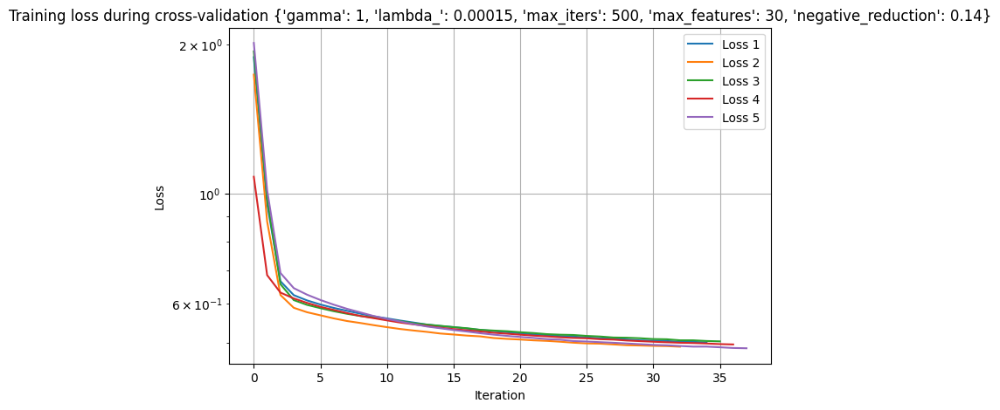

Tuning with args (8/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 35, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49547336729144054


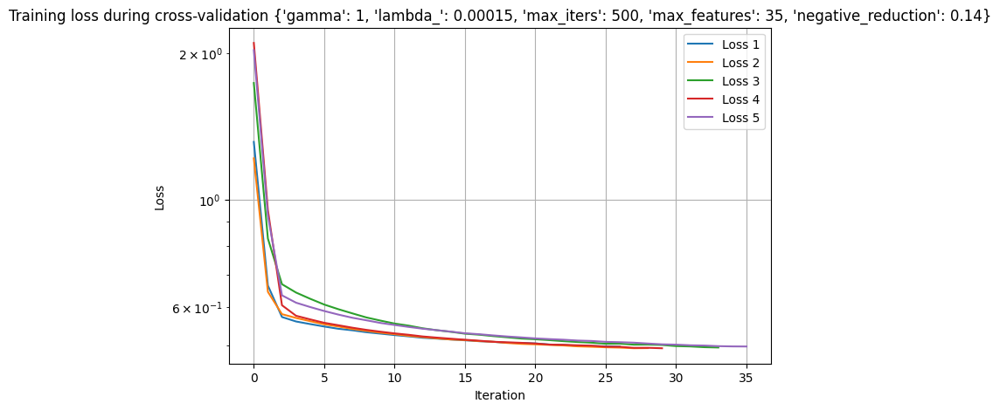

Tuning with args (9/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.490027710862174


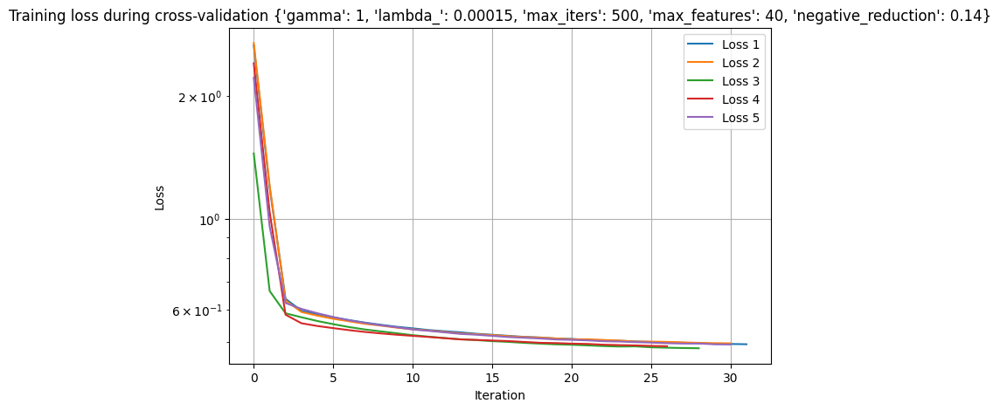

Tuning with args (10/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4822093800455609


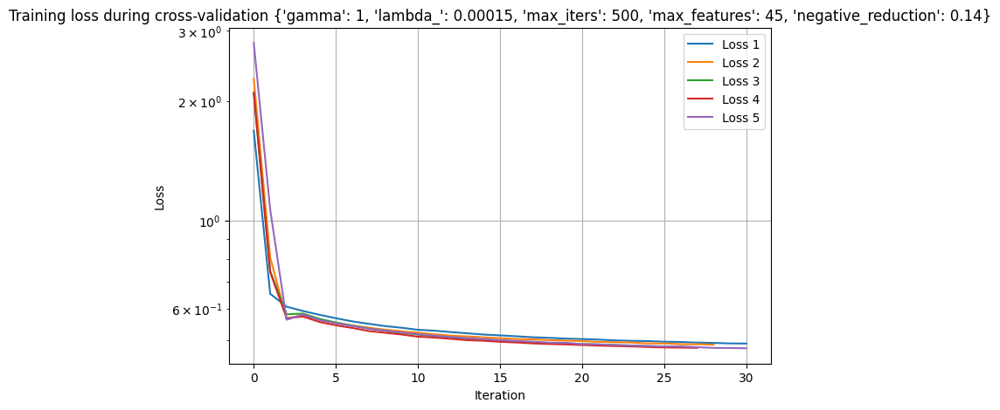

Tuning with args (11/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48249818770640623


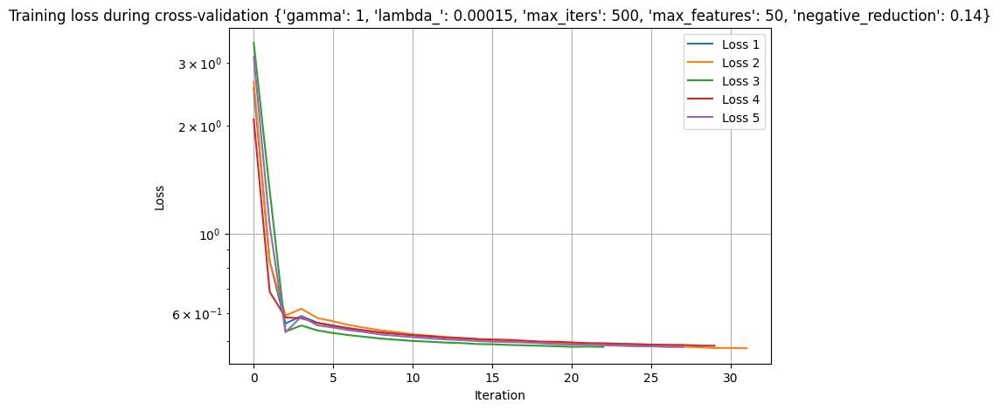

Tuning with args (12/18): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4760373793400892


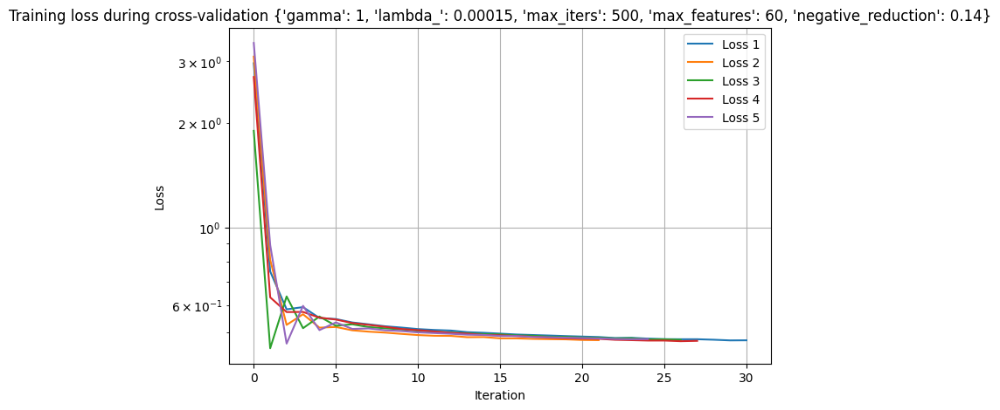

Tuning with args (13/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 30, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4928004017145158


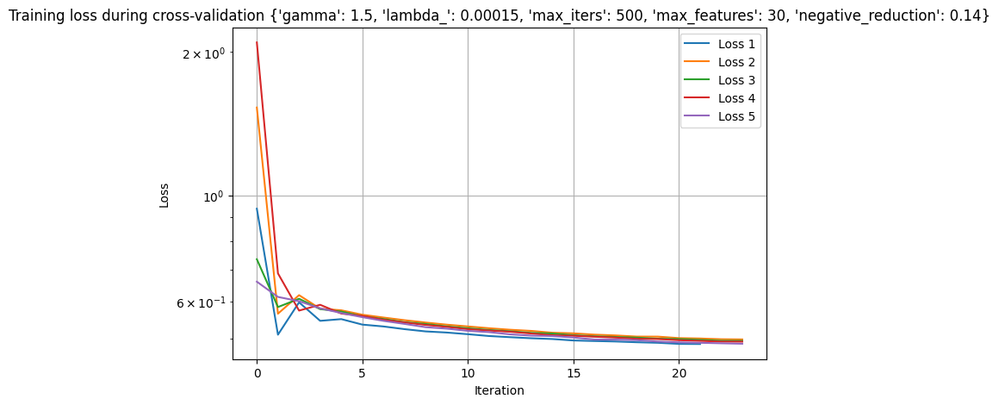

Tuning with args (14/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 35, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4897611633354601


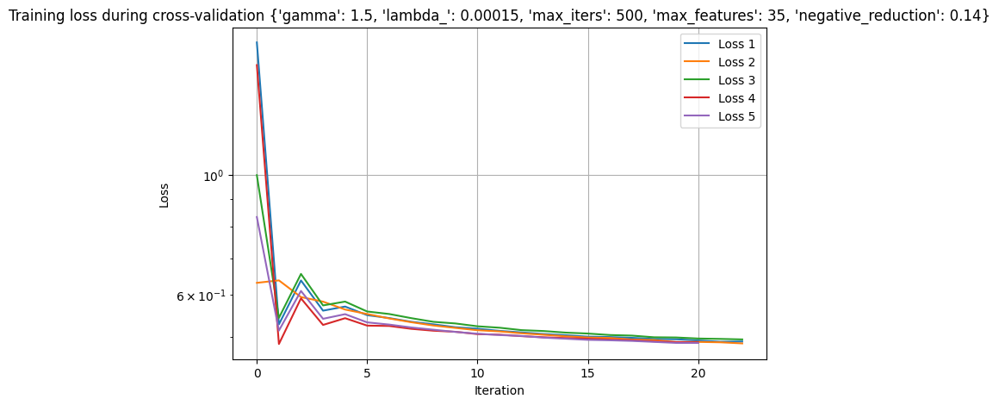

Tuning with args (15/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 40, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4928987439082908


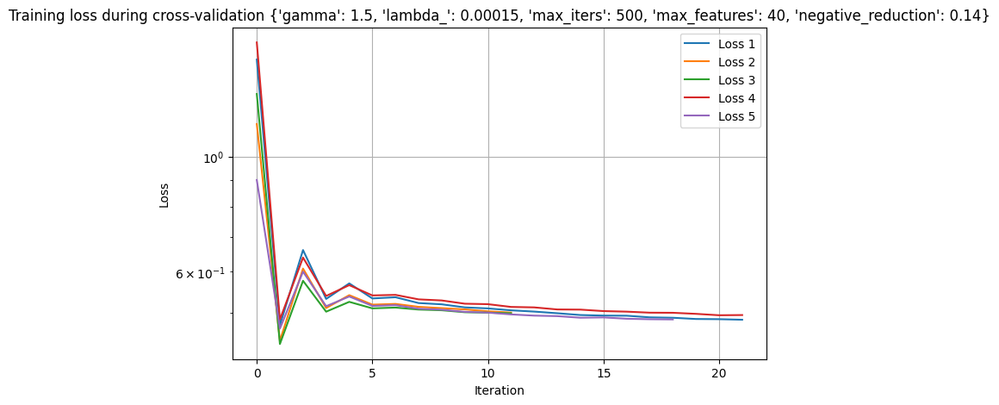

Tuning with args (16/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49292900843843573


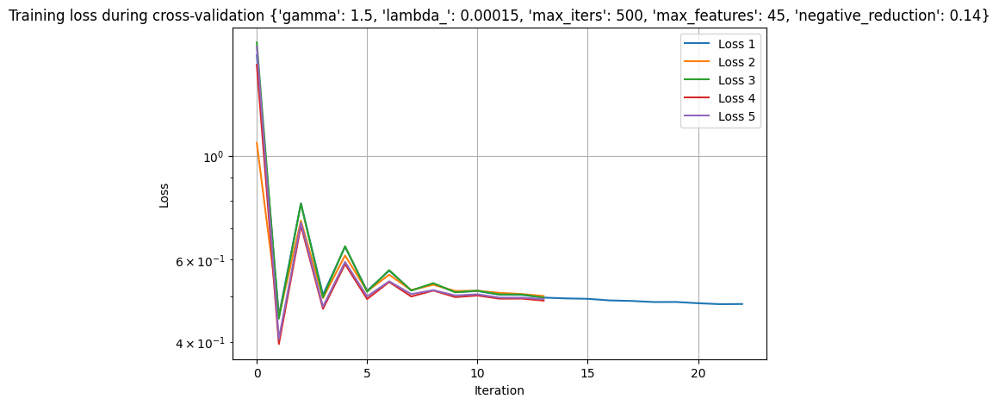

Tuning with args (17/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4807485633707097


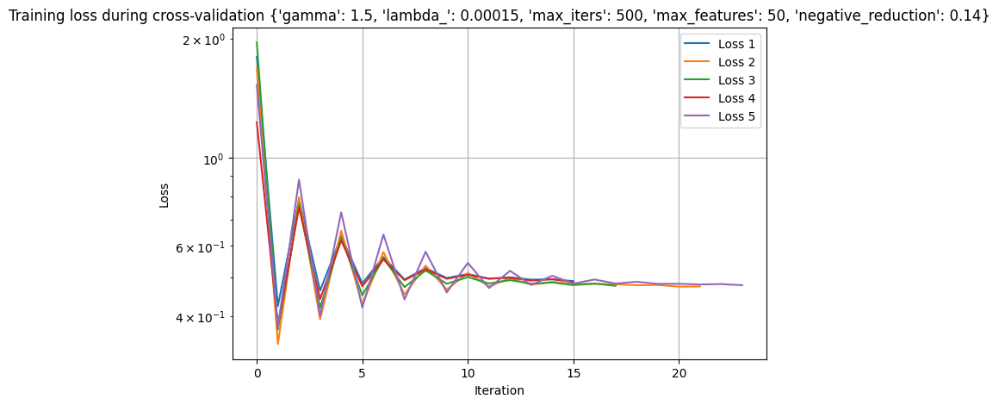

Tuning with args (18/18): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46201343743618467


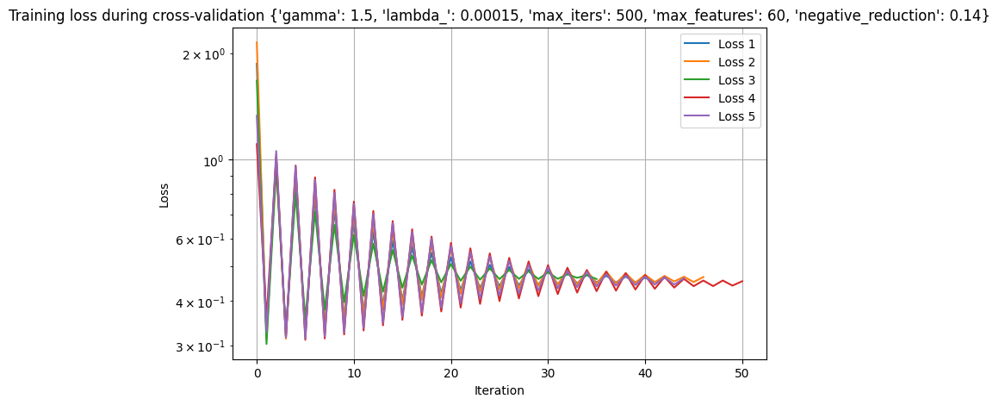

In [40]:
from scripts.models import RegularizedLogisticRegression

args_logreg_balanced_2 = [
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 35,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 35,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 30,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 35,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 40,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
]
validation_logreg_balanced_2, training_logreg_balanced_2 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_balanced_2
)

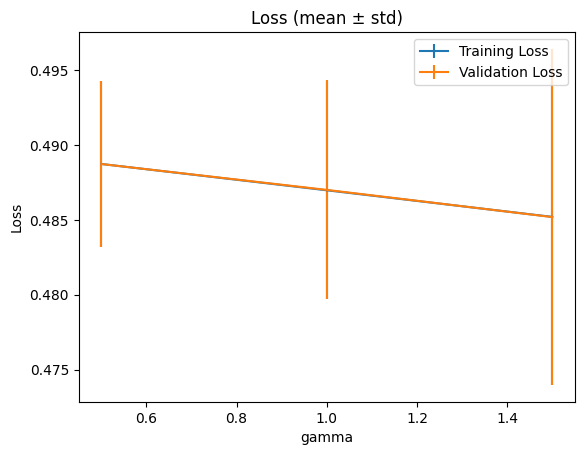


Averaged results:
gamma=0.5 | val=0.4887±0.0055 | train=0.4887±0.0055
gamma=1 | val=0.4870±0.0073 | train=0.4870±0.0073
gamma=1.5 | val=0.4852±0.0112 | train=0.4852±0.0112


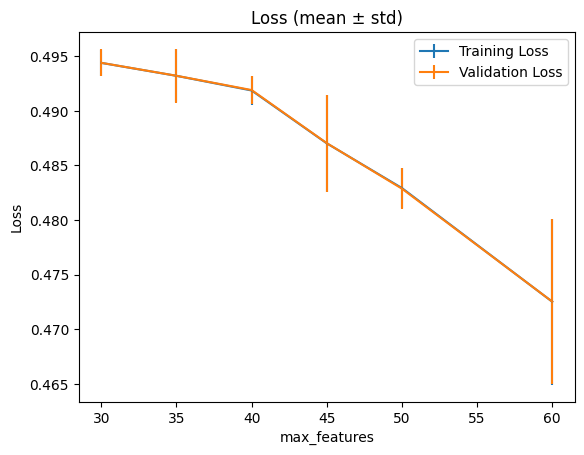


Averaged results:
max_features=30 | val=0.4944±0.0012 | train=0.4944±0.0012
max_features=35 | val=0.4932±0.0025 | train=0.4932±0.0024
max_features=40 | val=0.4919±0.0013 | train=0.4918±0.0013
max_features=45 | val=0.4870±0.0044 | train=0.4870±0.0044
max_features=50 | val=0.4829±0.0019 | train=0.4829±0.0019
max_features=60 | val=0.4725±0.0076 | train=0.4725±0.0076


In [41]:
show_printing_result_loss(
    args_logreg_balanced_2,
    validation_logreg_balanced_2,
    training_logreg_balanced_2,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result_loss(
    args_logreg_balanced_2,
    validation_logreg_balanced_2,
    training_logreg_balanced_2,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48245270392224804


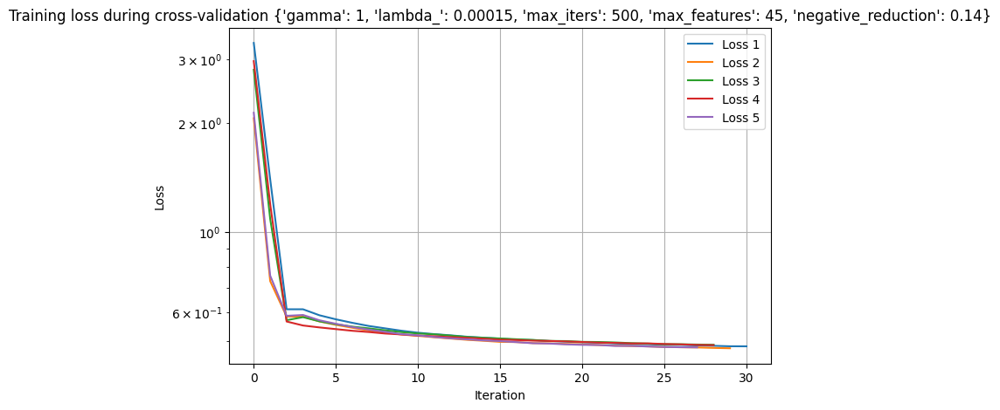

Tuning with args (2/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 46, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48263032742363493


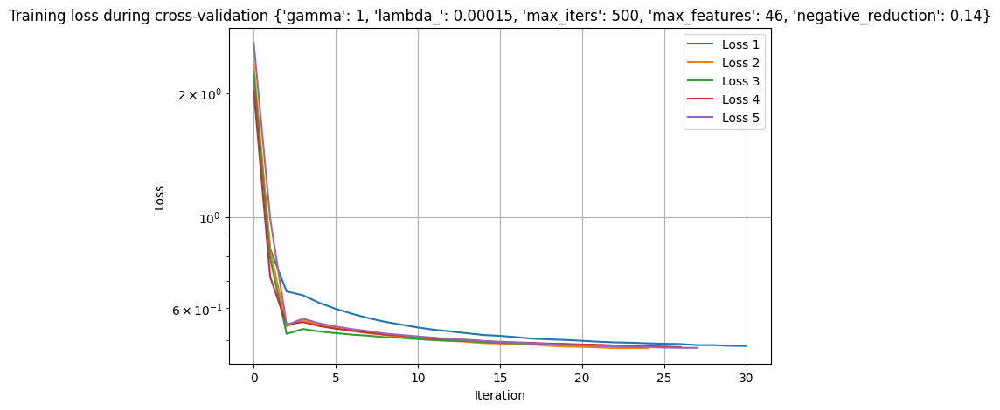

Tuning with args (3/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 47, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.486171555883649


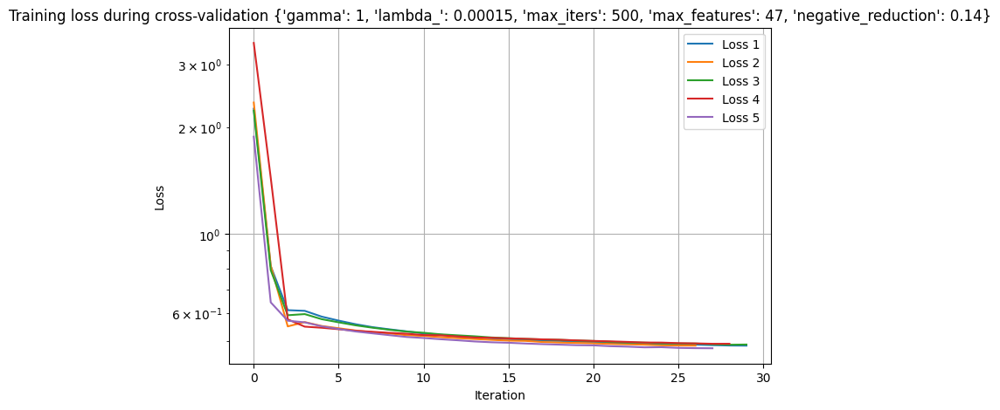

Tuning with args (4/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4867356376991106


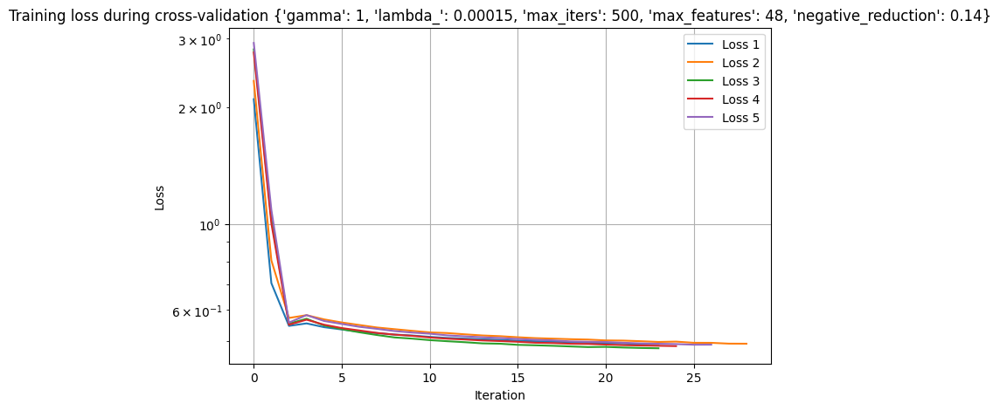

Tuning with args (5/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 49, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4827801895947214


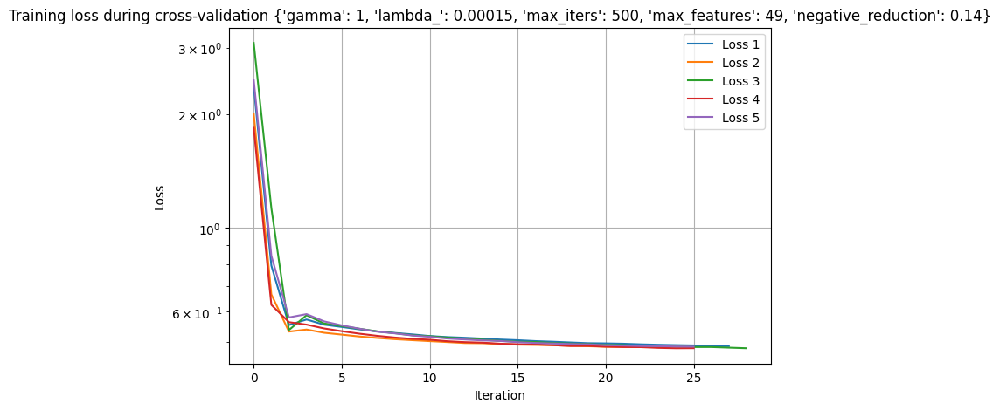

Tuning with args (6/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48151536820173535


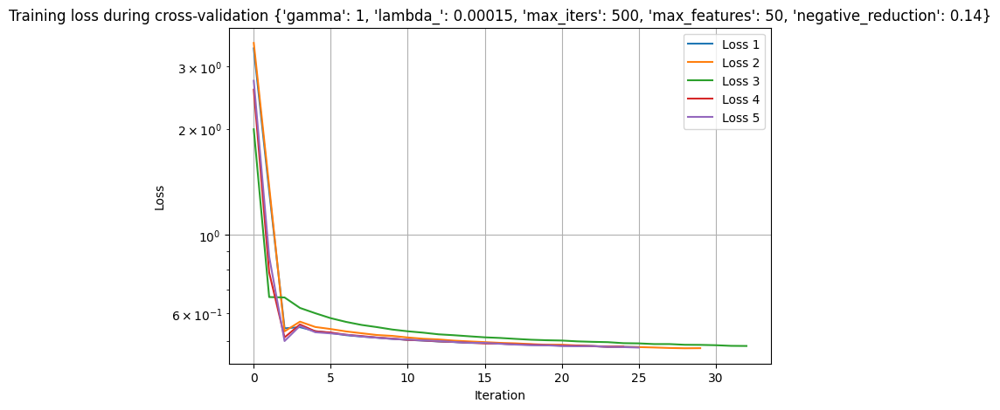

Tuning with args (7/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 51, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48435596934214775


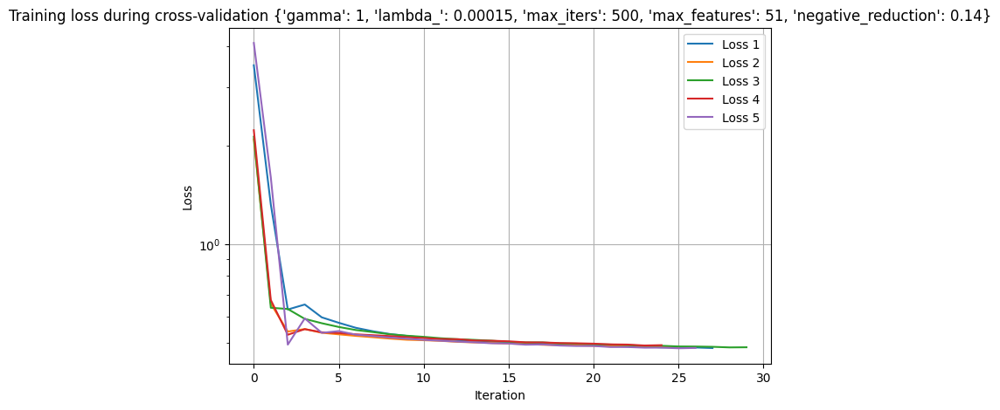

Tuning with args (8/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47951377557257924


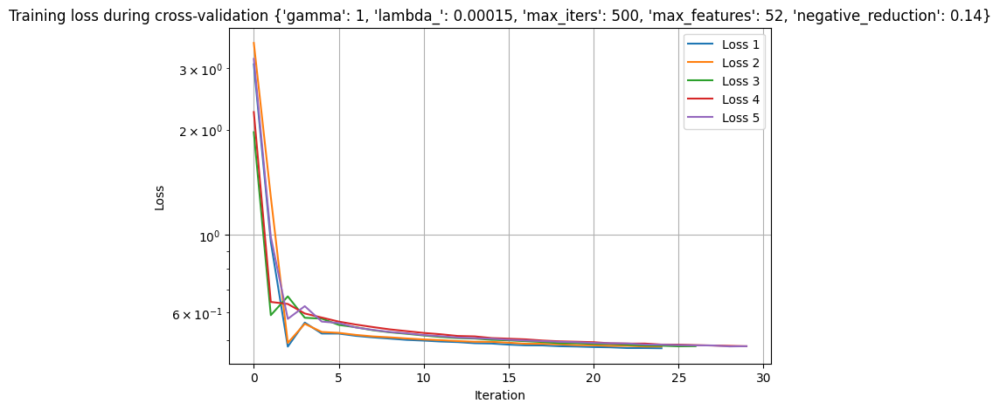

Tuning with args (9/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4770034698216863


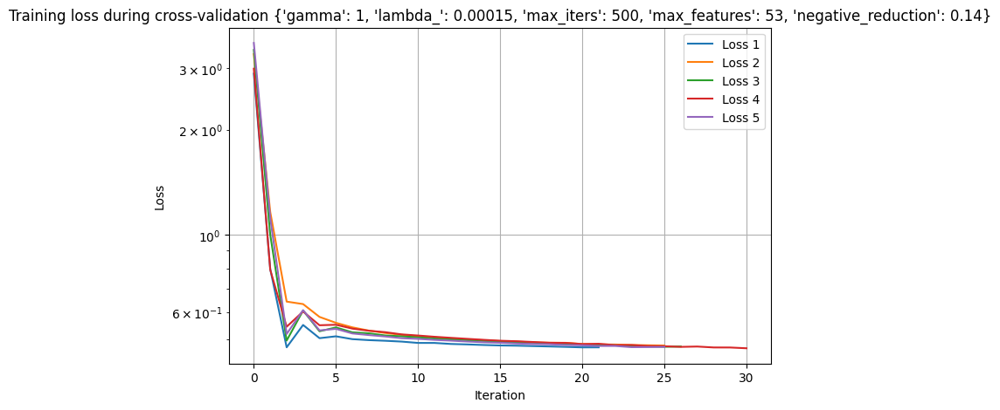

Tuning with args (10/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47857933218051996


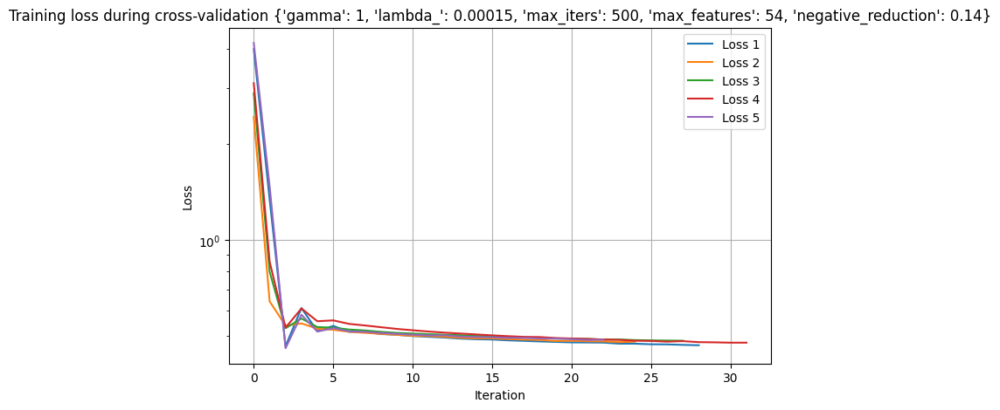

Tuning with args (11/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4775613396737272


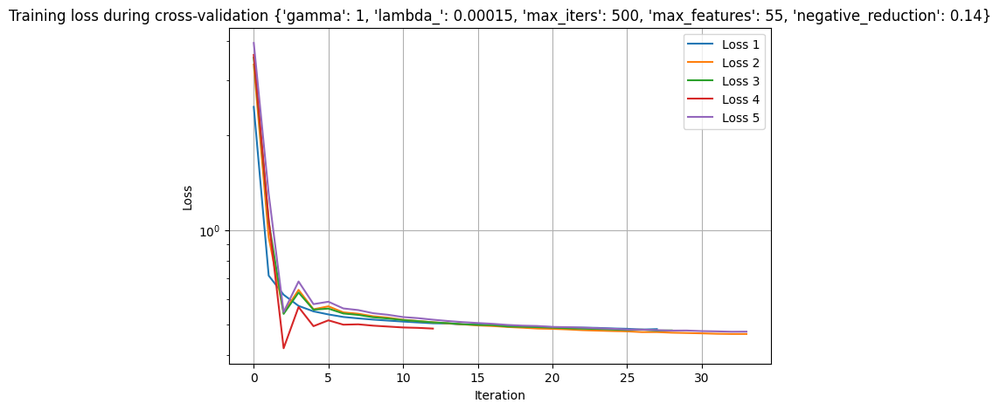

Tuning with args (12/36): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4808556640088823


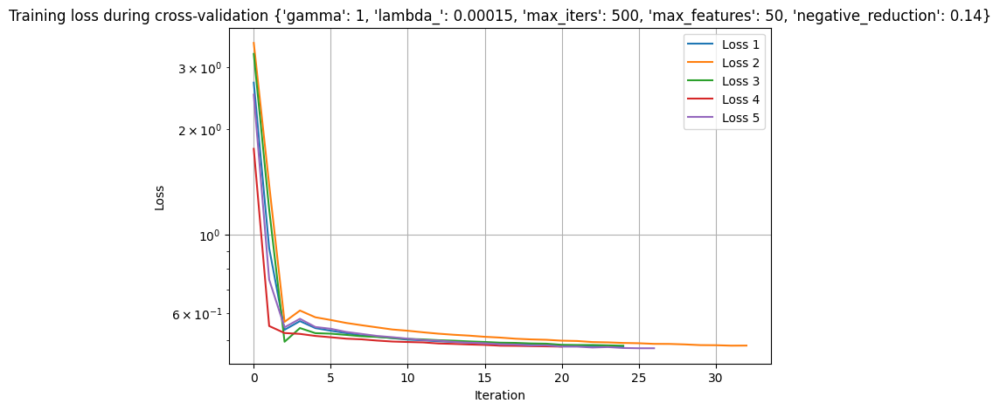

Tuning with args (13/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4829200831733025


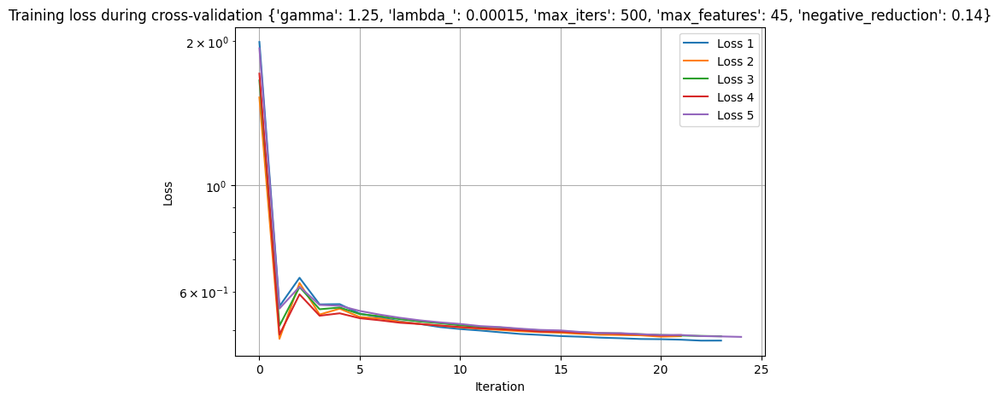

Tuning with args (14/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 46, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48416783514714556


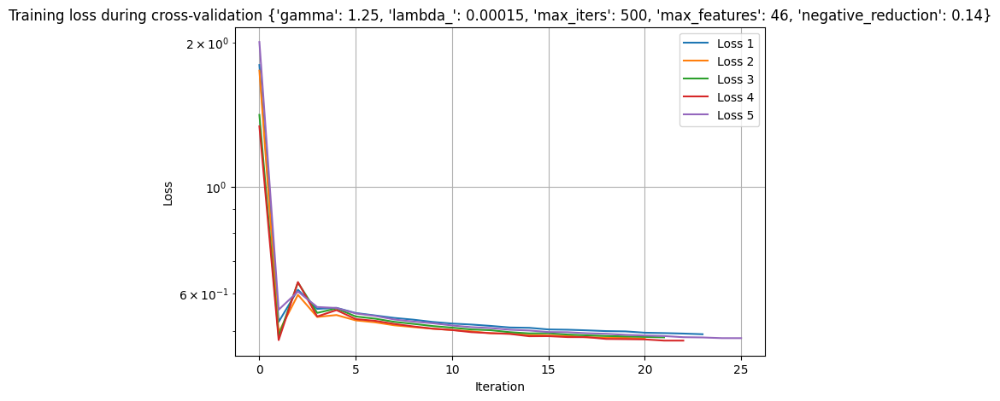

Tuning with args (15/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 47, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48418907143713774


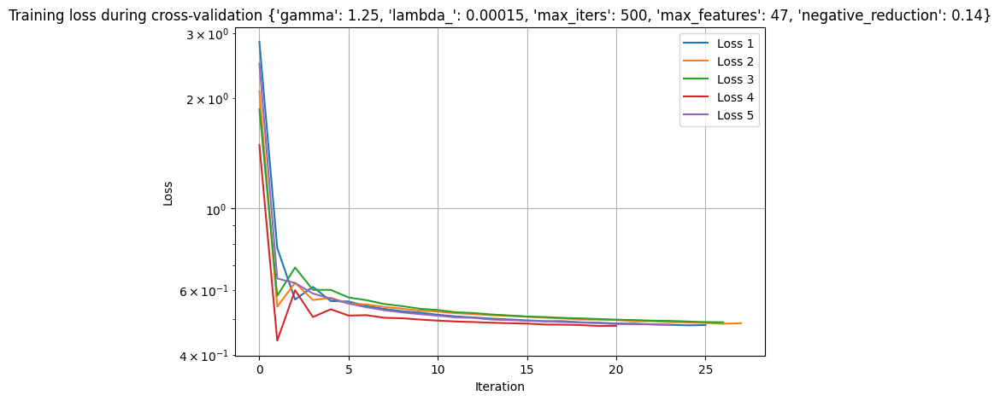

Tuning with args (16/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4854367171515719


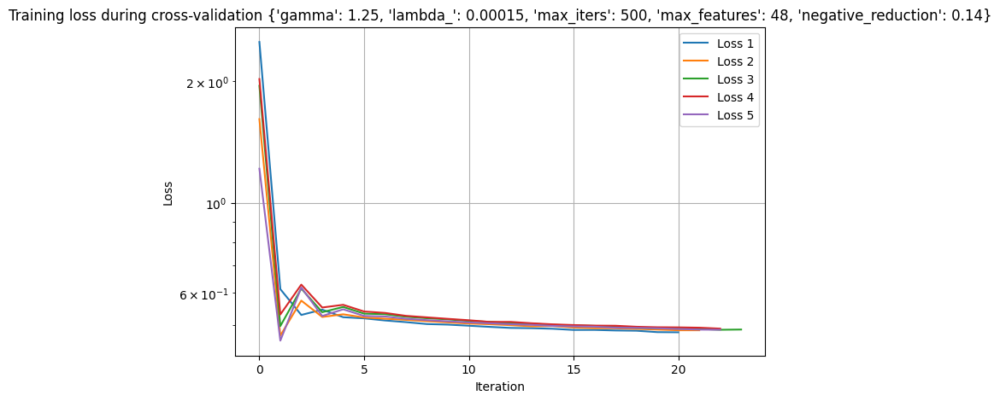

Tuning with args (17/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 49, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48190783576226187


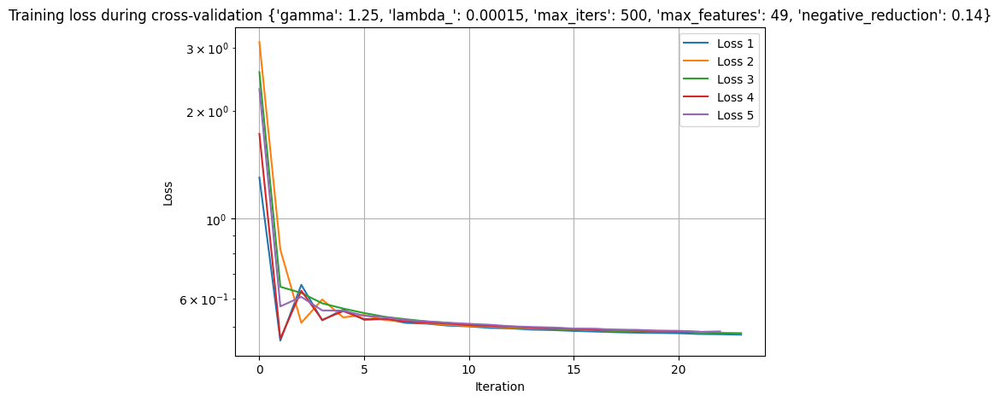

Tuning with args (18/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4829112493451171


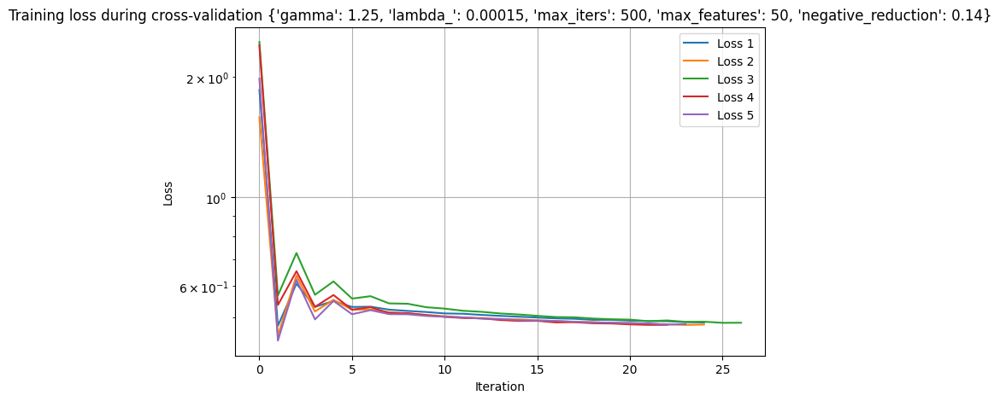

Tuning with args (19/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 51, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48057179069286693


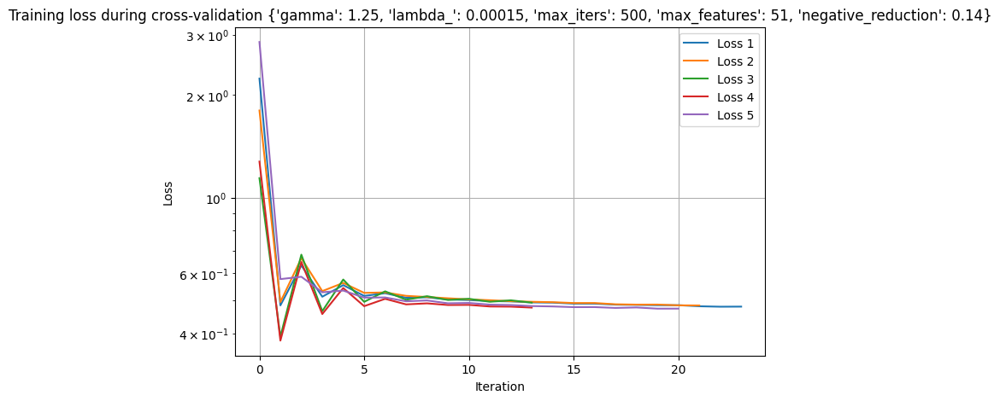

Tuning with args (20/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49050440800291917


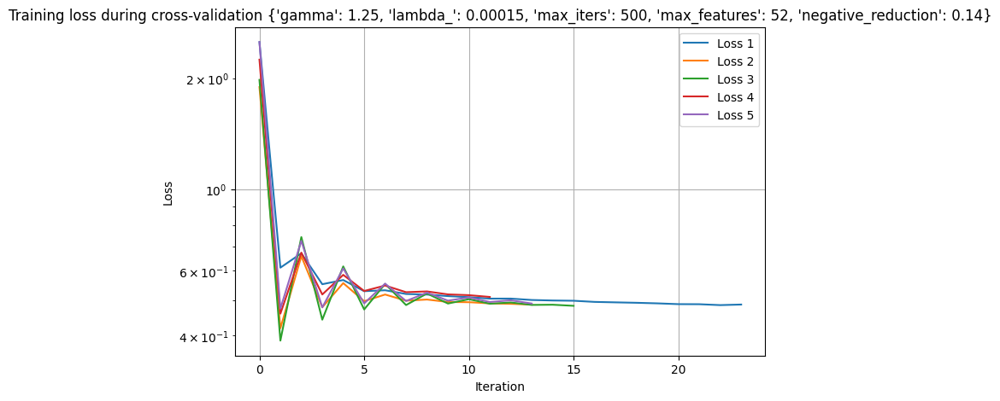

Tuning with args (21/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4847132644753466


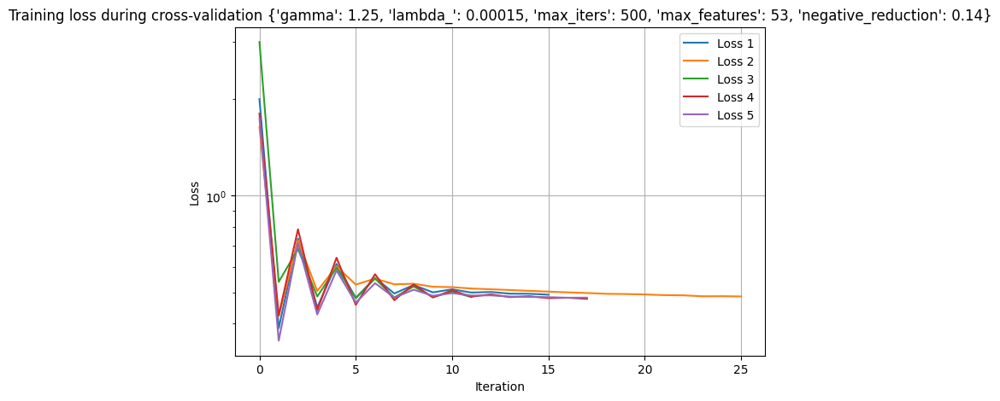

Tuning with args (22/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49373794110259545


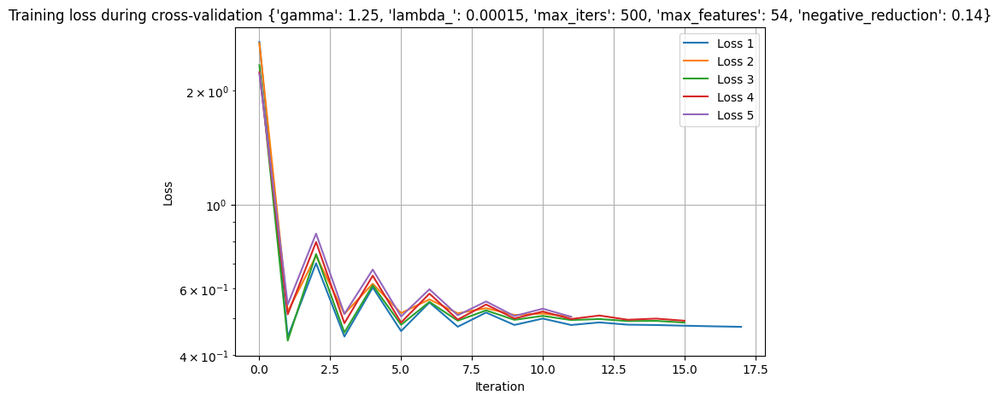

Tuning with args (23/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4755536736976397


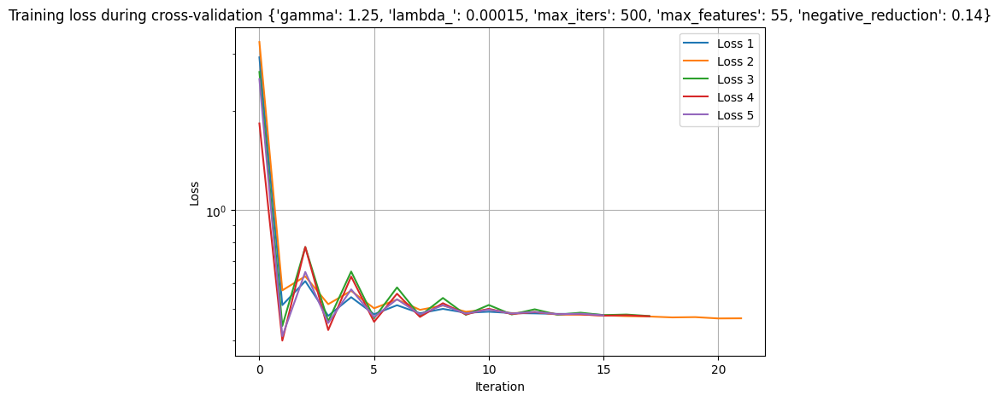

Tuning with args (24/36): {'gamma': 1.25, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4852433076896558


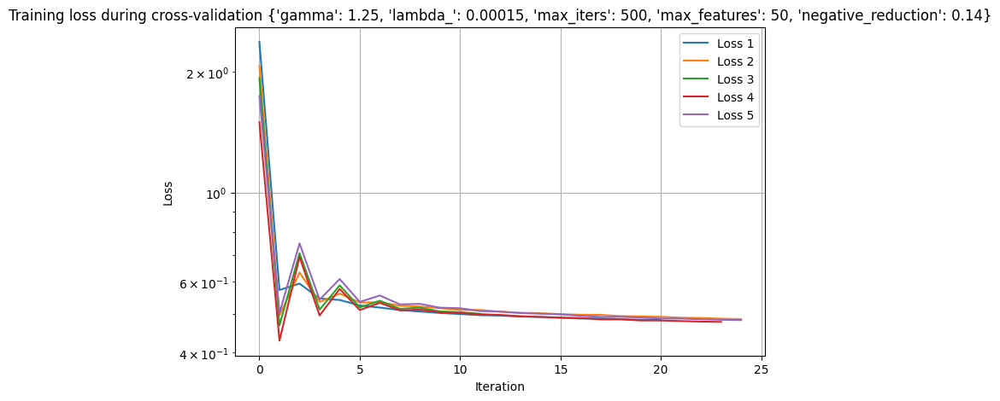

Tuning with args (25/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 45, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48493991098294353


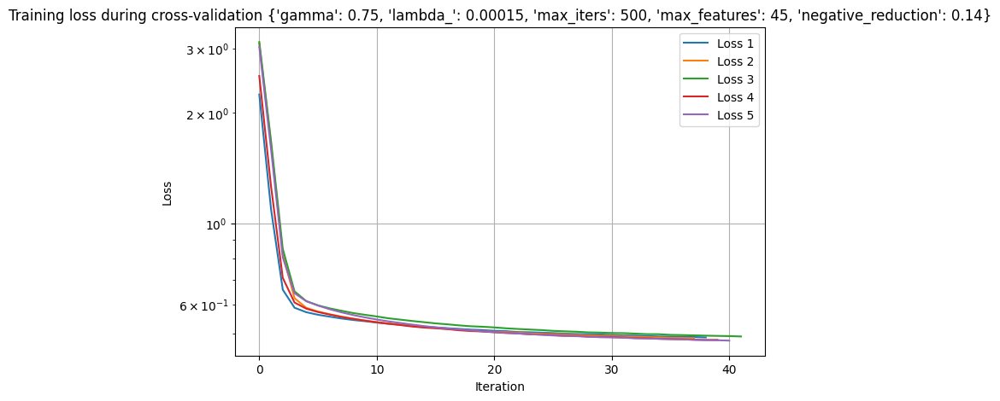

Tuning with args (26/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 46, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4857820115319571


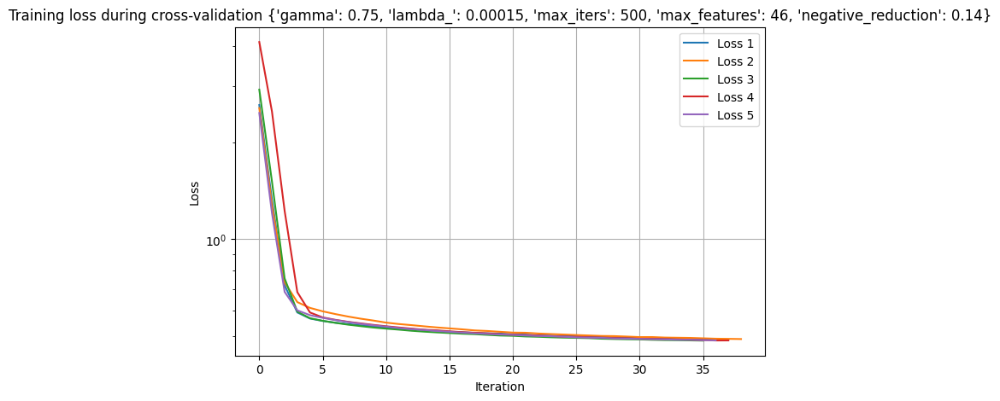

Tuning with args (27/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 47, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48806309516960555


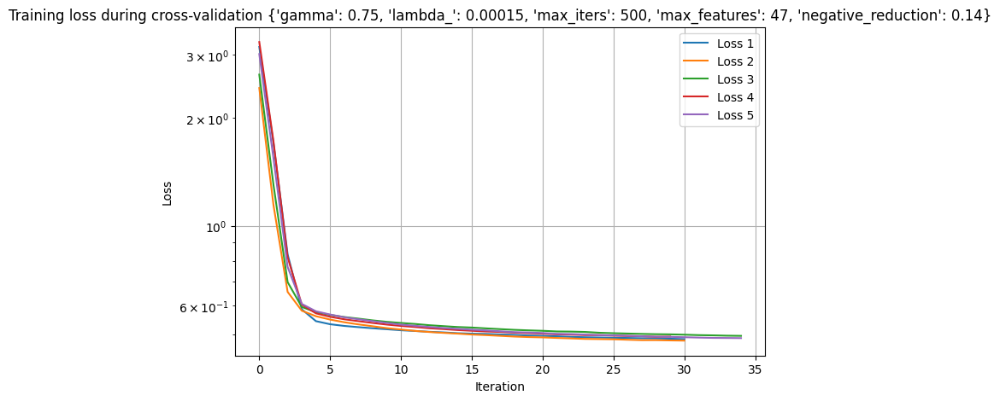

Tuning with args (28/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48658322654410247


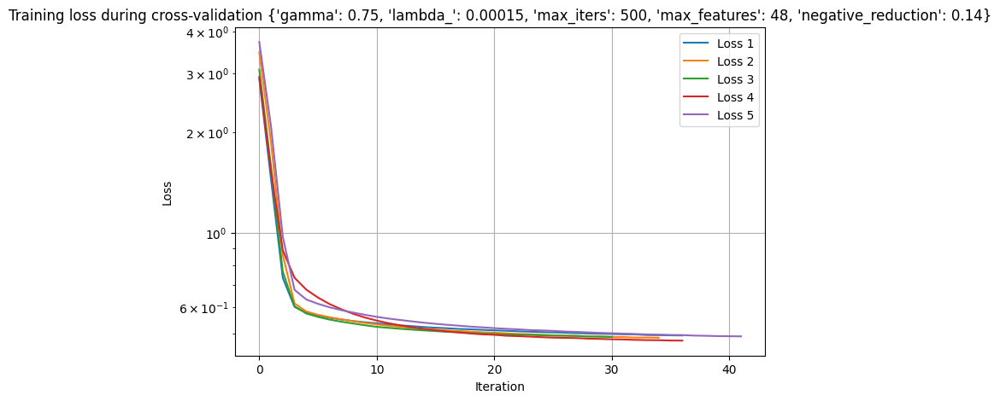

Tuning with args (29/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 49, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4871824473528942


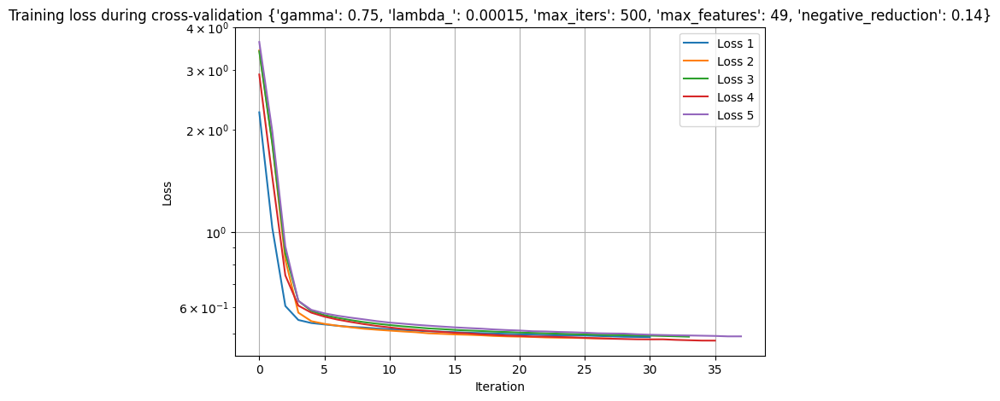

Tuning with args (30/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4824499601785022


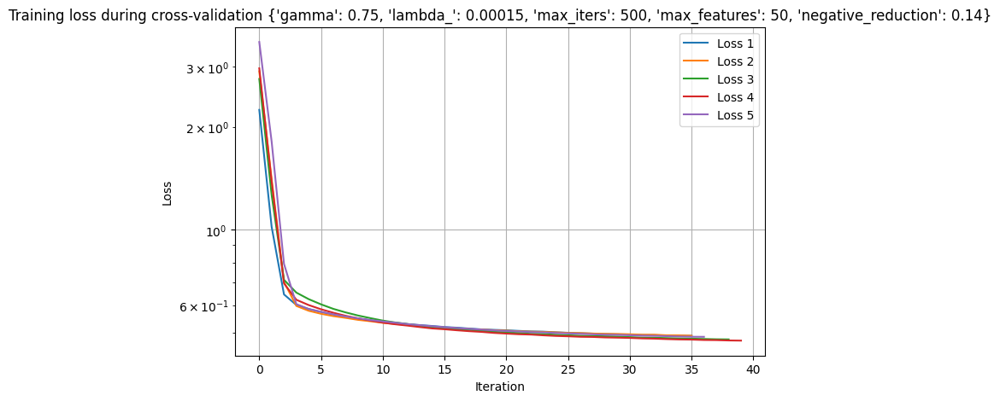

Tuning with args (31/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 51, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.481068097073981


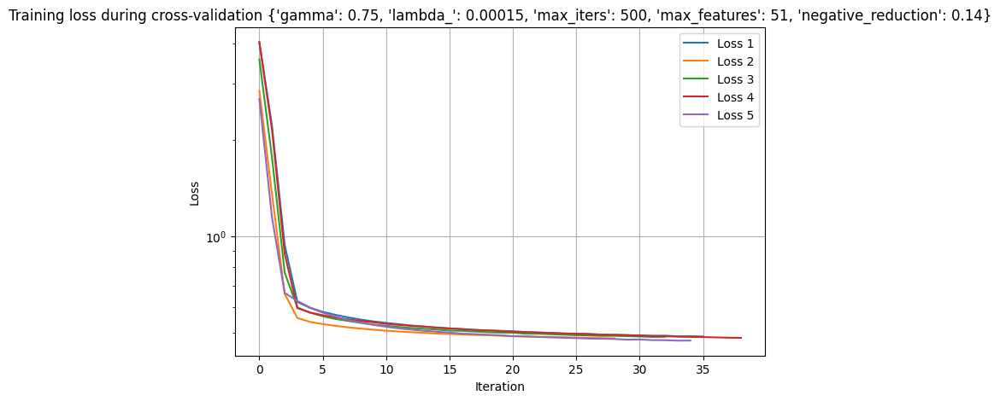

Tuning with args (32/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47900878129706836


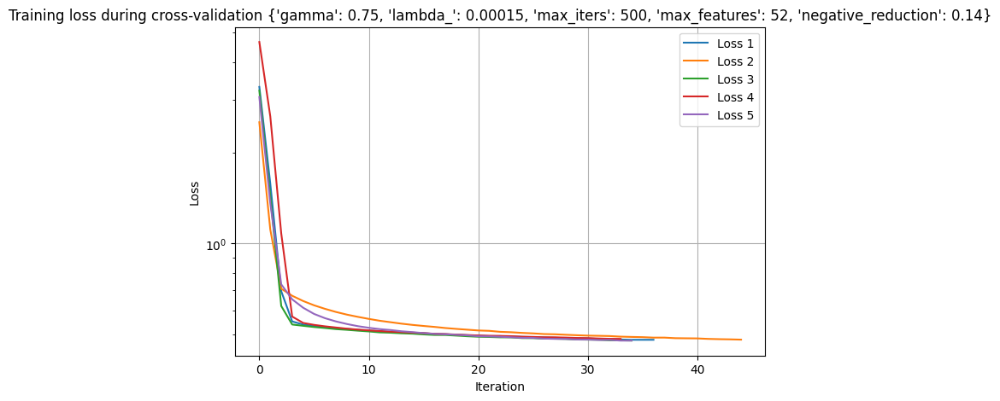

Tuning with args (33/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48026370138662494


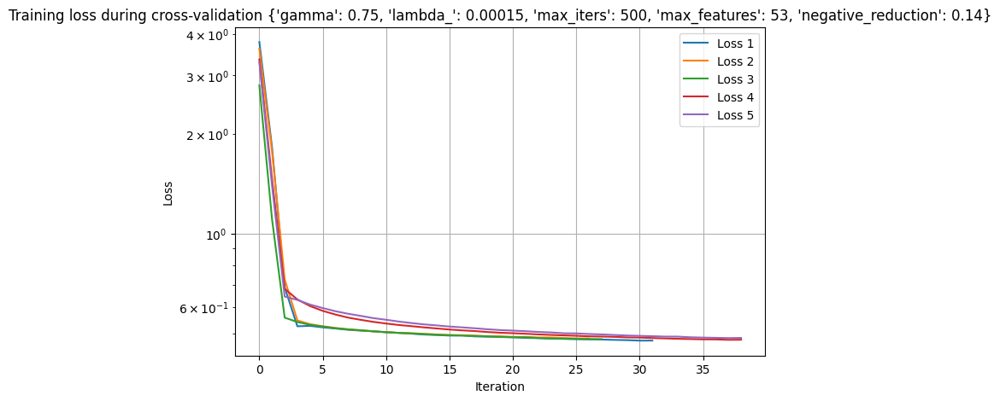

Tuning with args (34/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4779653698896123


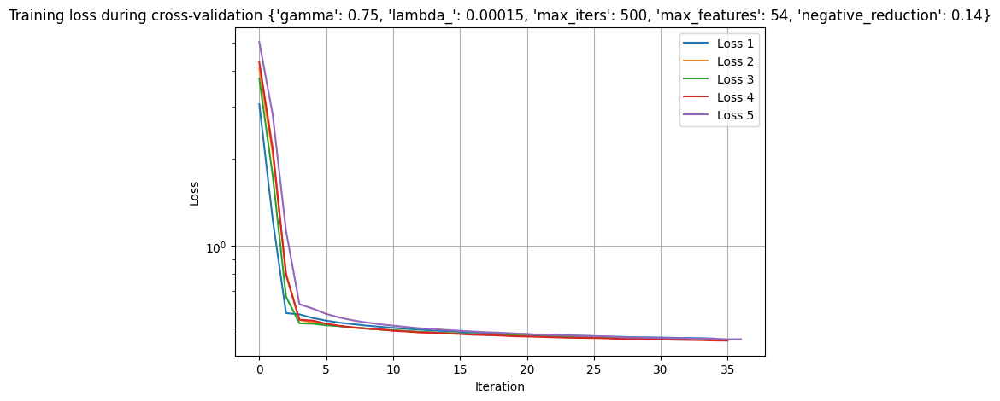

Tuning with args (35/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4751698149781742


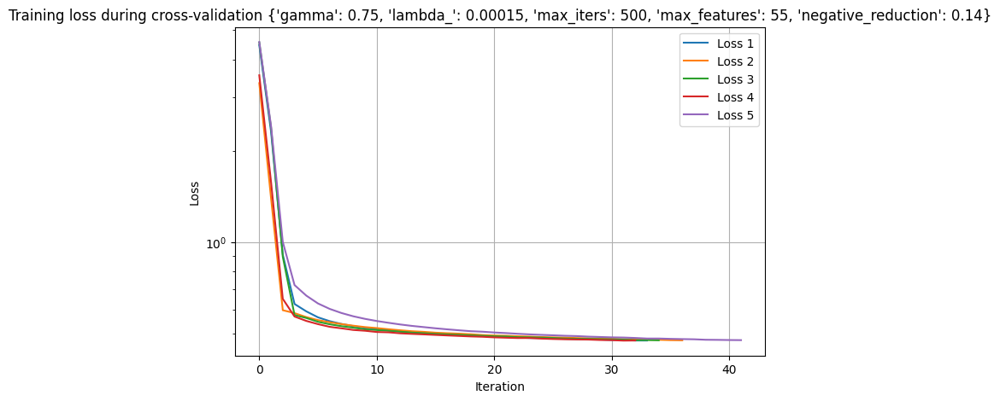

Tuning with args (36/36): {'gamma': 0.75, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48102616896222206


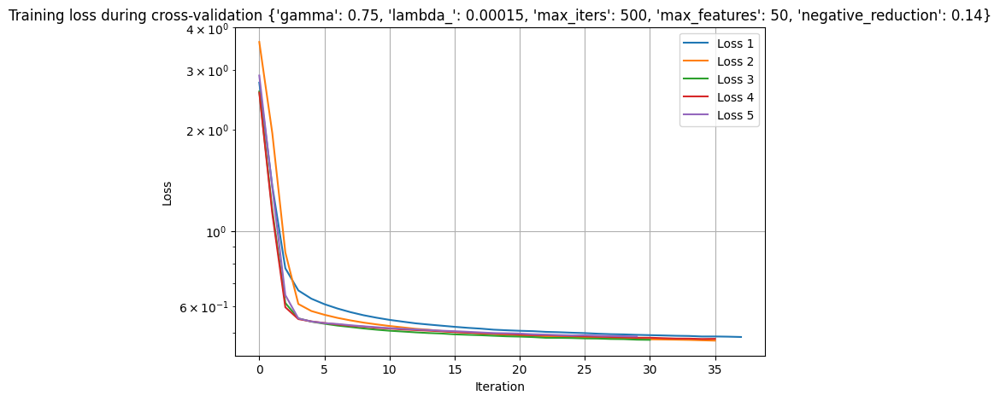

In [42]:
args_logreg_balanced_3 = [
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 46,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 47,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 49,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 51,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 46,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 47,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 49,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 51,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.25,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 45,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 46,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 47,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 49,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 51,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 0.75,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
]
validation_logreg_balanced_3, training_logreg_balanced_3 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_balanced_3
)

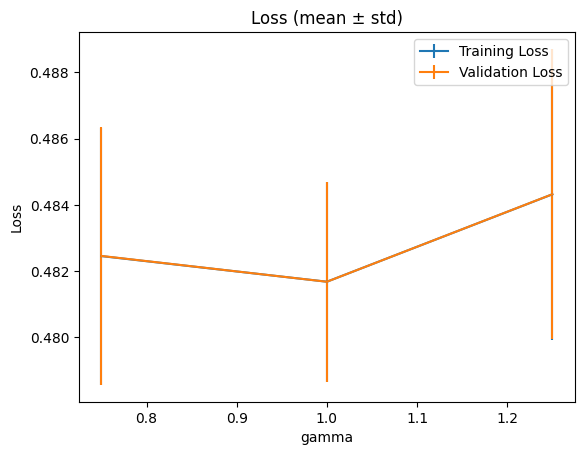


Averaged results:
gamma=0.75 | val=0.4825±0.0039 | train=0.4825±0.0039
gamma=1 | val=0.4817±0.0030 | train=0.4817±0.0030
gamma=1.25 | val=0.4843±0.0044 | train=0.4843±0.0044


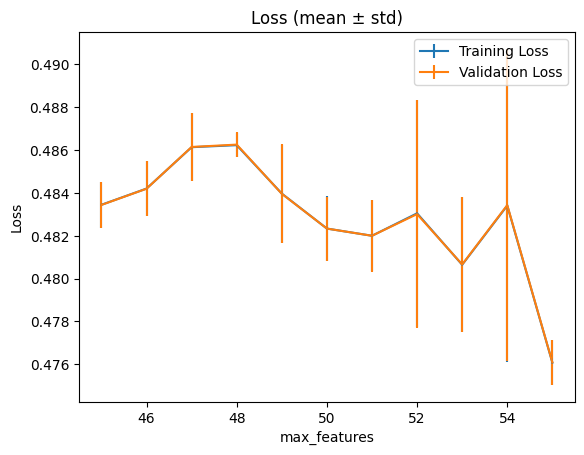


Averaged results:
max_features=45 | val=0.4834±0.0011 | train=0.4834±0.0011
max_features=46 | val=0.4842±0.0013 | train=0.4842±0.0013
max_features=47 | val=0.4861±0.0016 | train=0.4861±0.0016
max_features=48 | val=0.4863±0.0006 | train=0.4862±0.0006
max_features=49 | val=0.4840±0.0023 | train=0.4840±0.0023
max_features=50 | val=0.4823±0.0015 | train=0.4823±0.0015
max_features=51 | val=0.4820±0.0017 | train=0.4820±0.0017
max_features=52 | val=0.4830±0.0053 | train=0.4830±0.0053
max_features=53 | val=0.4807±0.0032 | train=0.4806±0.0032
max_features=54 | val=0.4834±0.0073 | train=0.4834±0.0073
max_features=55 | val=0.4761±0.0010 | train=0.4761±0.0010


In [43]:
show_printing_result_loss(
    args_logreg_balanced_3,
    validation_logreg_balanced_3,
    training_logreg_balanced_3,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result_loss(
    args_logreg_balanced_3,
    validation_logreg_balanced_3,
    training_logreg_balanced_3,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4819483458691095


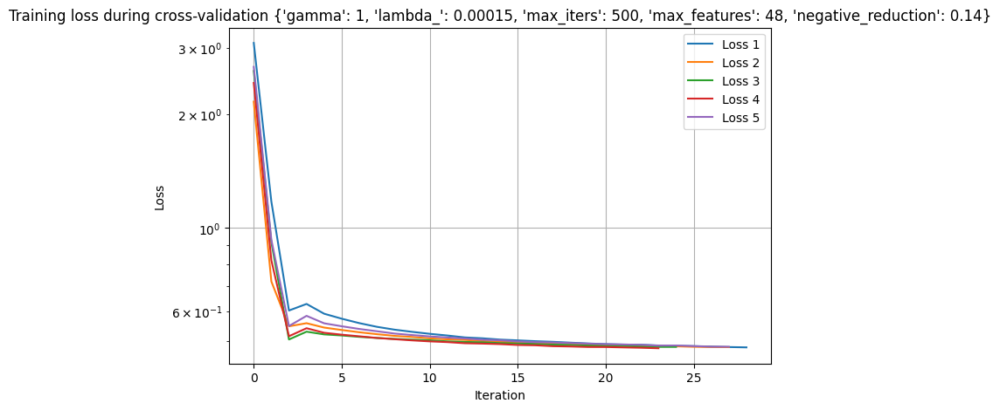

Tuning with args (2/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48031242749395187


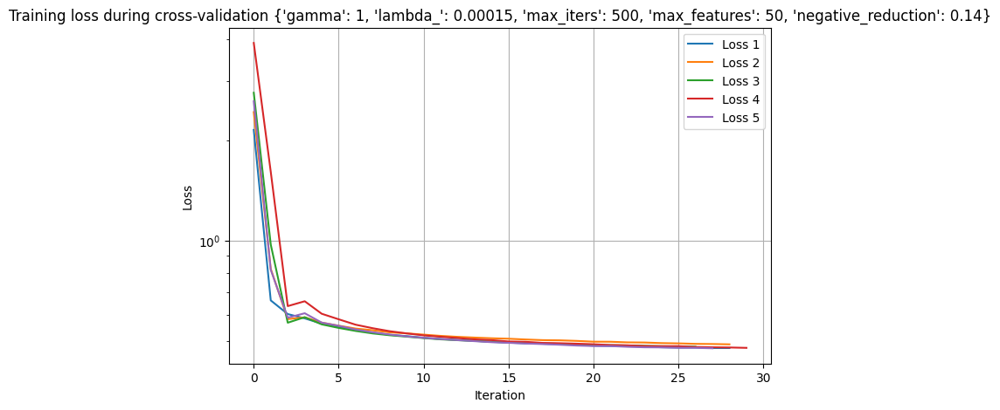

Tuning with args (3/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4792673318937897


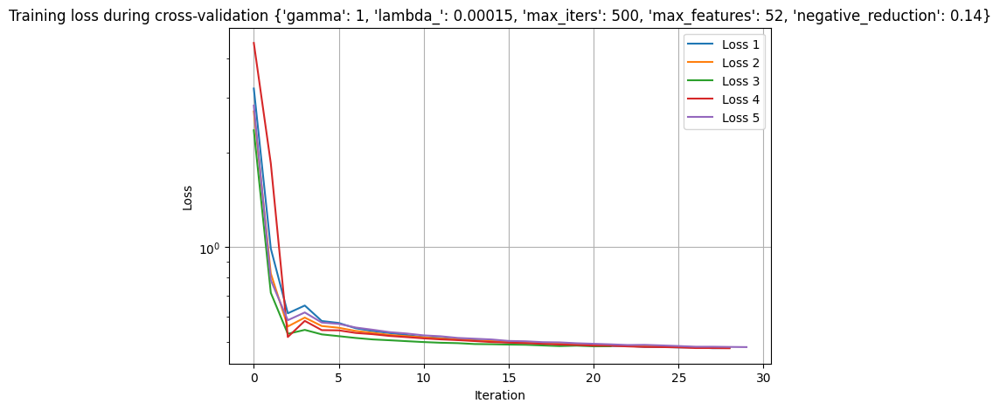

Tuning with args (4/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4772095535274753


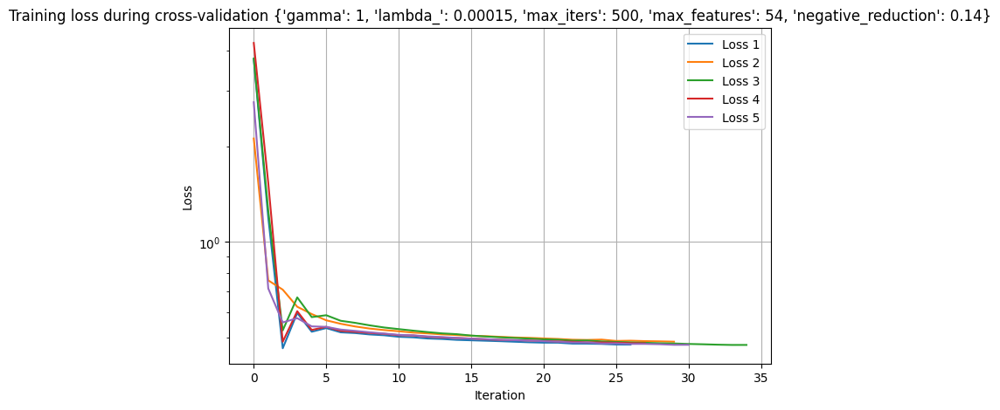

Tuning with args (5/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4823952595845638


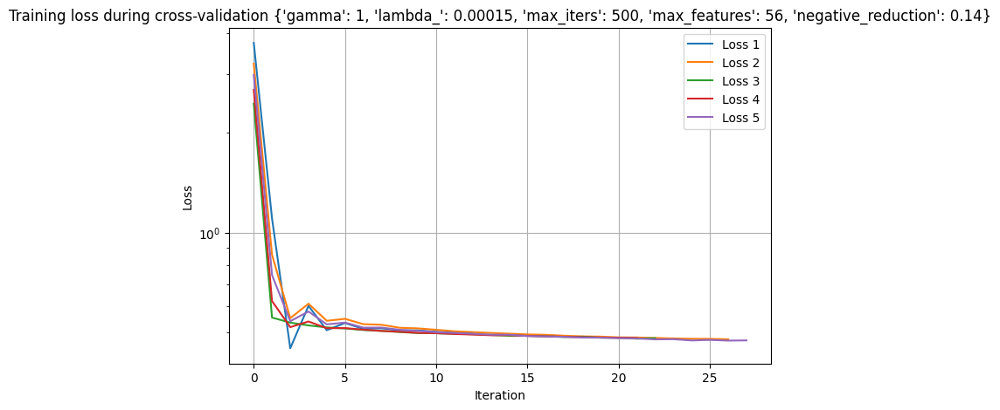

Tuning with args (6/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4781771494623756


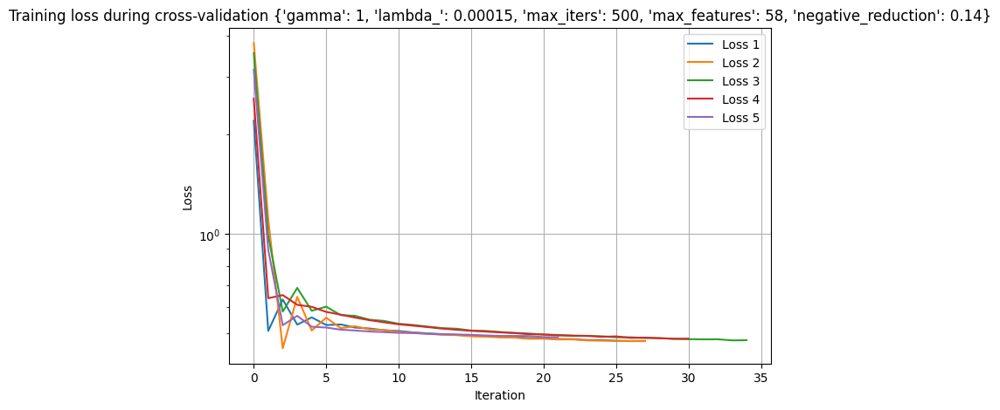

Tuning with args (7/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.482906890366617


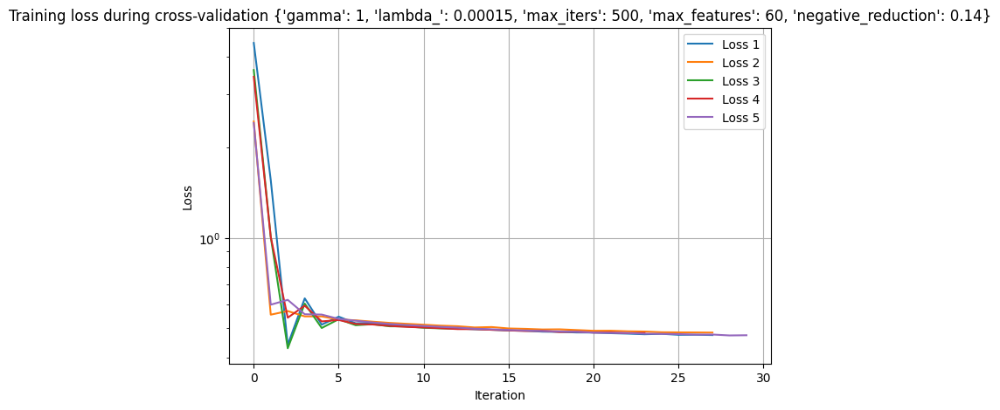

Tuning with args (8/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48027437859207234


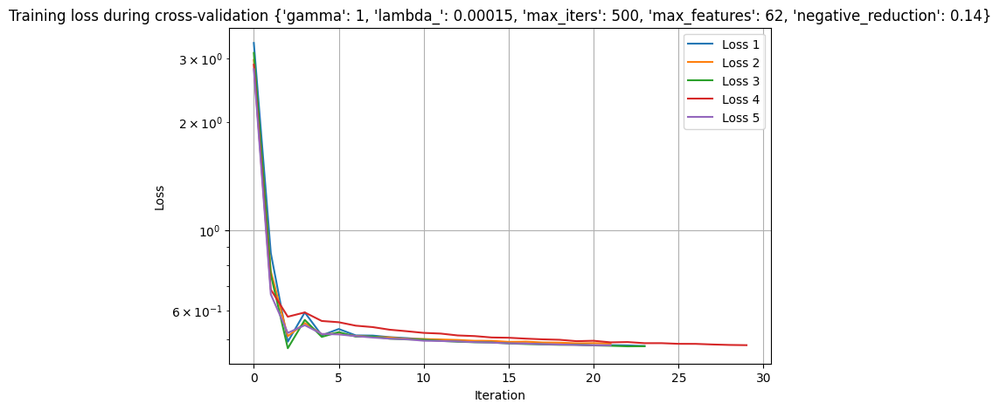

Tuning with args (9/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46636269594239266


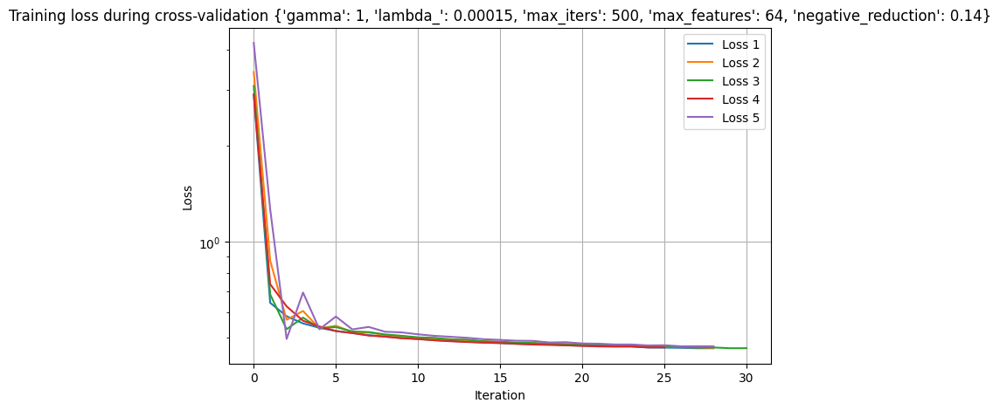

Tuning with args (10/40): {'gamma': 1, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 66, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47468560656357467


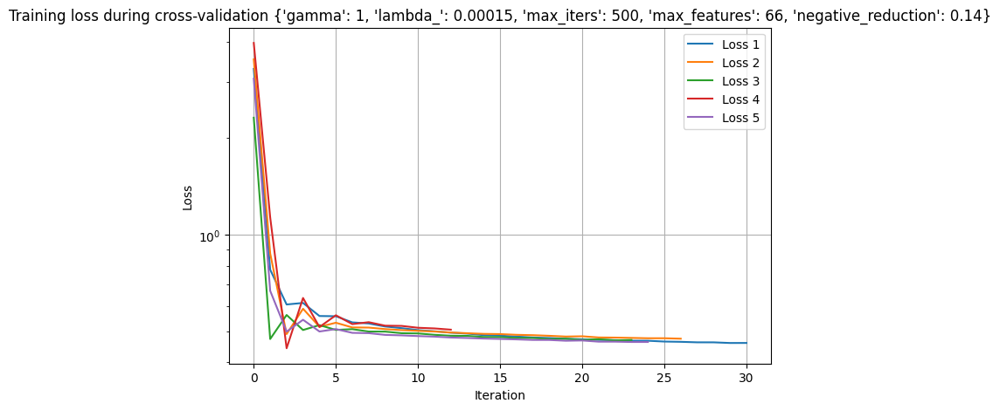

Tuning with args (11/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4864482640333895


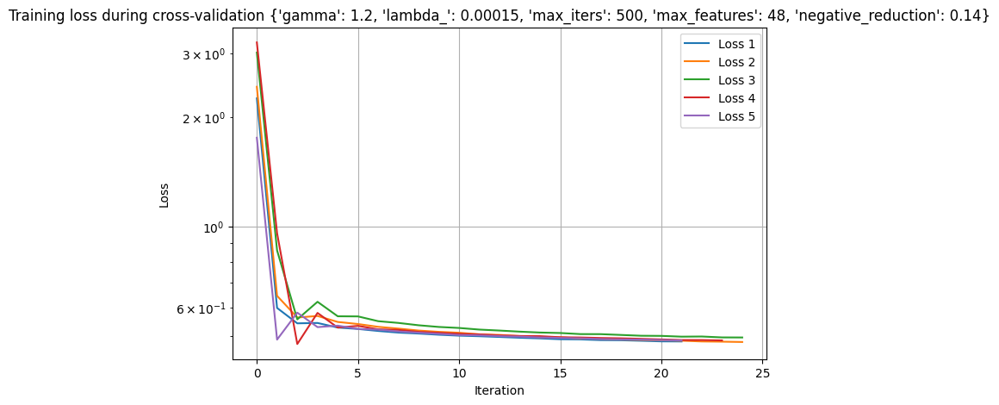

Tuning with args (12/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.484885040309054


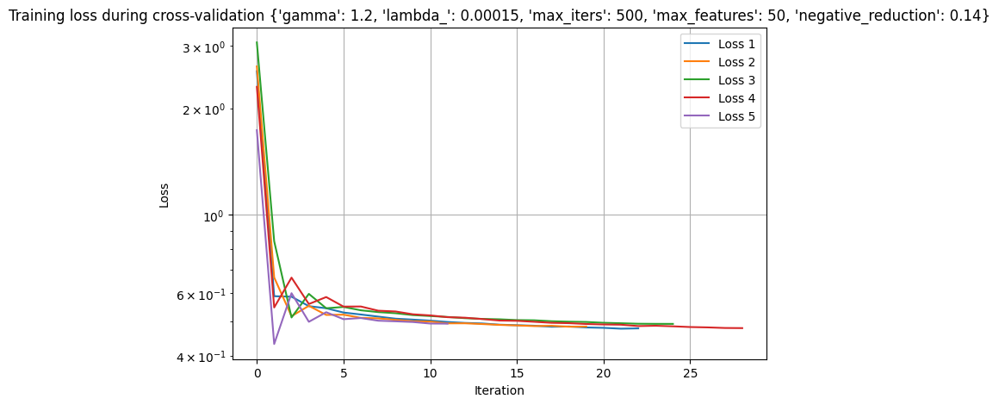

Tuning with args (13/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48591906676066127


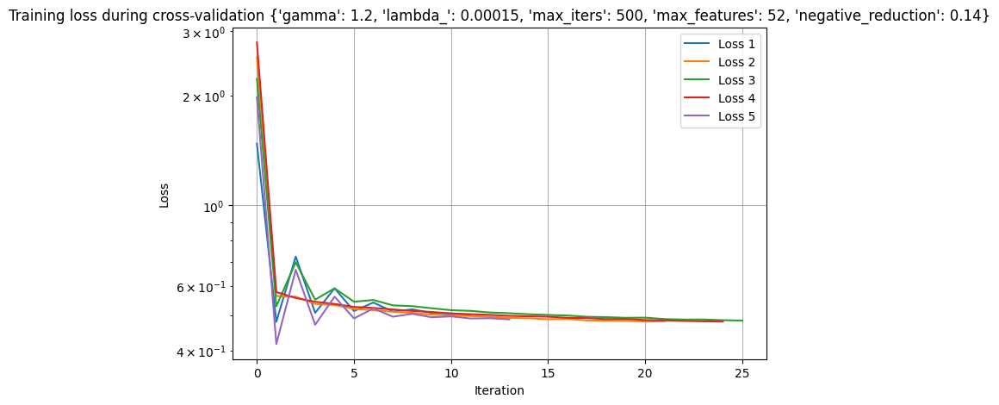

Tuning with args (14/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48976893147148004


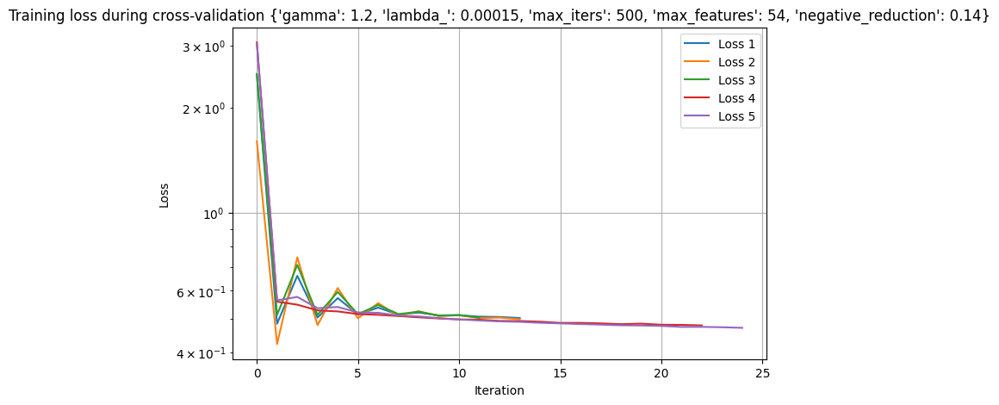

Tuning with args (15/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4871889539600619


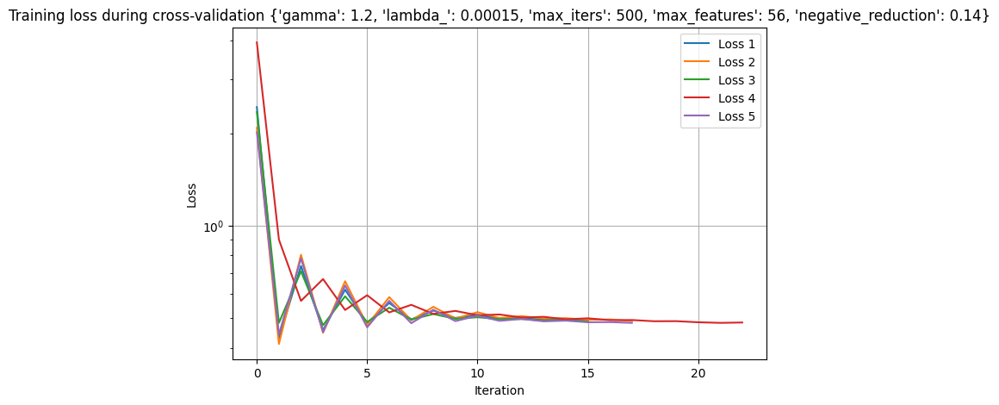

Tuning with args (16/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48561137964600914


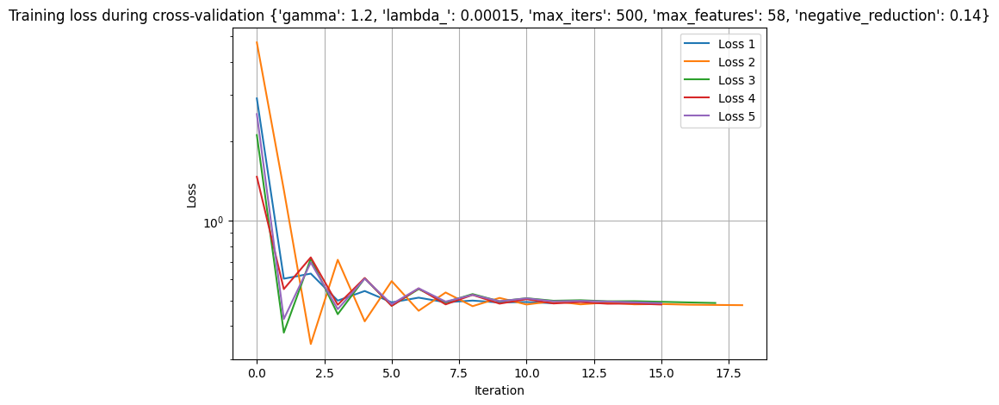

Tuning with args (17/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4927170457295726


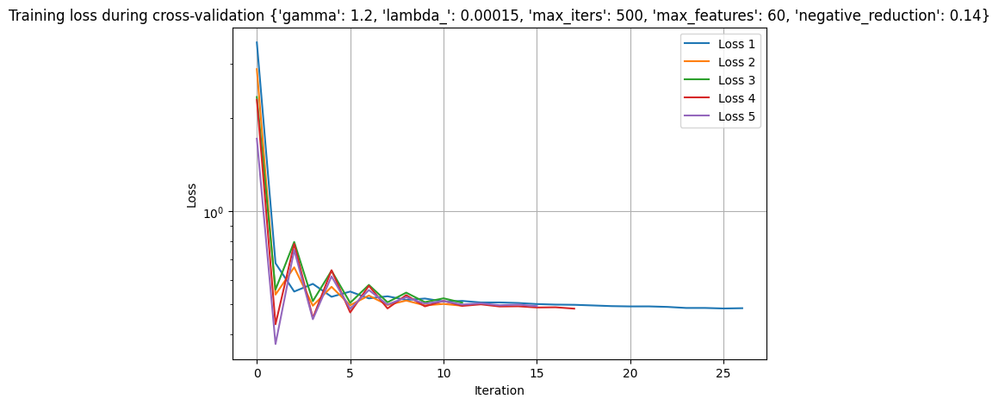

Tuning with args (18/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4866612656985997


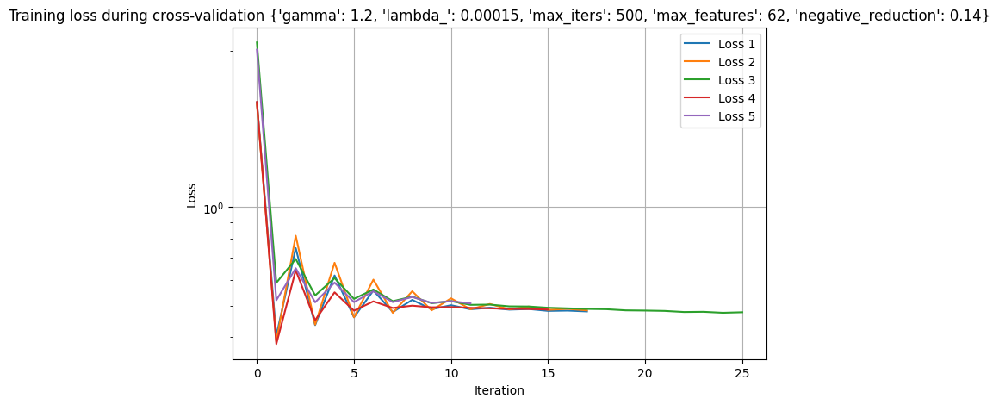

Tuning with args (19/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.467263018813448


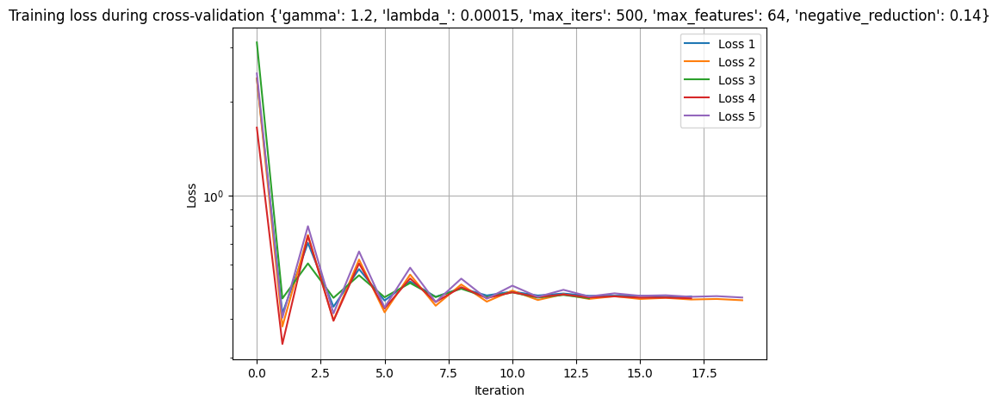

Tuning with args (20/40): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 66, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46866901192214927


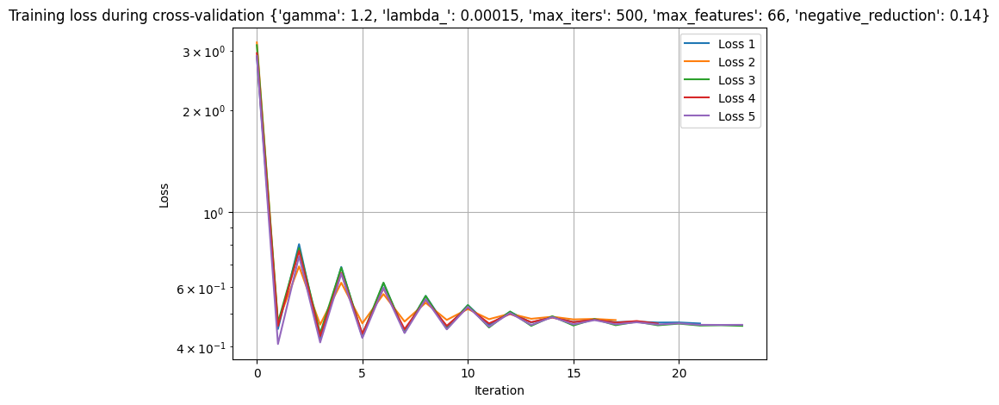

Tuning with args (21/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4904294217080757


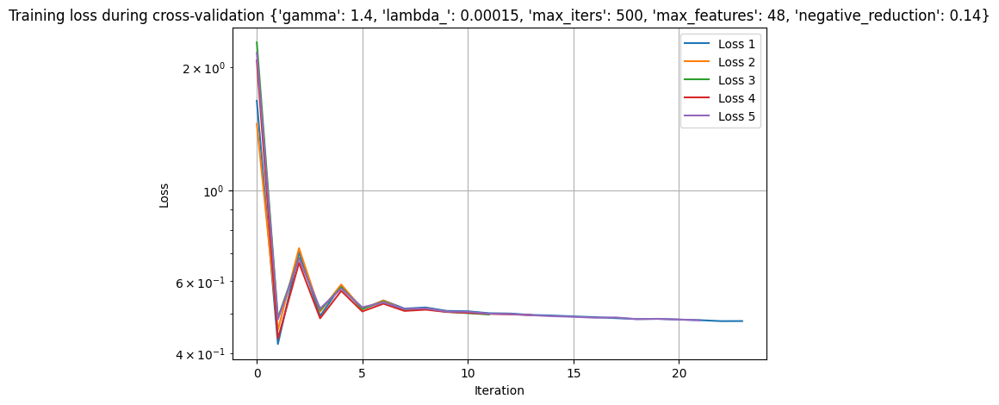

Tuning with args (22/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4836510627008864


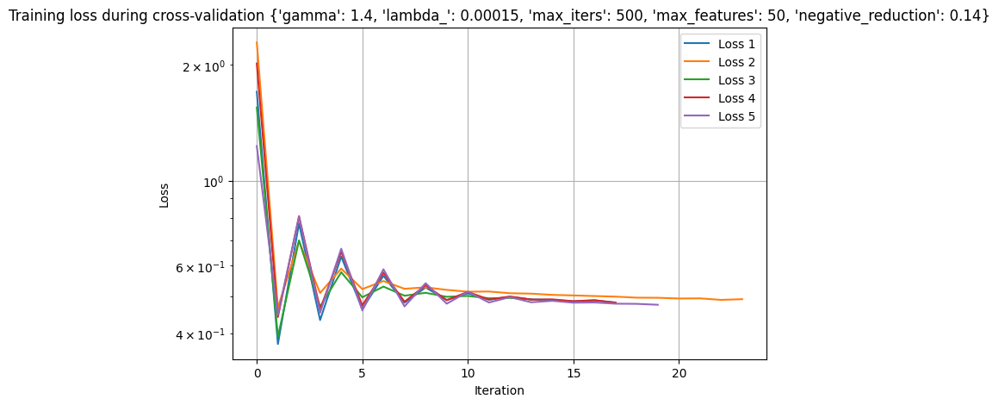

Tuning with args (23/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4815320419595567


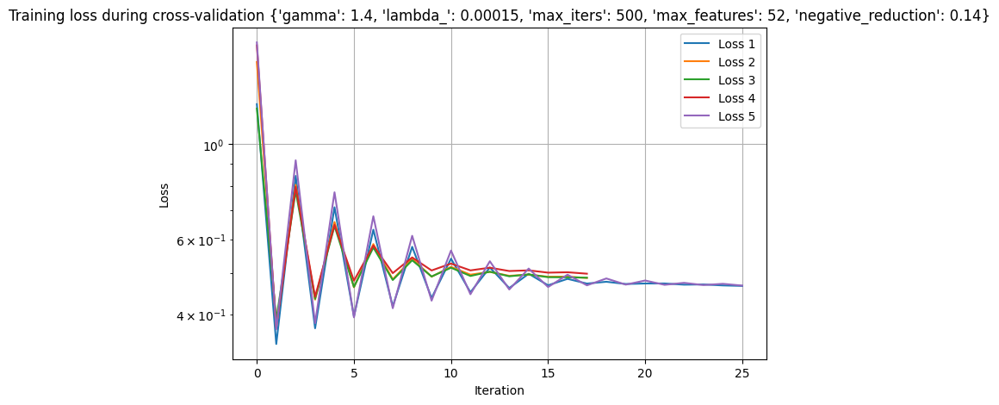

Tuning with args (24/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47053353113792634


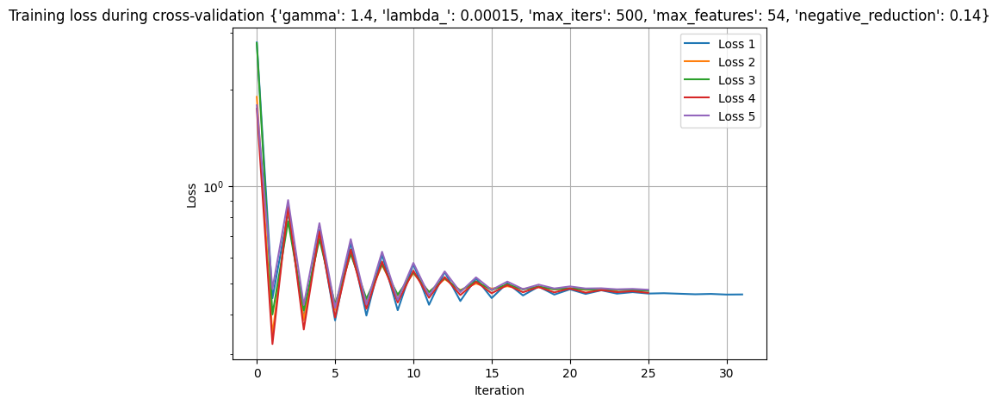

Tuning with args (25/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4625115301358453


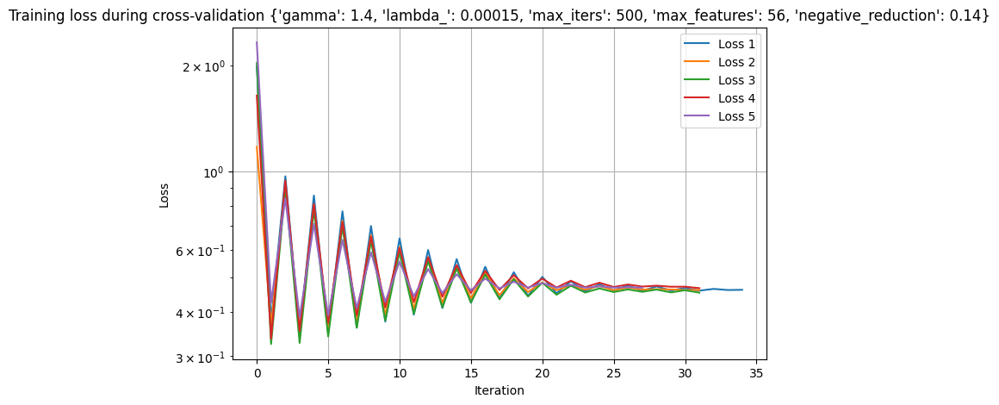

Tuning with args (26/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46402575844596977


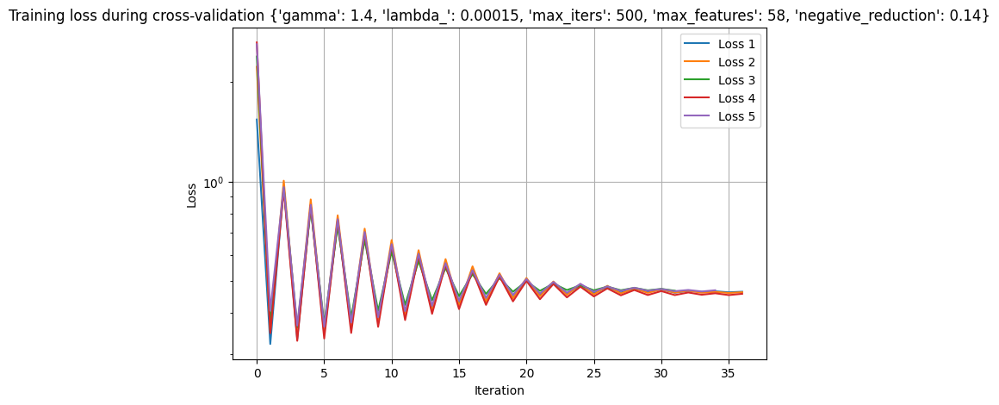

Tuning with args (27/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4666846596491304


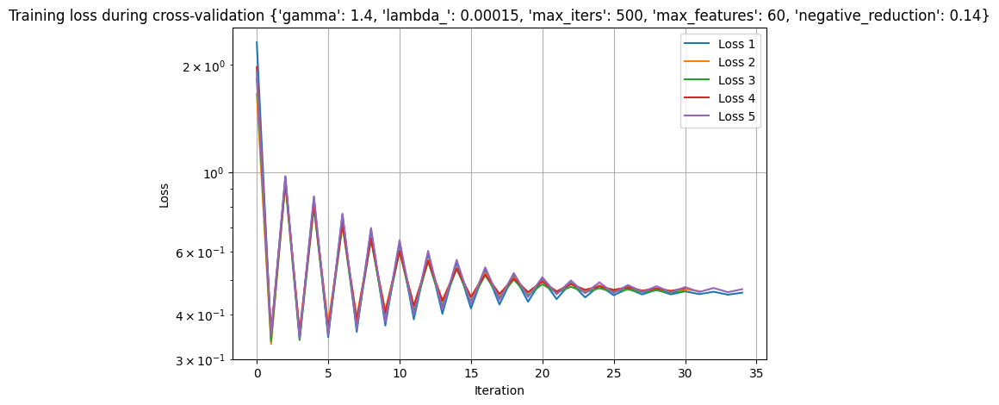

Tuning with args (28/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4602530960627943


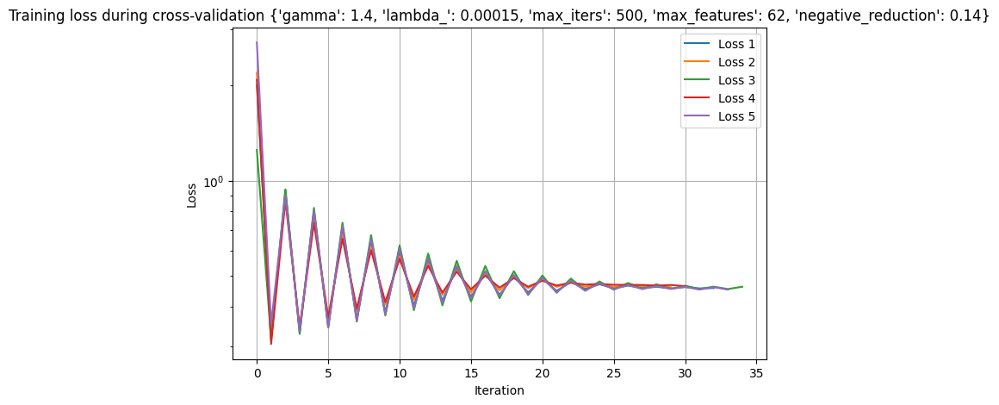

Tuning with args (29/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4551211442493357


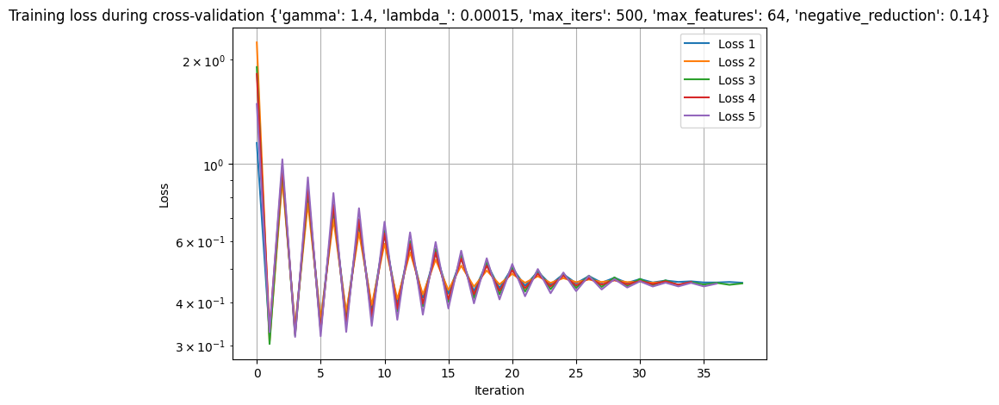

Tuning with args (30/40): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 66, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4518396276778877


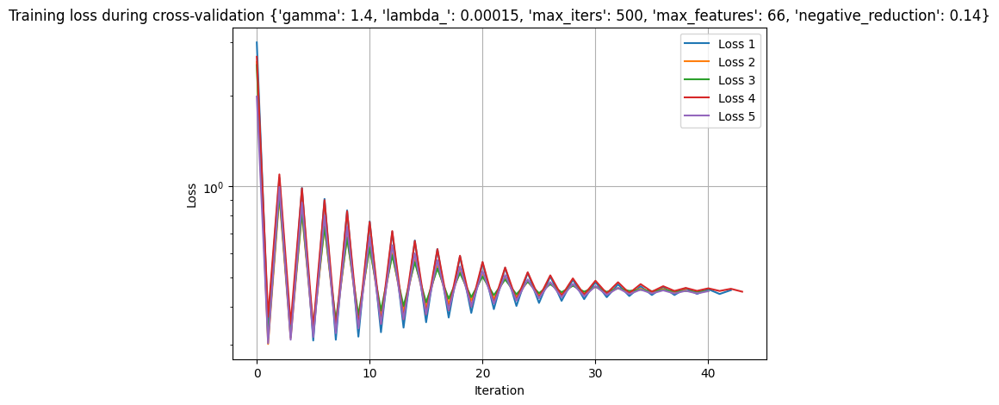

Tuning with args (31/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 48, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4809703117166875


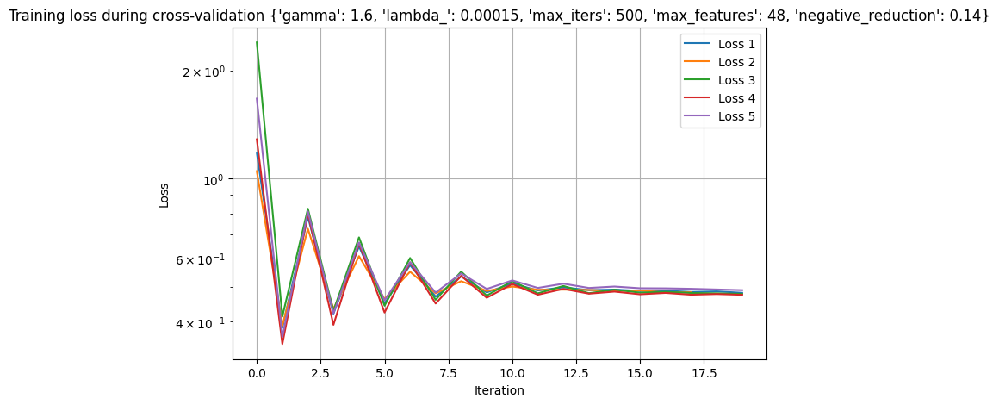

Tuning with args (32/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 50, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4780448447681536


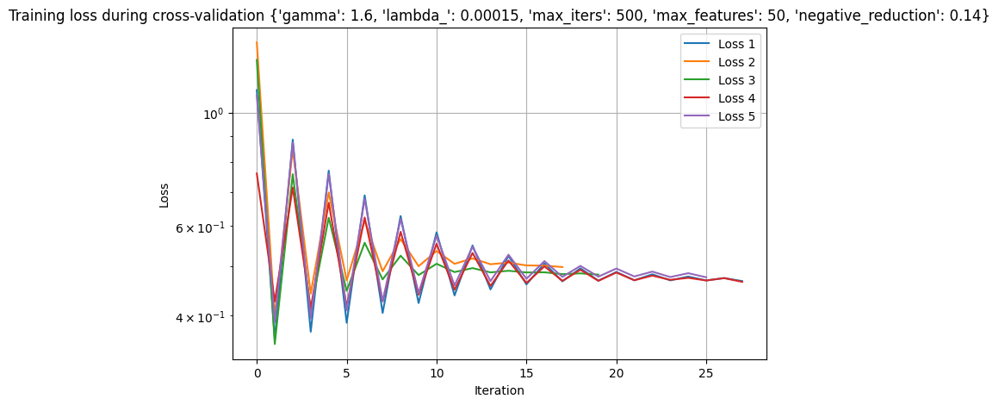

Tuning with args (33/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46563866467737797


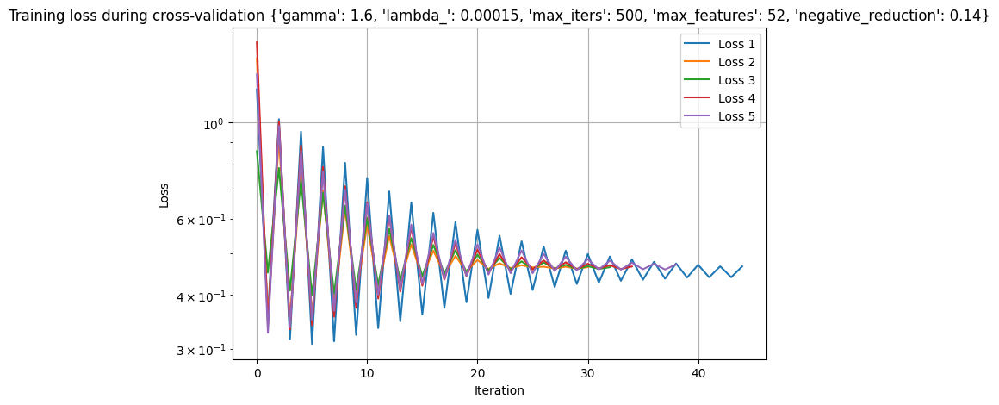

Tuning with args (34/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46721497647749183


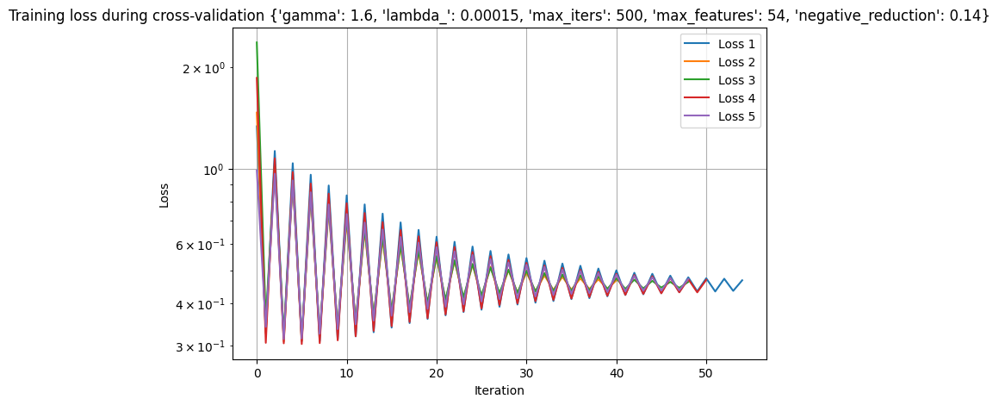

Tuning with args (35/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5708761244376889


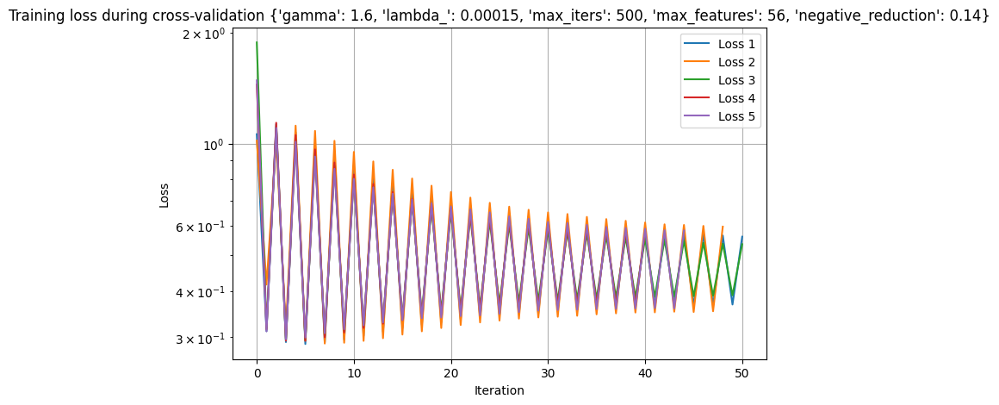

Tuning with args (36/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.6014395238690959


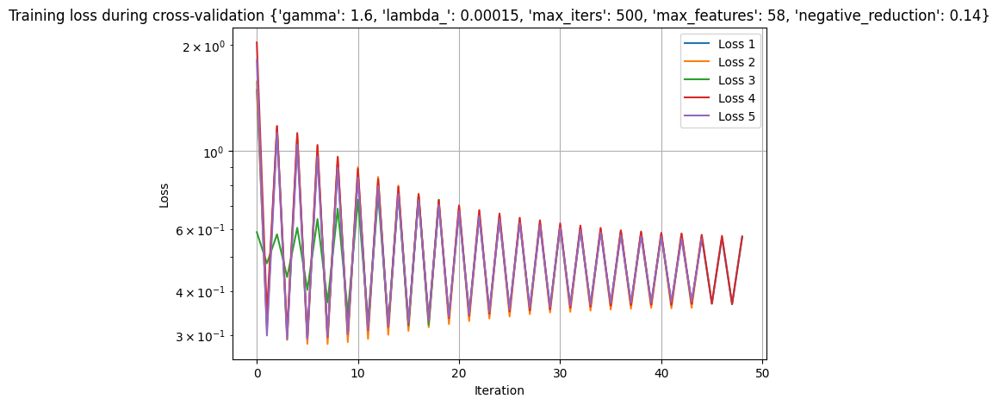

Tuning with args (37/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.49856063015579616


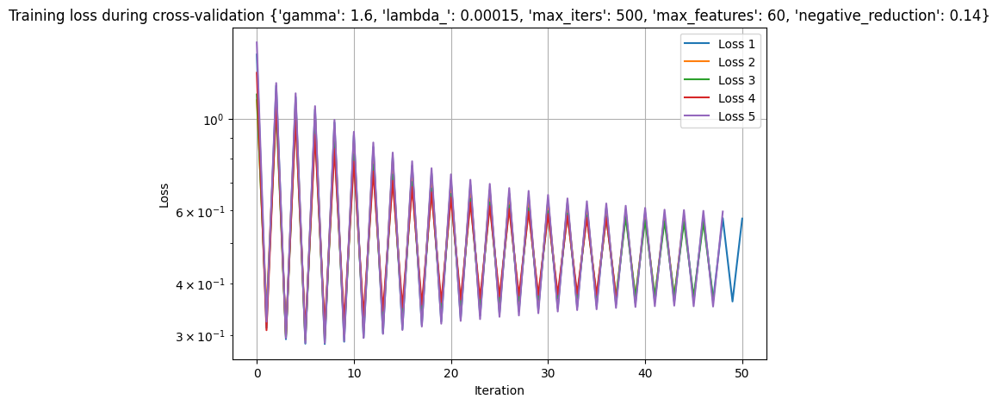

Tuning with args (38/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.5008080702037019


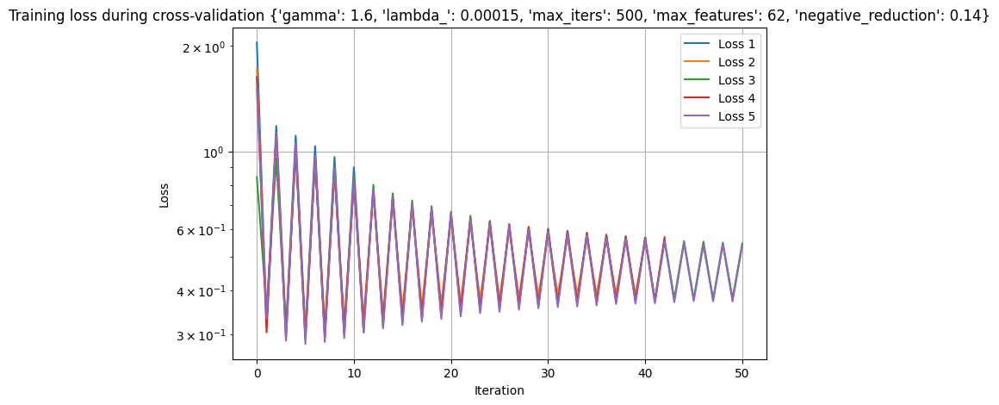

Tuning with args (39/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 64, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.39339991089536175


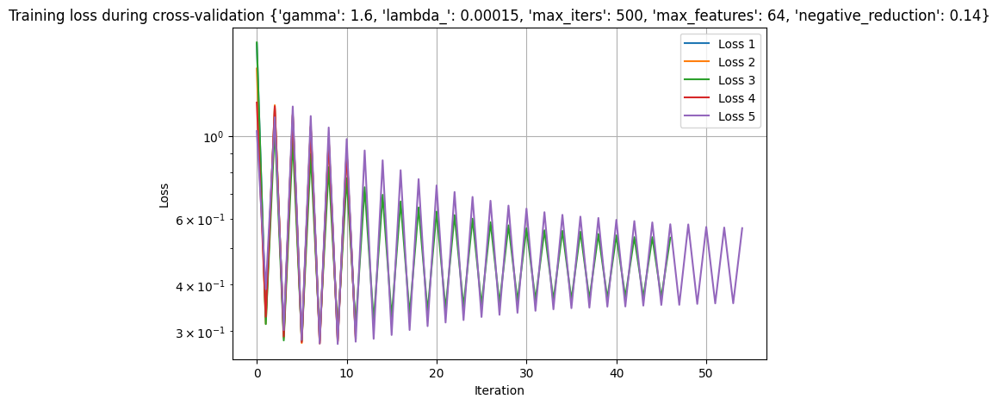

Tuning with args (40/40): {'gamma': 1.6, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 66, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.3545697014681788


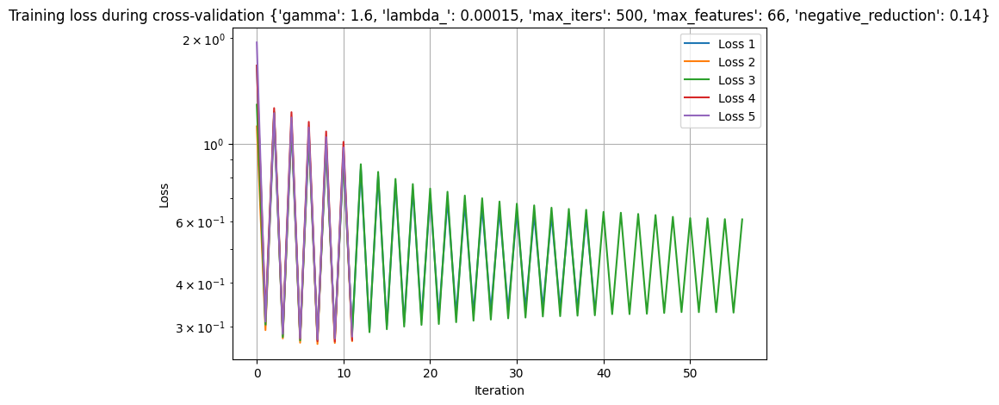

In [44]:
args_logreg_balanced_4 = [
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 64,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 66,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 64,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 66,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 64,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 66,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 48,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 50,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 64,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.6,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 66,
        "negative_reduction": 0.14,
    },
]
validation_logreg_balanced_4, training_logreg_balanced_4 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_balanced_4
)

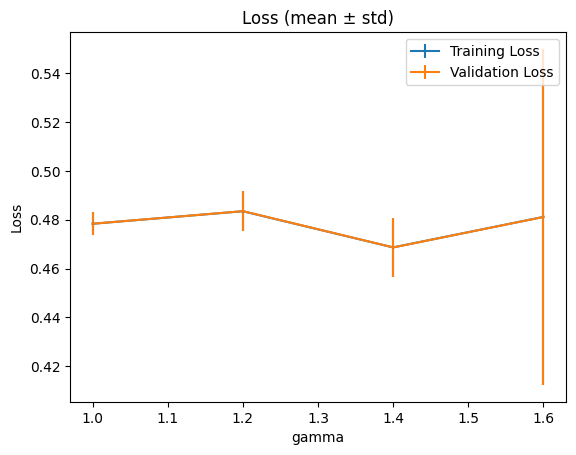


Averaged results:
gamma=1 | val=0.4784±0.0047 | train=0.4783±0.0047
gamma=1.2 | val=0.4835±0.0081 | train=0.4835±0.0081
gamma=1.4 | val=0.4687±0.0121 | train=0.4687±0.0121
gamma=1.6 | val=0.4812±0.0688 | train=0.4812±0.0688


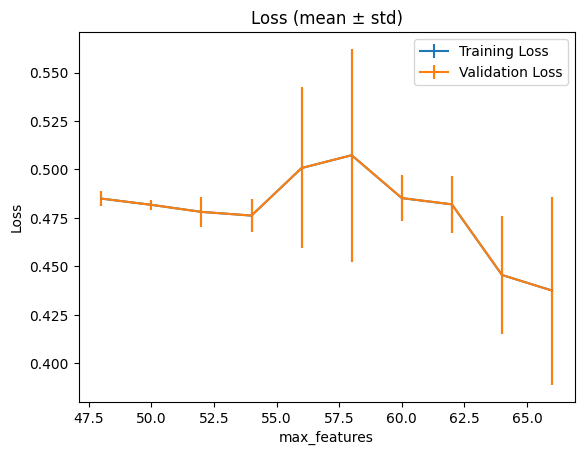


Averaged results:
max_features=48 | val=0.4849±0.0038 | train=0.4850±0.0038
max_features=50 | val=0.4817±0.0027 | train=0.4817±0.0027
max_features=52 | val=0.4781±0.0076 | train=0.4781±0.0076
max_features=54 | val=0.4762±0.0086 | train=0.4762±0.0086
max_features=56 | val=0.5007±0.0415 | train=0.5007±0.0415
max_features=58 | val=0.5073±0.0549 | train=0.5073±0.0549
max_features=60 | val=0.4852±0.0121 | train=0.4852±0.0121
max_features=62 | val=0.4820±0.0146 | train=0.4819±0.0146
max_features=64 | val=0.4455±0.0305 | train=0.4455±0.0304
max_features=66 | val=0.4374±0.0486 | train=0.4375±0.0485


In [45]:
show_printing_result_loss(
    args_logreg_balanced_4,
    validation_logreg_balanced_4,
    training_logreg_balanced_4,
    "gamma",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)
show_printing_result_loss(
    args_logreg_balanced_4,
    validation_logreg_balanced_4,
    training_logreg_balanced_4,
    "max_features",
    small_marge=0,
    big_marge=0,
    x_log=False,
    y_log=False,
)

Tuning with args (1/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4781851060447103


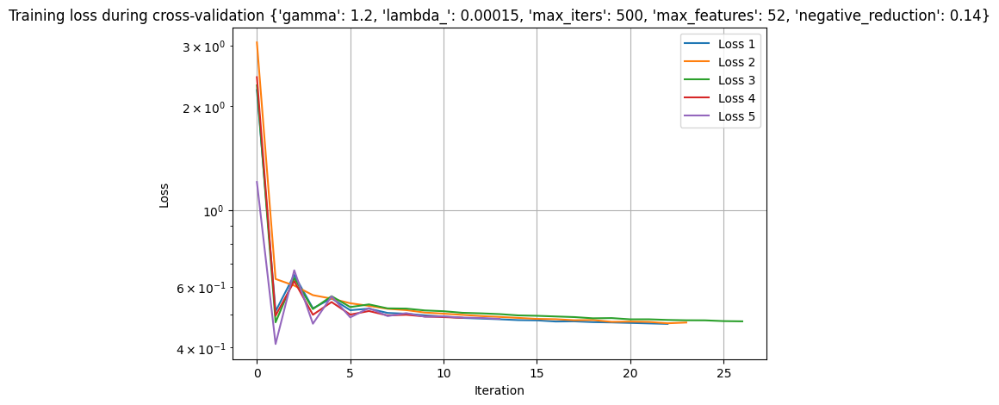

Tuning with args (2/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48661864616693035


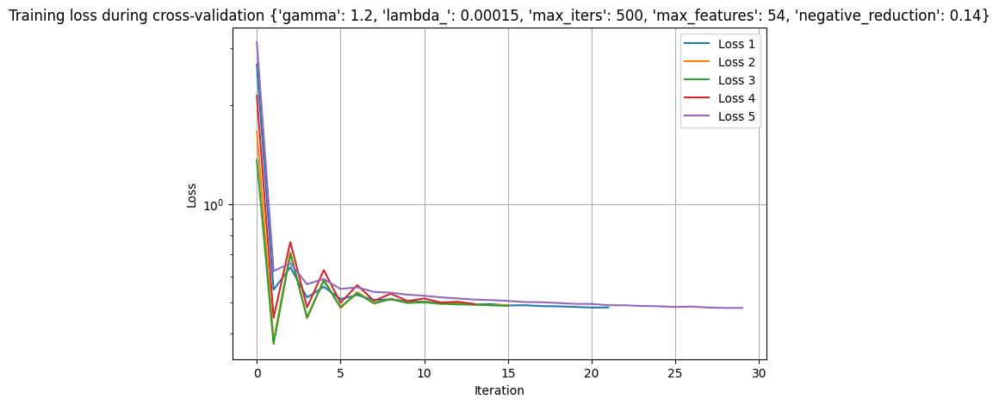

Tuning with args (3/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48409390142748626


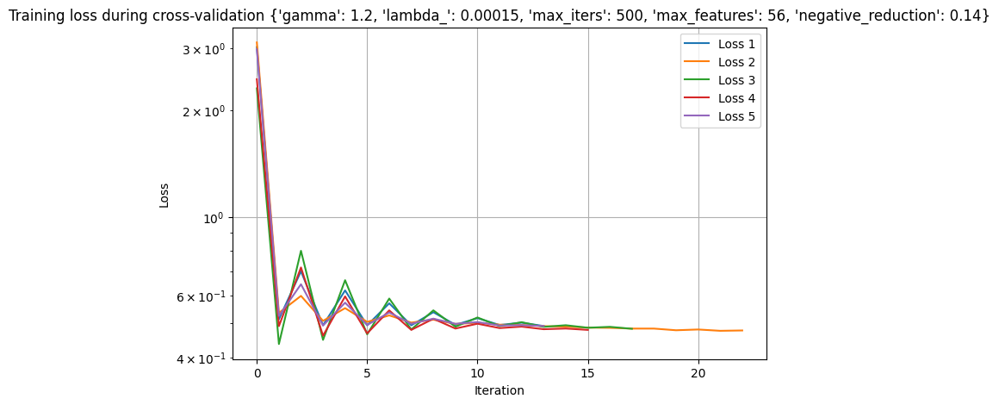

Tuning with args (4/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4822690808699794


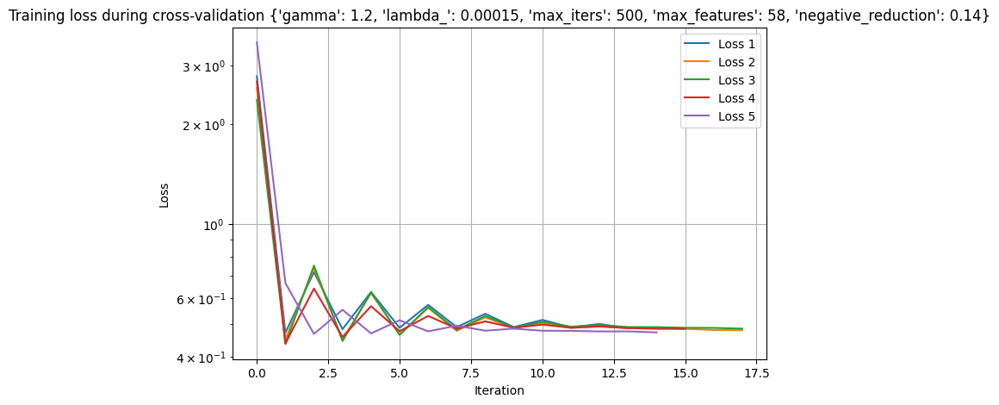

Tuning with args (5/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4873573697085739


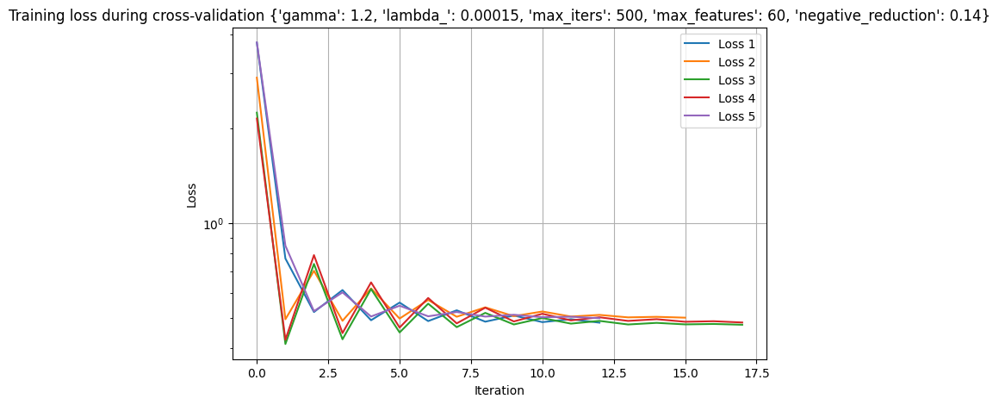

Tuning with args (6/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4779485487403571


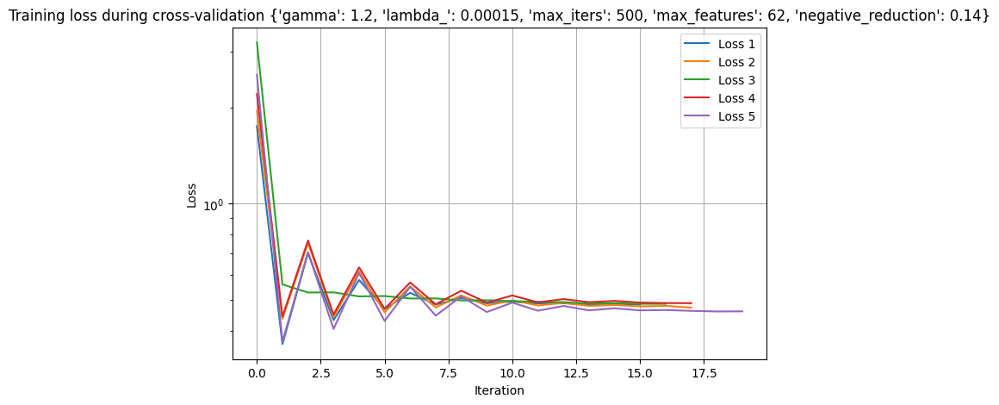

Tuning with args (7/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48852215016730927


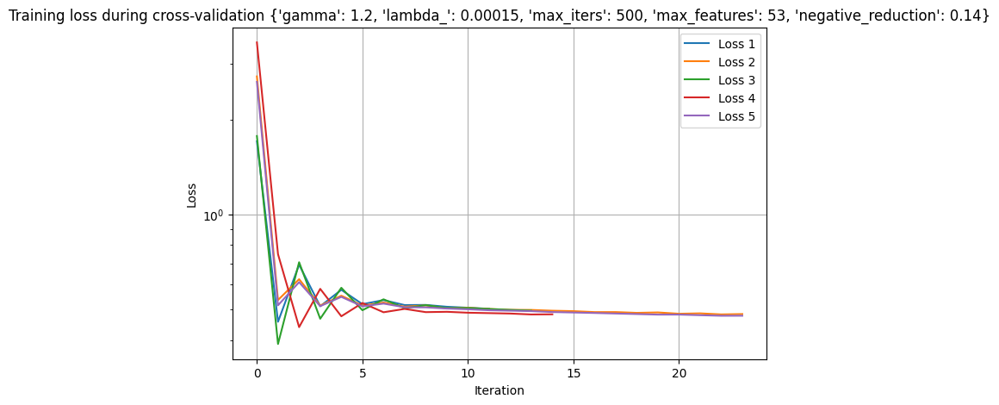

Tuning with args (8/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48024008321216627


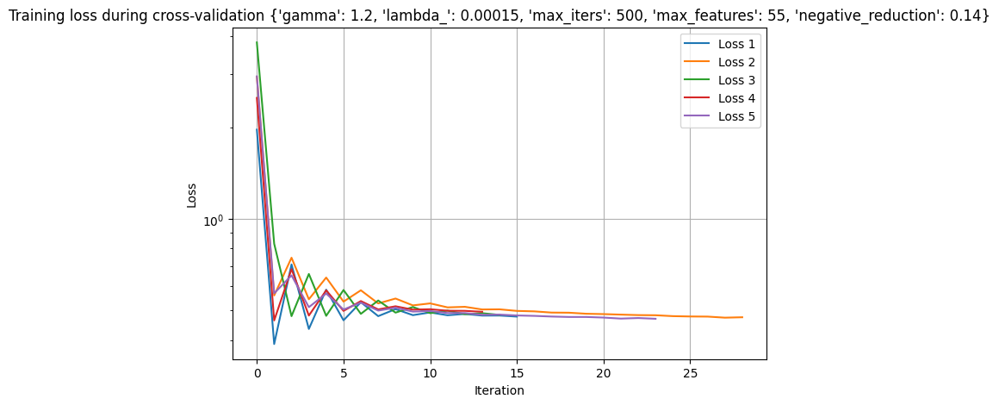

Tuning with args (9/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 57, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4830974730825612


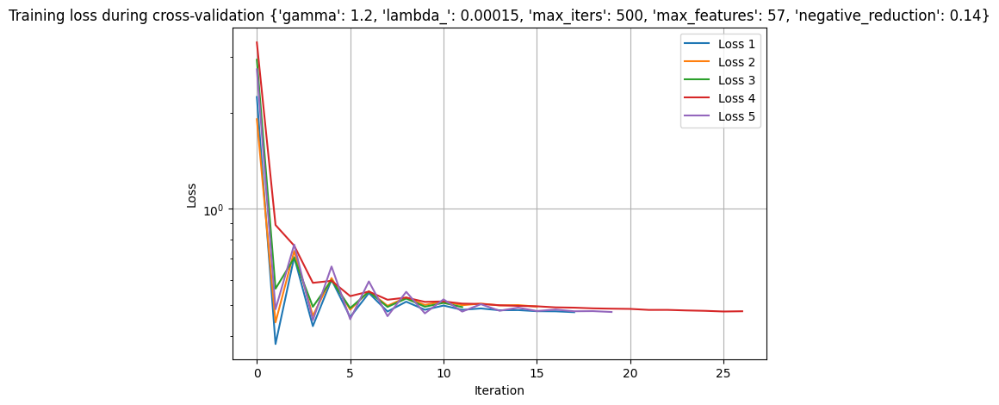

Tuning with args (10/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 59, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4872803478448181


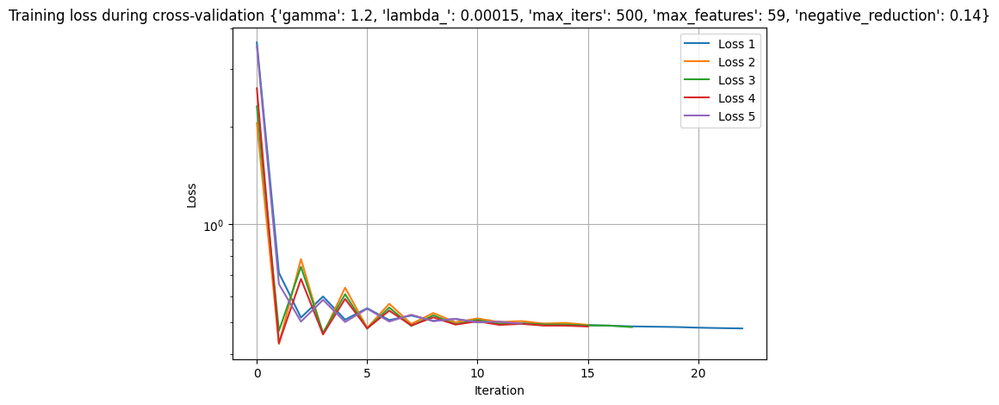

Tuning with args (11/44): {'gamma': 1.2, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 61, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.48389169267764587


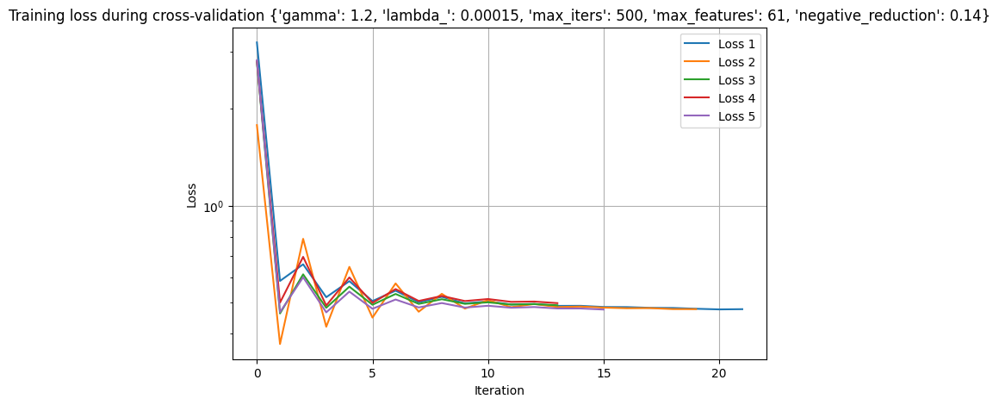

Tuning with args (12/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4886923525522676


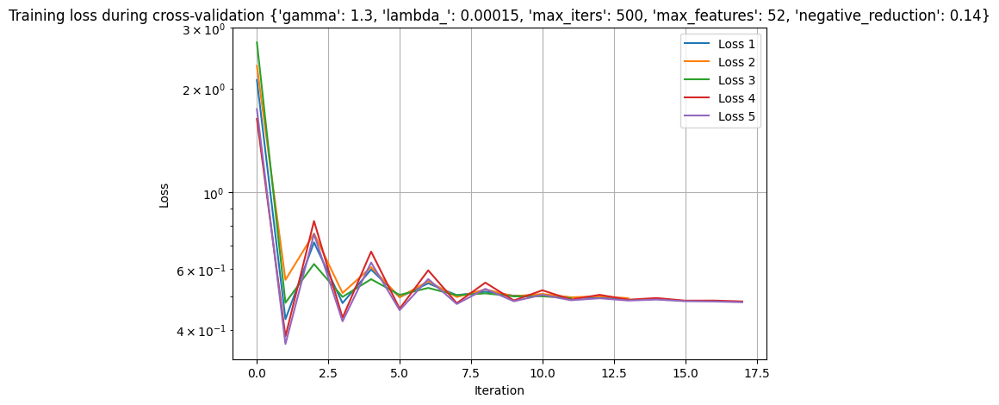

Tuning with args (13/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4787355334638681


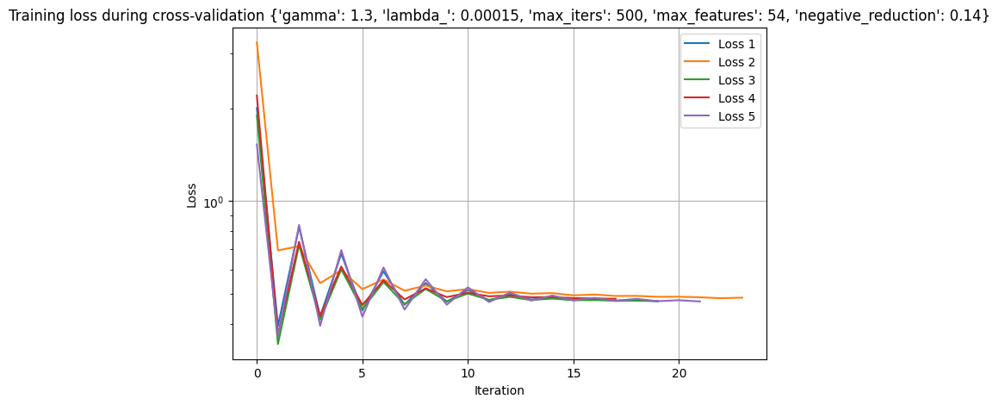

Tuning with args (14/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47468021014955014


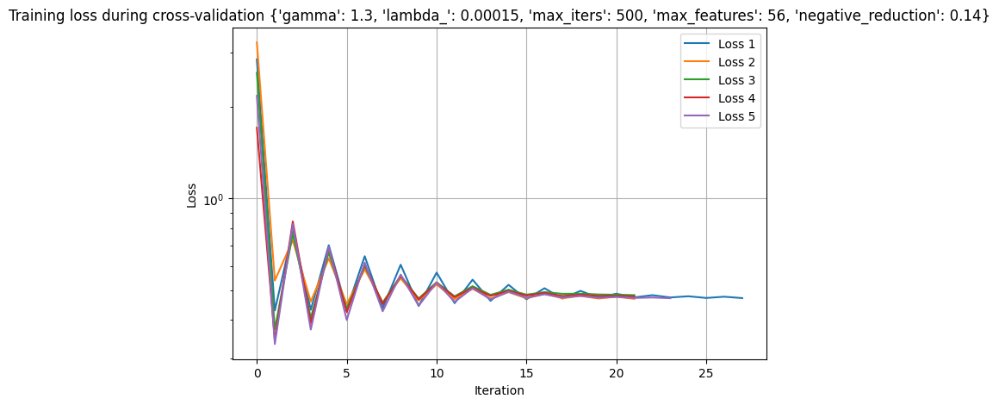

Tuning with args (15/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4725548918306286


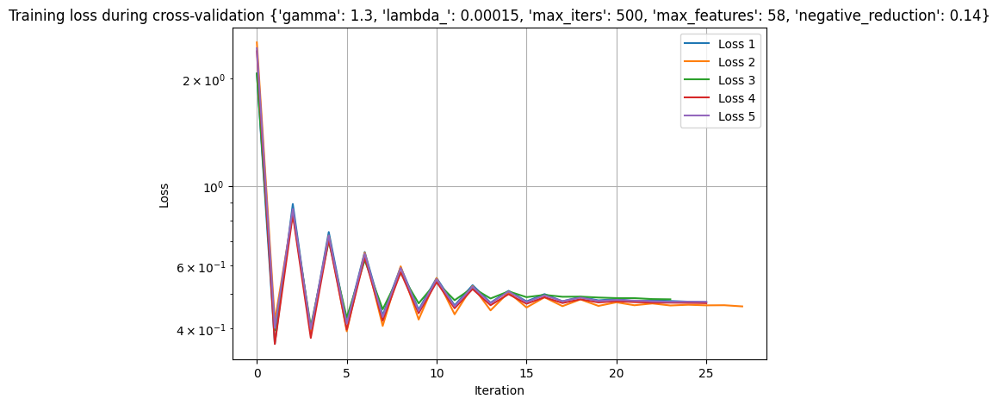

Tuning with args (16/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47863482981585354


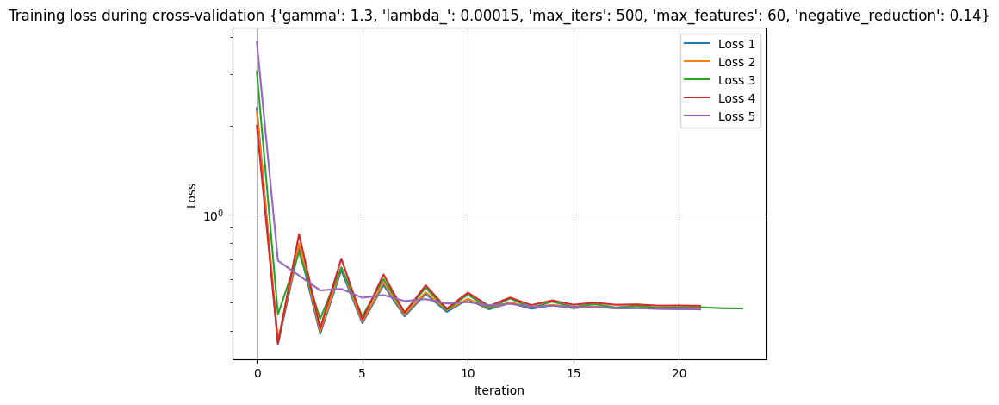

Tuning with args (17/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4703419813690316


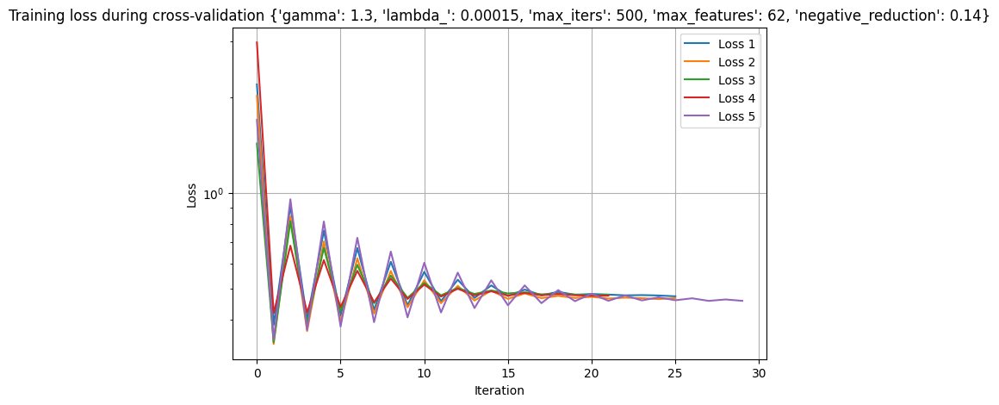

Tuning with args (18/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4864720917818424


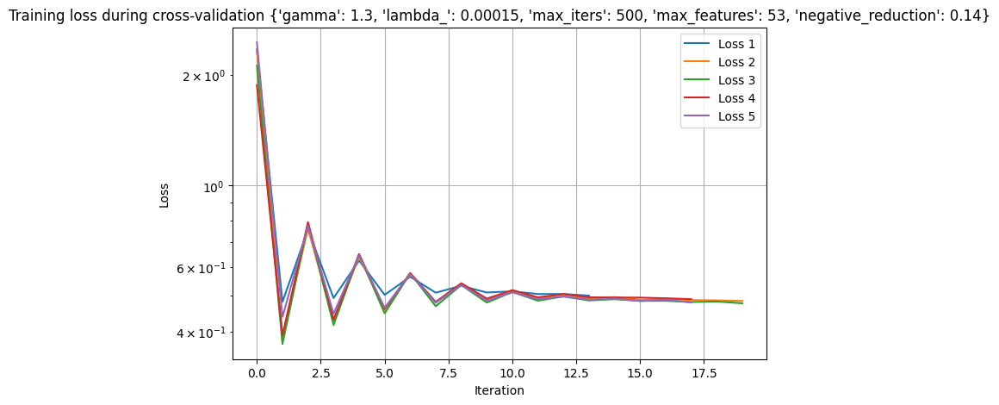

Tuning with args (19/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47993508037404087


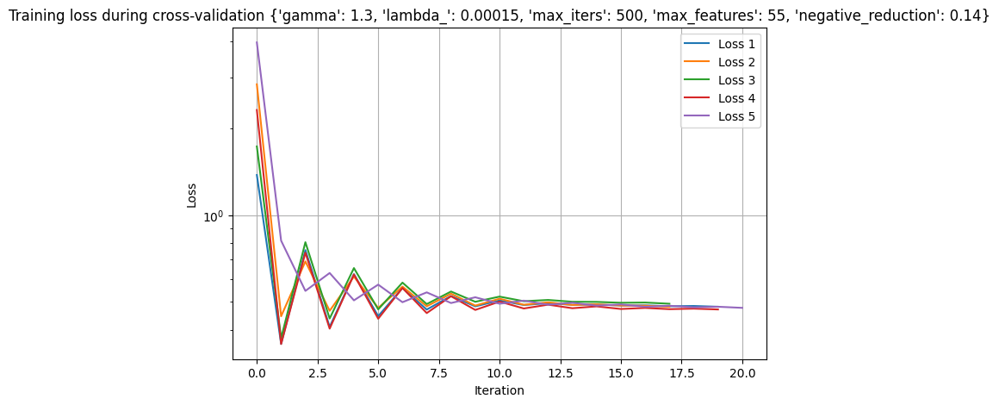

Tuning with args (20/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 57, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46901017795377653


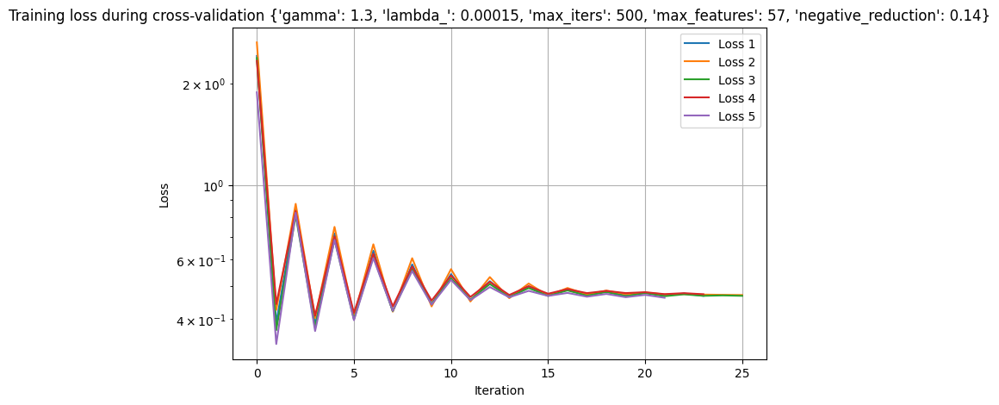

Tuning with args (21/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 59, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4684071438663035


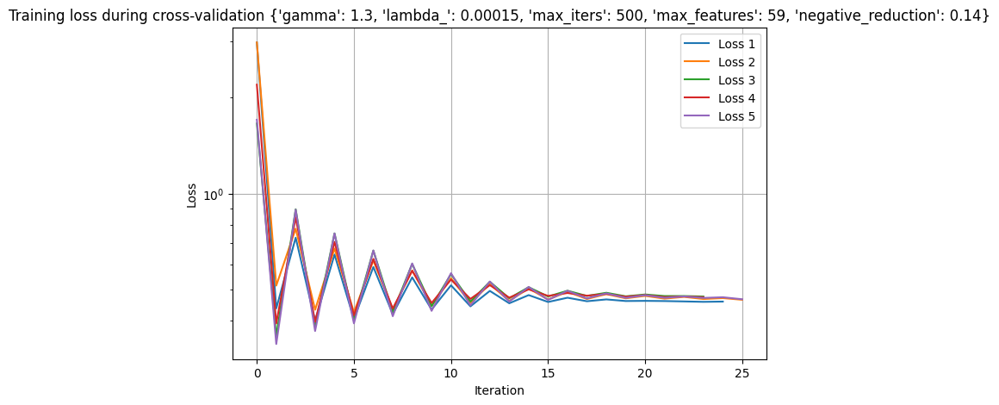

Tuning with args (22/44): {'gamma': 1.3, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 61, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47341743602240716


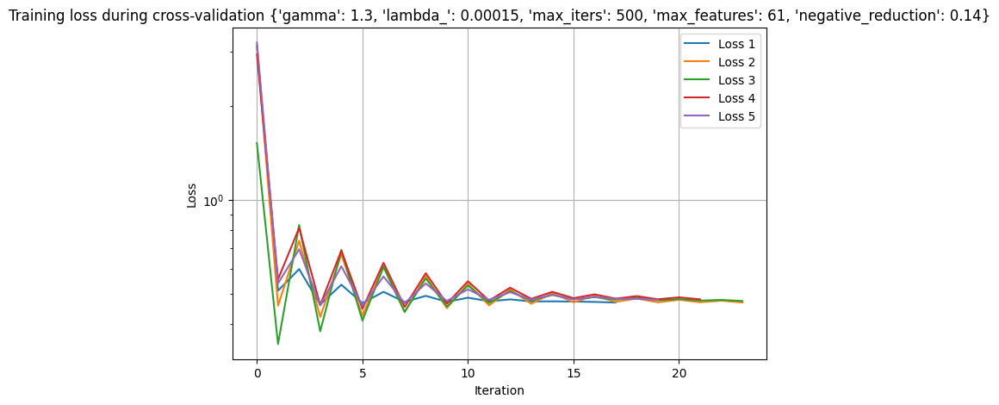

Tuning with args (23/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.47828690497302195


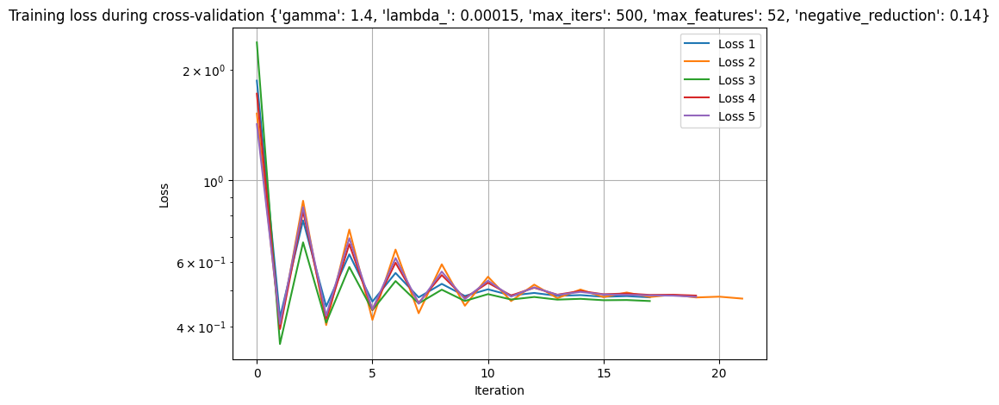

Tuning with args (24/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4646896514023934


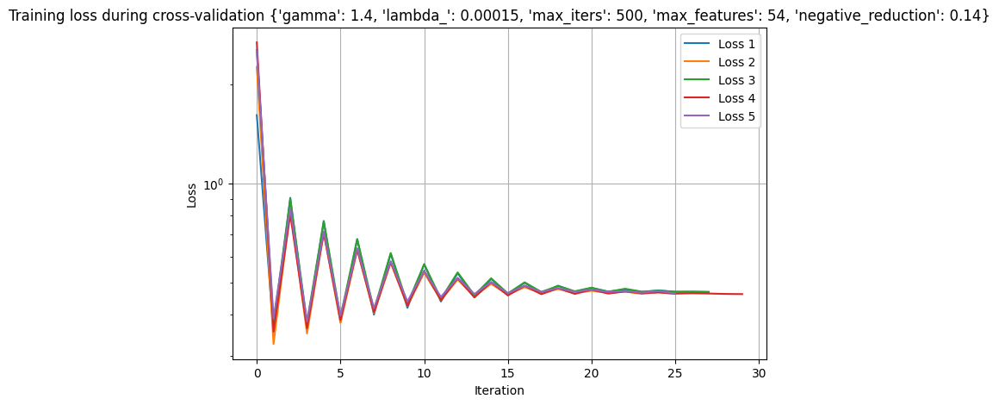

Tuning with args (25/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4610464761714056


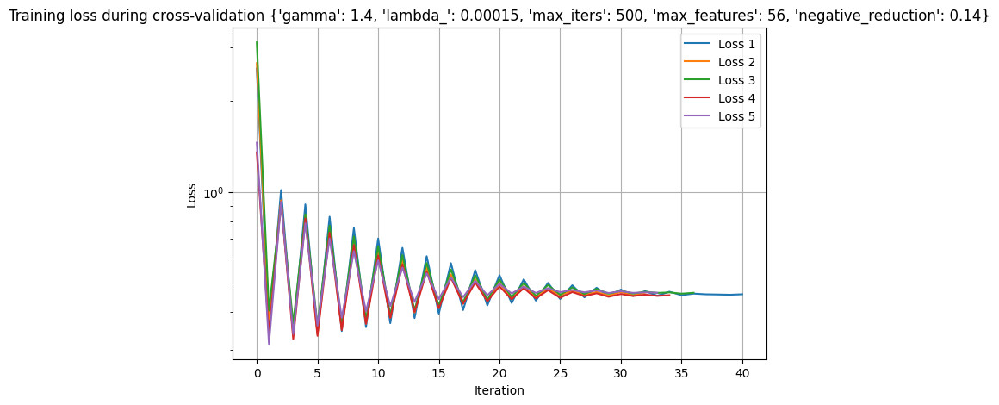

Tuning with args (26/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4595941250543758


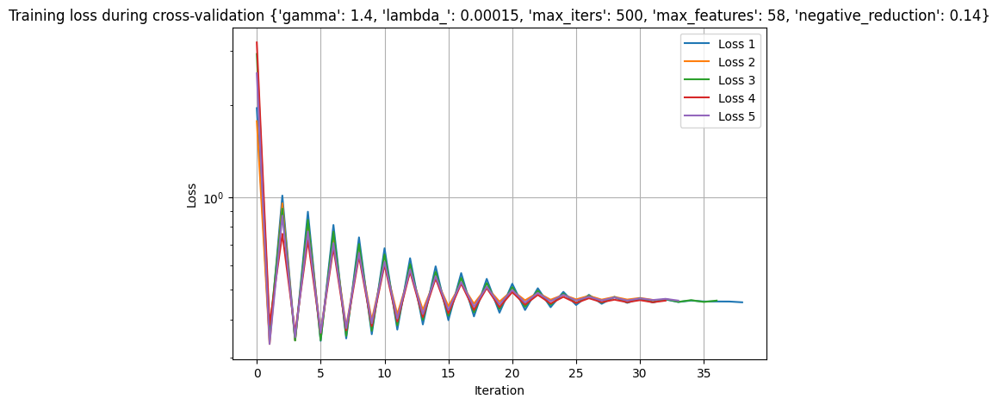

Tuning with args (27/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4635233954765302


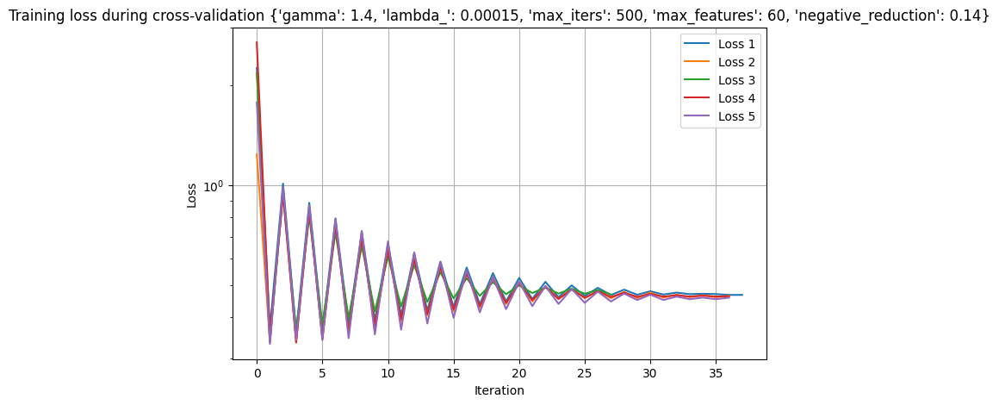

Tuning with args (28/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46084427081407364


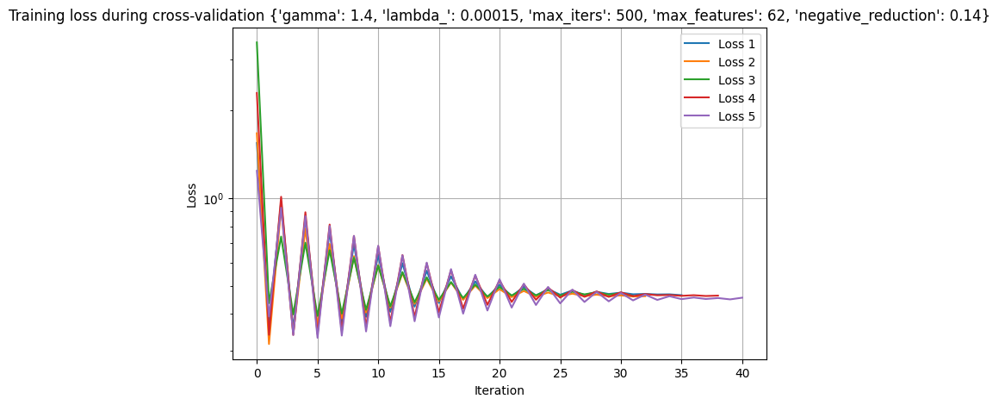

Tuning with args (29/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46554149247442034


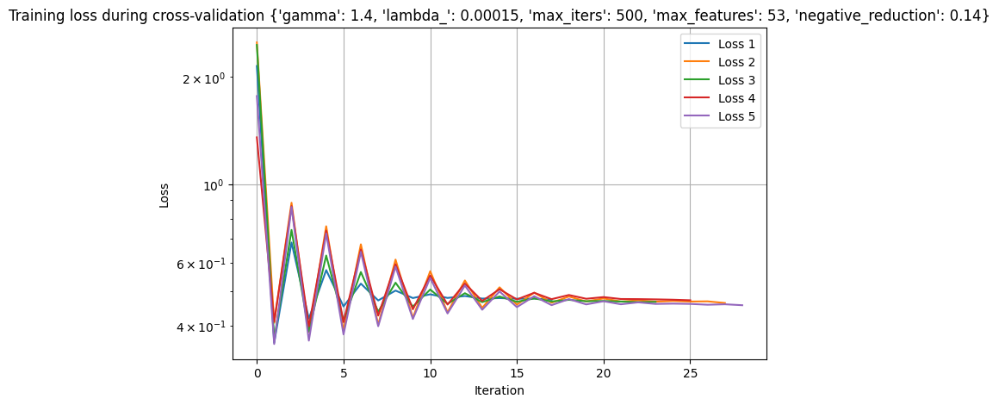

Tuning with args (30/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46093477608855


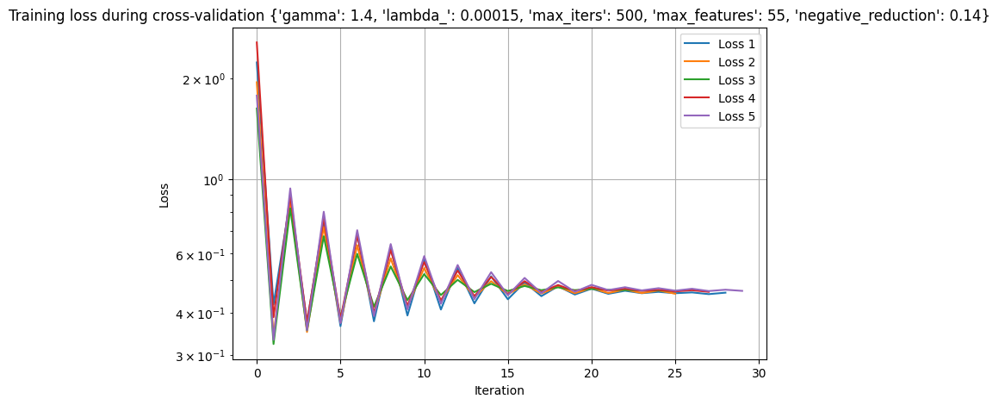

Tuning with args (31/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 57, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46386544838874927


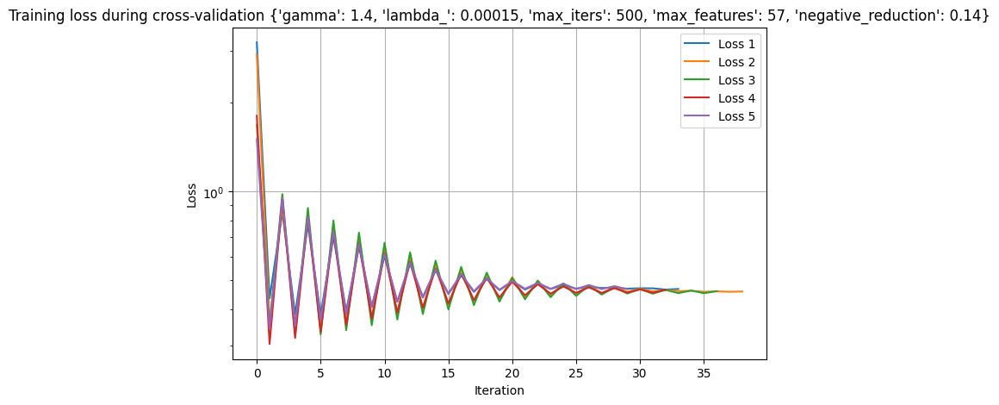

Tuning with args (32/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 59, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46601547081835076


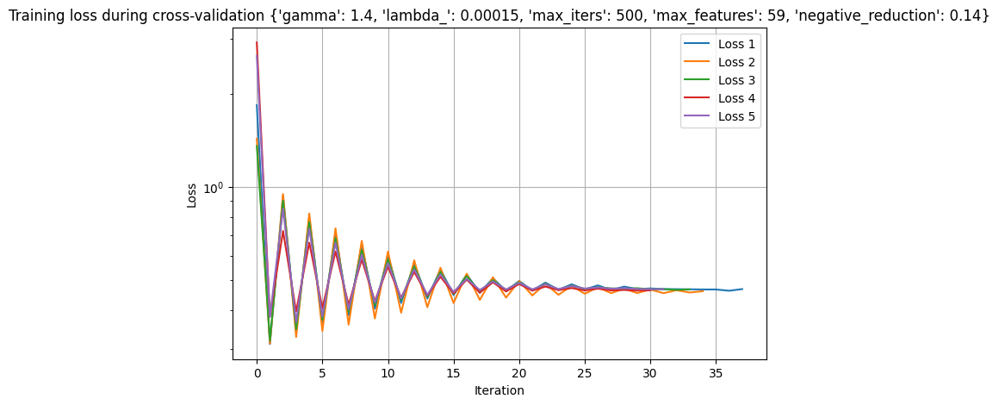

Tuning with args (33/44): {'gamma': 1.4, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 61, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4651033570352084


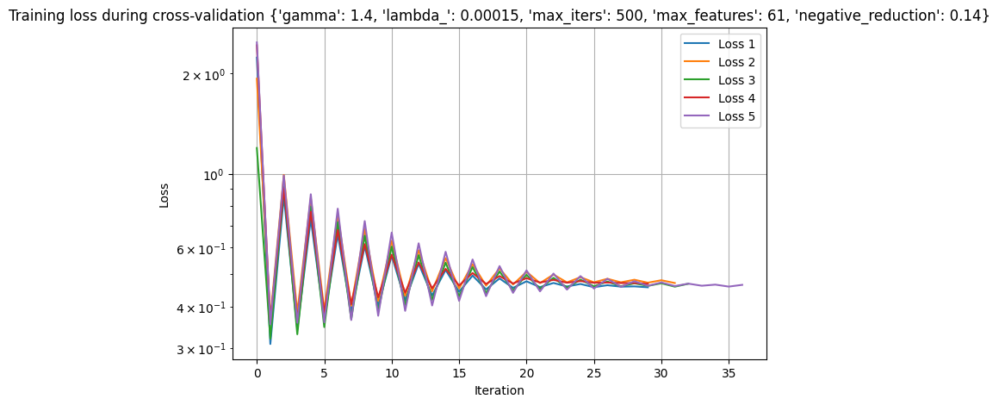

Tuning with args (34/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 52, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.46852686636969587


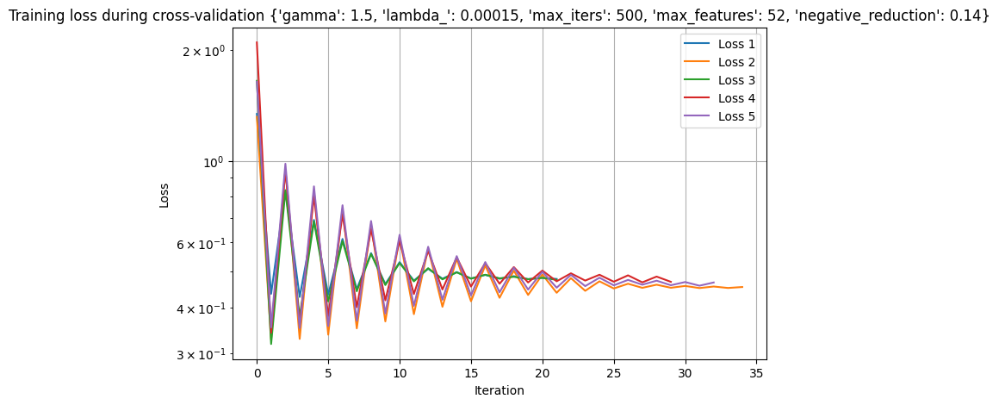

Tuning with args (35/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 54, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4590655344898744


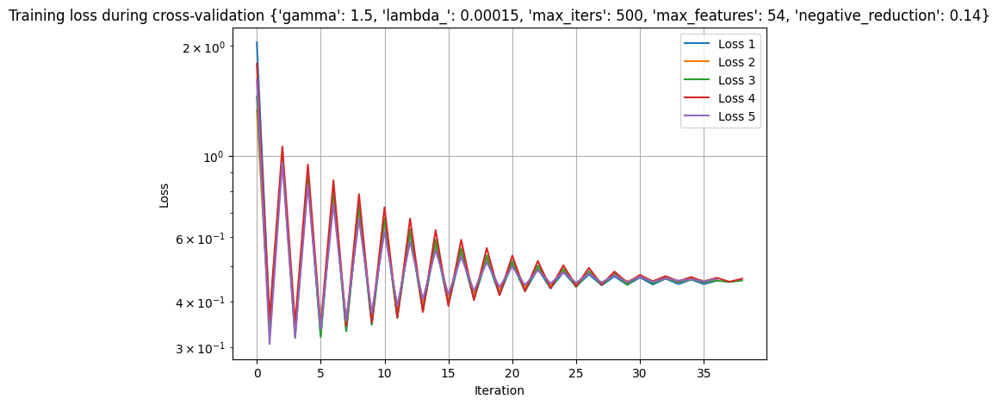

Tuning with args (36/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 56, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4646854849166348


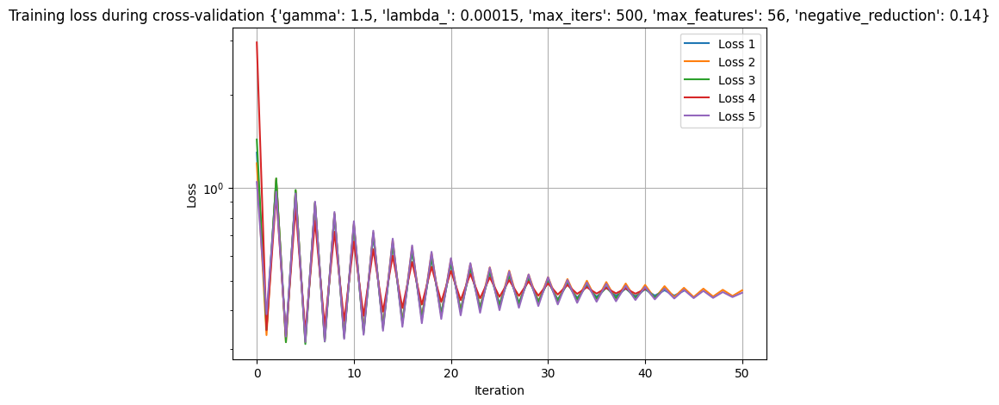

Tuning with args (37/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 58, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.43842258613178836


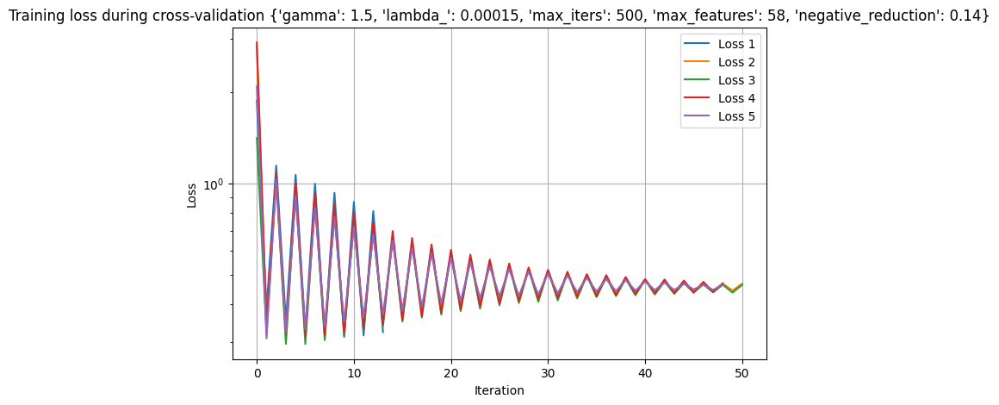

Tuning with args (38/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 60, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4329826369963688


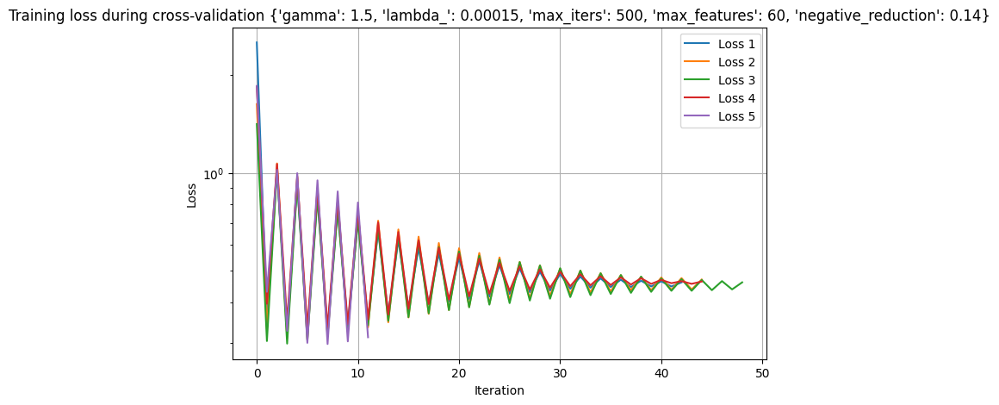

Tuning with args (39/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 62, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.43756295687073266


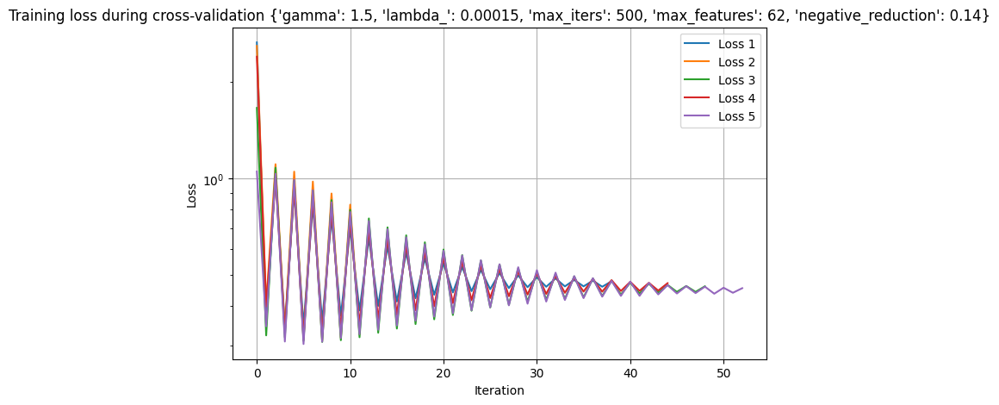

Tuning with args (40/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 53, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.44655099110560725


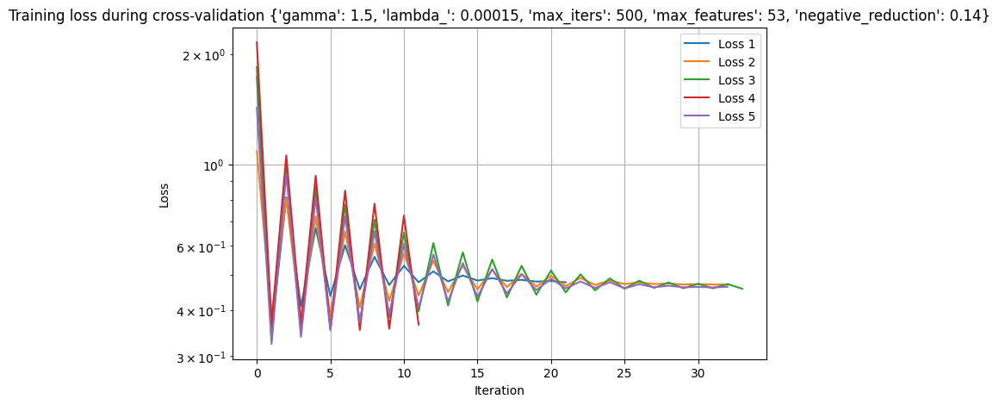

Tuning with args (41/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 55, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4622308565281969


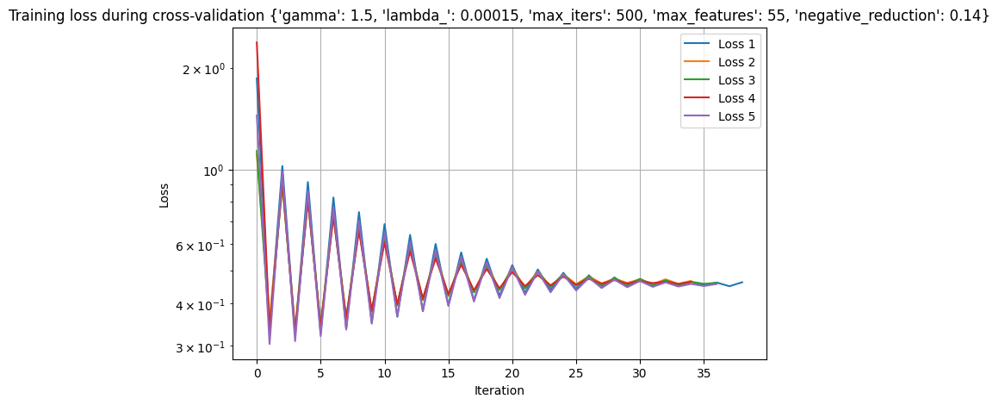

Tuning with args (42/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 57, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4119178792659387


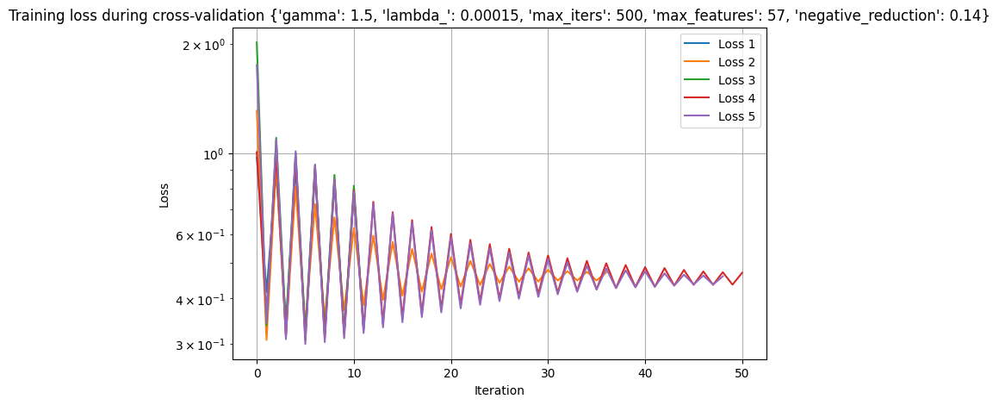

Tuning with args (43/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 59, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4664296386094945


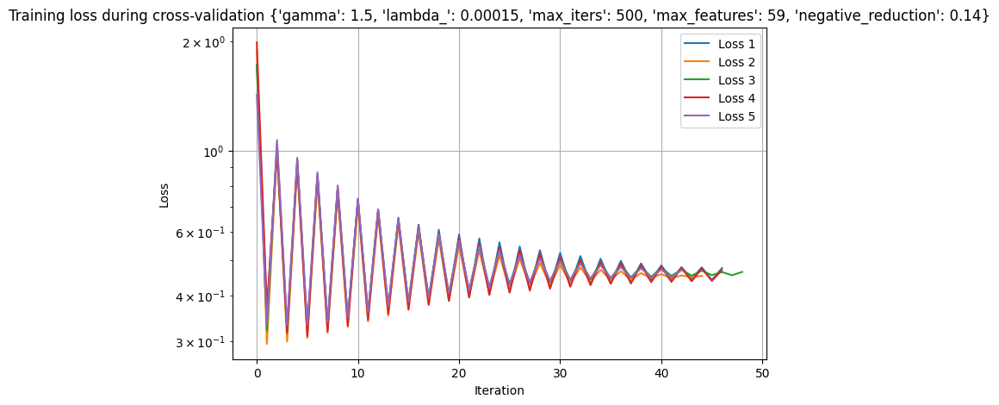

Tuning with args (44/44): {'gamma': 1.5, 'lambda_': 0.00015, 'max_iters': 500, 'max_features': 61, 'negative_reduction': 0.14}
Average validation cross-validation loss: 0.4373743540663038


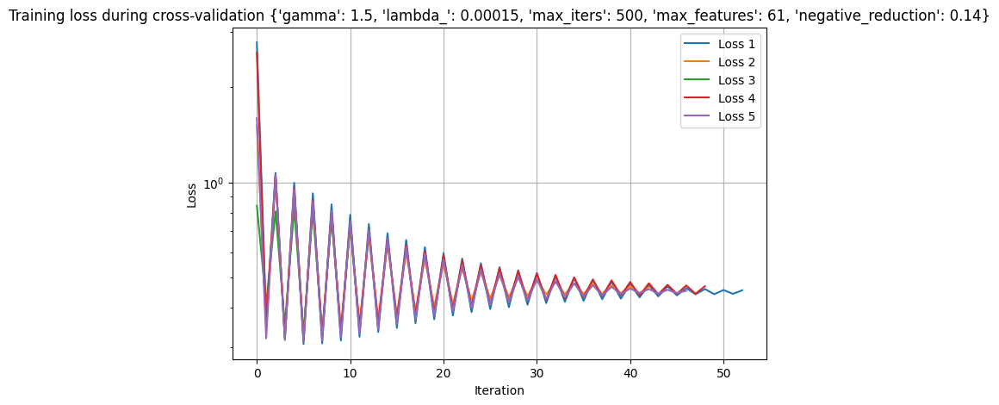

In [69]:
from scripts.model_utils import tune
from scripts.models import RegularizedLogisticRegression
args_logreg_balanced_5 = [
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 57,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 59,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.2,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 61,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 57,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 59,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.3,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 61,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 57,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 59,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.4,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 61,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 52,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 54,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 56,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 58,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 60,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 62,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 53,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 55,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 57,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 59,
        "negative_reduction": 0.14,
    },
    {
        "gamma": 1.5,
        "lambda_": 1.5e-4,
        "max_iters": 500,
        "max_features": 61,
        "negative_reduction": 0.14,
    },
]
validation_logreg_balanced_5, training_logreg_balanced_5 = tune(
    x_train_norm, y_train, k=5, model=RegularizedLogisticRegression, args=args_logreg_balanced_5
)

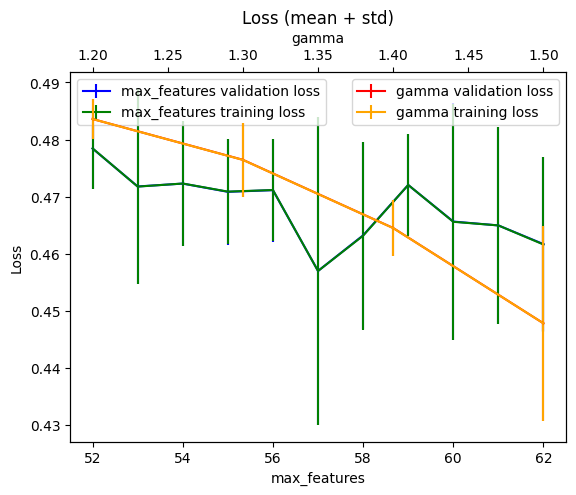


Averaged results:
max_features=52 | val=0.4784±0.0071 | train=0.4784±0.0071
max_features=53 | val=0.4718±0.0171 | train=0.4717±0.0171
max_features=54 | val=0.4723±0.0109 | train=0.4723±0.0110
max_features=55 | val=0.4708±0.0093 | train=0.4709±0.0092
max_features=56 | val=0.4711±0.0090 | train=0.4712±0.0090
max_features=57 | val=0.4570±0.0269 | train=0.4570±0.0269
max_features=58 | val=0.4632±0.0164 | train=0.4632±0.0164
max_features=59 | val=0.4720±0.0088 | train=0.4720±0.0089
max_features=60 | val=0.4656±0.0207 | train=0.4656±0.0207
max_features=61 | val=0.4649±0.0173 | train=0.4649±0.0172
max_features=62 | val=0.4617±0.0152 | train=0.4616±0.0153

Averaged results:
gamma=1.2 | val=0.4836±0.0035 | train=0.4836±0.0035
gamma=1.3 | val=0.4764±0.0064 | train=0.4764±0.0064
gamma=1.4 | val=0.4645±0.0048 | train=0.4645±0.0048
gamma=1.5 | val=0.4478±0.0171 | train=0.4478±0.0171


In [70]:
from scripts.model_utils import show_printing_result_loss, show_printing_result_two_losses

show_printing_result_two_losses(
    args_logreg_balanced_5,
    validation_logreg_balanced_5,
    training_logreg_balanced_5,
    "max_features",
    "gamma",
    x_log=False,
    y_log=False,
)

## Single model training

Gradient Descent(1/100): loss=208.18580717707655
Gradient Descent(2/100): loss=132.1449222739708
Gradient Descent(3/100): loss=84.0528040519343
Gradient Descent(4/100): loss=53.631098859411665
Gradient Descent(5/100): loss=34.38194457245858
Gradient Descent(6/100): loss=22.197344996125363
Gradient Descent(7/100): loss=14.480109250030855
Gradient Descent(8/100): loss=9.588158307704502
Gradient Descent(9/100): loss=6.4832393189385
Gradient Descent(10/100): loss=4.508852886675078
Gradient Descent(11/100): loss=3.249861624586657
Gradient Descent(12/100): loss=2.443734132929819
Gradient Descent(13/100): loss=1.924431402422526
Gradient Descent(14/100): loss=1.5869293274313745
Gradient Descent(15/100): loss=1.3647874457133902
Gradient Descent(16/100): loss=1.2159657985100731
Gradient Descent(17/100): loss=1.113856611825719
Gradient Descent(18/100): loss=1.0416131356062304
Gradient Descent(19/100): loss=0.9885632506266232
Gradient Descent(20/100): loss=0.9479413172497403
Gradient Descent(21/10

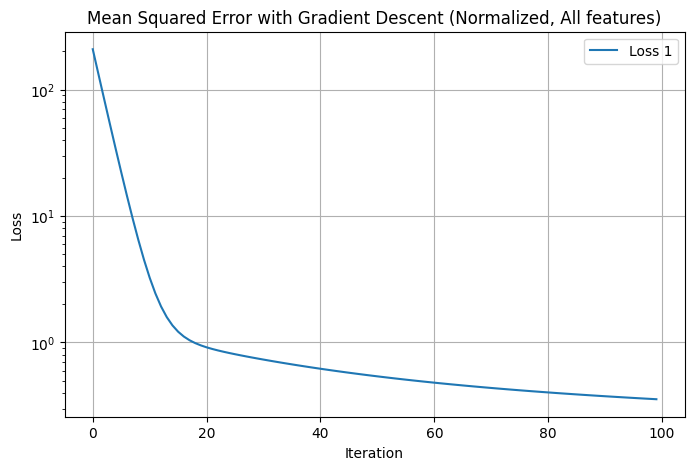

In [49]:
from scripts.model_utils import plot_losses
from scripts.models import MSEGradientDescent

# Model:
#   Mean Squared Error with Gradient Descent
#   Normalized features
#   All features
model_msewgd_norm_all = MSEGradientDescent(gamma=0.1, max_iters=100)
losses_mean_squared_error_gd = model_msewgd_norm_all.fit(
    y_train, x_train_norm, display=True
)
plot_losses(
    [losses_mean_squared_error_gd],
    "Mean Squared Error with Gradient Descent (Normalized, All features)",
)

Gradient Descent(1/300): loss=232.92354208816542
Gradient Descent(2/300): loss=220.630996035137
Gradient Descent(3/300): loss=209.16249620564616
Gradient Descent(4/300): loss=198.40533891449815
Gradient Descent(5/300): loss=188.27738484326534
Gradient Descent(6/300): loss=178.71675491396653
Gradient Descent(7/300): loss=169.67515528949107
Gradient Descent(8/300): loss=161.11353661711027
Gradient Descent(9/300): loss=152.99925854594244
Gradient Descent(10/300): loss=145.30422753779303
Gradient Descent(11/300): loss=138.00366575081978
Gradient Descent(12/300): loss=131.0752903124067
Gradient Descent(13/300): loss=124.49876032570549
Gradient Descent(14/300): loss=118.25529916886961
Gradient Descent(15/300): loss=112.32743203809522
Gradient Descent(16/300): loss=106.6987996299708
Gradient Descent(17/300): loss=101.35402243240611
Gradient Descent(18/300): loss=96.27859891064588
Gradient Descent(19/300): loss=91.45882661531358
Gradient Descent(20/300): loss=86.88173898489198
Gradient Descent

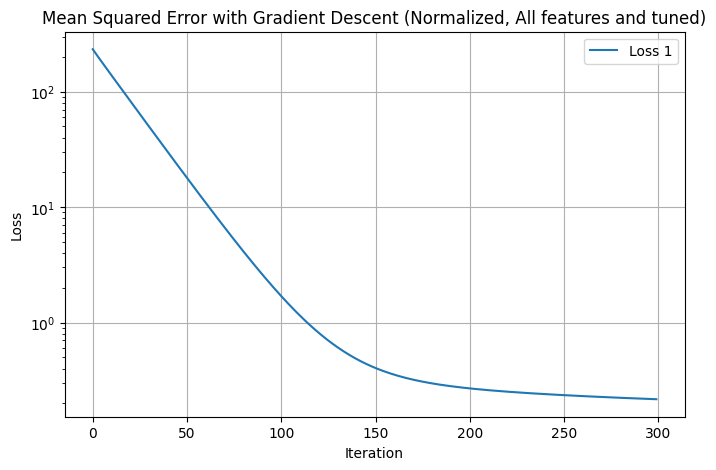

In [50]:
# Model:
#   Mean Squared Error with Gradient Descent
#   Normalized features
#   All features
#   Tuned hyperparameters (from cross-validation)
model_msewgd_norm_all_tuned = MSEGradientDescent(gamma=0.11, max_iters=300)
losses_mean_squared_error_gd_tuned = model_msewgd_norm_all_tuned.fit(
    y_train, x_train_norm, display=True
)
plot_losses(
    [losses_mean_squared_error_gd_tuned],
    "Mean Squared Error with Gradient Descent (Normalized, All features and tuned)",
)

(262508, 16)
Gradient Descent(1/100): loss=2.9651314312857417
Gradient Descent(2/100): loss=1.7711397731347966
Gradient Descent(3/100): loss=1.108474311658745
Gradient Descent(4/100): loss=0.7395346781247337
Gradient Descent(5/100): loss=0.5330724985140621
Gradient Descent(6/100): loss=0.41657745223556675
Gradient Descent(7/100): loss=0.349981157106111
Gradient Descent(8/100): loss=0.31113431143573983
Gradient Descent(9/100): loss=0.2877858970081979
Gradient Descent(10/100): loss=0.27315330897370227
Gradient Descent(11/100): loss=0.26347567396046245
Gradient Descent(12/100): loss=0.25666244598258786
Gradient Descent(13/100): loss=0.2515469105591381
Gradient Descent(14/100): loss=0.2474737781217708
Gradient Descent(15/100): loss=0.2440712995370622
Gradient Descent(16/100): loss=0.24112530061474324
Gradient Descent(17/100): loss=0.23850951495223777
Gradient Descent(18/100): loss=0.23614701896664678
Gradient Descent(19/100): loss=0.23398885295359598
Gradient Descent(20/100): loss=0.232002

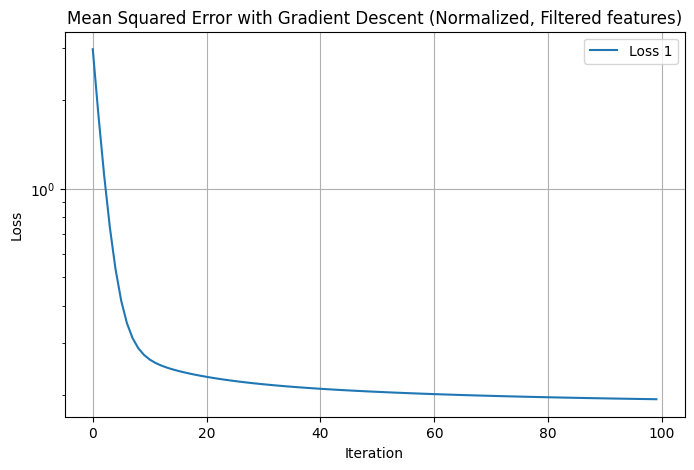

In [51]:
# Model:
#   Mean Squared Error with Gradient Descent
#   Normalized features
#   Filtered features
x_train_norm_filtered = x_train_norm[:, sorted_indices[:top]]
print(x_train_norm_filtered.shape)
model_msewgd_norm_filtered = MSEGradientDescent(gamma=0.1, max_iters=100)
losses_mean_squared_error_gd = model_msewgd_norm_filtered.fit(
    y_train, x_train_norm_filtered, display=True
)
plot_losses(
    [losses_mean_squared_error_gd],
    "Mean Squared Error with Gradient Descent (Normalized, Filtered features)",
)

(262508, 16)
Gradient Descent(1/300): loss=2.5750633444299003
Gradient Descent(2/300): loss=1.4693033221364709
Gradient Descent(3/300): loss=0.8964259510081249
Gradient Descent(4/300): loss=0.5982243518953748
Gradient Descent(5/300): loss=0.4417443431546036
Gradient Descent(6/300): loss=0.35851081609177304
Gradient Descent(7/300): loss=0.31324366446585383
Gradient Descent(8/300): loss=0.28775368251093786
Gradient Descent(9/300): loss=0.2726524866979589
Gradient Descent(10/300): loss=0.2630847946809562
Gradient Descent(11/300): loss=0.25653127500745854
Gradient Descent(12/300): loss=0.25167727022258785
Gradient Descent(13/300): loss=0.2478302158319903
Gradient Descent(14/300): loss=0.24461953157141986
Gradient Descent(15/300): loss=0.24184194178136448
Gradient Descent(16/300): loss=0.23938167833989005
Gradient Descent(17/300): loss=0.23716924944259002
Gradient Descent(18/300): loss=0.23516007779522938
Gradient Descent(19/300): loss=0.23332338216757265
Gradient Descent(20/300): loss=0.23

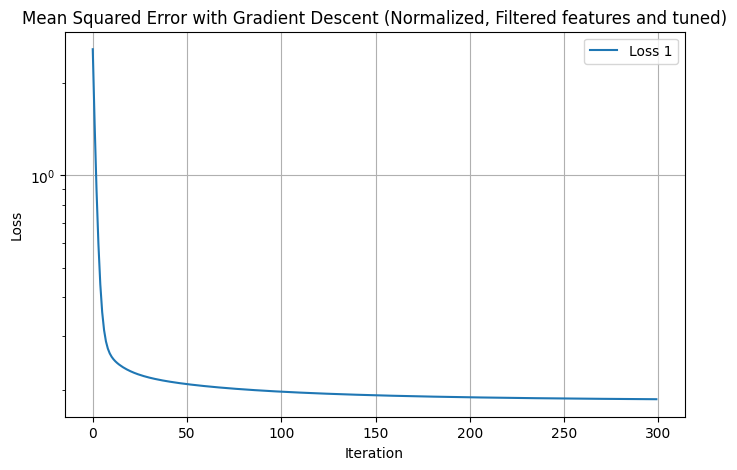

In [52]:
# Model:
#   Mean Squared Error with Gradient Descent
#   Normalized features
#   Filtered features
#   Tuned hyperparameters (from cross-validation)
x_train_norm_filtered = x_train_norm[:, sorted_indices[:top]]
print(x_train_norm_filtered.shape)
model_msewgd_norm_filtered_tuned = MSEGradientDescent(gamma=0.11, max_iters=300)
losses_mean_squared_error_gd_tuned = model_msewgd_norm_filtered_tuned.fit(
    y_train, x_train_norm_filtered, display=True
)
plot_losses(
    [losses_mean_squared_error_gd_tuned],
    "Mean Squared Error with Gradient Descent (Normalized, Filtered features and tuned)",
)

/Users/simbarras/Dev/EPFL/Master/Fall-1/MachineLearning-CS433/project-1-synapse/scripts/implementations.py:131: RuntimeWarning: divide by zero encountered in log
  loss = -np.mean(y * np.log(sigmoid(pred)) + (1 - y) * np.log(1 - sigmoid(pred)))
/Users/simbarras/Dev/EPFL/Master/Fall-1/MachineLearning-CS433/project-1-synapse/scripts/implementations.py:131: RuntimeWarning: invalid value encountered in multiply
  loss = -np.mean(y * np.log(sigmoid(pred)) + (1 - y) * np.log(1 - sigmoid(pred)))


Logistic regression (1/200): loss=nan
Logistic regression (2/200): loss=nan
Logistic regression (3/200): loss=nan
Logistic regression (4/200): loss=nan
Logistic regression (5/200): loss=nan
Logistic regression (6/200): loss=nan
Logistic regression (7/200): loss=nan
Logistic regression (8/200): loss=nan
Logistic regression (9/200): loss=nan
Logistic regression (10/200): loss=nan
Logistic regression (11/200): loss=nan
Logistic regression (12/200): loss=nan
Logistic regression (13/200): loss=nan
Logistic regression (14/200): loss=nan
Logistic regression (15/200): loss=nan
Logistic regression (16/200): loss=nan
Logistic regression (17/200): loss=nan
Logistic regression (18/200): loss=nan
Logistic regression (19/200): loss=nan
Logistic regression (20/200): loss=nan
Logistic regression (21/200): loss=nan
Logistic regression (22/200): loss=nan
Logistic regression (23/200): loss=nan
Logistic regression (24/200): loss=nan
Logistic regression (25/200): loss=nan
Logistic regression (26/200): loss

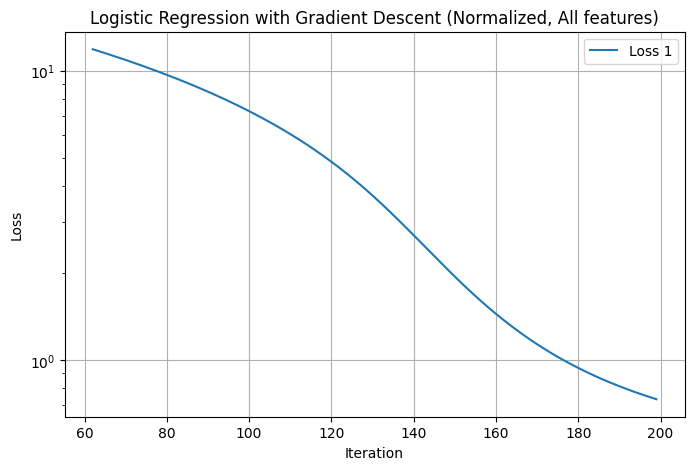

In [53]:
# Model
#   Logistic Regression with Gradient Descent
#   Normalized features
#   All features
from scripts.models import RegularizedLogisticRegression

model_logreg_norm_all = RegularizedLogisticRegression(
    max_iters=200, lambda_=1e-4, gamma=0.01, max_features=300
)
losses_logistic_regression = model_logreg_norm_all.fit(
    y_train, x_train_norm, display=True
)
plot_losses(
    [losses_logistic_regression],
    "Logistic Regression with Gradient Descent (Normalized, All features)",
)

Logistic regression (1/500): loss=2.257737270335246
Logistic regression (2/500): loss=0.4620028777928677
Logistic regression (3/500): loss=0.9165407842815341
Logistic regression (4/500): loss=0.4162457600634333
Logistic regression (5/500): loss=0.7725872327554304
Logistic regression (6/500): loss=0.4014908266574943
Logistic regression (7/500): loss=0.6876862015104613
Logistic regression (8/500): loss=0.4072875353305029
Logistic regression (9/500): loss=0.6204273730022511
Logistic regression (10/500): loss=0.4170792569933227
Logistic regression (11/500): loss=0.57797239220165
Logistic regression (12/500): loss=0.43010617775375476
Logistic regression (13/500): loss=0.5409109123186842
Logistic regression (14/500): loss=0.441832737929077
Logistic regression (15/500): loss=0.5142720821722662
Logistic regression (16/500): loss=0.4513219406342711
Logistic regression (17/500): loss=0.4924548155229738
Logistic regression (18/500): loss=0.45781704150662217
Logistic regression (19/500): loss=0.48

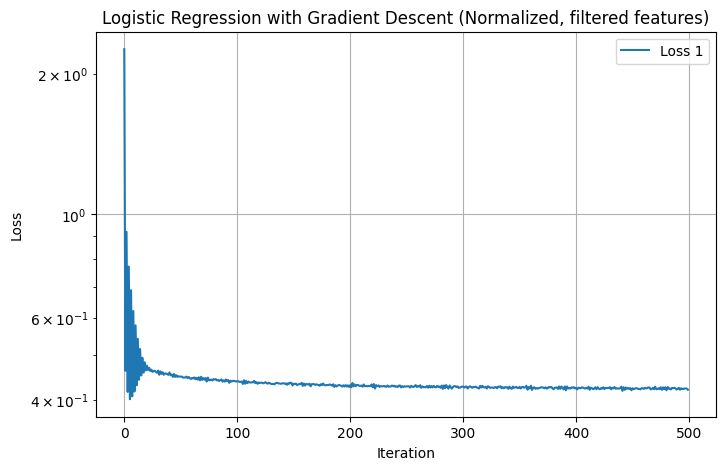

In [54]:
# Model
#   Logistic Regression with Gradient Descent
#   Normalized features
#   Top 56 correlated features
#   gamma 1.3
#   lambda_ 1.5e-4
#   negative reduction: 0.14
from scripts.models import RegularizedLogisticRegression

model_logreg_norm_filtered = RegularizedLogisticRegression(
    max_iters=500, lambda_=1.5e-4, gamma=1.3, max_features=56, negative_reduction=0.14
)
model_logreg_norm_filtered_losses = model_logreg_norm_filtered.fit(
    y_train, x_train_norm, display=True, stop_loss=0
)
plot_losses(
    [model_logreg_norm_filtered_losses],
    "Logistic Regression with Gradient Descent (Normalized, filtered features)",
)

## Tests

Accuracy:  0.9100979779663858
Precision:  0
Recall:  0.0
F1 Score:  0.0


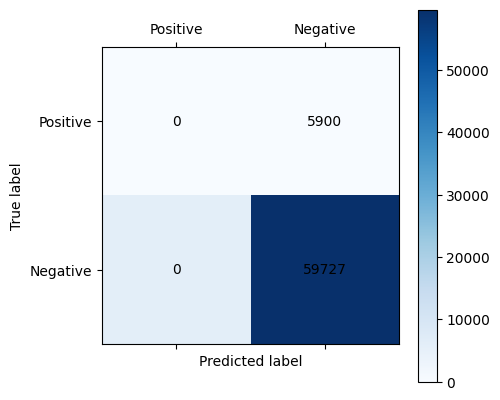

In [55]:
from scripts.evaluate_utils import evaluate_model
# Model that predict always NEGATIVE to have a baseline
from scripts.models import AlwaysNegative

allways_negative_model = AlwaysNegative()
evaluate_model(allways_negative_model, x_test_nom, y_test)

Accuracy:  0.8351593094305697
Precision:  0.088107202680067
Recall:  0.08915254237288135
F1 Score:  0.0886267902274642


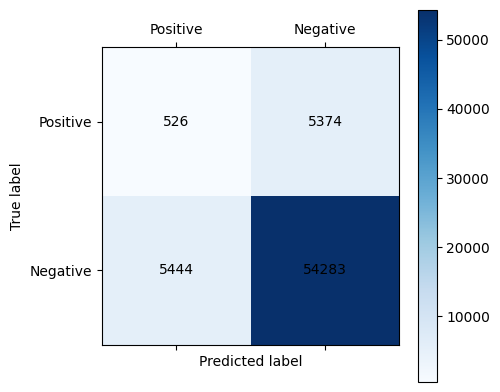

In [56]:
# Random Bernoulli model
from scripts.models import BernoulliNaiveBayes

bernoulli_model = BernoulliNaiveBayes(0.09)
evaluate_model(bernoulli_model, x_test_nom, y_test)

Accuracy:  0.8360278543891996
Precision:  0.16554286500619236
Recall:  0.20389830508474577
F1 Score:  0.18272955115060377


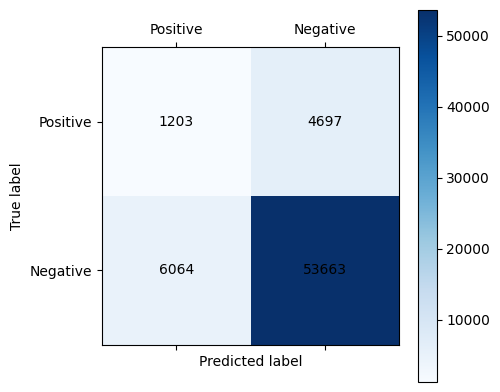

In [57]:
evaluate_model(model_msewgd_norm_all, x_test_nom, y_test)

Accuracy:  0.8821064500891401
Precision:  0.1866257250085295
Recall:  0.09271186440677966
F1 Score:  0.12388178009285472


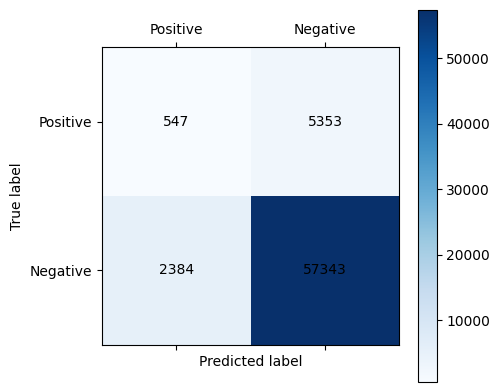

In [58]:
evaluate_model(model_msewgd_norm_all_tuned, x_test_nom, y_test)

Accuracy:  0.9120483947155896
Precision:  0.19047619047619047
Recall:  0.0001733477789815818
F1 Score:  0.00034638032559750607


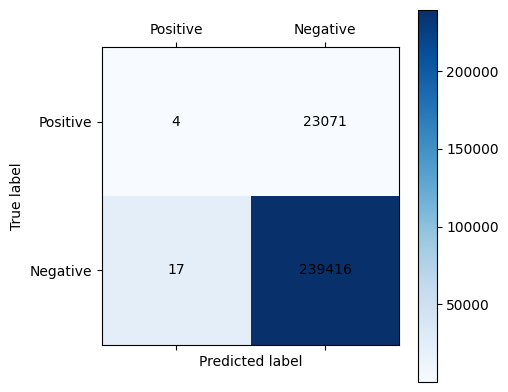

In [59]:
evaluate_model(model_msewgd_norm_filtered, x_train_norm_filtered, y_train)

Accuracy:  0.912105535831289
Precision:  1.0
Recall:  8.66738894907909e-05
F1 Score:  0.00017333275555748146


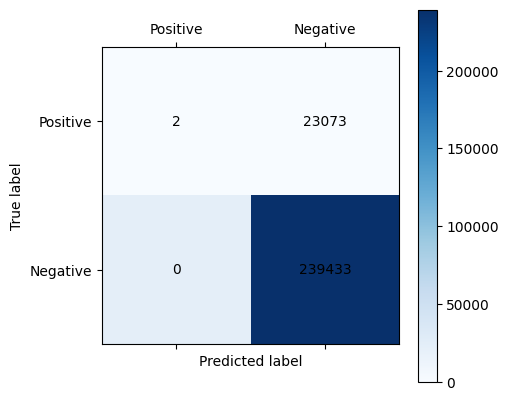

In [60]:
evaluate_model(model_msewgd_norm_filtered_tuned, x_train_norm_filtered, y_train)

Accuracy:  0.7251131394090847
Precision:  0.10747542679772375
Recall:  0.2816949152542373
F1 Score:  0.15558884104100357


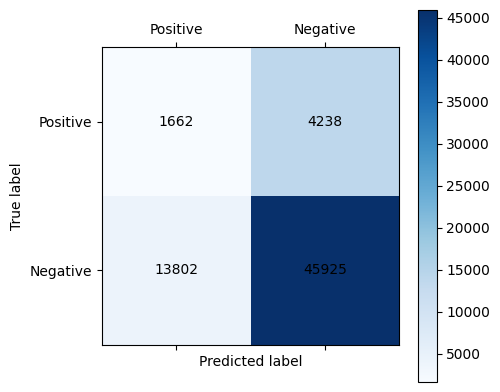

In [61]:
evaluate_model(model_logreg_norm_all, x_test_nom, y_test)

Accuracy:  0.788471208496503
Precision:  0.25235790518739143
Recall:  0.689322033898305
F1 Score:  0.36945857558139533


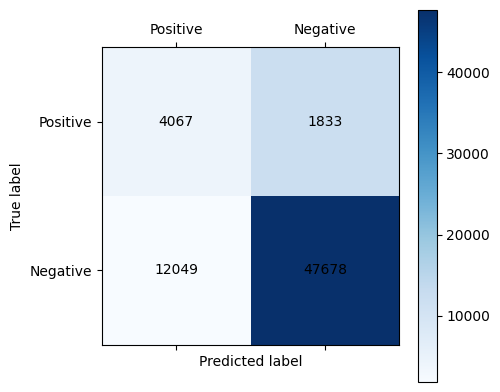

In [62]:
evaluate_model(model_logreg_norm_filtered, x_test_nom, y_test)

## Submitting result

In [63]:
from scripts.helper import create_csv_submission

online_test_preds = model_logreg_norm_filtered.predict(x_online_test_norm)
create_csv_submission(
    online_test_ids, online_test_preds, "synapse-logreg-filtered-balanced.csv"
)